## Curvature-Aware Latent Drifting for Physics-Informed Multimodal Brain MRI Synthesis

In [1]:
# Cell 1 — Reproducible project setup and runtime manifest

from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import PackageNotFoundError, version as package_version
import sys
import json
import time
import inspect
import platform
import subprocess
import warnings

warnings.filterwarnings(
    "ignore",
    message="IProgress not found.*",
    category=Warning,
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

ROOT = Path.cwd().resolve()

required_files = [
    "generate.py",
    "models.py",
    "utils.py",
    "train_vae.py",
    "train_ldm.py",
    "geometry.py",
    "requirements.txt",
    "checkpoints/phy_vae.pt",
    "checkpoints/phy_ldm.pt",
]

missing = [
    name
    for name in required_files
    if not (ROOT / name).exists()
]

if missing:
    raise FileNotFoundError(
        "This notebook must be run from the phy-ldm-mri repository root.\n"
        f"Missing files: {missing}\n"
        f"Current directory: {ROOT}"
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RESULTS = ROOT / "results" / "euclidean_audit"
RESULTS.mkdir(parents=True, exist_ok=True)

MANUSCRIPT_RESULTS = RESULTS / "manuscript"
MANUSCRIPT_RESULTS.mkdir(parents=True, exist_ok=True)


def get_package_version(package_name):
    try:
        return package_version(package_name)
    except PackageNotFoundError:
        return "not installed"


def get_git_output(*arguments):
    try:
        completed = subprocess.run(
            ["git", *arguments],
            cwd=ROOT,
            capture_output=True,
            text=True,
            check=False,
        )
    except OSError:
        return "not available"

    output = completed.stdout.strip()

    if completed.returncode != 0 or not output:
        return "not available"

    return output


git_commit = get_git_output("rev-parse", "HEAD")
git_status = get_git_output("status", "--porcelain")

checkpoint_manifest = {}

for relative_path in [
    "checkpoints/phy_vae.pt",
    "checkpoints/phy_ldm.pt",
]:
    checkpoint_path = ROOT / relative_path

    checkpoint_manifest[relative_path] = {
        "bytes": checkpoint_path.stat().st_size,
        "modified_utc": datetime.fromtimestamp(
            checkpoint_path.stat().st_mtime,
            tz=timezone.utc,
        ).isoformat(),
    }

runtime_metadata = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "repository_root": str(ROOT),
    "python_executable": sys.executable,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "git_commit": git_commit,
    "git_worktree_state": (
        "modified"
        if git_status != "not available" and git_status != ""
        else "clean_or_unavailable"
    ),
    "package_versions": {
        "numpy": get_package_version("numpy"),
        "pandas": get_package_version("pandas"),
        "matplotlib": get_package_version("matplotlib"),
        "torch": torch.__version__,
        "monai": get_package_version("monai"),
        "generative": get_package_version("generative"),
    },
    "cuda_available": bool(torch.cuda.is_available()),
    "torch_cuda_version": torch.version.cuda,
    "checkpoints": checkpoint_manifest,
}

if torch.cuda.is_available():
    gpu_properties = torch.cuda.get_device_properties(0)

    runtime_metadata["gpu"] = {
        "name": torch.cuda.get_device_name(0),
        "total_memory_gib": round(
            gpu_properties.total_memory / (1024 ** 3),
            2,
        ),
        "compute_capability": (
            f"{gpu_properties.major}.{gpu_properties.minor}"
        ),
    }

runtime_metadata_path = MANUSCRIPT_RESULTS / "runtime_manifest.json"

with open(runtime_metadata_path, "w", encoding="utf-8") as file:
    json.dump(runtime_metadata, file, indent=2)

print("Repository root:", ROOT)
print("Exploratory results directory:", RESULTS)
print("Manuscript results directory:", MANUSCRIPT_RESULTS)
print("Runtime manifest:", runtime_metadata_path)
print("Python version:", runtime_metadata["python_version"])
print("PyTorch version:", runtime_metadata["package_versions"]["torch"])
print("CUDA available:", runtime_metadata["cuda_available"])
print("Git commit:", runtime_metadata["git_commit"])

if torch.cuda.is_available():
    print("GPU:", runtime_metadata["gpu"]["name"])
    print("PyTorch CUDA version:", runtime_metadata["torch_cuda_version"])

Repository root: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri
Exploratory results directory: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit
Manuscript results directory: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript
Runtime manifest: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/runtime_manifest.json
Python version: 3.10.21
PyTorch version: 2.1.2+cu121
CUDA available: True
Git commit: 8c6c04b76dcef57d38bc680909eed6ce232bc6de
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
PyTorch CUDA version: 12.1


In [2]:
# Cell 2 — Fixed experimental protocol and reproducibility configuration

import random

CFG = {
    "experiment_name": (
        "curvature_aware_latent_drifting_phy_ldm"
    ),
    "experiment_version": "scheme_a_frozen_model",

    "reference_seed": 7,
    "n_audit_seeds": 16,

    "num_inference_steps": 50,
    "latent_shape": (6, 20, 28),

    "foreground_pd_quantile": 0.20,
    "display_percentiles": (1.0, 99.0),

    "vae_checkpoint": "checkpoints/phy_vae.pt",
    "ldm_checkpoint": "checkpoints/phy_ldm.pt",

    "euclidean_reference_delta": 0.00050,
    "hyperbolic_coordinate_scale": 0.20,
    "hyperbolic_curvatures": [0.00, 0.25, 1.00, 2.00],

    "local_geometry": "product_of_local_6d_poincare_balls",
    "curvature_convention": (
        "The sectional curvature is -c for c > 0; "
        "c = 0 is the exact Euclidean limit."
    ),

    "seed_interpretation": (
        "Independent Gaussian initial-noise seeds, "
        "not independent biological subjects."
    ),
}

CFG["audit_seeds"] = list(range(CFG["n_audit_seeds"]))

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


def seed_everything(seed: int) -> None:
    """Set all stochastic sources used by this inference notebook."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


seed_everything(CFG["reference_seed"])

experiment_config_path = (
    MANUSCRIPT_RESULTS / "experiment_configuration.json"
)

with open(experiment_config_path, "w", encoding="utf-8") as file:
    json.dump(CFG, file, indent=2)

print("Experiment:", CFG["experiment_name"])
print("Experiment version:", CFG["experiment_version"])
print("Device:", DEVICE)
print("Reference seed:", CFG["reference_seed"])
print("Audit seeds:", CFG["audit_seeds"])
print("DDIM inference steps:", CFG["num_inference_steps"])
print("Latent tensor shape [C, H, W]:", CFG["latent_shape"])
print("Euclidean reference delta:", CFG["euclidean_reference_delta"])
print(
    "Hyperbolic coordinate scale:",
    CFG["hyperbolic_coordinate_scale"],
)
print(
    "Hyperbolic curvatures:",
    CFG["hyperbolic_curvatures"],
)
print("Local geometry:", CFG["local_geometry"])
print("Configuration saved to:", experiment_config_path)

Experiment: curvature_aware_latent_drifting_phy_ldm
Experiment version: scheme_a_frozen_model
Device: cuda
Reference seed: 7
Audit seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
DDIM inference steps: 50
Latent tensor shape [C, H, W]: (6, 20, 28)
Euclidean reference delta: 0.0005
Hyperbolic coordinate scale: 0.2
Hyperbolic curvatures: [0.0, 0.25, 1.0, 2.0]
Local geometry: product_of_local_6d_poincare_balls
Configuration saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/experiment_configuration.json


In [3]:
# Cell 3 — Project imports, implementation lock, and API compatibility checks

import hashlib
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"pkg_resources is deprecated as an API.*",
    category=UserWarning,
)

from generative.inferers import (
    DiffusionInferer,
    LatentDiffusionInferer,
)
from generative.networks.nets import (
    AutoencoderKL,
    DiffusionModelUNet,
)
from generative.networks.schedulers import DDIMScheduler

from models import (
    denormalize_log_q_map,
    replace_groupnorm_with_adaptive_groupnorm,
)

base_inferer_class = DiffusionInferer


def file_sha256(file_path):
    digest = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def require_parameters(callable_object, expected_parameters, object_name):
    actual_parameters = set(
        inspect.signature(callable_object).parameters
    )

    missing_parameters = (
        set(expected_parameters) - actual_parameters
    )

    if missing_parameters:
        raise RuntimeError(
            f"Unexpected API for {object_name}.\n"
            f"Observed signature: {inspect.signature(callable_object)}\n"
            f"Missing parameters: {sorted(missing_parameters)}"
        )


require_parameters(
    LatentDiffusionInferer.sample,
    {
        "input_noise",
        "autoencoder_model",
        "diffusion_model",
        "scheduler",
        "save_intermediates",
        "intermediate_steps",
        "conditioning",
        "mode",
        "verbose",
    },
    "LatentDiffusionInferer.sample",
)

require_parameters(
    DiffusionInferer.sample,
    {
        "input_noise",
        "diffusion_model",
        "scheduler",
        "save_intermediates",
        "intermediate_steps",
        "conditioning",
        "mode",
        "verbose",
    },
    "DiffusionInferer.sample",
)

require_parameters(
    DDIMScheduler.step,
    {
        "model_output",
        "timestep",
        "sample",
        "eta",
        "generator",
    },
    "DDIMScheduler.step",
)

require_parameters(
    denormalize_log_q_map,
    {
        "norm_log_q_map",
        "log_pd_mean",
        "log_t1_mean",
        "log_t2_mean",
    },
    "denormalize_log_q_map",
)

project_source_files = {
    "generate.py": ROOT / "generate.py",
    "models.py": ROOT / "models.py",
    "utils.py": ROOT / "utils.py",
    "geometry.py": ROOT / "geometry.py",
}

source_manifest = {
    name: {
        "path": str(path.resolve()),
        "sha256": file_sha256(path),
    }
    for name, path in project_source_files.items()
}

import_manifest = {
    "latent_diffusion_inferer_source": str(
        Path(inspect.getfile(LatentDiffusionInferer)).resolve()
    ),
    "diffusion_inferer_source": str(
        Path(inspect.getfile(DiffusionInferer)).resolve()
    ),
    "ddim_scheduler_source": str(
        Path(inspect.getfile(DDIMScheduler)).resolve()
    ),
    "latent_diffusion_sample_signature": str(
        inspect.signature(LatentDiffusionInferer.sample)
    ),
    "diffusion_sample_signature": str(
        inspect.signature(DiffusionInferer.sample)
    ),
    "ddim_step_signature": str(
        inspect.signature(DDIMScheduler.step)
    ),
    "denormalize_log_q_map_signature": str(
        inspect.signature(denormalize_log_q_map)
    ),
    "project_source_files": source_manifest,
}

import_manifest_path = (
    MANUSCRIPT_RESULTS / "implementation_manifest.json"
)

with open(import_manifest_path, "w", encoding="utf-8") as file:
    json.dump(import_manifest, file, indent=2)

print("Project imports and API compatibility checks passed.")
print(
    "LatentDiffusionInferer source:",
    import_manifest["latent_diffusion_inferer_source"],
)
print(
    "DiffusionInferer source:",
    import_manifest["diffusion_inferer_source"],
)
print(
    "DDIMScheduler source:",
    import_manifest["ddim_scheduler_source"],
)
print(
    "Implementation manifest saved to:",
    import_manifest_path,
)
print(
    "LatentDiffusionInferer.sample:",
    import_manifest["latent_diffusion_sample_signature"],
)
print(
    "DDIMScheduler.step:",
    import_manifest["ddim_step_signature"],
)

Project imports and API compatibility checks passed.
LatentDiffusionInferer source: /home/dingzhou98/anaconda3/envs/multimodal_env/lib/python3.10/site-packages/generative/inferers/inferer.py
DiffusionInferer source: /home/dingzhou98/anaconda3/envs/multimodal_env/lib/python3.10/site-packages/generative/inferers/inferer.py
DDIMScheduler source: /home/dingzhou98/anaconda3/envs/multimodal_env/lib/python3.10/site-packages/generative/networks/schedulers/ddim.py
Implementation manifest saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/implementation_manifest.json
LatentDiffusionInferer.sample: (self, input_noise: 'torch.Tensor', autoencoder_model: 'Callable[..., torch.Tensor]', diffusion_model: 'Callable[..., torch.Tensor]', scheduler: 'Callable[..., torch.Tensor] | None' = None, save_intermediates: 'bool | None' = False, intermediate_steps: 'int | None' = 100, conditioning: 'torch.Tensor | None' = None, mode: 'str' = 'crossattn', verbose: 'bool' = True, 

In [4]:
# Cell 4 — Reconstruct and freeze the pretrained phy-LDM generation pipeline

vae_checkpoint_path = ROOT / CFG["vae_checkpoint"]
ldm_checkpoint_path = ROOT / CFG["ldm_checkpoint"]

if not vae_checkpoint_path.is_file():
    raise FileNotFoundError(
        f"VAE checkpoint not found: {vae_checkpoint_path}"
    )

if not ldm_checkpoint_path.is_file():
    raise FileNotFoundError(
        f"LDM checkpoint not found: {ldm_checkpoint_path}"
    )

latent_channels = int(CFG["latent_shape"][0])


def parameter_count(module):
    return sum(
        parameter.numel()
        for parameter in module.parameters()
    )


def trainable_parameter_count(module):
    return sum(
        parameter.numel()
        for parameter in module.parameters()
        if parameter.requires_grad
    )


def scalar_value(value):
    if torch.is_tensor(value):
        return float(value.detach().cpu())

    return float(value)


def validate_load_status(load_status, module_name):
    missing_keys = list(load_status.missing_keys)
    unexpected_keys = list(load_status.unexpected_keys)

    if missing_keys or unexpected_keys:
        raise RuntimeError(
            f"Checkpoint mismatch for {module_name}.\n"
            f"Missing keys: {missing_keys}\n"
            f"Unexpected keys: {unexpected_keys}"
        )


def freeze_for_inference(module):
    module.eval()

    for parameter in module.parameters():
        parameter.requires_grad_(False)


# VAE architecture reproduced from generate.py
autoencoder = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=3,
    num_channels=(64, 128, 128, 128),
    latent_channels=latent_channels,
    num_res_blocks=3,
    attention_levels=(False, False, False, False),
).to(device=DEVICE)

replace_groupnorm_with_adaptive_groupnorm(
    autoencoder.encoder
)

vae_checkpoint = torch.load(
    vae_checkpoint_path,
    map_location="cpu",
)

if "autoencoder_model_state_dict" not in vae_checkpoint:
    raise KeyError(
        "The VAE checkpoint does not contain "
        "'autoencoder_model_state_dict'."
    )

vae_load_status = autoencoder.load_state_dict(
    vae_checkpoint["autoencoder_model_state_dict"],
    strict=True,
)

validate_load_status(
    vae_load_status,
    "AutoencoderKL",
)

freeze_for_inference(autoencoder)


# U-Net architecture reproduced from generate.py
unet = DiffusionModelUNet(
    spatial_dims=2,
    in_channels=latent_channels,
    out_channels=latent_channels,
    num_res_blocks=2,
    num_channels=(256, 512, 768),
    attention_levels=(False, True, True),
    resblock_updown=True,
    num_head_channels=(0, 512, 768),
).to(device=DEVICE)

ldm_checkpoint = torch.load(
    ldm_checkpoint_path,
    map_location="cpu",
)

if "unet_model_state_dict" not in ldm_checkpoint:
    raise KeyError(
        "The LDM checkpoint does not contain "
        "'unet_model_state_dict'."
    )

if "latent_scale_factor" not in ldm_checkpoint:
    raise KeyError(
        "The LDM checkpoint does not contain "
        "'latent_scale_factor'."
    )

unet_load_status = unet.load_state_dict(
    ldm_checkpoint["unet_model_state_dict"],
    strict=True,
)

validate_load_status(
    unet_load_status,
    "DiffusionModelUNet",
)

freeze_for_inference(unet)


# Latent scale factor estimated during LDM training
scale_factor = torch.as_tensor(
    ldm_checkpoint["latent_scale_factor"],
    device=DEVICE,
    dtype=torch.float32,
)

if not bool(torch.isfinite(scale_factor).all()):
    raise FloatingPointError(
        "The latent scale factor is not finite."
    )

if scalar_value(scale_factor) <= 0.0:
    raise ValueError(
        "The latent scale factor must be strictly positive."
    )


# Native DDIM scheduler reproduced from generate.py
ddim_scheduler = DDIMScheduler(
    num_train_timesteps=1000,
    schedule="scaled_linear_beta",
    beta_start=0.0015,
    beta_end=0.0205,
    clip_sample=False,
)

ddim_scheduler.set_timesteps(
    num_inference_steps=CFG["num_inference_steps"]
)

scheduler_timesteps = [
    int(timestep.detach().cpu())
    for timestep in ddim_scheduler.timesteps
]

if len(scheduler_timesteps) != CFG["num_inference_steps"]:
    raise RuntimeError(
        "Unexpected number of DDIM inference timesteps."
    )

if scheduler_timesteps != sorted(
    scheduler_timesteps,
    reverse=True,
):
    raise RuntimeError(
        "DDIM timesteps must be strictly descending."
    )

inferer = LatentDiffusionInferer(
    scheduler=ddim_scheduler,
    scale_factor=scale_factor,
)


# Log-space q-map priors reproduced from generate.py
log_pd_prior_mean = torch.log(
    torch.tensor(50.0, device=DEVICE, dtype=torch.float32)
)

log_t1_prior_mean = torch.log(
    torch.tensor(1.0, device=DEVICE, dtype=torch.float32)
)

log_t2_prior_mean = torch.log(
    torch.tensor(0.1, device=DEVICE, dtype=torch.float32)
)

model_manifest = {
    "vae_checkpoint_path": str(vae_checkpoint_path.resolve()),
    "ldm_checkpoint_path": str(ldm_checkpoint_path.resolve()),
    "vae_checkpoint_keys": sorted(vae_checkpoint.keys()),
    "ldm_checkpoint_keys": sorted(ldm_checkpoint.keys()),
    "latent_scale_factor": scalar_value(scale_factor),
    "latent_channels": latent_channels,
    "vae_parameter_count": parameter_count(autoencoder),
    "unet_parameter_count": parameter_count(unet),
    "vae_trainable_parameter_count": trainable_parameter_count(
        autoencoder
    ),
    "unet_trainable_parameter_count": trainable_parameter_count(
        unet
    ),
    "ddim_scheduler": {
        "num_train_timesteps": 1000,
        "num_inference_steps": CFG["num_inference_steps"],
        "schedule": "scaled_linear_beta",
        "beta_start": 0.0015,
        "beta_end": 0.0205,
        "clip_sample": False,
        "first_timestep": scheduler_timesteps[0],
        "last_timestep": scheduler_timesteps[-1],
        "timesteps": scheduler_timesteps,
    },
    "models_in_eval_mode": {
        "autoencoder": not autoencoder.training,
        "unet": not unet.training,
    },
}

model_manifest_path = (
    MANUSCRIPT_RESULTS / "pretrained_model_manifest.json"
)

with open(model_manifest_path, "w", encoding="utf-8") as file:
    json.dump(model_manifest, file, indent=2)

print("Pretrained phy-LDM pipeline loaded and frozen.")
print("VAE checkpoint keys:", model_manifest["vae_checkpoint_keys"])
print("LDM checkpoint keys:", model_manifest["ldm_checkpoint_keys"])
print(
    "VAE parameters:",
    f"{model_manifest['vae_parameter_count']:,}",
)
print(
    "U-Net parameters:",
    f"{model_manifest['unet_parameter_count']:,}",
)
print(
    "Trainable VAE parameters:",
    f"{model_manifest['vae_trainable_parameter_count']:,}",
)
print(
    "Trainable U-Net parameters:",
    f"{model_manifest['unet_trainable_parameter_count']:,}",
)
print(
    "Latent scale factor:",
    f"{model_manifest['latent_scale_factor']:.9f}",
)
print("DDIM timesteps:", len(scheduler_timesteps))
print("First DDIM timestep:", scheduler_timesteps[0])
print("Last DDIM timestep:", scheduler_timesteps[-1])
print("VAE evaluation mode:", not autoencoder.training)
print("U-Net evaluation mode:", not unet.training)
print("Model manifest saved to:", model_manifest_path)

del vae_checkpoint
del ldm_checkpoint

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Pretrained phy-LDM pipeline loaded and frozen.
VAE checkpoint keys: ['acq_param_encoder_model_state_dict', 'autoencoder_model_state_dict', 'discriminator_model_state_dict', 'epoch', 'optimizer_discriminator_state_dict', 'optimizer_generator_state_dict', 'scanner_gain_regressor_state_dict']
LDM checkpoint keys: ['epoch', 'latent_scale_factor', 'optimizer_state_dict', 'unet_model_state_dict']
VAE parameters: 7,853,639
U-Net parameters: 183,994,886
Trainable VAE parameters: 0
Trainable U-Net parameters: 0
Latent scale factor: 0.223857582
DDIM timesteps: 50
First DDIM timestep: 980
Last DDIM timestep: 0
VAE evaluation mode: True
U-Net evaluation mode: True
Model manifest saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/pretrained_model_manifest.json


In [5]:
# Cell 5 — Snapshot the native MONAI latent-diffusion implementation

SHOW_IMPLEMENTATION_SOURCE = False

IMPLEMENTATION_SNAPSHOT_DIR = (
    MANUSCRIPT_RESULTS / "implementation_snapshots"
)
IMPLEMENTATION_SNAPSHOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def source_sha256(source_text):
    return hashlib.sha256(
        source_text.encode("utf-8")
    ).hexdigest()


def save_source_snapshot(snapshot_name, function_or_method):
    source_text = inspect.getsource(function_or_method)

    snapshot_path = (
        IMPLEMENTATION_SNAPSHOT_DIR / f"{snapshot_name}.py"
    )

    snapshot_path.write_text(
        source_text,
        encoding="utf-8",
    )

    return {
        "snapshot_path": str(snapshot_path),
        "source_sha256": source_sha256(source_text),
        "line_count": len(source_text.splitlines()),
        "signature": str(inspect.signature(function_or_method)),
        "source": source_text,
    }


def print_source(title, source_text):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)
    print(source_text)


latent_diffusion_sample_snapshot = save_source_snapshot(
    "latent_diffusion_inferer_sample",
    LatentDiffusionInferer.sample,
)

ddim_step_snapshot = save_source_snapshot(
    "ddim_scheduler_step",
    DDIMScheduler.step,
)

scheduler_timesteps = ddim_scheduler.timesteps.detach().cpu()

if len(scheduler_timesteps) != CFG["num_inference_steps"]:
    raise RuntimeError(
        "The scheduler timestep count does not match the protocol."
    )

if not bool(
    torch.all(
        scheduler_timesteps[:-1] > scheduler_timesteps[1:]
    )
):
    raise RuntimeError(
        "DDIM timesteps are expected to be strictly descending."
    )

required_latent_diffusion_tokens = [
    "super().sample",
    "decode_stage_2_outputs",
]

missing_latent_diffusion_tokens = [
    token
    for token in required_latent_diffusion_tokens
    if token not in latent_diffusion_sample_snapshot["source"]
]

if missing_latent_diffusion_tokens:
    raise RuntimeError(
        "Unexpected LatentDiffusionInferer.sample implementation.\n"
        "Missing expected implementation tokens:\n"
        + "\n".join(
            f"  - {token}"
            for token in missing_latent_diffusion_tokens
        )
    )

required_ddim_step_tokens = [
    "prev_timestep",
    "pred_original_sample",
    "pred_prev_sample",
    "return pred_prev_sample, pred_original_sample",
]

missing_ddim_step_tokens = [
    token
    for token in required_ddim_step_tokens
    if token not in ddim_step_snapshot["source"]
]

if missing_ddim_step_tokens:
    raise RuntimeError(
        "Unexpected DDIMScheduler.step implementation.\n"
        "Missing expected implementation tokens:\n"
        + "\n".join(
            f"  - {token}"
            for token in missing_ddim_step_tokens
        )
    )

cell5_manifest = {
    "latent_diffusion_inferer_sample": {
        key: value
        for key, value in latent_diffusion_sample_snapshot.items()
        if key != "source"
    },
    "ddim_scheduler_step": {
        key: value
        for key, value in ddim_step_snapshot.items()
        if key != "source"
    },
    "scheduler_timesteps": [
        int(timestep)
        for timestep in scheduler_timesteps.tolist()
    ],
    "ddim_step_contract": {
        "input_state": "x_t",
        "model_prediction": "predicted_epsilon",
        "predicted_clean_state": "predicted_x0",
        "output_state": "x_t_minus_1",
    },
}

cell5_manifest_path = (
    IMPLEMENTATION_SNAPSHOT_DIR / "native_sampler_manifest.json"
)

with open(cell5_manifest_path, "w", encoding="utf-8") as file:
    json.dump(cell5_manifest, file, indent=2)

print("Native MONAI sampler snapshot completed.")
print(
    "LatentDiffusionInferer.sample signature:",
    latent_diffusion_sample_snapshot["signature"],
)
print(
    "DDIMScheduler.step signature:",
    ddim_step_snapshot["signature"],
)
print("First timestep:", int(scheduler_timesteps[0]))
print("Last timestep:", int(scheduler_timesteps[-1]))
print("Timesteps strictly descending: True")
print("Snapshot directory:", IMPLEMENTATION_SNAPSHOT_DIR)
print("Manifest saved to:", cell5_manifest_path)

if SHOW_IMPLEMENTATION_SOURCE:
    print_source(
        "Installed source: LatentDiffusionInferer.sample",
        latent_diffusion_sample_snapshot["source"],
    )

    print_source(
        "Installed source: DDIMScheduler.step",
        ddim_step_snapshot["source"],
    )

Native MONAI sampler snapshot completed.
LatentDiffusionInferer.sample signature: (self, input_noise: 'torch.Tensor', autoencoder_model: 'Callable[..., torch.Tensor]', diffusion_model: 'Callable[..., torch.Tensor]', scheduler: 'Callable[..., torch.Tensor] | None' = None, save_intermediates: 'bool | None' = False, intermediate_steps: 'int | None' = 100, conditioning: 'torch.Tensor | None' = None, mode: 'str' = 'crossattn', verbose: 'bool' = True, seg: 'torch.Tensor | None' = None) -> 'torch.Tensor | tuple[torch.Tensor, list[torch.Tensor]]'
DDIMScheduler.step signature: (self, model_output: 'torch.Tensor', timestep: 'int', sample: 'torch.Tensor', eta: 'float' = 0.0, generator: 'torch.Generator | None' = None) -> 'tuple[torch.Tensor, torch.Tensor]'
First timestep: 980
Last timestep: 0
Timesteps strictly descending: True
Snapshot directory: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/implementation_snapshots
Manifest saved to: /mnt/g/Research/TUM_Multimoda

In [6]:
# Cell 6 — Lock the parent DDIM loop and document the hook insertion point

base_inferer_class = LatentDiffusionInferer.__mro__[1]

if base_inferer_class is not DiffusionInferer:
    raise RuntimeError(
        "Unexpected LatentDiffusionInferer parent class. "
        f"Observed: {base_inferer_class.__name__}"
    )

parent_sample_snapshot = save_source_snapshot(
    "diffusion_inferer_sample",
    base_inferer_class.sample,
)

parent_sample_source = parent_sample_snapshot["source"]

required_parent_loop_tokens = [
    "image = input_noise",
    "for t in progress_bar",
    "scheduler.step",
    "image, _ = scheduler.step",
]

missing_parent_loop_tokens = [
    token
    for token in required_parent_loop_tokens
    if token not in parent_sample_source
]

if missing_parent_loop_tokens:
    raise RuntimeError(
        "Unexpected DiffusionInferer.sample implementation.\n"
        "Missing expected loop tokens:\n"
        + "\n".join(
            f"  - {token}"
            for token in missing_parent_loop_tokens
        )
    )

DDIM_TRANSITION_HOOK_SPEC = {
    "native_state": "x_t",
    "native_model_prediction": "predicted_epsilon",
    "native_transition": (
        "base_x_prev, predicted_x0 = "
        "scheduler.step(predicted_epsilon, timestep, x_t)"
    ),
    "geometry_insertion_point": (
        "x_prev = transition_modifier("
        "x_t, base_x_prev, predicted_epsilon, predicted_x0, "
        "timestep, reverse_step)"
    ),
    "next_ddim_state": "x_t <- x_prev",
    "insertion_timing": (
        "After the native DDIM transition and before "
        "the next U-Net evaluation."
    ),
}

cell6_manifest = {
    "class_hierarchy": [
        cls.__name__
        for cls in LatentDiffusionInferer.__mro__
    ],
    "parent_sampler_class": base_inferer_class.__name__,
    "parent_sample_signature": parent_sample_snapshot["signature"],
    "parent_sample_source_sha256": parent_sample_snapshot[
        "source_sha256"
    ],
    "parent_sample_snapshot_path": parent_sample_snapshot[
        "snapshot_path"
    ],
    "ddim_transition_hook_spec": DDIM_TRANSITION_HOOK_SPEC,
}

cell6_manifest_path = (
    IMPLEMENTATION_SNAPSHOT_DIR / "ddim_hook_contract.json"
)

with open(cell6_manifest_path, "w", encoding="utf-8") as file:
    json.dump(cell6_manifest, file, indent=2)

print("Parent DDIM loop audit passed.")
print(
    "Class hierarchy:",
    " -> ".join(cell6_manifest["class_hierarchy"]),
)
print(
    "Parent sampler class:",
    cell6_manifest["parent_sampler_class"],
)
print(
    "Parent sample signature:",
    cell6_manifest["parent_sample_signature"],
)
print(
    "Hook insertion point:",
    DDIM_TRANSITION_HOOK_SPEC["insertion_timing"],
)
print("Hook contract saved to:", cell6_manifest_path)

if SHOW_IMPLEMENTATION_SOURCE:
    print_source(
        f"Installed source: {base_inferer_class.__name__}.sample",
        parent_sample_source,
    )

Parent DDIM loop audit passed.
Class hierarchy: LatentDiffusionInferer -> DiffusionInferer -> Inferer -> ABC -> object
Parent sampler class: DiffusionInferer
Parent sample signature: (self, input_noise: 'torch.Tensor', diffusion_model: 'Callable[..., torch.Tensor]', scheduler: 'Callable[..., torch.Tensor] | None' = None, save_intermediates: 'bool | None' = False, intermediate_steps: 'int | None' = 100, conditioning: 'torch.Tensor | None' = None, mode: 'str' = 'crossattn', verbose: 'bool' = True, seg: 'torch.Tensor | None' = None) -> 'torch.Tensor | tuple[torch.Tensor, list[torch.Tensor]]'
Hook insertion point: After the native DDIM transition and before the next U-Net evaluation.
Hook contract saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/implementation_snapshots/ddim_hook_contract.json


In [7]:
# Cell 7 — Generate and archive the untouched native Euclidean baseline (E0)

def summarize_tensor(name, tensor):
    values = tensor.detach().float().cpu()

    if not bool(torch.isfinite(values).all()):
        raise FloatingPointError(
            f"Non-finite values detected in {name}."
        )

    summary = {
        "shape": list(values.shape),
        "dtype": str(values.dtype),
        "minimum": float(values.min()),
        "maximum": float(values.max()),
        "mean": float(values.mean()),
        "standard_deviation": float(
            values.std(unbiased=False)
        ),
        "rms": float(
            torch.sqrt(torch.mean(values.square()))
        ),
    }

    print(f"{name}:")
    print("  shape:", tuple(summary["shape"]))
    print("  dtype:", summary["dtype"])
    print("  finite: True")
    print("  min:", summary["minimum"])
    print("  max:", summary["maximum"])
    print("  mean:", summary["mean"])
    print("  std:", summary["standard_deviation"])
    print("  rms:", summary["rms"])

    return summary


def tensor_sha256(tensor):
    values = (
        tensor.detach()
        .contiguous()
        .cpu()
        .numpy()
    )

    return hashlib.sha256(
        values.tobytes()
    ).hexdigest()


if autoencoder.training or unet.training:
    raise RuntimeError(
        "The pretrained models must remain in evaluation mode."
    )

if inferer.scheduler is not ddim_scheduler:
    raise RuntimeError(
        "The inferer is not attached to the configured DDIM scheduler."
    )

e0_seed = int(CFG["reference_seed"])

e0_generator = torch.Generator(device=DEVICE)
e0_generator.manual_seed(e0_seed)

expected_noise_shape = (
    1,
    *CFG["latent_shape"],
)

e0_initial_noise = torch.randn(
    expected_noise_shape,
    generator=e0_generator,
    device=DEVICE,
    dtype=torch.float32,
)

if tuple(e0_initial_noise.shape) != expected_noise_shape:
    raise RuntimeError(
        "Unexpected initial-noise tensor shape."
    )

if not bool(torch.isfinite(e0_initial_noise).all()):
    raise FloatingPointError(
        "The initial DDIM noise contains non-finite values."
    )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.no_grad():
    e0_norm_log_q_maps = inferer.sample(
        input_noise=e0_initial_noise,
        autoencoder_model=autoencoder,
        diffusion_model=unet,
        verbose=False,
    )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

e0_sampling_time_seconds = (
    time.perf_counter() - start_time
)

if e0_norm_log_q_maps.ndim != 4:
    raise RuntimeError(
        "Expected decoded normalized log q-maps with shape "
        "[batch, channels, height, width]."
    )

if e0_norm_log_q_maps.shape[0] != 1:
    raise RuntimeError(
        "The native E0 baseline must use batch size 1."
    )

if e0_norm_log_q_maps.shape[1] != 3:
    raise RuntimeError(
        "The VAE decoder must produce PD, T1, and T2 channels."
    )

e0_noise_summary = summarize_tensor(
    "Initial DDIM noise",
    e0_initial_noise,
)

e0_qmap_summary = summarize_tensor(
    "Decoded normalized log q-maps",
    e0_norm_log_q_maps,
)

e0_native_manifest = {
    "condition": "E0",
    "description": (
        "Untouched native MONAI latent-diffusion sampling "
        "without a transition modifier."
    ),
    "seed": e0_seed,
    "sampling_time_seconds": e0_sampling_time_seconds,
    "initial_noise_sha256": tensor_sha256(
        e0_initial_noise
    ),
    "normalized_log_q_map_sha256": tensor_sha256(
        e0_norm_log_q_maps
    ),
    "initial_noise_summary": e0_noise_summary,
    "normalized_log_q_map_summary": e0_qmap_summary,
    "initial_noise_shape": list(e0_initial_noise.shape),
    "decoded_q_map_shape": list(e0_norm_log_q_maps.shape),
    "ddim_steps": CFG["num_inference_steps"],
    "transition_modifier": None,
}

e0_native_tensor_path = MANUSCRIPT_RESULTS / (
    f"e0_native_sampling_seed_{e0_seed}.pt"
)

e0_native_manifest_path = MANUSCRIPT_RESULTS / (
    f"e0_native_sampling_seed_{e0_seed}.json"
)

torch.save(
    {
        "seed": e0_seed,
        "initial_noise": e0_initial_noise.detach().cpu(),
        "norm_log_q_maps": e0_norm_log_q_maps.detach().cpu(),
    },
    e0_native_tensor_path,
)

with open(e0_native_manifest_path, "w", encoding="utf-8") as file:
    json.dump(e0_native_manifest, file, indent=2)

print("Native E0 sampling completed successfully.")
print("Condition: E0 (no drift)")
print("Seed:", e0_seed)
print(
    "Sampling time [s]:",
    f"{e0_sampling_time_seconds:.3f}",
)
print(
    "Initial-noise SHA256:",
    e0_native_manifest["initial_noise_sha256"],
)
print(
    "Decoded q-map SHA256:",
    e0_native_manifest["normalized_log_q_map_sha256"],
)
print("Raw baseline tensors saved to:", e0_native_tensor_path)
print("Baseline manifest saved to:", e0_native_manifest_path)

Initial DDIM noise:
  shape: (1, 6, 20, 28)
  dtype: torch.float32
  finite: True
  min: -3.7128052711486816
  max: 3.3361868858337402
  mean: -0.01691342331469059
  std: 1.0039047002792358
  rms: 1.004047155380249
Decoded normalized log q-maps:
  shape: (1, 3, 160, 224)
  dtype: torch.float32
  finite: True
  min: -2.4899628162384033
  max: 5.916597843170166
  mean: 0.812160074710846
  std: 1.2559177875518799
  rms: 1.495638132095337
Native E0 sampling completed successfully.
Condition: E0 (no drift)
Seed: 7
Sampling time [s]: 2.485
Initial-noise SHA256: 98052b10024b30cb96a5f7163211669e4c7f657352b877bfa3693cdc40d765c6
Decoded q-map SHA256: de6319b4a298a09b0e4ec675efb16975204baede8582c1676ed0ba9fd6745dfe
Raw baseline tensors saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/e0_native_sampling_seed_7.pt
Baseline manifest saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/e0_native_sampling_seed_7.json


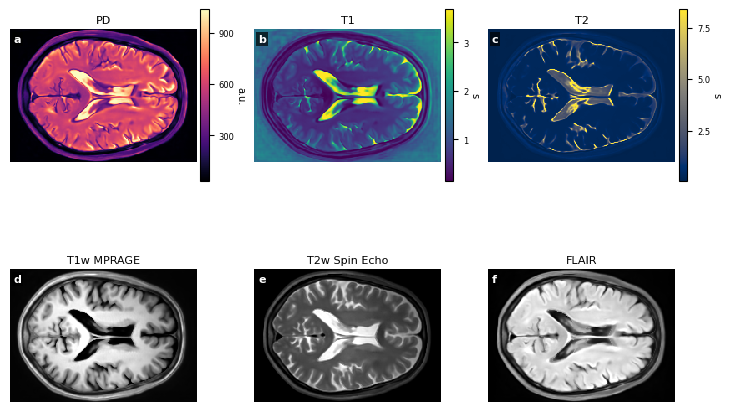

Manuscript reference figure exported.
PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/native_e0_physical_reference_seed_007_600dpi.png
PDF (vector text and line art): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/native_e0_physical_reference_seed_007.pdf
Raw tensors: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/native_e0_physical_reference_seed_007_raw_outputs.pt
Display windows: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/native_e0_physical_reference_seed_007_display_windows.json
Output summary: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/native_e0_physical_reference_seed_007_output_summary.csv
Metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/native_e0_physical_reference_seed_007_metadata.json
Figure font: DejaVu Sans


,output,shape,minimum,maximum,p01,p50,p99
0,PD,"[160, 224]",1.924562e+01,1274.961182,31.358283,404.419952,1039.568243
1,T1,"[160, 224]",8.619801e-02,4.328520,0.139982,0.907490,3.681295
2,T2,"[160, 224]",8.291303e-03,37.114685,0.045328,0.320088,8.389181
3,T1w MPRAGE,"[160, 224]",-9.945930e+00,488.290527,-1.876757,145.434608,431.862841
4,T2w Spin Echo,"[160, 224]",9.179513e-22,582.791504,0.002219,131.652603,514.678413
5,FLAIR,"[160, 224]",5.848061e-03,625.387756,3.750452,241.502869,509.781400


In [8]:
# Cell 8 — Manuscript-ready native Euclidean physical-synthesis reference

from matplotlib.ticker import MaxNLocator
from matplotlib import font_manager
from PIL import Image
import matplotlib as mpl

if "MANUSCRIPT_RESULTS" not in globals():
    raise RuntimeError(
        "MANUSCRIPT_RESULTS is undefined. Run the reproducible setup cell first."
    )

MANUSCRIPT_FIGURE_DIR = MANUSCRIPT_RESULTS / "figures"
MANUSCRIPT_DATA_DIR = MANUSCRIPT_RESULTS / "data"

MANUSCRIPT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MANUSCRIPT_DATA_DIR.mkdir(parents=True, exist_ok=True)

PNG_DPI = 600
DISPLAY_LOW_PERCENTILE, DISPLAY_HIGH_PERCENTILE = CFG["display_percentiles"]

available_font_names = {
    font.name for font in font_manager.fontManager.ttflist
}

if "Arial" in available_font_names:
    manuscript_font = "Arial"
elif "Helvetica" in available_font_names:
    manuscript_font = "Helvetica"
elif "Liberation Sans" in available_font_names:
    manuscript_font = "Liberation Sans"
else:
    manuscript_font = "DejaVu Sans"

MRI_RENDER_PROTOCOLS = {
    "T1w MPRAGE": {
        "sequence": "MPRAGE",
        "TE_s": 0.003,
        "TR_s": 2.4,
        "TI_s": 1.0,
    },
    "T2w Spin Echo": {
        "sequence": "Spin Echo",
        "TE_s": 0.45,
        "TR_s": 3.2,
        "TI_s": None,
    },
    "FLAIR": {
        "sequence": "FLAIR",
        "TE_s": 0.091,
        "TR_s": 9.0,
        "TI_s": 2.5,
    },
}


def split_q_maps(q_map):
    """Return PD, T1, and T2 maps from [3, H, W] or [B, 3, H, W]."""
    if q_map.ndim not in (3, 4):
        raise ValueError(
            "Expected q-map tensor with shape [3, H, W] or [B, 3, H, W]."
        )

    if q_map.shape[-3] != 3:
        raise ValueError(
            f"Expected three q-map channels, got shape {tuple(q_map.shape)}."
        )

    return q_map.unbind(dim=-3)


def render_mprage(q_map, te, tr, ti):
    pd_map, t1_map, t2_map = split_q_maps(q_map)

    return (
        pd_map
        * (1.0 - (2.0 * torch.exp(-ti / t1_map))
           / (1.0 + torch.exp(-tr / t1_map)))
        * torch.exp(-te / t2_map)
    )


def render_spin_echo(q_map, te, tr):
    pd_map, t1_map, t2_map = split_q_maps(q_map)

    return (
        pd_map
        * (1.0 - torch.exp(-tr / t1_map))
        * torch.exp(-te / t2_map)
    )


def render_flair(q_map, te, tr, ti):
    pd_map, t1_map, t2_map = split_q_maps(q_map)

    return (
        pd_map
        * (1.0 - 2.0 * torch.exp(-ti / t1_map)
           + torch.exp(-tr / t1_map))
        * torch.exp(-te / t2_map)
    )


@torch.no_grad()
def create_physical_outputs(norm_log_q_maps):
    """
    Convert normalized decoder outputs into physical q-maps and MRI contrasts.

    Input:
        norm_log_q_maps: [B, 3, H, W]

    Returns:
        log_q_maps: [B, 3, H, W]
        q_maps: [B, 3, H, W]
        mri_images: dictionary of [B, H, W] tensors
    """
    if norm_log_q_maps.ndim != 4 or norm_log_q_maps.shape[1] != 3:
        raise ValueError(
            "Expected normalized log-q maps with shape [B, 3, H, W]."
        )

    log_q_maps = denormalize_log_q_map(
        norm_log_q_map=norm_log_q_maps.clone(),
        log_pd_mean=log_pd_prior_mean,
        log_t1_mean=log_t1_prior_mean,
        log_t2_mean=log_t2_prior_mean,
    )

    q_maps = torch.exp(log_q_maps)

    mri_images = {
        "T1w MPRAGE": render_mprage(
            q_maps,
            te=MRI_RENDER_PROTOCOLS["T1w MPRAGE"]["TE_s"],
            tr=MRI_RENDER_PROTOCOLS["T1w MPRAGE"]["TR_s"],
            ti=MRI_RENDER_PROTOCOLS["T1w MPRAGE"]["TI_s"],
        ),
        "T2w Spin Echo": render_spin_echo(
            q_maps,
            te=MRI_RENDER_PROTOCOLS["T2w Spin Echo"]["TE_s"],
            tr=MRI_RENDER_PROTOCOLS["T2w Spin Echo"]["TR_s"],
        ),
        "FLAIR": render_flair(
            q_maps,
            te=MRI_RENDER_PROTOCOLS["FLAIR"]["TE_s"],
            tr=MRI_RENDER_PROTOCOLS["FLAIR"]["TR_s"],
            ti=MRI_RENDER_PROTOCOLS["FLAIR"]["TI_s"],
        ),
    }

    all_outputs = [log_q_maps, q_maps, *mri_images.values()]

    if not all(bool(torch.isfinite(output).all()) for output in all_outputs):
        raise FloatingPointError(
            "Non-finite values were found during physical MRI rendering."
        )

    return log_q_maps, q_maps, mri_images


def percentile_window(tensor, low_percentile, high_percentile):
    values = tensor.detach().float().cpu().numpy().ravel()
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError("Cannot compute a display window from non-finite values.")

    lower, upper = np.percentile(
        values,
        [low_percentile, high_percentile],
    )

    if upper <= lower:
        upper = lower + 1e-6

    return float(lower), float(upper)


def output_summary_row(name, tensor):
    values = tensor.detach().float().cpu().numpy().ravel()
    values = values[np.isfinite(values)]

    return {
        "output": name,
        "shape": list(tensor.shape),
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values)),
        "p01": float(np.percentile(values, 1.0)),
        "p50": float(np.percentile(values, 50.0)),
        "p99": float(np.percentile(values, 99.0)),
    }


(
    e0_log_q_maps_batched,
    e0_q_maps_batched,
    e0_mri_images_batched,
) = create_physical_outputs(e0_norm_log_q_maps)

e0_log_q_maps = e0_log_q_maps_batched[0]
e0_q_maps = e0_q_maps_batched[0]

e0_mri_images = {
    name: image[0]
    for name, image in e0_mri_images_batched.items()
}

e0_physical_outputs = {
    "norm_log_q_maps": e0_norm_log_q_maps,
    "log_q_maps": e0_log_q_maps_batched,
    "q_maps": e0_q_maps_batched,
    "mri_images": e0_mri_images_batched,
}

q_map_specs = [
    ("PD", "a.u.", "magma"),
    ("T1", "s", "viridis"),
    ("T2", "s", "cividis"),
]

mri_specs = [
    ("T1w MPRAGE", "gray"),
    ("T2w Spin Echo", "gray"),
    ("FLAIR", "gray"),
]

e0_display_windows = {
    q_map_specs[index][0]: percentile_window(
        e0_q_maps[index],
        DISPLAY_LOW_PERCENTILE,
        DISPLAY_HIGH_PERCENTILE,
    )
    for index in range(3)
}

e0_display_windows.update(
    {
        name: percentile_window(
            image,
            DISPLAY_LOW_PERCENTILE,
            DISPLAY_HIGH_PERCENTILE,
        )
        for name, image in e0_mri_images.items()
    }
)

e0_pd_numpy = e0_q_maps[0].detach().float().cpu().numpy()
e0_foreground_pd_threshold = float(
    np.quantile(
        e0_pd_numpy[np.isfinite(e0_pd_numpy)],
        CFG["foreground_pd_quantile"],
    )
)

e0_foreground_mask = e0_pd_numpy > e0_foreground_pd_threshold

panel_labels = ["a", "b", "c", "d", "e", "f"]

with mpl.rc_context(
    {
        "font.family": manuscript_font,
        "font.size": 8,
        "axes.titleweight": "regular",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    fig, axes = plt.subplots(
        2,
        3,
        figsize=(7.2, 4.8),
        constrained_layout=True,
    )

    for index, (map_name, unit, cmap) in enumerate(q_map_specs):
        ax = axes[0, index]
        image = e0_q_maps[index].detach().float().cpu().numpy()
        vmin, vmax = e0_display_windows[map_name]

        image_handle = ax.imshow(
            image,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            rasterized=True,
        )

        ax.set_title(map_name, pad=4, fontsize=8)
        ax.axis("off")

        ax.text(
            0.02,
            0.96,
            panel_labels[index],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=8,
            fontweight="bold",
            color="white",
            bbox={
                "facecolor": "black",
                "edgecolor": "none",
                "alpha": 0.70,
                "pad": 1.2,
            },
        )

        colorbar = fig.colorbar(
            image_handle,
            ax=ax,
            fraction=0.046,
            pad=0.02,
        )
        colorbar.set_label(unit, rotation=270, labelpad=8, fontsize=7)
        colorbar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        colorbar.ax.tick_params(labelsize=6)

    for index, (name, cmap) in enumerate(mri_specs):
        ax = axes[1, index]
        image = e0_mri_images[name].detach().float().cpu().numpy()
        vmin, vmax = e0_display_windows[name]

        ax.imshow(
            image,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            rasterized=True,
        )

        ax.set_title(name, pad=4, fontsize=8)
        ax.axis("off")

        ax.text(
            0.02,
            0.96,
            panel_labels[index + 3],
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=8,
            fontweight="bold",
            color="white",
            bbox={
                "facecolor": "black",
                "edgecolor": "none",
                "alpha": 0.70,
                "pad": 1.2,
            },
        )

figure_stem = f"native_e0_physical_reference_seed_{e0_seed:03d}"

manuscript_png_path = (
    MANUSCRIPT_FIGURE_DIR / f"{figure_stem}_600dpi.png"
)

manuscript_pdf_path = (
    MANUSCRIPT_FIGURE_DIR / f"{figure_stem}.pdf"
)

fig.savefig(
    manuscript_png_path,
    dpi=PNG_DPI,
    facecolor="white",
    transparent=False,
    bbox_inches="tight",
)

with Image.open(manuscript_png_path) as image:
    image.convert("RGB").save(
        manuscript_png_path,
        dpi=(PNG_DPI, PNG_DPI),
    )

fig.savefig(
    manuscript_pdf_path,
    format="pdf",
    dpi=PNG_DPI,
    facecolor="white",
    transparent=False,
    bbox_inches="tight",
    metadata={
        "Title": "Native Euclidean physical-synthesis reference",
        "Creator": "Matplotlib",
    },
)

plt.show()
plt.close(fig)

manuscript_tensor_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_raw_outputs.pt"
)

manuscript_window_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_display_windows.json"
)

manuscript_summary_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_output_summary.csv"
)

manuscript_metadata_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_metadata.json"
)

torch.save(
    {
        "seed": e0_seed,
        "initial_noise": e0_initial_noise.detach().cpu(),
        "norm_log_q_maps": e0_norm_log_q_maps.detach().cpu(),
        "log_q_maps": e0_log_q_maps_batched.detach().cpu(),
        "q_maps": e0_q_maps_batched.detach().cpu(),
        "mri_images": {
            name: image.detach().cpu()
            for name, image in e0_mri_images_batched.items()
        },
        "foreground_pd_threshold": e0_foreground_pd_threshold,
        "foreground_mask": e0_foreground_mask,
    },
    manuscript_tensor_path,
)

with open(manuscript_window_path, "w") as file:
    json.dump(e0_display_windows, file, indent=2)

summary_rows = [
    output_summary_row("PD", e0_q_maps[0]),
    output_summary_row("T1", e0_q_maps[1]),
    output_summary_row("T2", e0_q_maps[2]),
]

summary_rows.extend(
    output_summary_row(name, image)
    for name, image in e0_mri_images.items()
)

reference_output_summary_df = pd.DataFrame(summary_rows)
reference_output_summary_df.to_csv(
    manuscript_summary_path,
    index=False,
)

manuscript_metadata = {
    "seed": int(e0_seed),
    "png_dpi": PNG_DPI,
    "font": manuscript_font,
    "display_percentiles": [
        float(DISPLAY_LOW_PERCENTILE),
        float(DISPLAY_HIGH_PERCENTILE),
    ],
    "foreground_pd_quantile": float(CFG["foreground_pd_quantile"]),
    "foreground_pd_threshold": e0_foreground_pd_threshold,
    "physical_render_protocols": MRI_RENDER_PROTOCOLS,
    "display_windows": e0_display_windows,
    "png_path": str(manuscript_png_path),
    "pdf_path": str(manuscript_pdf_path),
    "raw_tensor_path": str(manuscript_tensor_path),
}

with open(manuscript_metadata_path, "w") as file:
    json.dump(manuscript_metadata, file, indent=2)

nature_reference_figure_path = manuscript_png_path
raw_output_path = manuscript_tensor_path
display_window_path = manuscript_window_path

print("Manuscript reference figure exported.")
print("PNG (RGB, 600 dpi):", manuscript_png_path)
print("PDF (vector text and line art):", manuscript_pdf_path)
print("Raw tensors:", manuscript_tensor_path)
print("Display windows:", manuscript_window_path)
print("Output summary:", manuscript_summary_path)
print("Metadata:", manuscript_metadata_path)
print("Figure font:", manuscript_font)

display(reference_output_summary_df)

In [9]:
# Cell 9 — Archive the untouched native DDIM trajectory for manuscript analysis

TRACE_EPS = 1e-12

if "MANUSCRIPT_DATA_DIR" not in globals():
    if "MANUSCRIPT_RESULTS" not in globals():
        raise RuntimeError(
            "MANUSCRIPT_RESULTS is undefined. Run the setup cell first."
        )

    MANUSCRIPT_DATA_DIR = MANUSCRIPT_RESULTS / "data"
    MANUSCRIPT_DATA_DIR.mkdir(parents=True, exist_ok=True)

TRACE_DATA_DIR = MANUSCRIPT_DATA_DIR / "trajectories"
TRACE_DATA_DIR.mkdir(parents=True, exist_ok=True)


def l2_norm(tensor):
    """Return the Euclidean L2 norm over all tensor elements."""
    return torch.linalg.vector_norm(tensor)


def rms(tensor):
    """Return the root-mean-square value over all tensor elements."""
    return torch.sqrt(torch.mean(tensor.square()))


def flat_cosine_similarity(first, second, eps=TRACE_EPS):
    """Return cosine similarity after flattening both tensors."""
    numerator = torch.sum(first * second)
    denominator = l2_norm(first) * l2_norm(second) + eps
    return numerator / denominator


def scalar_from_tensor(value):
    """Convert a scalar tensor or scalar value to a Python float."""
    if torch.is_tensor(value):
        return float(value.detach().cpu())
    return float(value)


def integer_from_tensor(value):
    """Convert an integer tensor or integer value to a Python int."""
    if torch.is_tensor(value):
        return int(value.detach().cpu())
    return int(value)


@torch.no_grad()
def native_ddim_trace(
    input_noise,
    diffusion_model,
    scheduler,
    autoencoder_model,
    latent_scale_factor,
):
    """
    Reproduce the installed DiffusionInferer.sample loop exactly.

    No drift, geometry operation, or post-DDIM modification is applied.
    The returned tensor archive stores the native Euclidean DDIM trajectory.
    """

    if input_noise.ndim != 4:
        raise ValueError(
            "Expected input noise with shape [B, C, H, W]."
        )

    if tuple(input_noise.shape[1:]) != tuple(CFG["latent_shape"]):
        raise ValueError(
            f"Unexpected latent shape {tuple(input_noise.shape[1:])}. "
            f"Expected {CFG['latent_shape']}."
        )

    if len(scheduler.timesteps) != CFG["num_inference_steps"]:
        raise RuntimeError(
            "The scheduler timestep count does not match the experiment configuration."
        )

    image = input_noise.clone()

    records = []
    x_t_scaled = []
    x_prev_scaled = []
    pred_x0_scaled = []
    predicted_epsilon = []

    previous_update = None

    for reverse_step, timestep in enumerate(scheduler.timesteps):
        image_before = image

        # This line intentionally matches the installed DiffusionInferer.sample loop.
        timestep_tensor = torch.Tensor((timestep,)).to(input_noise.device)

        model_output = diffusion_model(
            image_before,
            timesteps=timestep_tensor,
            context=None,
        )

        if model_output.shape != image_before.shape:
            raise ValueError(
                "The diffusion model output shape does not match the latent state."
            )

        base_image_after, predicted_x0 = scheduler.step(
            model_output,
            timestep,
            image_before,
        )

        if base_image_after.shape != image_before.shape:
            raise ValueError(
                "The DDIM scheduler changed the latent tensor shape."
            )

        if not bool(torch.isfinite(base_image_after).all()):
            raise FloatingPointError(
                f"Non-finite native DDIM state at reverse step {reverse_step}."
            )

        update = base_image_after - image_before

        radial_coefficient = (
            torch.sum(update * image_before)
            / (torch.sum(image_before.square()) + TRACE_EPS)
        )

        radial_component = radial_coefficient * image_before
        tangential_component = update - radial_component

        radial_update_signed_l2 = (
            torch.sign(radial_coefficient)
            * l2_norm(radial_component)
        )

        alpha_bar = scheduler.alphas_cumprod[timestep]
        alpha_bar_value = scalar_from_tensor(alpha_bar)

        if previous_update is None:
            update_cosine = float("nan")
        else:
            update_cosine = scalar_from_tensor(
                flat_cosine_similarity(update, previous_update)
            )

        records.append(
            {
                "reverse_step": int(reverse_step),
                "timestep": integer_from_tensor(timestep),
                "alpha_bar": alpha_bar_value,
                "snr": alpha_bar_value / (1.0 - alpha_bar_value + TRACE_EPS),
                "z_before_l2": scalar_from_tensor(l2_norm(image_before)),
                "z_before_rms": scalar_from_tensor(rms(image_before)),
                "z_after_l2": scalar_from_tensor(l2_norm(base_image_after)),
                "z_after_rms": scalar_from_tensor(rms(base_image_after)),
                "epsilon_l2": scalar_from_tensor(l2_norm(model_output)),
                "epsilon_rms": scalar_from_tensor(rms(model_output)),
                "pred_x0_l2": scalar_from_tensor(l2_norm(predicted_x0)),
                "pred_x0_rms": scalar_from_tensor(rms(predicted_x0)),
                "update_l2": scalar_from_tensor(l2_norm(update)),
                "update_rms": scalar_from_tensor(rms(update)),
                "relative_update": scalar_from_tensor(
                    l2_norm(update) / (l2_norm(image_before) + TRACE_EPS)
                ),
                "radial_coefficient": scalar_from_tensor(radial_coefficient),
                "radial_update_signed_l2": scalar_from_tensor(
                    radial_update_signed_l2
                ),
                "radial_update_l2": scalar_from_tensor(
                    l2_norm(radial_component)
                ),
                "tangential_update_l2": scalar_from_tensor(
                    l2_norm(tangential_component)
                ),
                "consecutive_update_cosine": update_cosine,
            }
        )

        x_t_scaled.append(image_before.detach().cpu().clone())
        x_prev_scaled.append(base_image_after.detach().cpu().clone())
        pred_x0_scaled.append(predicted_x0.detach().cpu().clone())
        predicted_epsilon.append(model_output.detach().cpu().clone())

        previous_update = update.detach().clone()
        image = base_image_after

    final_scaled_latent = image

    # This line intentionally matches LatentDiffusionInferer.sample.
    norm_log_q_maps = autoencoder_model.decode_stage_2_outputs(
        final_scaled_latent / latent_scale_factor
    )

    if not bool(torch.isfinite(norm_log_q_maps).all()):
        raise FloatingPointError(
            "Non-finite decoded normalized log-q maps after native sampling."
        )

    trace_dataframe = pd.DataFrame(records)

    trace_tensors = {
        "x_t_scaled": torch.stack(x_t_scaled),
        "x_prev_scaled": torch.stack(x_prev_scaled),
        "pred_x0_scaled": torch.stack(pred_x0_scaled),
        "predicted_epsilon": torch.stack(predicted_epsilon),
    }

    return (
        norm_log_q_maps,
        final_scaled_latent,
        trace_dataframe,
        trace_tensors,
    )


(
    e0_custom_norm_log_q_maps,
    e0_custom_final_scaled_latent,
    e0_trace_df,
    e0_trace_tensors,
) = native_ddim_trace(
    input_noise=e0_initial_noise,
    diffusion_model=unet,
    scheduler=ddim_scheduler,
    autoencoder_model=autoencoder,
    latent_scale_factor=scale_factor,
)

numeric_trace = e0_trace_df.select_dtypes(include=[np.number])

trace_without_undefined_cosine = numeric_trace.drop(
    columns=["consecutive_update_cosine"]
)

defined_update_cosines = e0_trace_df[
    "consecutive_update_cosine"
].iloc[1:]

assert len(e0_trace_df) == CFG["num_inference_steps"]
assert bool(
    np.isfinite(trace_without_undefined_cosine.to_numpy()).all()
)
assert bool(np.isfinite(defined_update_cosines.to_numpy()).all())
assert bool(np.isnan(
    e0_trace_df["consecutive_update_cosine"].iloc[0]
))

e0_trace_metric_summary_df = (
    e0_trace_df
    .drop(columns=["reverse_step", "timestep"])
    .agg(["count", "mean", "std", "min", "max"])
    .transpose()
    .reset_index()
    .rename(columns={"index": "metric"})
)

trace_stem = f"native_e0_ddim_trace_seed_{e0_seed:03d}"

e0_trace_csv_path = TRACE_DATA_DIR / f"{trace_stem}.csv"
e0_trace_tensor_path = TRACE_DATA_DIR / f"{trace_stem}.pt"
e0_trace_summary_path = TRACE_DATA_DIR / f"{trace_stem}_summary.csv"
e0_trace_metadata_path = TRACE_DATA_DIR / f"{trace_stem}_metadata.json"

e0_trace_df.to_csv(
    e0_trace_csv_path,
    index=False,
)

e0_trace_metric_summary_df.to_csv(
    e0_trace_summary_path,
    index=False,
)

torch.save(
    {
        "seed": int(e0_seed),
        "initial_noise": e0_initial_noise.detach().cpu(),
        "final_scaled_latent": e0_custom_final_scaled_latent.detach().cpu(),
        "final_norm_log_q_maps": e0_custom_norm_log_q_maps.detach().cpu(),
        **e0_trace_tensors,
    },
    e0_trace_tensor_path,
)

e0_trace_metadata = {
    "condition": "E0 native Euclidean baseline",
    "seed": int(e0_seed),
    "num_inference_steps": int(CFG["num_inference_steps"]),
    "latent_shape": list(CFG["latent_shape"]),
    "transition_definition": (
        "base_x_prev, predicted_x0 = "
        "DDIMScheduler.step(predicted_epsilon, timestep, x_t)"
    ),
    "tensor_semantics": {
        "x_t_scaled": "Native scaled latent before each DDIM transition.",
        "x_prev_scaled": "Native scaled latent after each DDIM transition.",
        "pred_x0_scaled": (
            "Scheduler estimate of the clean scaled latent at each step."
        ),
        "predicted_epsilon": (
            "U-Net predicted noise at each DDIM timestep."
        ),
    },
    "radial_tangential_definition": (
        "The native DDIM update is decomposed into its Euclidean projection "
        "onto x_t and its orthogonal residual."
    ),
    "undefined_value": (
        "The first consecutive_update_cosine is NaN because no previous "
        "update exists."
    ),
    "trace_csv_path": str(e0_trace_csv_path),
    "trace_tensor_path": str(e0_trace_tensor_path),
    "trace_summary_path": str(e0_trace_summary_path),
}

with open(e0_trace_metadata_path, "w") as file:
    json.dump(e0_trace_metadata, file, indent=2)

print("Native E0 DDIM trajectory archived successfully.")
print("Trace rows:", len(e0_trace_df))
print("First timestep:", int(e0_trace_df.iloc[0]["timestep"]))
print("Last timestep:", int(e0_trace_df.iloc[-1]["timestep"]))
print("All defined trajectory metrics are finite.")
print("The first consecutive-update cosine is intentionally undefined.")
print("Trace table:", e0_trace_csv_path)
print("Trace tensors:", e0_trace_tensor_path)
print("Trace summary:", e0_trace_summary_path)
print("Trace metadata:", e0_trace_metadata_path)

display(e0_trace_df.head(3))
display(e0_trace_df.tail(3))
display(e0_trace_metric_summary_df)

Native E0 DDIM trajectory archived successfully.
Trace rows: 50
First timestep: 980
Last timestep: 0
All defined trajectory metrics are finite.
The first consecutive-update cosine is intentionally undefined.
Trace table: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/trajectories/native_e0_ddim_trace_seed_007.csv
Trace tensors: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/trajectories/native_e0_ddim_trace_seed_007.pt
Trace summary: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/trajectories/native_e0_ddim_trace_seed_007_summary.csv
Trace metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/trajectories/native_e0_ddim_trace_seed_007_metadata.json


,reverse_step,timestep,alpha_bar,snr,z_before_l2,z_before_rms,z_after_l2,z_after_rms,epsilon_l2,epsilon_rms,pred_x0_l2,pred_x0_rms,update_l2,update_rms,relative_update,radial_coefficient,radial_update_signed_l2,radial_update_l2,tangential_update_l2,consecutive_update_cosine
0,0,980,0.000143,0.000143,58.200104,1.004047,58.187569,1.003831,58.261288,1.005103,78.455452,1.353485,0.206097,0.003556,0.003541,-0.000222,-0.012899,0.012899,0.205693,NaN
1,1,960,0.000213,0.000213,58.187569,1.003831,58.179073,1.003684,58.230961,1.004580,70.146118,1.210136,0.217341,0.003749,0.003735,-0.000153,-0.008899,0.008899,0.217158,0.985213
2,2,940,0.000312,0.000313,58.179073,1.003684,58.180557,1.003710,58.172638,1.003573,60.272903,1.039806,0.218747,0.003774,0.003760,0.000018,0.001070,0.001070,0.218745,0.995039


,reverse_step,timestep,alpha_bar,snr,z_before_l2,z_before_rms,z_after_l2,z_after_rms,epsilon_l2,epsilon_rms,pred_x0_l2,pred_x0_rms,update_l2,update_rms,relative_update,radial_coefficient,radial_update_signed_l2,radial_update_l2,tangential_update_l2,consecutive_update_cosine
47,47,40,0.933849,14.116979,63.691986,1.098791,64.041664,1.104824,57.231689,0.987340,64.558853,1.113746,4.537221,0.078275,0.071237,0.002968,0.189030,0.189030,4.533281,0.997105
48,48,20,0.967288,29.570172,64.041664,1.104824,64.511040,1.112921,54.780170,0.945048,64.575989,1.114042,7.876551,0.135883,0.122991,-0.000207,-0.013277,0.013277,7.876540,0.992720
49,49,0,0.998500,665.662004,64.511040,1.112921,64.567024,1.113887,32.310455,0.557408,64.567024,1.113887,1.253081,0.021618,0.019424,0.000679,0.043833,0.043833,1.252314,0.957250


,metric,count,mean,std,min,max
0,alpha_bar,50.0,0.281169,0.328118,0.000143,0.998500
1,snr,50.0,14.988177,94.017256,0.000143,665.662004
2,z_before_l2,50.0,59.715974,1.899066,58.159126,64.511040
3,z_before_rms,50.0,1.030198,0.032762,1.003340,1.112921
4,z_after_l2,50.0,59.843313,2.005809,58.159126,64.567024
5,z_after_rms,50.0,1.032395,0.034603,1.003340,1.113887
6,epsilon_l2,50.0,57.622389,3.696318,32.310455,58.776939
7,epsilon_rms,50.0,0.994081,0.063768,0.557408,1.013999
8,pred_x0_l2,50.0,61.303770,5.158003,51.191406,78.455452
9,pred_x0_rms,50.0,1.057591,0.088984,0.883136,1.353485


In [10]:
# Cell 10 — Verify that trajectory recording preserves native MONAI sampling

if "MANUSCRIPT_DATA_DIR" not in globals():
    raise RuntimeError(
        "MANUSCRIPT_DATA_DIR is undefined. Run the manuscript setup cells first."
    )

EQUIVALENCE_DATA_DIR = MANUSCRIPT_DATA_DIR / "verification"
EQUIVALENCE_DATA_DIR.mkdir(parents=True, exist_ok=True)

EQUIVALENCE_RTOL = 1e-6
EQUIVALENCE_ATOL = 1e-6


def max_absolute_difference(first, second):
    """Return the maximum absolute element-wise difference."""
    return float(torch.max(torch.abs(first - second)).detach().cpu())


def mean_absolute_difference(first, second):
    """Return the mean absolute element-wise difference."""
    return float(torch.mean(torch.abs(first - second)).detach().cpu())


def root_mean_squared_difference(first, second):
    """Return the root-mean-squared element-wise difference."""
    return float(
        torch.sqrt(torch.mean((first - second).square())).detach().cpu()
    )


def summarize_tensor_equivalence(comparison, first, second):
    """Create one auditable tensor-equivalence record."""
    if first.shape != second.shape:
        raise ValueError(
            f"Shape mismatch in {comparison}: "
            f"{tuple(first.shape)} versus {tuple(second.shape)}."
        )

    if not bool(torch.isfinite(first).all()):
        raise FloatingPointError(
            f"Non-finite values found in the first tensor of {comparison}."
        )

    if not bool(torch.isfinite(second).all()):
        raise FloatingPointError(
            f"Non-finite values found in the second tensor of {comparison}."
        )

    return {
        "comparison": comparison,
        "shape": str(tuple(first.shape)),
        "maximum_absolute_difference": max_absolute_difference(first, second),
        "mean_absolute_difference": mean_absolute_difference(first, second),
        "root_mean_squared_difference": root_mean_squared_difference(
            first,
            second,
        ),
        "exact_tensor_equality": bool(torch.equal(first, second)),
    }


if DEVICE.type == "cuda":
    torch.cuda.synchronize()

native_sampling_start_time = time.perf_counter()

with torch.no_grad():
    # This is the installed MONAI parent DDIM sampler.
    e0_native_final_scaled_latent = base_inferer_class.sample(
        inferer,
        input_noise=e0_initial_noise,
        diffusion_model=unet,
        verbose=False,
    )

    # This explicitly decodes the latent returned by the parent sampler.
    e0_native_decoded_from_latent = autoencoder.decode_stage_2_outputs(
        e0_native_final_scaled_latent / scale_factor
    )

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

native_sampling_seconds = (
    time.perf_counter() - native_sampling_start_time
)

if e0_native_final_scaled_latent.shape != e0_custom_final_scaled_latent.shape:
    raise RuntimeError(
        "The native and trace-preserving samplers returned different latent shapes."
    )

if e0_native_decoded_from_latent.shape != e0_custom_norm_log_q_maps.shape:
    raise RuntimeError(
        "The native and trace-preserving samplers returned different q-map shapes."
    )

torch.testing.assert_close(
    e0_custom_final_scaled_latent,
    e0_native_final_scaled_latent,
    rtol=EQUIVALENCE_RTOL,
    atol=EQUIVALENCE_ATOL,
)

torch.testing.assert_close(
    e0_custom_norm_log_q_maps,
    e0_native_decoded_from_latent,
    rtol=EQUIVALENCE_RTOL,
    atol=EQUIVALENCE_ATOL,
)

torch.testing.assert_close(
    e0_native_decoded_from_latent,
    e0_norm_log_q_maps,
    rtol=EQUIVALENCE_RTOL,
    atol=EQUIVALENCE_ATOL,
)

torch.testing.assert_close(
    e0_custom_norm_log_q_maps,
    e0_norm_log_q_maps,
    rtol=EQUIVALENCE_RTOL,
    atol=EQUIVALENCE_ATOL,
)

equivalence_rows = [
    summarize_tensor_equivalence(
        "Trace sampler final latent vs native MONAI final latent",
        e0_custom_final_scaled_latent,
        e0_native_final_scaled_latent,
    ),
    summarize_tensor_equivalence(
        "Trace sampler decoded q-maps vs decoder applied to native latent",
        e0_custom_norm_log_q_maps,
        e0_native_decoded_from_latent,
    ),
    summarize_tensor_equivalence(
        "Decoder applied to native latent vs full native LDM output",
        e0_native_decoded_from_latent,
        e0_norm_log_q_maps,
    ),
    summarize_tensor_equivalence(
        "Trace sampler decoded q-maps vs full native LDM output",
        e0_custom_norm_log_q_maps,
        e0_norm_log_q_maps,
    ),
]

e0_equivalence_summary = pd.DataFrame(equivalence_rows)

numeric_trace = e0_trace_df.select_dtypes(include=[np.number])

trace_metrics_without_first_cosine = numeric_trace.drop(
    columns=["consecutive_update_cosine"]
)

defined_update_cosines = e0_trace_df[
    "consecutive_update_cosine"
].iloc[1:]

assert bool(
    np.isfinite(trace_metrics_without_first_cosine.to_numpy()).all()
)

assert bool(np.isfinite(defined_update_cosines.to_numpy()).all())

assert bool(
    np.isnan(e0_trace_df["consecutive_update_cosine"].iloc[0])
)

equivalence_stem = f"native_e0_equivalence_seed_{e0_seed:03d}"

e0_equivalence_csv_path = (
    EQUIVALENCE_DATA_DIR / f"{equivalence_stem}.csv"
)

e0_equivalence_metadata_path = (
    EQUIVALENCE_DATA_DIR / f"{equivalence_stem}_metadata.json"
)

e0_equivalence_summary.to_csv(
    e0_equivalence_csv_path,
    index=False,
)

e0_equivalence_metadata = {
    "seed": int(e0_seed),
    "relative_tolerance": EQUIVALENCE_RTOL,
    "absolute_tolerance": EQUIVALENCE_ATOL,
    "native_parent_sampler": base_inferer_class.__name__,
    "native_sampling_time_seconds": float(native_sampling_seconds),
    "trajectory_trace_rows": int(len(e0_trace_df)),
    "first_consecutive_update_cosine_is_undefined": True,
    "equivalence_csv_path": str(e0_equivalence_csv_path),
}

with open(e0_equivalence_metadata_path, "w") as file:
    json.dump(e0_equivalence_metadata, file, indent=2)

print("Native-sampler equivalence verification passed.")
print("Native parent sampler:", base_inferer_class.__name__)
print("Native sampling time [s]:", round(native_sampling_seconds, 3))
print("Trace rows:", len(e0_trace_df))
print("All defined trajectory metrics are finite.")
print("The first consecutive-update cosine is intentionally undefined.")
print("Equivalence table:", e0_equivalence_csv_path)
print("Equivalence metadata:", e0_equivalence_metadata_path)

display(e0_equivalence_summary)

Native-sampler equivalence verification passed.
Native parent sampler: DiffusionInferer
Native sampling time [s]: 1.809
Trace rows: 50
All defined trajectory metrics are finite.
The first consecutive-update cosine is intentionally undefined.
Equivalence table: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/native_e0_equivalence_seed_007.csv
Equivalence metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/native_e0_equivalence_seed_007_metadata.json


,comparison,shape,maximum_absolute_difference,mean_absolute_difference,root_mean_squared_difference,exact_tensor_equality
0,Trace sampler final latent vs native MONAI fin...,"(1, 6, 20, 28)",0.0,0.0,0.0,True
1,Trace sampler decoded q-maps vs decoder applie...,"(1, 3, 160, 224)",0.0,0.0,0.0,True
2,Decoder applied to native latent vs full nativ...,"(1, 3, 160, 224)",0.0,0.0,0.0,True
3,Trace sampler decoded q-maps vs full native LD...,"(1, 3, 160, 224)",0.0,0.0,0.0,True


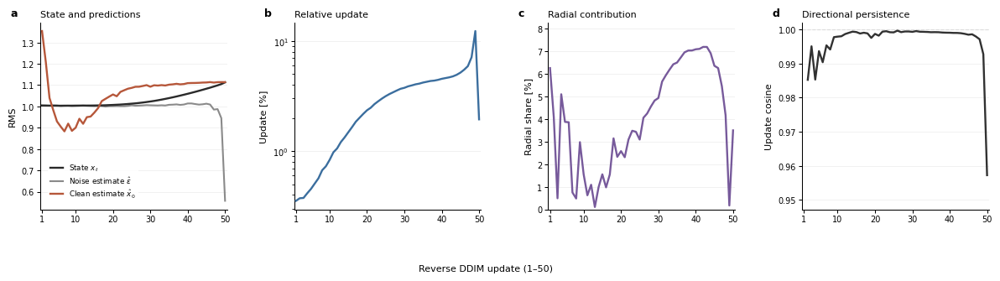

Square-panel manuscript dynamics figure exported.
PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/extended_data_native_e0_ddim_dynamics_seed_007_600dpi.png
PDF (vector): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/extended_data_native_e0_ddim_dynamics_seed_007.pdf
Source data: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/extended_data_native_e0_ddim_dynamics_seed_007_source_data.csv
Summary: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/extended_data_native_e0_ddim_dynamics_seed_007_summary.csv
Metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/extended_data_native_e0_ddim_dynamics_seed_007_metadata.json


,metric,value,unit
0,Initial latent RMS,1.004047,RMS
1,Final latent RMS,1.113887,RMS
2,Initial SNR,0.000143,SNR
3,Final SNR,665.662004,SNR
4,Peak relative update,12.299105,%
5,Peak update displayed step,49.000000,one-based step
6,Mean radial contribution,4.045149,%
7,Maximum radial contribution,7.197493,%
8,Mean consecutive-update cosine,0.996798,cosine
9,Minimum consecutive-update cosine,0.957250,cosine


In [11]:
# Cell 11 — Square-panel manuscript-ready native Euclidean DDIM dynamics

from PIL import Image
import matplotlib as mpl

if "MANUSCRIPT_FIGURE_DIR" not in globals():
    if "MANUSCRIPT_RESULTS" not in globals():
        raise RuntimeError(
            "MANUSCRIPT_RESULTS is undefined. Run the manuscript setup cells first."
        )

    MANUSCRIPT_FIGURE_DIR = MANUSCRIPT_RESULTS / "figures"
    MANUSCRIPT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if "MANUSCRIPT_DATA_DIR" not in globals():
    MANUSCRIPT_DATA_DIR = MANUSCRIPT_RESULTS / "data"
    MANUSCRIPT_DATA_DIR.mkdir(parents=True, exist_ok=True)

if "PNG_DPI" not in globals():
    PNG_DPI = 600

if "manuscript_font" not in globals():
    manuscript_font = "DejaVu Sans"

required_trace_columns = [
    "reverse_step",
    "timestep",
    "snr",
    "z_before_rms",
    "z_after_rms",
    "epsilon_rms",
    "pred_x0_rms",
    "relative_update",
    "radial_update_l2",
    "update_l2",
    "consecutive_update_cosine",
]

missing_trace_columns = [
    column
    for column in required_trace_columns
    if column not in e0_trace_df.columns
]

if missing_trace_columns:
    raise RuntimeError(
        "The E0 trace is missing required columns:\n"
        + "\n".join(f"  - {column}" for column in missing_trace_columns)
    )

trajectory_plot_df = e0_trace_df.copy()

if not bool((trajectory_plot_df["update_l2"] > 0.0).all()):
    raise FloatingPointError(
        "A non-positive DDIM update norm was found."
    )

# Internal trace indexing remains zero-based.
# Publication figures use one-based update numbering from 1 to 50.
trajectory_plot_df["display_step"] = (
    trajectory_plot_df["reverse_step"] + 1
)

trajectory_plot_df["relative_update_percent"] = (
    100.0 * trajectory_plot_df["relative_update"]
)

trajectory_plot_df["radial_fraction_percent"] = (
    100.0
    * trajectory_plot_df["radial_update_l2"]
    / trajectory_plot_df["update_l2"]
)

trace_metrics_without_first_cosine = trajectory_plot_df.drop(
    columns=["consecutive_update_cosine"]
).select_dtypes(include=[np.number])

defined_update_cosines = trajectory_plot_df[
    "consecutive_update_cosine"
].iloc[1:]

assert bool(
    np.isfinite(trace_metrics_without_first_cosine.to_numpy()).all()
)

assert bool(np.isfinite(defined_update_cosines.to_numpy()).all())

assert bool(
    np.isnan(
        trajectory_plot_df["consecutive_update_cosine"].iloc[0]
    )
)

trajectory_colors = {
    "state": "#2A2A2A",
    "epsilon": "#8A8A8A",
    "x0": "#B6573A",
    "update": "#3B6E9E",
    "radial": "#775A9B",
    "direction": "#313131",
    "reference": "#BDBDBD",
    "grid": "#ECECEC",
}

step = trajectory_plot_df["display_step"]
xticks = [1, 10, 20, 30, 40, 50]


def style_axis(axis):
    """Apply a restrained publication-style axis appearance."""
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.spines["left"].set_linewidth(0.75)
    axis.spines["bottom"].set_linewidth(0.75)

    axis.tick_params(
        axis="both",
        which="major",
        labelsize=7,
        width=0.75,
        length=3,
        direction="out",
        pad=2,
    )

    axis.grid(
        axis="y",
        color=trajectory_colors["grid"],
        linewidth=0.5,
        zorder=0,
    )


def add_panel_label(axis, label):
    """Add a publication-style panel label."""
    axis.text(
        -0.16,
        1.08,
        label,
        transform=axis.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        fontweight="bold",
        clip_on=False,
    )


def set_step_axis(axis):
    """Apply the common one-based reverse-DDIM update axis."""
    axis.set_xlim(0.5, 50.5)
    axis.set_xticks(xticks)


with mpl.rc_context(
    {
        "font.family": manuscript_font,
        "font.size": 8,
        "axes.titleweight": "regular",
        "axes.linewidth": 0.75,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    fig = plt.figure(figsize=(12.2, 3.6))

    grid_spec = fig.add_gridspec(
        nrows=1,
        ncols=4,
        left=0.065,
        right=0.992,
        bottom=0.205,
        top=0.915,
        wspace=0.36,
    )

    ax_a = fig.add_subplot(grid_spec[0, 0])
    ax_b = fig.add_subplot(grid_spec[0, 1])
    ax_c = fig.add_subplot(grid_spec[0, 2])
    ax_d = fig.add_subplot(grid_spec[0, 3])

    for axis in [ax_a, ax_b, ax_c, ax_d]:
        axis.set_box_aspect(1.0)

    # Panel a: latent-state and denoiser prediction scales
    ax_a.plot(
        step,
        trajectory_plot_df["z_before_rms"],
        color=trajectory_colors["state"],
        linewidth=1.7,
        label=r"State $x_t$",
        zorder=3,
    )
    ax_a.plot(
        step,
        trajectory_plot_df["epsilon_rms"],
        color=trajectory_colors["epsilon"],
        linewidth=1.5,
        label=r"Noise estimate $\hat{\epsilon}$",
        zorder=2,
    )
    ax_a.plot(
        step,
        trajectory_plot_df["pred_x0_rms"],
        color=trajectory_colors["x0"],
        linewidth=1.7,
        label=r"Clean estimate $\hat{x}_0$",
        zorder=3,
    )

    ax_a.set_title(
        "State and predictions",
        loc="left",
        fontsize=8,
        pad=5,
    )
    ax_a.set_ylabel("RMS", fontsize=8)
    set_step_axis(ax_a)
    style_axis(ax_a)

    ax_a.legend(
        loc="lower left",
        bbox_to_anchor=(0.02, 0.02),
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=0.90,
        fontsize=6.3,
        handlelength=1.8,
        labelspacing=0.28,
        borderpad=0.32,
    )
    add_panel_label(ax_a, "a")

    # Panel b: scale-invariant DDIM movement magnitude
    ax_b.plot(
        step,
        trajectory_plot_df["relative_update_percent"],
        color=trajectory_colors["update"],
        linewidth=1.7,
        zorder=3,
    )

    ax_b.set_yscale("log")
    ax_b.set_title(
        "Relative update",
        loc="left",
        fontsize=8,
        pad=5,
    )
    ax_b.set_ylabel("Update [%]", fontsize=8)
    set_step_axis(ax_b)
    style_axis(ax_b)
    add_panel_label(ax_b, "b")

    # Panel c: Euclidean radial contribution to each update
    ax_c.plot(
        step,
        trajectory_plot_df["radial_fraction_percent"],
        color=trajectory_colors["radial"],
        linewidth=1.7,
        zorder=3,
    )

    radial_upper_limit = max(
        8.0,
        1.15 * trajectory_plot_df["radial_fraction_percent"].max(),
    )

    ax_c.set_ylim(0.0, radial_upper_limit)
    ax_c.set_title(
        "Radial contribution",
        loc="left",
        fontsize=8,
        pad=5,
    )
    ax_c.set_ylabel("Radial share [%]", fontsize=8)
    set_step_axis(ax_c)
    style_axis(ax_c)
    add_panel_label(ax_c, "c")

    # Panel d: temporal consistency of the native update direction
    cosine_lower_limit = max(
        -1.0,
        float(defined_update_cosines.min()) - 0.01,
    )

    ax_d.plot(
        step.iloc[1:],
        defined_update_cosines,
        color=trajectory_colors["direction"],
        linewidth=1.7,
        zorder=3,
    )

    ax_d.axhline(
        1.0,
        color=trajectory_colors["reference"],
        linewidth=0.8,
        linestyle="--",
        zorder=1,
    )

    ax_d.set_ylim(cosine_lower_limit, 1.002)
    ax_d.set_title(
        "Directional persistence",
        loc="left",
        fontsize=8,
        pad=5,
    )
    ax_d.set_ylabel("Update cosine", fontsize=8)
    set_step_axis(ax_d)
    style_axis(ax_d)
    add_panel_label(ax_d, "d")

    fig.text(
        0.50,
        0.055,
        "Reverse DDIM update (1–50)",
        ha="center",
        va="center",
        fontsize=8,
    )

figure_stem = f"extended_data_native_e0_ddim_dynamics_seed_{e0_seed:03d}"

manuscript_trajectory_png_path = (
    MANUSCRIPT_FIGURE_DIR / f"{figure_stem}_600dpi.png"
)

manuscript_trajectory_pdf_path = (
    MANUSCRIPT_FIGURE_DIR / f"{figure_stem}.pdf"
)

fig.savefig(
    manuscript_trajectory_png_path,
    dpi=PNG_DPI,
    facecolor="white",
    transparent=False,
    bbox_inches="tight",
)

with Image.open(manuscript_trajectory_png_path) as image:
    image.convert("RGB").save(
        manuscript_trajectory_png_path,
        dpi=(PNG_DPI, PNG_DPI),
    )

fig.savefig(
    manuscript_trajectory_pdf_path,
    format="pdf",
    dpi=PNG_DPI,
    facecolor="white",
    transparent=False,
    bbox_inches="tight",
    metadata={
        "Title": "Native Euclidean DDIM dynamics",
        "Creator": "Matplotlib",
    },
)

plt.show()
plt.close(fig)

trajectory_figure_source_columns = [
    "reverse_step",
    "display_step",
    "timestep",
    "snr",
    "z_before_rms",
    "epsilon_rms",
    "pred_x0_rms",
    "relative_update_percent",
    "radial_fraction_percent",
    "consecutive_update_cosine",
]

trajectory_figure_source_df = trajectory_plot_df[
    trajectory_figure_source_columns
].copy()

trajectory_figure_source_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_source_data.csv"
)

trajectory_figure_summary_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_summary.csv"
)

trajectory_figure_metadata_path = (
    MANUSCRIPT_DATA_DIR / f"{figure_stem}_metadata.json"
)

trajectory_figure_source_df.to_csv(
    trajectory_figure_source_path,
    index=False,
)

peak_update_index = trajectory_plot_df["relative_update_percent"].idxmax()

trajectory_figure_summary_df = pd.DataFrame(
    [
        {
            "metric": "Initial latent RMS",
            "value": float(trajectory_plot_df["z_before_rms"].iloc[0]),
            "unit": "RMS",
        },
        {
            "metric": "Final latent RMS",
            "value": float(trajectory_plot_df["z_after_rms"].iloc[-1]),
            "unit": "RMS",
        },
        {
            "metric": "Initial SNR",
            "value": float(trajectory_plot_df["snr"].iloc[0]),
            "unit": "SNR",
        },
        {
            "metric": "Final SNR",
            "value": float(trajectory_plot_df["snr"].iloc[-1]),
            "unit": "SNR",
        },
        {
            "metric": "Peak relative update",
            "value": float(
                trajectory_plot_df.loc[
                    peak_update_index,
                    "relative_update_percent",
                ]
            ),
            "unit": "%",
        },
        {
            "metric": "Peak update displayed step",
            "value": int(
                trajectory_plot_df.loc[
                    peak_update_index,
                    "display_step",
                ]
            ),
            "unit": "one-based step",
        },
        {
            "metric": "Mean radial contribution",
            "value": float(
                trajectory_plot_df["radial_fraction_percent"].mean()
            ),
            "unit": "%",
        },
        {
            "metric": "Maximum radial contribution",
            "value": float(
                trajectory_plot_df["radial_fraction_percent"].max()
            ),
            "unit": "%",
        },
        {
            "metric": "Mean consecutive-update cosine",
            "value": float(defined_update_cosines.mean()),
            "unit": "cosine",
        },
        {
            "metric": "Minimum consecutive-update cosine",
            "value": float(defined_update_cosines.min()),
            "unit": "cosine",
        },
    ]
)

trajectory_figure_summary_df.to_csv(
    trajectory_figure_summary_path,
    index=False,
)

trajectory_figure_metadata = {
    "condition": "E0 native Euclidean baseline",
    "seed": int(e0_seed),
    "num_inference_steps": int(CFG["num_inference_steps"]),
    "figure_role": "Extended Data or Supplementary landscape diagnostic",
    "panel_geometry": "Four equal square plotting boxes in one horizontal row.",
    "display_step_indexing": (
        "The figure uses one-based update numbering from 1 to 50. "
        "The source trace retains zero-based reverse_step indexing from 0 to 49."
    ),
    "snr_handling": (
        "SNR remains in the source data and summary table but is omitted "
        "from the figure because it is a deterministic scheduler quantity "
        "that closely follows the relative-update trend."
    ),
    "radial_fraction_definition": (
        "100 * ||radial DDIM update|| / ||total DDIM update||, "
        "where the radial update is the Euclidean projection onto x_t."
    ),
    "first_cosine_value": "undefined",
    "png_path": str(manuscript_trajectory_png_path),
    "pdf_path": str(manuscript_trajectory_pdf_path),
    "source_data_path": str(trajectory_figure_source_path),
    "summary_path": str(trajectory_figure_summary_path),
}

with open(trajectory_figure_metadata_path, "w") as file:
    json.dump(trajectory_figure_metadata, file, indent=2)

trajectory_figure_path = manuscript_trajectory_png_path

print("Square-panel manuscript dynamics figure exported.")
print("PNG (RGB, 600 dpi):", manuscript_trajectory_png_path)
print("PDF (vector):", manuscript_trajectory_pdf_path)
print("Source data:", trajectory_figure_source_path)
print("Summary:", trajectory_figure_summary_path)
print("Metadata:", trajectory_figure_metadata_path)

display(trajectory_figure_summary_df)

In [12]:
# Cell 12 — Manuscript transition hook and Euclidean additive-drift reference

MANUSCRIPT_DATA_DIR = RESULTS / "manuscript" / "data"
TRANSITION_METHOD_DIR = MANUSCRIPT_DATA_DIR / "transition_method"
TRANSITION_METHOD_DIR.mkdir(parents=True, exist_ok=True)

required_symbols = [
    "CFG",
    "DEVICE",
    "autoencoder",
    "ddim_scheduler",
    "l2_norm",
    "rms",
    "scale_factor",
]

missing_symbols = [
    name for name in required_symbols
    if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Run the preceding manuscript setup cells before Cell 12.\n"
        "Missing notebook symbols:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
    )


def scalar_drift_expected_l2(delta, reference_tensor):
    """
    Return the exact L2 norm of adding scalar delta to every tensor element.
    """
    return abs(float(delta)) * float(np.sqrt(reference_tensor.numel()))


def make_scalar_latent_drift(delta):
    """
    Return a deterministic componentwise Euclidean post-DDIM modifier.

    The modification is applied in the pretrained model's scaled diffusion
    latent coordinates after scheduler.step:

        x_(t-1)^E = x_(t-1)^DDIM + delta * 1

    The scalar is broadcast across batch, channel, and spatial dimensions.
    """

    delta = float(delta)

    def transition_modifier(
        x_t,
        base_x_prev,
        predicted_epsilon,
        predicted_x0,
        timestep,
        reverse_step,
    ):
        del x_t, predicted_epsilon, predicted_x0, timestep, reverse_step

        delta_tensor = torch.as_tensor(
            delta,
            device=base_x_prev.device,
            dtype=base_x_prev.dtype,
        )

        return base_x_prev + delta_tensor

    transition_modifier.geometry = "Euclidean"
    transition_modifier.modifier_type = "componentwise_scalar_addition"
    transition_modifier.delta = delta

    return transition_modifier


@torch.no_grad()
def ddim_sample_with_transition_modifier(
    input_noise,
    diffusion_model,
    scheduler,
    autoencoder_model,
    latent_scale_factor,
    transition_modifier=None,
):
    """
    Run native DDIM sampling with one explicit post-transition intervention hook.

    Per reverse step:
      1. The frozen U-Net predicts epsilon from x_t.
      2. The native DDIM scheduler computes the unmodified x_(t-1).
      3. An optional modifier transforms that proposed x_(t-1).
      4. The resulting latent is supplied to the next frozen U-Net call.

    When transition_modifier is None, the function follows the original
    unmodified DDIM transition path.
    """

    image = input_noise.clone()
    records = []

    for reverse_step, timestep in enumerate(scheduler.timesteps):
        image_before = image

        # This intentionally matches the installed MONAI sampling implementation.
        timestep_tensor = torch.Tensor((timestep,)).to(input_noise.device)

        predicted_epsilon = diffusion_model(
            image_before,
            timesteps=timestep_tensor,
            context=None,
        )

        if not bool(torch.isfinite(predicted_epsilon).all()):
            raise FloatingPointError(
                f"Non-finite predicted epsilon at reverse step {reverse_step}."
            )

        base_image_after, predicted_x0 = scheduler.step(
            predicted_epsilon,
            timestep,
            image_before,
        )

        if not bool(torch.isfinite(base_image_after).all()):
            raise FloatingPointError(
                f"Non-finite native DDIM transition at reverse step {reverse_step}."
            )

        if not bool(torch.isfinite(predicted_x0).all()):
            raise FloatingPointError(
                f"Non-finite predicted x0 at reverse step {reverse_step}."
            )

        if transition_modifier is None:
            image_after = base_image_after
        else:
            image_after = transition_modifier(
                x_t=image_before,
                base_x_prev=base_image_after,
                predicted_epsilon=predicted_epsilon,
                predicted_x0=predicted_x0,
                timestep=timestep,
                reverse_step=reverse_step,
            )

        if image_after.shape != base_image_after.shape:
            raise ValueError(
                "Transition modifier changed the latent tensor shape."
            )

        if image_after.device != base_image_after.device:
            raise ValueError(
                "Transition modifier changed the latent tensor device."
            )

        if image_after.dtype != base_image_after.dtype:
            raise ValueError(
                "Transition modifier changed the latent tensor dtype."
            )

        if not bool(torch.isfinite(image_after).all()):
            raise FloatingPointError(
                f"Non-finite modified latent at reverse step {reverse_step}."
            )

        timestep_value = int(timestep.detach().cpu())
        alpha_bar = scheduler.alphas_cumprod[timestep_value]
        alpha_bar_value = float(alpha_bar.detach().cpu())

        base_update = base_image_after - image_before
        modifier_update = image_after - base_image_after
        total_update = image_after - image_before

        base_update_l2 = l2_norm(base_update)
        modifier_update_l2 = l2_norm(modifier_update)
        total_update_l2 = l2_norm(total_update)

        records.append(
            {
                "reverse_step": reverse_step,
                "display_step": reverse_step + 1,
                "timestep": timestep_value,
                "alpha_bar": alpha_bar_value,
                "snr": alpha_bar_value / (1.0 - alpha_bar_value + TRACE_EPS),
                "base_update_l2": float(base_update_l2.detach().cpu()),
                "modifier_update_l2": float(
                    modifier_update_l2.detach().cpu()
                ),
                "total_update_l2": float(total_update_l2.detach().cpu()),
                "base_update_rms": float(rms(base_update).detach().cpu()),
                "modifier_update_rms": float(
                    rms(modifier_update).detach().cpu()
                ),
                "total_update_rms": float(
                    rms(total_update).detach().cpu()
                ),
                "latent_l2": float(l2_norm(image_after).detach().cpu()),
                "latent_rms": float(rms(image_after).detach().cpu()),
                "modifier_to_base_update_ratio": float(
                    (
                        modifier_update_l2
                        / (base_update_l2 + TRACE_EPS)
                    )
                    .detach()
                    .cpu()
                ),
            }
        )

        image = image_after

    final_scaled_latent = image

    norm_log_q_maps = autoencoder_model.decode_stage_2_outputs(
        final_scaled_latent / latent_scale_factor
    )

    if not bool(torch.isfinite(norm_log_q_maps).all()):
        raise FloatingPointError(
            "Non-finite decoded normalized log-q maps."
        )

    transition_trace_df = pd.DataFrame(records)

    return (
        norm_log_q_maps,
        final_scaled_latent,
        transition_trace_df,
    )


transition_hook_contract = {
    "schema_version": "1.0",
    "latent_coordinate_system": "scaled diffusion latent",
    "intervention_location": (
        "after native DDIM scheduler.step and before the next U-Net call"
    ),
    "native_E0_condition": (
        "transition_modifier=None; no post-DDIM modification is applied"
    ),
    "euclidean_reference_equation": (
        "x_(t-1)^E = x_(t-1)^DDIM + delta * 1"
    ),
    "euclidean_modifier_type": "componentwise scalar addition",
    "latent_shape_per_sample": list(CFG["latent_shape"]),
    "num_reverse_steps": int(CFG["num_inference_steps"]),
    "recorded_transition_columns": [
        "reverse_step",
        "display_step",
        "timestep",
        "alpha_bar",
        "snr",
        "base_update_l2",
        "modifier_update_l2",
        "total_update_l2",
        "base_update_rms",
        "modifier_update_rms",
        "total_update_rms",
        "latent_l2",
        "latent_rms",
        "modifier_to_base_update_ratio",
    ],
    "hyperbolic_operation_applied_in_this_cell": False,
}

transition_hook_contract_path = (
    TRANSITION_METHOD_DIR / "ddim_transition_hook_contract.json"
)

with open(transition_hook_contract_path, "w") as file:
    json.dump(transition_hook_contract, file, indent=2)

reference_scalar_delta = 0.00050
reference_expected_l2 = scalar_drift_expected_l2(
    reference_scalar_delta,
    torch.empty((1, *CFG["latent_shape"])),
)

print("Manuscript transition hook is ready.")
print("Euclidean reference: x_(t-1)^E = x_(t-1)^DDIM + delta * 1")
print(
    "Expected modifier L2 for delta = 0.00050:",
    f"{reference_expected_l2:.6f}",
)
print("No hyperbolic operation has been applied.")
print("No model sampling has been performed in this cell.")
print("Transition-hook contract saved to:", transition_hook_contract_path)

Manuscript transition hook is ready.
Euclidean reference: x_(t-1)^E = x_(t-1)^DDIM + delta * 1
Expected modifier L2 for delta = 0.00050: 0.028983
No hyperbolic operation has been applied.
No model sampling has been performed in this cell.
Transition-hook contract saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/transition_method/ddim_transition_hook_contract.json


In [13]:
# Cell 13 — Manuscript zero-drift identity control

ZERO_DRIFT_DIR = (
    MANUSCRIPT_DATA_DIR / "verification" / "zero_drift_identity"
)
ZERO_DRIFT_DIR.mkdir(parents=True, exist_ok=True)

required_symbols = [
    "e0_seed",
    "e0_norm_log_q_maps",
    "e0_native_final_scaled_latent",
    "e0_custom_final_scaled_latent",
    "e0_trace_df",
    "e0_initial_noise",
    "autoencoder",
    "unet",
    "ddim_scheduler",
    "scale_factor",
    "make_scalar_latent_drift",
    "ddim_sample_with_transition_modifier",
]

missing_symbols = [
    name for name in required_symbols
    if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Run Cells 1–12 before Cell 13.\n"
        "Missing notebook symbols:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
    )


def strict_comparison_row(comparison, first, second):
    """
    Return exact and descriptive difference statistics for two arrays or tensors.
    """

    if torch.is_tensor(first):
        first_array = first.detach().float().cpu().numpy()
    else:
        first_array = np.asarray(first, dtype=float)

    if torch.is_tensor(second):
        second_array = second.detach().float().cpu().numpy()
    else:
        second_array = np.asarray(second, dtype=float)

    if first_array.shape != second_array.shape:
        raise ValueError(
            f"Shape mismatch in {comparison}: "
            f"{first_array.shape} versus {second_array.shape}"
        )

    absolute_difference = np.abs(first_array - second_array)

    return {
        "comparison": comparison,
        "shape": str(tuple(first_array.shape)),
        "maximum_absolute_difference": float(
            np.max(absolute_difference)
        ),
        "mean_absolute_difference": float(
            np.mean(absolute_difference)
        ),
        "root_mean_squared_difference": float(
            np.sqrt(np.mean(np.square(first_array - second_array)))
        ),
        "exact_array_equality": bool(
            np.array_equal(first_array, second_array)
        ),
    }


zero_drift_modifier = make_scalar_latent_drift(delta=0.0)

(
    e0_zero_drift_norm_log_q_maps,
    e0_zero_drift_final_scaled_latent,
    e0_zero_drift_trace_df,
) = ddim_sample_with_transition_modifier(
    input_noise=e0_initial_noise,
    diffusion_model=unet,
    scheduler=ddim_scheduler,
    autoencoder_model=autoencoder,
    latent_scale_factor=scale_factor,
    transition_modifier=zero_drift_modifier,
)

torch.testing.assert_close(
    e0_zero_drift_final_scaled_latent,
    e0_native_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    e0_zero_drift_final_scaled_latent,
    e0_custom_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    e0_zero_drift_norm_log_q_maps,
    e0_norm_log_q_maps,
    rtol=0.0,
    atol=0.0,
)

assert len(e0_zero_drift_trace_df) == CFG["num_inference_steps"]
assert bool(
    (e0_zero_drift_trace_df["modifier_update_l2"] == 0.0).all()
)
assert bool(
    (e0_zero_drift_trace_df["modifier_update_rms"] == 0.0).all()
)
assert bool(
    (
        e0_zero_drift_trace_df["modifier_to_base_update_ratio"]
        == 0.0
    ).all()
)

native_transition_l2 = e0_trace_df["update_l2"].to_numpy(dtype=float)
zero_drift_base_l2 = e0_zero_drift_trace_df[
    "base_update_l2"
].to_numpy(dtype=float)

native_post_step_l2 = e0_trace_df["z_after_l2"].to_numpy(dtype=float)
zero_drift_post_step_l2 = e0_zero_drift_trace_df[
    "latent_l2"
].to_numpy(dtype=float)

native_post_step_rms = e0_trace_df["z_after_rms"].to_numpy(dtype=float)
zero_drift_post_step_rms = e0_zero_drift_trace_df[
    "latent_rms"
].to_numpy(dtype=float)

assert np.array_equal(native_transition_l2, zero_drift_base_l2)
assert np.array_equal(native_post_step_l2, zero_drift_post_step_l2)
assert np.array_equal(native_post_step_rms, zero_drift_post_step_rms)

zero_drift_summary_df = pd.DataFrame(
    [
        strict_comparison_row(
            "Zero-drift final latent vs native MONAI final latent",
            e0_zero_drift_final_scaled_latent,
            e0_native_final_scaled_latent,
        ),
        strict_comparison_row(
            "Zero-drift final latent vs explicit native trace final latent",
            e0_zero_drift_final_scaled_latent,
            e0_custom_final_scaled_latent,
        ),
        strict_comparison_row(
            "Zero-drift decoded q-maps vs native full-generation output",
            e0_zero_drift_norm_log_q_maps,
            e0_norm_log_q_maps,
        ),
        strict_comparison_row(
            "Native DDIM update L2 vs zero-drift base-update L2",
            native_transition_l2,
            zero_drift_base_l2,
        ),
        strict_comparison_row(
            "Native post-step latent L2 vs zero-drift post-step latent L2",
            native_post_step_l2,
            zero_drift_post_step_l2,
        ),
        strict_comparison_row(
            "Native post-step latent RMS vs zero-drift post-step latent RMS",
            native_post_step_rms,
            zero_drift_post_step_rms,
        ),
    ]
)

assert bool(zero_drift_summary_df["exact_array_equality"].all())
assert bool(
    (zero_drift_summary_df["maximum_absolute_difference"] == 0.0).all()
)

zero_drift_modifier_qc_df = pd.DataFrame(
    [
        {
            "seed": e0_seed,
            "num_reverse_steps": len(e0_zero_drift_trace_df),
            "applied_delta": float(zero_drift_modifier.delta),
            "expected_modifier_update_l2": 0.0,
            "maximum_modifier_update_l2": float(
                e0_zero_drift_trace_df["modifier_update_l2"].max()
            ),
            "maximum_modifier_update_rms": float(
                e0_zero_drift_trace_df["modifier_update_rms"].max()
            ),
            "all_modifier_updates_exactly_zero": bool(
                (e0_zero_drift_trace_df["modifier_update_l2"] == 0.0).all()
            ),
        }
    ]
)

zero_drift_trace_path = (
    ZERO_DRIFT_DIR / f"zero_drift_transition_trace_seed_{e0_seed:03d}.csv"
)

zero_drift_summary_path = (
    ZERO_DRIFT_DIR / f"zero_drift_identity_summary_seed_{e0_seed:03d}.csv"
)

zero_drift_qc_path = (
    ZERO_DRIFT_DIR / f"zero_drift_modifier_qc_seed_{e0_seed:03d}.csv"
)

zero_drift_tensor_path = (
    ZERO_DRIFT_DIR / f"zero_drift_identity_tensors_seed_{e0_seed:03d}.pt"
)

zero_drift_metadata_path = (
    ZERO_DRIFT_DIR / f"zero_drift_identity_metadata_seed_{e0_seed:03d}.json"
)

e0_zero_drift_trace_df.to_csv(zero_drift_trace_path, index=False)
zero_drift_summary_df.to_csv(zero_drift_summary_path, index=False)
zero_drift_modifier_qc_df.to_csv(zero_drift_qc_path, index=False)

torch.save(
    {
        "seed": e0_seed,
        "modifier_geometry": zero_drift_modifier.geometry,
        "modifier_type": zero_drift_modifier.modifier_type,
        "applied_delta": zero_drift_modifier.delta,
        "initial_noise": e0_initial_noise.detach().cpu(),
        "final_scaled_latent": (
            e0_zero_drift_final_scaled_latent.detach().cpu()
        ),
        "norm_log_q_maps": e0_zero_drift_norm_log_q_maps.detach().cpu(),
    },
    zero_drift_tensor_path,
)

zero_drift_metadata = {
    "control_name": "Euclidean zero-drift identity control",
    "seed": int(e0_seed),
    "num_reverse_steps": int(len(e0_zero_drift_trace_df)),
    "intervention_location": (
        "after native DDIM scheduler.step and before the next U-Net call"
    ),
    "modifier_geometry": zero_drift_modifier.geometry,
    "modifier_type": zero_drift_modifier.modifier_type,
    "applied_delta": float(zero_drift_modifier.delta),
    "all_modifier_updates_exactly_zero": bool(
        (
            e0_zero_drift_trace_df["modifier_update_l2"]
            == 0.0
        ).all()
    ),
    "all_identity_comparisons_exact": bool(
        zero_drift_summary_df["exact_array_equality"].all()
    ),
}

with open(zero_drift_metadata_path, "w") as file:
    json.dump(zero_drift_metadata, file, indent=2)

print("Zero-drift identity control passed.")
print(
    "All final-latent, decoded-output, and stepwise-transition "
    "comparisons are exactly equal."
)
print("All modifier updates are exactly zero.")
print("Identity summary saved to:", zero_drift_summary_path)
print("Transition trace saved to:", zero_drift_trace_path)
print("Control metadata saved to:", zero_drift_metadata_path)

display(zero_drift_summary_df)
display(zero_drift_modifier_qc_df)

Zero-drift identity control passed.
All final-latent, decoded-output, and stepwise-transition comparisons are exactly equal.
All modifier updates are exactly zero.
Identity summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/zero_drift_identity/zero_drift_identity_summary_seed_007.csv
Transition trace saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/zero_drift_identity/zero_drift_transition_trace_seed_007.csv
Control metadata saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/zero_drift_identity/zero_drift_identity_metadata_seed_007.json


,comparison,shape,maximum_absolute_difference,mean_absolute_difference,root_mean_squared_difference,exact_array_equality
0,Zero-drift final latent vs native MONAI final ...,"(1, 6, 20, 28)",0.0,0.0,0.0,True
1,Zero-drift final latent vs explicit native tra...,"(1, 6, 20, 28)",0.0,0.0,0.0,True
2,Zero-drift decoded q-maps vs native full-gener...,"(1, 3, 160, 224)",0.0,0.0,0.0,True
3,Native DDIM update L2 vs zero-drift base-updat...,"(50,)",0.0,0.0,0.0,True
4,Native post-step latent L2 vs zero-drift post-...,"(50,)",0.0,0.0,0.0,True
5,Native post-step latent RMS vs zero-drift post...,"(50,)",0.0,0.0,0.0,True


,seed,num_reverse_steps,applied_delta,expected_modifier_update_l2,maximum_modifier_update_l2,maximum_modifier_update_rms,all_modifier_updates_exactly_zero
0,7,50,0.0,0.0,0.0,0.0,True


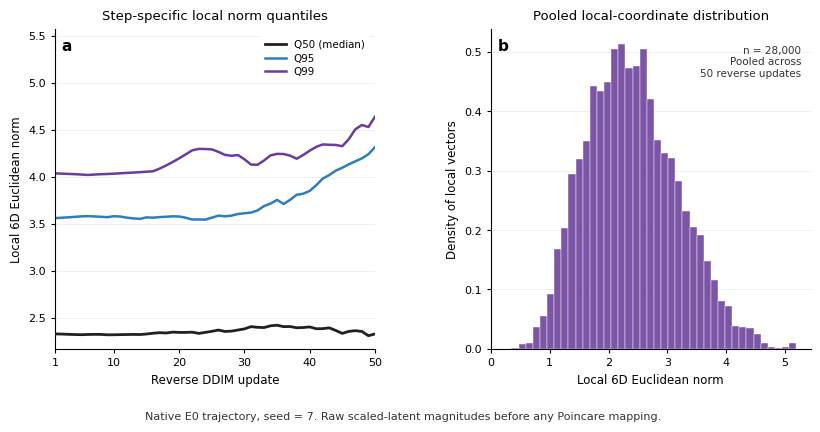

Local 6D coordinate calibration completed.
Local block dimension: 6
Local vectors per reverse step: 560
Total local vectors: 28000
Global local-norm median: 2.350100
Global local-norm p95: 3.759138
Global local-norm p99: 4.357213
Global local-norm maximum: 5.194576
Panel a uses step-specific quantiles; Panel b pools all reverse updates.
No Poincare mapping has been applied in this cell.
Figure PNG saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/extended_data_e0_local_6d_coordinate_calibration_seed_007.png
Figure PDF saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/extended_data_e0_local_6d_coordinate_calibration_seed_007.pdf
Source-data summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/local_coordinate_calibration/e0_local_6d_norm_summary_seed_007.csv


,seed,num_reverse_steps,local_block_dimension,local_vectors_per_reverse_step,total_local_vectors,global_norm_median,global_norm_p95,global_norm_p99,global_norm_max,poincare_mapping_applied,coordinate_scale_applied
0,7,50,6,560,28000,2.3501,3.759138,4.357213,5.194576,False,False


In [14]:
# Cell 14 — Manuscript local 6D Euclidean-coordinate calibration

from PIL import Image
import matplotlib as mpl

MANUSCRIPT_FIGURE_DIR = RESULTS / "manuscript" / "figures"
MANUSCRIPT_DATA_DIR = RESULTS / "manuscript" / "data"

LOCAL_COORDINATE_DIR = (
    MANUSCRIPT_DATA_DIR / "local_coordinate_calibration"
)

MANUSCRIPT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_COORDINATE_DIR.mkdir(parents=True, exist_ok=True)

required_symbols = [
    "CFG",
    "e0_seed",
    "e0_trace_df",
    "e0_trace_tensors",
]

missing_symbols = [
    name for name in required_symbols
    if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Run the native E0 trajectory cells before Cell 14.\n"
        "Missing notebook symbols:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
    )


latent_states = e0_trace_tensors["x_t_scaled"]

if latent_states.ndim != 5:
    raise ValueError(
        "Expected latent states with shape "
        "[steps, batch, channels, height, width]."
    )

if tuple(latent_states.shape[2:]) != tuple(CFG["latent_shape"]):
    raise ValueError(
        "Unexpected latent shape in the native E0 trace: "
        f"{tuple(latent_states.shape[2:])}"
    )

if latent_states.shape[0] != CFG["num_inference_steps"]:
    raise ValueError(
        "The number of recorded latent states does not match "
        "the configured DDIM schedule."
    )

if not bool(torch.isfinite(latent_states).all()):
    raise FloatingPointError(
        "Non-finite values were found in the native E0 latent trace."
    )


# [steps, batch, channels, height, width]
# -> [steps, batch, height, width, channels]
local_vectors = latent_states.permute(0, 1, 3, 4, 2).contiguous()

# Each spatial position is interpreted as one local 6D Euclidean latent vector.
local_norms = torch.linalg.vector_norm(local_vectors, dim=-1)

if not bool(torch.isfinite(local_norms).all()):
    raise FloatingPointError(
        "Non-finite local 6D latent norms were found."
    )

local_block_dimension = int(local_vectors.shape[-1])
n_reverse_steps = int(local_norms.shape[0])
n_local_vectors_per_step = int(np.prod(local_norms.shape[1:]))
n_local_vectors_total = int(local_norms.numel())

summary_rows = []

for reverse_step in range(n_reverse_steps):
    values = local_norms[reverse_step].reshape(-1).float()

    summary_rows.append(
        {
            "reverse_step": reverse_step,
            "display_step": reverse_step + 1,
            "timestep": int(
                e0_trace_df.iloc[reverse_step]["timestep"]
            ),
            "n_local_vectors": int(values.numel()),
            "norm_median": float(torch.quantile(values, 0.50)),
            "norm_p95": float(torch.quantile(values, 0.95)),
            "norm_p99": float(torch.quantile(values, 0.99)),
            "norm_max": float(values.max()),
        }
    )

local_norm_summary = pd.DataFrame(summary_rows)

all_local_norms = local_norms.reshape(-1).float()
all_local_norms_np = all_local_norms.detach().cpu().numpy()

global_norm_median = float(torch.quantile(all_local_norms, 0.50))
global_norm_p95 = float(torch.quantile(all_local_norms, 0.95))
global_norm_p99 = float(torch.quantile(all_local_norms, 0.99))
global_norm_max = float(all_local_norms.max())

local_coordinate_audit_df = pd.DataFrame(
    [
        {
            "seed": e0_seed,
            "num_reverse_steps": n_reverse_steps,
            "local_block_dimension": local_block_dimension,
            "local_vectors_per_reverse_step": n_local_vectors_per_step,
            "total_local_vectors": n_local_vectors_total,
            "global_norm_median": global_norm_median,
            "global_norm_p95": global_norm_p95,
            "global_norm_p99": global_norm_p99,
            "global_norm_max": global_norm_max,
            "poincare_mapping_applied": False,
            "coordinate_scale_applied": False,
        }
    ]
)

LOCAL_NORM_HISTOGRAM_BINS = 40

histogram_counts, histogram_edges = np.histogram(
    all_local_norms_np,
    bins=LOCAL_NORM_HISTOGRAM_BINS,
)

histogram_widths = np.diff(histogram_edges)

local_norm_histogram_df = pd.DataFrame(
    {
        "bin_left": histogram_edges[:-1],
        "bin_right": histogram_edges[1:],
        "bin_center": 0.5 * (
            histogram_edges[:-1] + histogram_edges[1:]
        ),
        "count": histogram_counts,
        "density": (
            histogram_counts
            / (histogram_counts.sum() * histogram_widths)
        ),
    }
)

local_norm_summary_path = (
    LOCAL_COORDINATE_DIR
    / f"e0_local_6d_norm_summary_seed_{e0_seed:03d}.csv"
)

local_norm_histogram_path = (
    LOCAL_COORDINATE_DIR
    / f"e0_local_6d_norm_histogram_seed_{e0_seed:03d}.csv"
)

local_coordinate_audit_path = (
    LOCAL_COORDINATE_DIR
    / f"e0_local_6d_coordinate_audit_seed_{e0_seed:03d}.csv"
)

local_coordinate_tensor_path = (
    LOCAL_COORDINATE_DIR
    / f"e0_local_6d_norms_seed_{e0_seed:03d}.pt"
)

local_coordinate_metadata_path = (
    LOCAL_COORDINATE_DIR
    / f"e0_local_6d_coordinate_metadata_seed_{e0_seed:03d}.json"
)

local_norm_summary.to_csv(local_norm_summary_path, index=False)
local_norm_histogram_df.to_csv(local_norm_histogram_path, index=False)
local_coordinate_audit_df.to_csv(local_coordinate_audit_path, index=False)

torch.save(
    {
        "seed": e0_seed,
        "local_vectors_shape": tuple(local_vectors.shape),
        "local_norms_shape": tuple(local_norms.shape),
        "local_norms": local_norms.detach().cpu(),
        "global_norm_median": global_norm_median,
        "global_norm_p95": global_norm_p95,
        "global_norm_p99": global_norm_p99,
        "global_norm_max": global_norm_max,
    },
    local_coordinate_tensor_path,
)

local_coordinate_metadata = {
    "analysis_name": "E0 local 6D Euclidean-coordinate calibration",
    "seed": int(e0_seed),
    "input_tensor": "e0_trace_tensors['x_t_scaled']",
    "input_shape": list(latent_states.shape),
    "local_vector_shape": list(local_vectors.shape),
    "local_block_dimension": local_block_dimension,
    "num_reverse_steps": n_reverse_steps,
    "local_vectors_per_reverse_step": n_local_vectors_per_step,
    "total_local_vectors": n_local_vectors_total,
    "norm_definition": "Euclidean L2 norm across the six latent channels",
    "panel_a_statistical_population": (
        "560 local vectors independently summarized at each reverse step"
    ),
    "panel_b_statistical_population": (
        "All 28000 local vectors pooled across the full 50-step trajectory"
    ),
    "panel_b_percentile_lines_plotted": False,
    "coordinate_scale_applied": False,
    "poincare_mapping_applied": False,
    "purpose": (
        "Pre-mapping scale calibration and numerical-range audit for "
        "subsequent local Poincare geometry."
    ),
}

with open(local_coordinate_metadata_path, "w") as file:
    json.dump(local_coordinate_metadata, file, indent=2)


figure_stem = (
    f"extended_data_e0_local_6d_coordinate_calibration_"
    f"seed_{e0_seed:03d}"
)

local_coordinate_png_path = (
    MANUSCRIPT_FIGURE_DIR / f"{figure_stem}.png"
)

local_coordinate_pdf_path = (
    MANUSCRIPT_FIGURE_DIR / f"{figure_stem}.pdf"
)

panel_colors = {
    "q50": "#202020",
    "q95": "#2C7FB8",
    "q99": "#6A3D9A",
    "histogram": "#6A3D9A",
}

quantile_lower = float(
    local_norm_summary["norm_median"].min()
)
quantile_upper = float(
    local_norm_summary["norm_p99"].max()
)
quantile_span = quantile_upper - quantile_lower

quantile_ymin = max(
    0.0,
    quantile_lower - 0.06 * quantile_span,
)
quantile_ymax = quantile_upper + 0.40 * quantile_span

with mpl.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 8.5,
        "axes.linewidth": 0.8,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    fig = plt.figure(figsize=(8.4, 4.7))

    grid = fig.add_gridspec(
        nrows=1,
        ncols=2,
        left=0.085,
        right=0.985,
        bottom=0.185,
        top=0.865,
        wspace=0.36,
    )

    ax_a = fig.add_subplot(grid[0, 0])
    ax_b = fig.add_subplot(grid[0, 1])

    for axis in [ax_a, ax_b]:
        axis.set_box_aspect(1.0)
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)
        axis.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=3.0,
            width=0.8,
            labelsize=8,
        )
        axis.grid(
            axis="y",
            color="#B0B0B0",
            alpha=0.20,
            linewidth=0.7,
            zorder=0,
        )

    # Panel a: step-specific quantiles.
    ax_a.plot(
        local_norm_summary["display_step"],
        local_norm_summary["norm_median"],
        color=panel_colors["q50"],
        linewidth=2.0,
        label="Q50 (median)",
        zorder=3,
    )
    ax_a.plot(
        local_norm_summary["display_step"],
        local_norm_summary["norm_p95"],
        color=panel_colors["q95"],
        linewidth=1.8,
        label="Q95",
        zorder=2,
    )
    ax_a.plot(
        local_norm_summary["display_step"],
        local_norm_summary["norm_p99"],
        color=panel_colors["q99"],
        linewidth=1.8,
        label="Q99",
        zorder=2,
    )

    ax_a.set_xlim(1, CFG["num_inference_steps"])
    ax_a.set_ylim(quantile_ymin, quantile_ymax)
    ax_a.set_xticks([1, 10, 20, 30, 40, 50])
    ax_a.set_xlabel("Reverse DDIM update")
    ax_a.set_ylabel("Local 6D Euclidean norm")
    ax_a.set_title(
        "Step-specific local norm quantiles",
        fontsize=9.5,
        pad=7,
    )
    ax_a.legend(
        loc="upper right",
        frameon=True,
        facecolor="white",
        edgecolor="none",
        framealpha=0.94,
        fontsize=7.4,
        handlelength=2.0,
        borderpad=0.45,
        labelspacing=0.35,
        borderaxespad=0.55,
    )
    ax_a.text(
        0.02,
        0.97,
        "a",
        transform=ax_a.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        fontweight="bold",
    )

    # Panel b: pooled distribution across all reverse steps.
    ax_b.hist(
        all_local_norms_np,
        bins=histogram_edges,
        density=True,
        color=panel_colors["histogram"],
        edgecolor="white",
        linewidth=0.35,
        alpha=0.88,
        zorder=2,
    )

    ax_b.set_xlim(left=0.0)
    ax_b.set_xlabel("Local 6D Euclidean norm")
    ax_b.set_ylabel("Density of local vectors")
    ax_b.set_title(
        "Pooled local-coordinate distribution",
        fontsize=9.5,
        pad=7,
    )
    ax_b.text(
        0.02,
        0.97,
        "b",
        transform=ax_b.transAxes,
        ha="left",
        va="top",
        fontsize=11,
        fontweight="bold",
    )
    ax_b.text(
        0.97,
        0.95,
        (
            f"n = {n_local_vectors_total:,}\n"
            "Pooled across\n"
            f"{n_reverse_steps} reverse updates"
        ),
        transform=ax_b.transAxes,
        ha="right",
        va="top",
        fontsize=7.5,
        color="#333333",
    )

    fig.text(
        0.5,
        0.040,
        (
            "Native E0 trajectory, seed = "
            f"{e0_seed}. Raw scaled-latent magnitudes before any "
            "Poincare mapping."
        ),
        ha="center",
        va="center",
        fontsize=8,
        color="#333333",
    )

    fig.savefig(
        local_coordinate_png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
    )

    fig.savefig(
        local_coordinate_pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

with Image.open(local_coordinate_png_path) as image:
    image_dpi = image.info.get("dpi", (600, 600))
    image.convert("RGB").save(
        local_coordinate_png_path,
        dpi=image_dpi,
    )

print("Local 6D coordinate calibration completed.")
print("Local block dimension:", local_block_dimension)
print("Local vectors per reverse step:", n_local_vectors_per_step)
print("Total local vectors:", n_local_vectors_total)
print("Global local-norm median:", f"{global_norm_median:.6f}")
print("Global local-norm p95:", f"{global_norm_p95:.6f}")
print("Global local-norm p99:", f"{global_norm_p99:.6f}")
print("Global local-norm maximum:", f"{global_norm_max:.6f}")
print(
    "Panel a uses step-specific quantiles; "
    "Panel b pools all reverse updates."
)
print("No Poincare mapping has been applied in this cell.")
print("Figure PNG saved to:", local_coordinate_png_path)
print("Figure PDF saved to:", local_coordinate_pdf_path)
print("Source-data summary saved to:", local_norm_summary_path)

display(local_coordinate_audit_df)

In [15]:
# Cell 15 — Import and validate hyperbolic geometry

import importlib
import geometry

importlib.reload(geometry)

geometry.run_geometry_sanity_checks()

print("Hyperbolic geometry module imported successfully.")

Poincare exp/log round-trip: passed
Zero-drift identity: passed
Small-curvature Euclidean limit: passed
Maximum Poincare-ball norm: 0.2571424697277736
Hyperbolic geometry module imported successfully.


In [16]:
# Cell 16 — Manuscript hyperbolic zero-drift identity control

HYPERBOLIC_ZERO_DRIFT_DIR = (
    MANUSCRIPT_DATA_DIR
    / "verification"
    / "hyperbolic_zero_drift_identity"
)

HYPERBOLIC_ZERO_DRIFT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

required_symbols = [
    "CFG",
    "e0_seed",
    "e0_initial_noise",
    "e0_native_final_scaled_latent",
    "e0_norm_log_q_maps",
    "e0_zero_drift_final_scaled_latent",
    "e0_zero_drift_norm_log_q_maps",
    "e0_trace_df",
    "autoencoder",
    "unet",
    "ddim_scheduler",
    "scale_factor",
    "geometry",
    "strict_comparison_row",
    "ddim_sample_with_transition_modifier",
]

missing_symbols = [
    name for name in required_symbols
    if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Run Cells 1–15 before Cell 16.\n"
        "Missing notebook symbols:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
    )


H_ZERO_CURVATURE = 1.0
H_ZERO_COORDINATE_SCALE = 0.2
H_ZERO_DELTA = 0.0

h_zero_drift_modifier = geometry.make_hyperbolic_scalar_drift(
    delta=H_ZERO_DELTA,
    curvature=H_ZERO_CURVATURE,
    coordinate_scale=H_ZERO_COORDINATE_SCALE,
)

(
    h_zero_norm_log_q_maps,
    h_zero_final_scaled_latent,
    h_zero_trace_df,
) = ddim_sample_with_transition_modifier(
    input_noise=e0_initial_noise,
    diffusion_model=unet,
    scheduler=ddim_scheduler,
    autoencoder_model=autoencoder,
    latent_scale_factor=scale_factor,
    transition_modifier=h_zero_drift_modifier,
)

torch.testing.assert_close(
    h_zero_final_scaled_latent,
    e0_native_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    h_zero_final_scaled_latent,
    e0_zero_drift_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    h_zero_norm_log_q_maps,
    e0_norm_log_q_maps,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    h_zero_norm_log_q_maps,
    e0_zero_drift_norm_log_q_maps,
    rtol=0.0,
    atol=0.0,
)

assert len(h_zero_trace_df) == CFG["num_inference_steps"]

assert bool(
    (h_zero_trace_df["modifier_update_l2"] == 0.0).all()
)

assert bool(
    (h_zero_trace_df["modifier_update_rms"] == 0.0).all()
)

assert bool(
    (
        h_zero_trace_df["modifier_to_base_update_ratio"]
        == 0.0
    ).all()
)

native_update_l2 = e0_trace_df["update_l2"].to_numpy(
    dtype=float,
)

h_zero_base_update_l2 = h_zero_trace_df[
    "base_update_l2"
].to_numpy(
    dtype=float,
)

native_post_step_l2 = e0_trace_df["z_after_l2"].to_numpy(
    dtype=float,
)

h_zero_post_step_l2 = h_zero_trace_df[
    "latent_l2"
].to_numpy(
    dtype=float,
)

native_post_step_rms = e0_trace_df["z_after_rms"].to_numpy(
    dtype=float,
)

h_zero_post_step_rms = h_zero_trace_df[
    "latent_rms"
].to_numpy(
    dtype=float,
)

assert np.array_equal(
    native_update_l2,
    h_zero_base_update_l2,
)

assert np.array_equal(
    native_post_step_l2,
    h_zero_post_step_l2,
)

assert np.array_equal(
    native_post_step_rms,
    h_zero_post_step_rms,
)

h_zero_summary_df = pd.DataFrame(
    [
        strict_comparison_row(
            "Hyperbolic zero-drift final latent vs native MONAI final latent",
            h_zero_final_scaled_latent,
            e0_native_final_scaled_latent,
        ),
        strict_comparison_row(
            "Hyperbolic zero-drift final latent vs Euclidean zero-drift latent",
            h_zero_final_scaled_latent,
            e0_zero_drift_final_scaled_latent,
        ),
        strict_comparison_row(
            "Hyperbolic zero-drift q-maps vs native full-generation output",
            h_zero_norm_log_q_maps,
            e0_norm_log_q_maps,
        ),
        strict_comparison_row(
            "Hyperbolic zero-drift q-maps vs Euclidean zero-drift q-maps",
            h_zero_norm_log_q_maps,
            e0_zero_drift_norm_log_q_maps,
        ),
        strict_comparison_row(
            "Native DDIM update L2 vs hyperbolic zero-drift base-update L2",
            native_update_l2,
            h_zero_base_update_l2,
        ),
        strict_comparison_row(
            "Native post-step latent RMS vs hyperbolic zero-drift latent RMS",
            native_post_step_rms,
            h_zero_post_step_rms,
        ),
    ]
)

assert bool(h_zero_summary_df["exact_array_equality"].all())

assert bool(
    (
        h_zero_summary_df["maximum_absolute_difference"]
        == 0.0
    ).all()
)

h_zero_modifier_qc_df = pd.DataFrame(
    [
        {
            "seed": e0_seed,
            "num_reverse_steps": len(h_zero_trace_df),
            "curvature": H_ZERO_CURVATURE,
            "coordinate_scale": H_ZERO_COORDINATE_SCALE,
            "applied_delta": H_ZERO_DELTA,
            "maximum_modifier_update_l2": float(
                h_zero_trace_df["modifier_update_l2"].max()
            ),
            "maximum_modifier_update_rms": float(
                h_zero_trace_df["modifier_update_rms"].max()
            ),
            "all_modifier_updates_exactly_zero": bool(
                (
                    h_zero_trace_df["modifier_update_l2"]
                    == 0.0
                ).all()
            ),
            "poincare_operations_evaluated": False,
        }
    ]
)

h_zero_trace_path = (
    HYPERBOLIC_ZERO_DRIFT_DIR
    / f"hyperbolic_zero_drift_trace_seed_{e0_seed:03d}.csv"
)

h_zero_summary_path = (
    HYPERBOLIC_ZERO_DRIFT_DIR
    / f"hyperbolic_zero_drift_summary_seed_{e0_seed:03d}.csv"
)

h_zero_qc_path = (
    HYPERBOLIC_ZERO_DRIFT_DIR
    / f"hyperbolic_zero_drift_qc_seed_{e0_seed:03d}.csv"
)

h_zero_tensor_path = (
    HYPERBOLIC_ZERO_DRIFT_DIR
    / f"hyperbolic_zero_drift_tensors_seed_{e0_seed:03d}.pt"
)

h_zero_metadata_path = (
    HYPERBOLIC_ZERO_DRIFT_DIR
    / f"hyperbolic_zero_drift_metadata_seed_{e0_seed:03d}.json"
)

h_zero_trace_df.to_csv(h_zero_trace_path, index=False)
h_zero_summary_df.to_csv(h_zero_summary_path, index=False)
h_zero_modifier_qc_df.to_csv(h_zero_qc_path, index=False)

torch.save(
    {
        "seed": e0_seed,
        "curvature": H_ZERO_CURVATURE,
        "coordinate_scale": H_ZERO_COORDINATE_SCALE,
        "applied_delta": H_ZERO_DELTA,
        "initial_noise": e0_initial_noise.detach().cpu(),
        "final_scaled_latent": (
            h_zero_final_scaled_latent.detach().cpu()
        ),
        "norm_log_q_maps": h_zero_norm_log_q_maps.detach().cpu(),
    },
    h_zero_tensor_path,
)

h_zero_metadata = {
    "control_name": "Hyperbolic zero-drift identity control",
    "seed": int(e0_seed),
    "num_reverse_steps": int(len(h_zero_trace_df)),
    "curvature": float(H_ZERO_CURVATURE),
    "coordinate_scale": float(H_ZERO_COORDINATE_SCALE),
    "applied_delta": float(H_ZERO_DELTA),
    "intervention_location": (
        "after native DDIM scheduler.step and before the next U-Net call"
    ),
    "zero_drift_behavior": (
        "The hyperbolic modifier returns base_x_prev exactly when delta is zero."
    ),
    "poincare_operations_evaluated": False,
    "all_modifier_updates_exactly_zero": bool(
        (
            h_zero_trace_df["modifier_update_l2"]
            == 0.0
        ).all()
    ),
    "all_identity_comparisons_exact": bool(
        h_zero_summary_df["exact_array_equality"].all()
    ),
}

with open(h_zero_metadata_path, "w") as file:
    json.dump(h_zero_metadata, file, indent=2)

print("Hyperbolic zero-drift identity control passed.")
print(
    "All final-latent, decoded-output, and stepwise-transition "
    "comparisons are exactly equal."
)
print("All modifier updates are exactly zero.")
print(
    "No Poincare exp/log, Mobius addition, or parallel transport "
    "is evaluated when delta is zero."
)
print("Identity summary saved to:", h_zero_summary_path)
print("Transition trace saved to:", h_zero_trace_path)
print("Control metadata saved to:", h_zero_metadata_path)

display(h_zero_summary_df)
display(h_zero_modifier_qc_df)

Hyperbolic zero-drift identity control passed.
All final-latent, decoded-output, and stepwise-transition comparisons are exactly equal.
All modifier updates are exactly zero.
No Poincare exp/log, Mobius addition, or parallel transport is evaluated when delta is zero.
Identity summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/hyperbolic_zero_drift_identity/hyperbolic_zero_drift_summary_seed_007.csv
Transition trace saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/hyperbolic_zero_drift_identity/hyperbolic_zero_drift_trace_seed_007.csv
Control metadata saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/verification/hyperbolic_zero_drift_identity/hyperbolic_zero_drift_metadata_seed_007.json


,comparison,shape,maximum_absolute_difference,mean_absolute_difference,root_mean_squared_difference,exact_array_equality
0,Hyperbolic zero-drift final latent vs native M...,"(1, 6, 20, 28)",0.0,0.0,0.0,True
1,Hyperbolic zero-drift final latent vs Euclidea...,"(1, 6, 20, 28)",0.0,0.0,0.0,True
2,Hyperbolic zero-drift q-maps vs native full-ge...,"(1, 3, 160, 224)",0.0,0.0,0.0,True
3,Hyperbolic zero-drift q-maps vs Euclidean zero...,"(1, 3, 160, 224)",0.0,0.0,0.0,True
4,Native DDIM update L2 vs hyperbolic zero-drift...,"(50,)",0.0,0.0,0.0,True
5,Native post-step latent RMS vs hyperbolic zero...,"(50,)",0.0,0.0,0.0,True


,seed,num_reverse_steps,curvature,coordinate_scale,applied_delta,maximum_modifier_update_l2,maximum_modifier_update_rms,all_modifier_updates_exactly_zero,poincare_operations_evaluated
0,7,50,1.0,0.2,0.0,0.0,0.0,True,False


In [17]:
# Cell 17 — Non-zero equal-coordinate Euclidean–hyperbolic drift pilot

PILOT_DELTA = 0.00050
PILOT_CURVATURE = 1.0
PILOT_COORDINATE_SCALE = 0.2
PILOT_MATCHING_MODE = "equal_coordinate_delta"

PILOT_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "nonzero_drift_pilot"
)
PILOT_DATA_DIR.mkdir(parents=True, exist_ok=True)

required_symbols = [
    "e0_initial_noise",
    "e0_native_final_scaled_latent",
    "e0_norm_log_q_maps",
    "ddim_sample_with_transition_modifier",
    "make_scalar_latent_drift",
    "scalar_drift_expected_l2",
    "geometry",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing required notebook objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
    )


@torch.no_grad()
def create_physical_outputs(norm_log_q_maps):
    log_q_maps = denormalize_log_q_map(
        norm_log_q_map=norm_log_q_maps,
        log_pd_mean=log_pd_prior_mean,
        log_t1_mean=log_t1_prior_mean,
        log_t2_mean=log_t2_prior_mean,
    )

    q_maps = torch.exp(log_q_maps)[0]

    mri_images = {
        "T1w MPRAGE": render_mprage(
            q_maps,
            te=0.003,
            tr=2.4,
            ti=1.0,
        ),
        "T2w Spin Echo": render_spin_echo(
            q_maps,
            te=0.45,
            tr=3.2,
        ),
        "FLAIR": render_flair(
            q_maps,
            te=0.091,
            tr=9.0,
            ti=2.5,
        ),
    }

    return log_q_maps, q_maps, mri_images


pilot_methods = [
    {
        "name": "E0",
        "label": "E0\nNo drift",
        "modifier": None,
    },
    {
        "name": "Euclidean drift",
        "label": (
            "Euclidean drift\n"
            f"Equal coordinate delta = {PILOT_DELTA:.5f}"
        ),
        "modifier": make_scalar_latent_drift(
            delta=PILOT_DELTA,
        ),
    },
    {
        "name": "Hyperbolic drift",
        "label": (
            "Hyperbolic drift\n"
            f"Equal coordinate delta = {PILOT_DELTA:.5f}, "
            f"c = {PILOT_CURVATURE:g}"
        ),
        "modifier": geometry.make_hyperbolic_scalar_drift(
            delta=PILOT_DELTA,
            curvature=PILOT_CURVATURE,
            coordinate_scale=PILOT_COORDINATE_SCALE,
        ),
    },
]

pilot_results = {}

for method in pilot_methods:
    print(f"Running pilot condition: {method['name']}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    (
        norm_log_q_maps,
        final_scaled_latent,
        transition_trace_df,
    ) = ddim_sample_with_transition_modifier(
        input_noise=e0_initial_noise,
        diffusion_model=unet,
        scheduler=ddim_scheduler,
        autoencoder_model=autoencoder,
        latent_scale_factor=scale_factor,
        transition_modifier=method["modifier"],
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_seconds = time.perf_counter() - start_time

    if not bool(torch.isfinite(final_scaled_latent).all()):
        raise FloatingPointError(
            f"Non-finite final latent for {method['name']}."
        )

    if not bool(torch.isfinite(norm_log_q_maps).all()):
        raise FloatingPointError(
            f"Non-finite decoded q-maps for {method['name']}."
        )

    log_q_maps, q_maps, mri_images = create_physical_outputs(
        norm_log_q_maps,
    )

    pilot_results[method["name"]] = {
        "label": method["label"],
        "norm_log_q_maps": norm_log_q_maps,
        "final_scaled_latent": final_scaled_latent,
        "log_q_maps": log_q_maps,
        "q_maps": q_maps,
        "mri_images": mri_images,
        "trace": transition_trace_df,
        "sampling_time_seconds": elapsed_seconds,
    }

e0_pilot_result = pilot_results["E0"]

# Exact E0 identity check.
torch.testing.assert_close(
    e0_pilot_result["final_scaled_latent"],
    e0_native_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    e0_pilot_result["norm_log_q_maps"],
    e0_norm_log_q_maps,
    rtol=0.0,
    atol=0.0,
)

assert bool(
    (e0_pilot_result["trace"]["modifier_update_l2"] == 0.0).all()
)

# Euclidean constant-drift check.
euclidean_modifier_l2_values = pilot_results[
    "Euclidean drift"
]["trace"]["modifier_update_l2"].to_numpy(dtype=float)

expected_euclidean_modifier_l2 = float(
    scalar_drift_expected_l2(
        PILOT_DELTA,
        e0_initial_noise,
    )
)

euclidean_modifier_l2_abs_errors = np.abs(
    euclidean_modifier_l2_values
    - expected_euclidean_modifier_l2
)

euclidean_modifier_l2_max_abs_error = float(
    euclidean_modifier_l2_abs_errors.max()
)

euclidean_modifier_l2_max_relative_error = float(
    euclidean_modifier_l2_max_abs_error
    / max(abs(expected_euclidean_modifier_l2), 1e-12)
)

# The modifier is computed as (base_x_prev + delta) - base_x_prev.
# FP32 addition/subtraction produces sub-micro L2 rounding differences.
np.testing.assert_allclose(
    euclidean_modifier_l2_values,
    expected_euclidean_modifier_l2,
    rtol=2e-5,
    atol=5e-7,
)

hyperbolic_modifier_l2_values = pilot_results[
    "Hyperbolic drift"
]["trace"]["modifier_update_l2"].to_numpy(dtype=float)

assert bool(np.isfinite(hyperbolic_modifier_l2_values).all())
assert bool((hyperbolic_modifier_l2_values > 0.0).all())

hyperbolic_euclidean_latent_l2 = float(
    l2_norm(
        pilot_results["Hyperbolic drift"]["final_scaled_latent"]
        - pilot_results["Euclidean drift"]["final_scaled_latent"]
    )
    .detach()
    .cpu()
)

assert hyperbolic_euclidean_latent_l2 > 0.0

summary_rows = []

for method_name, result in pilot_results.items():
    trace = result["trace"]

    summary_rows.append(
        {
            "method": method_name,
            "sampling_time_seconds": float(
                result["sampling_time_seconds"]
            ),
            "mean_modifier_update_l2": float(
                trace["modifier_update_l2"].mean()
            ),
            "max_modifier_update_l2": float(
                trace["modifier_update_l2"].max()
            ),
            "final_latent_l2_difference_vs_E0": float(
                l2_norm(
                    result["final_scaled_latent"]
                    - e0_pilot_result["final_scaled_latent"]
                )
                .detach()
                .cpu()
            ),
            "normalized_q_map_mae_vs_E0": float(
                torch.mean(
                    torch.abs(
                        result["norm_log_q_maps"]
                        - e0_pilot_result["norm_log_q_maps"]
                    )
                )
                .detach()
                .cpu()
            ),
            "T1w_raw_mae_vs_E0": float(
                torch.mean(
                    torch.abs(
                        result["mri_images"]["T1w MPRAGE"]
                        - e0_pilot_result["mri_images"][
                            "T1w MPRAGE"
                        ]
                    )
                )
                .detach()
                .cpu()
            ),
        }
    )

pilot_summary_df = pd.DataFrame(summary_rows)

pilot_control_df = pd.DataFrame(
    [
        {
            "control": "E0 identity",
            "maximum_latent_absolute_difference": float(
                torch.max(
                    torch.abs(
                        e0_pilot_result["final_scaled_latent"]
                        - e0_native_final_scaled_latent
                    )
                )
                .detach()
                .cpu()
            ),
            "maximum_qmap_absolute_difference": float(
                torch.max(
                    torch.abs(
                        e0_pilot_result["norm_log_q_maps"]
                        - e0_norm_log_q_maps
                    )
                )
                .detach()
                .cpu()
            ),
            "maximum_modifier_update_l2": float(
                e0_pilot_result["trace"][
                    "modifier_update_l2"
                ].max()
            ),
        },
        {
            "control": "Euclidean scalar-drift magnitude",
            "expected_modifier_update_l2": (
                expected_euclidean_modifier_l2
            ),
            "maximum_modifier_l2_absolute_error": (
                euclidean_modifier_l2_max_abs_error
            ),
            "maximum_modifier_l2_relative_error": (
                euclidean_modifier_l2_max_relative_error
            ),
            "maximum_modifier_update_l2": float(
                euclidean_modifier_l2_values.max()
            ),
        },
        {
            "control": "Hyperbolic non-zero intervention",
            "mean_modifier_update_l2": float(
                hyperbolic_modifier_l2_values.mean()
            ),
            "maximum_modifier_update_l2": float(
                hyperbolic_modifier_l2_values.max()
            ),
            "final_latent_l2_vs_Euclidean": (
                hyperbolic_euclidean_latent_l2
            ),
        },
    ]
)

pilot_summary_path = (
    PILOT_DATA_DIR
    / f"equal_coordinate_pilot_summary_seed_{e0_seed:03d}.csv"
)

pilot_control_path = (
    PILOT_DATA_DIR
    / f"equal_coordinate_pilot_controls_seed_{e0_seed:03d}.csv"
)

pilot_summary_df.to_csv(pilot_summary_path, index=False)
pilot_control_df.to_csv(pilot_control_path, index=False)

for method_name, result in pilot_results.items():
    safe_method_name = (
        method_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    result["trace"].to_csv(
        PILOT_DATA_DIR
        / f"equal_coordinate_pilot_{safe_method_name}_"
          f"trace_seed_{e0_seed:03d}.csv",
        index=False,
    )

pilot_tensor_path = (
    PILOT_DATA_DIR
    / f"equal_coordinate_pilot_outputs_seed_{e0_seed:03d}.pt"
)

torch.save(
    {
        "seed": e0_seed,
        "delta": PILOT_DELTA,
        "curvature": PILOT_CURVATURE,
        "coordinate_scale": PILOT_COORDINATE_SCALE,
        "matching_mode": PILOT_MATCHING_MODE,
        "results": {
            method_name: {
                "final_scaled_latent": result[
                    "final_scaled_latent"
                ].detach().cpu(),
                "norm_log_q_maps": result[
                    "norm_log_q_maps"
                ].detach().cpu(),
                "q_maps": result["q_maps"].detach().cpu(),
                "mri_images": {
                    image_name: image.detach().cpu()
                    for image_name, image in result[
                        "mri_images"
                    ].items()
                },
            }
            for method_name, result in pilot_results.items()
        },
    },
    pilot_tensor_path,
)

pilot_metadata_path = (
    PILOT_DATA_DIR
    / f"equal_coordinate_pilot_metadata_seed_{e0_seed:03d}.json"
)

with open(pilot_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(e0_seed),
            "num_reverse_steps": int(
                CFG["num_inference_steps"]
            ),
            "euclidean_delta": float(PILOT_DELTA),
            "hyperbolic_delta": float(PILOT_DELTA),
            "curvature": float(PILOT_CURVATURE),
            "coordinate_scale": float(
                PILOT_COORDINATE_SCALE
            ),
            "matching_mode": PILOT_MATCHING_MODE,
            "modifier_dose_matched": False,
            "terminal_displacement_matched": False,
            "interpretation": (
                "This is a non-zero implementation pilot with "
                "equal coordinate deltas. It is not the fair "
                "endpoint-matched Euclidean-versus-hyperbolic "
                "comparison."
            ),
            "expected_euclidean_modifier_l2": (
                expected_euclidean_modifier_l2
            ),
            "euclidean_modifier_l2_max_abs_error": (
                euclidean_modifier_l2_max_abs_error
            ),
            "euclidean_modifier_l2_max_relative_error": (
                euclidean_modifier_l2_max_relative_error
            ),
        },
        file,
        indent=2,
    )

print("Non-zero Euclidean and hyperbolic drift pilot completed.")
print(
    "Pilot comparison mode:",
    "equal coordinate delta only; not dose- or endpoint-matched.",
)
print(
    "Expected Euclidean modifier L2 per step:",
    f"{expected_euclidean_modifier_l2:.9f}",
)
print(
    "Maximum FP32 Euclidean L2 rounding difference:",
    f"{euclidean_modifier_l2_max_abs_error:.3e}",
)
print(
    "Maximum relative FP32 Euclidean L2 rounding difference:",
    f"{100.0 * euclidean_modifier_l2_max_relative_error:.5f}%",
)
print("Pilot summary saved to:", pilot_summary_path)
print("Pilot controls saved to:", pilot_control_path)
print("Pilot tensors saved to:", pilot_tensor_path)
print("Pilot metadata saved to:", pilot_metadata_path)

display(pilot_summary_df)
display(pilot_control_df)

Running pilot condition: E0
Running pilot condition: Euclidean drift
Running pilot condition: Hyperbolic drift
Non-zero Euclidean and hyperbolic drift pilot completed.
Pilot comparison mode: equal coordinate delta only; not dose- or endpoint-matched.
Expected Euclidean modifier L2 per step: 0.028982753
Maximum FP32 Euclidean L2 rounding difference: 4.215e-07
Maximum relative FP32 Euclidean L2 rounding difference: 0.00145%
Pilot summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/nonzero_drift_pilot/equal_coordinate_pilot_summary_seed_007.csv
Pilot controls saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/nonzero_drift_pilot/equal_coordinate_pilot_controls_seed_007.csv
Pilot tensors saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/nonzero_drift_pilot/equal_coordinate_pilot_outputs_seed_007.pt
Pilot metadata saved to: /mnt/g/Research/TUM_Multimodal/phy-

,method,sampling_time_seconds,mean_modifier_update_l2,max_modifier_update_l2,final_latent_l2_difference_vs_E0,normalized_q_map_mae_vs_E0,T1w_raw_mae_vs_E0
0,E0,1.580046,0.000000,0.000000,0.000000,0.000000,0.000000
1,Euclidean drift,1.475797,0.028982,0.028982,3.470928,0.043903,5.016372
2,Hyperbolic drift,1.563876,0.026335,0.027710,2.940316,0.035784,4.013334


,control,maximum_latent_absolute_difference,maximum_qmap_absolute_difference,maximum_modifier_update_l2,expected_modifier_update_l2,maximum_modifier_l2_absolute_error,maximum_modifier_l2_relative_error,mean_modifier_update_l2,final_latent_l2_vs_Euclidean
0,E0 identity,0.0,0.0,0.000000,NaN,NaN,NaN,NaN,NaN
1,Euclidean scalar-drift magnitude,NaN,NaN,0.028982,0.028983,4.215161e-07,0.000015,NaN,NaN
2,Hyperbolic non-zero intervention,NaN,NaN,0.027710,NaN,NaN,NaN,0.026335,0.562569


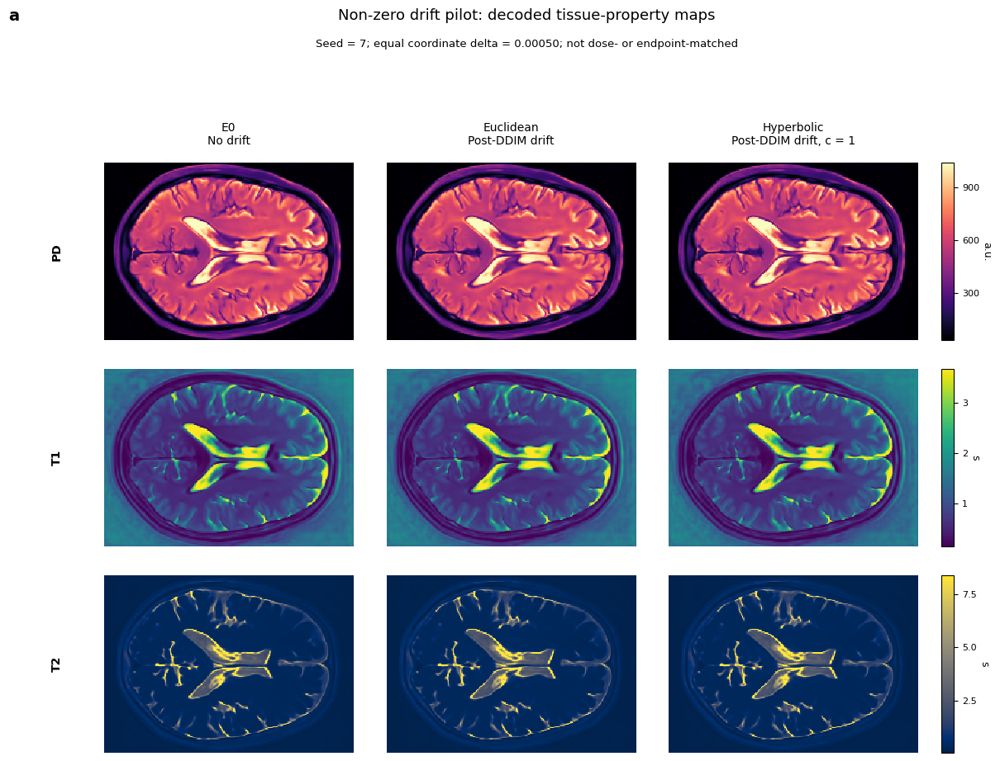

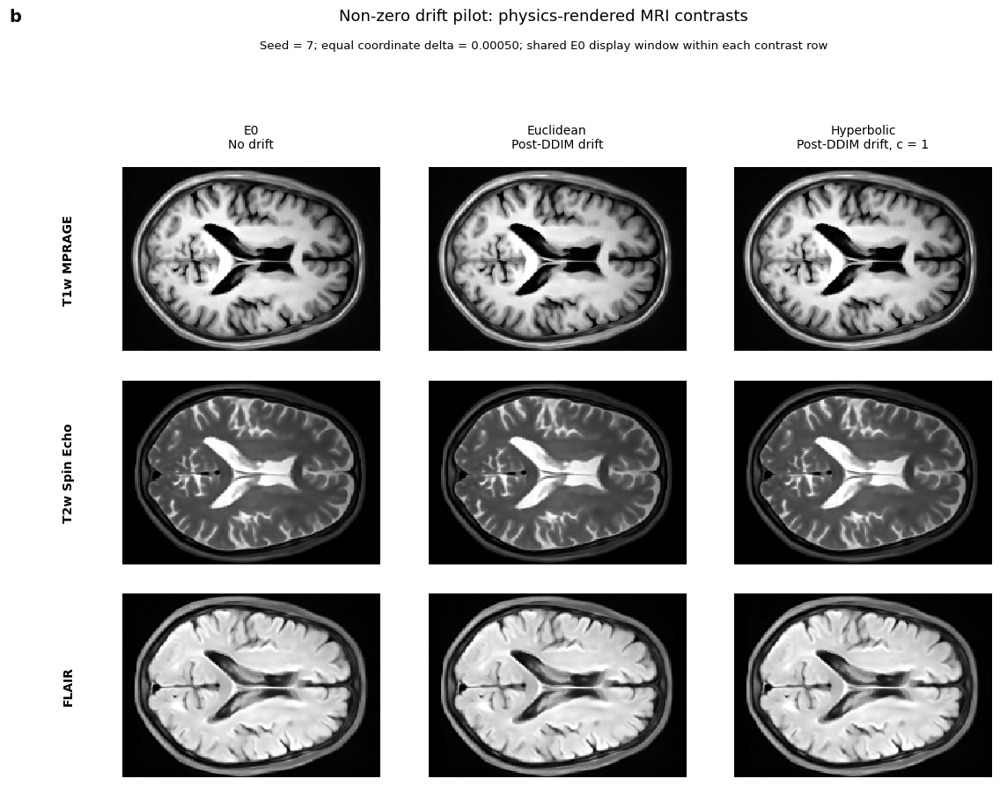

Pilot q-map figure saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/nonzero_drift_pilot/pilot_qmaps_panel_a_seed_007.png
Pilot q-map PDF saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/nonzero_drift_pilot/pilot_qmaps_panel_a_seed_007.pdf
Pilot MRI figure saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/nonzero_drift_pilot/pilot_mri_panel_b_seed_007.png
Pilot MRI PDF saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/nonzero_drift_pilot/pilot_mri_panel_b_seed_007.pdf
Shared display windows saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/nonzero_drift_pilot/pilot_display_windows_seed_007.json
Figure manifest saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/nonzero_drift_pilot/pilot_figure_manifest_seed_007.json
Displ

In [18]:
# Cell 18 — Manuscript visualisation of the non-zero drift pilot

from matplotlib.ticker import MaxNLocator
from PIL import Image as PILImage
import matplotlib as mpl

PILOT_FIGURE_DIR = (
    RESULTS
    / "manuscript"
    / "figures"
    / "nonzero_drift_pilot"
)
PILOT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

PILOT_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "nonzero_drift_pilot"
)
PILOT_DATA_DIR.mkdir(parents=True, exist_ok=True)

pilot_method_order = [
    "E0",
    "Euclidean drift",
    "Hyperbolic drift",
]

missing_pilot_methods = [
    method_name
    for method_name in pilot_method_order
    if method_name not in pilot_results
]

if missing_pilot_methods:
    raise KeyError(
        "Missing pilot results:\n"
        + "\n".join(
            f"  - {method_name}"
            for method_name in missing_pilot_methods
        )
    )

pilot_column_titles = {
    "E0": "E0\nNo drift",
    "Euclidean drift": "Euclidean\nPost-DDIM drift",
    "Hyperbolic drift": (
        "Hyperbolic\n"
        f"Post-DDIM drift, c = {PILOT_CURVATURE:g}"
    ),
}

qmap_panel_specs = [
    {
        "window_key": "PD",
        "row_label": "PD",
        "unit": "a.u.",
        "source_name": "q_maps",
        "source_index": 0,
        "cmap": "magma",
    },
    {
        "window_key": "T1",
        "row_label": "T1",
        "unit": "s",
        "source_name": "q_maps",
        "source_index": 1,
        "cmap": "viridis",
    },
    {
        "window_key": "T2",
        "row_label": "T2",
        "unit": "s",
        "source_name": "q_maps",
        "source_index": 2,
        "cmap": "cividis",
    },
]

mri_panel_specs = [
    {
        "window_key": "T1w MPRAGE",
        "row_label": "T1w MPRAGE",
        "source_name": "mri_images",
        "source_index": "T1w MPRAGE",
        "cmap": "gray",
    },
    {
        "window_key": "T2w Spin Echo",
        "row_label": "T2w Spin Echo",
        "source_name": "mri_images",
        "source_index": "T2w Spin Echo",
        "cmap": "gray",
    },
    {
        "window_key": "FLAIR",
        "row_label": "FLAIR",
        "source_name": "mri_images",
        "source_index": "FLAIR",
        "cmap": "gray",
    },
]


def pilot_image_to_numpy(
    result,
    source_name,
    source_index,
):
    if source_name == "q_maps":
        tensor = result["q_maps"][source_index]
    elif source_name == "mri_images":
        tensor = result["mri_images"][source_index]
    else:
        raise ValueError(
            f"Unsupported source name: {source_name}"
        )

    image = tensor.detach().float().cpu().squeeze().numpy()

    if image.ndim != 2:
        raise ValueError(
            "Expected a 2D image after squeeze, "
            f"but received shape {image.shape}."
        )

    if not np.isfinite(image).all():
        raise FloatingPointError(
            "Non-finite values were found in a pilot image."
        )

    return image


def finite_percentile_window(
    image,
    low_percentile=1.0,
    high_percentile=99.0,
):
    values = image[np.isfinite(image)]

    if values.size == 0:
        raise FloatingPointError(
            "No finite values were available for display-window estimation."
        )

    lower, upper = np.percentile(
        values,
        [low_percentile, high_percentile],
    )

    if upper <= lower:
        upper = lower + 1e-6

    return float(lower), float(upper)


def save_manuscript_figure(
    figure,
    png_path,
    pdf_path,
):
    figure.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
    )

    figure.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    with PILImage.open(png_path) as png_image:
        png_image.convert("RGB").save(png_path)


# Reuse Cell 8 E0 windows whenever they are available.
pilot_display_windows = {}

all_window_keys = [
    spec["window_key"]
    for spec in qmap_panel_specs + mri_panel_specs
]

if (
    "e0_display_windows" in globals()
    and all(
        window_key in e0_display_windows
        for window_key in all_window_keys
    )
):
    for window_key in all_window_keys:
        lower, upper = e0_display_windows[window_key]

        pilot_display_windows[window_key] = (
            float(lower),
            float(upper),
        )

    pilot_window_source = (
        "Cell 8 native E0 display windows"
    )
else:
    e0_pilot_result = pilot_results["E0"]

    for spec in qmap_panel_specs + mri_panel_specs:
        reference_image = pilot_image_to_numpy(
            e0_pilot_result,
            spec["source_name"],
            spec["source_index"],
        )

        pilot_display_windows[spec["window_key"]] = (
            finite_percentile_window(reference_image)
        )

    pilot_window_source = (
        "E0 pilot 1st–99th percentile windows"
    )


with mpl.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titleweight": "regular",
        "axes.labelweight": "regular",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    # ---------------------------------------------------------------
    # Figure A: decoded tissue-property maps
    # ---------------------------------------------------------------
    qmap_fig = plt.figure(figsize=(12.6, 10.0))

    qmap_grid = qmap_fig.add_gridspec(
        nrows=3,
        ncols=4,
        left=0.105,
        right=0.930,
        bottom=0.070,
        top=0.785,
        wspace=0.070,
        hspace=0.160,
        width_ratios=[1.0, 1.0, 1.0, 0.045],
    )

    qmap_axes = np.empty((3, 3), dtype=object)

    for row_index in range(3):
        for column_index in range(3):
            qmap_axes[row_index, column_index] = (
                qmap_fig.add_subplot(
                    qmap_grid[row_index, column_index]
                )
            )

    for column_index, method_name in enumerate(
        pilot_method_order
    ):
        qmap_axes[0, column_index].set_title(
            pilot_column_titles[method_name],
            fontsize=10,
            pad=16,
        )

    for row_index, spec in enumerate(qmap_panel_specs):
        vmin, vmax = pilot_display_windows[
            spec["window_key"]
        ]

        image_handle = None

        for column_index, method_name in enumerate(
            pilot_method_order
        ):
            image = pilot_image_to_numpy(
                pilot_results[method_name],
                spec["source_name"],
                spec["source_index"],
            )

            axis = qmap_axes[row_index, column_index]

            image_handle = axis.imshow(
                image,
                cmap=spec["cmap"],
                vmin=vmin,
                vmax=vmax,
                interpolation="nearest",
            )

            axis.set_box_aspect(
                image.shape[0] / image.shape[1]
            )
            axis.axis("off")

        qmap_axes[row_index, 0].text(
            -0.19,
            0.50,
            spec["row_label"],
            transform=qmap_axes[row_index, 0].transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
        )

        colorbar_axis = qmap_fig.add_subplot(
            qmap_grid[row_index, 3]
        )

        colorbar = qmap_fig.colorbar(
            image_handle,
            cax=colorbar_axis,
        )

        colorbar.set_label(
            spec["unit"],
            rotation=270,
            labelpad=11,
            fontsize=9,
        )

        colorbar.ax.yaxis.set_major_locator(
            MaxNLocator(nbins=4)
        )
        colorbar.ax.tick_params(labelsize=8)

    qmap_fig.text(
        0.022,
        0.972,
        "a",
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
    )

    qmap_fig.text(
        0.52,
        0.972,
        "Non-zero drift pilot: decoded tissue-property maps",
        ha="center",
        va="top",
        fontsize=13,
        fontweight="regular",
    )

    qmap_fig.text(
        0.52,
        0.935,
        (
            f"Seed = {e0_seed}; equal coordinate delta = "
            f"{PILOT_DELTA:.5f}; "
            "not dose- or endpoint-matched"
        ),
        ha="center",
        va="top",
        fontsize=9.5,
    )

    qmap_figure_png_path = (
        PILOT_FIGURE_DIR
        / f"pilot_qmaps_panel_a_seed_{e0_seed:03d}.png"
    )

    qmap_figure_pdf_path = (
        PILOT_FIGURE_DIR
        / f"pilot_qmaps_panel_a_seed_{e0_seed:03d}.pdf"
    )

    save_manuscript_figure(
        qmap_fig,
        qmap_figure_png_path,
        qmap_figure_pdf_path,
    )

    plt.show()

    # ---------------------------------------------------------------
    # Figure B: physics-rendered MRI contrasts
    # ---------------------------------------------------------------
    mri_fig = plt.figure(figsize=(12.2, 9.7))

    mri_grid = mri_fig.add_gridspec(
        nrows=3,
        ncols=3,
        left=0.115,
        right=0.950,
        bottom=0.070,
        top=0.785,
        wspace=0.075,
        hspace=0.160,
    )

    mri_axes = np.empty((3, 3), dtype=object)

    for row_index in range(3):
        for column_index in range(3):
            mri_axes[row_index, column_index] = (
                mri_fig.add_subplot(
                    mri_grid[row_index, column_index]
                )
            )

    for column_index, method_name in enumerate(
        pilot_method_order
    ):
        mri_axes[0, column_index].set_title(
            pilot_column_titles[method_name],
            fontsize=10,
            pad=16,
        )

    for row_index, spec in enumerate(mri_panel_specs):
        vmin, vmax = pilot_display_windows[
            spec["window_key"]
        ]

        for column_index, method_name in enumerate(
            pilot_method_order
        ):
            image = pilot_image_to_numpy(
                pilot_results[method_name],
                spec["source_name"],
                spec["source_index"],
            )

            axis = mri_axes[row_index, column_index]

            axis.imshow(
                image,
                cmap=spec["cmap"],
                vmin=vmin,
                vmax=vmax,
                interpolation="nearest",
            )

            axis.set_box_aspect(
                image.shape[0] / image.shape[1]
            )
            axis.axis("off")

        mri_axes[row_index, 0].text(
            -0.21,
            0.50,
            spec["row_label"],
            transform=mri_axes[row_index, 0].transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
        )

    mri_fig.text(
        0.022,
        0.972,
        "b",
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
    )

    mri_fig.text(
        0.52,
        0.972,
        "Non-zero drift pilot: physics-rendered MRI contrasts",
        ha="center",
        va="top",
        fontsize=13,
        fontweight="regular",
    )

    mri_fig.text(
        0.52,
        0.935,
        (
            f"Seed = {e0_seed}; equal coordinate delta = "
            f"{PILOT_DELTA:.5f}; "
            "shared E0 display window within each contrast row"
        ),
        ha="center",
        va="top",
        fontsize=9.5,
    )

    mri_figure_png_path = (
        PILOT_FIGURE_DIR
        / f"pilot_mri_panel_b_seed_{e0_seed:03d}.png"
    )

    mri_figure_pdf_path = (
        PILOT_FIGURE_DIR
        / f"pilot_mri_panel_b_seed_{e0_seed:03d}.pdf"
    )

    save_manuscript_figure(
        mri_fig,
        mri_figure_png_path,
        mri_figure_pdf_path,
    )

    plt.show()


pilot_display_window_path = (
    PILOT_DATA_DIR
    / f"pilot_display_windows_seed_{e0_seed:03d}.json"
)

with open(pilot_display_window_path, "w") as file:
    json.dump(
        {
            "seed": int(e0_seed),
            "window_source": pilot_window_source,
            "percentile_convention": "1st to 99th percentile",
            "display_windows": {
                key: [float(value[0]), float(value[1])]
                for key, value in pilot_display_windows.items()
            },
        },
        file,
        indent=2,
    )

pilot_figure_manifest_path = (
    PILOT_DATA_DIR
    / f"pilot_figure_manifest_seed_{e0_seed:03d}.json"
)

with open(pilot_figure_manifest_path, "w") as file:
    json.dump(
        {
            "seed": int(e0_seed),
            "euclidean_delta": float(PILOT_DELTA),
            "hyperbolic_delta": float(PILOT_DELTA),
            "curvature": float(PILOT_CURVATURE),
            "coordinate_scale": float(
                PILOT_COORDINATE_SCALE
            ),
            "matching_mode": "equal_coordinate_delta",
            "not_dose_matched": True,
            "not_endpoint_matched": True,
            "qmap_figure_png": str(
                qmap_figure_png_path
            ),
            "qmap_figure_pdf": str(
                qmap_figure_pdf_path
            ),
            "mri_figure_png": str(
                mri_figure_png_path
            ),
            "mri_figure_pdf": str(
                mri_figure_pdf_path
            ),
            "display_window_file": str(
                pilot_display_window_path
            ),
        },
        file,
        indent=2,
    )

print("Pilot q-map figure saved to:", qmap_figure_png_path)
print("Pilot q-map PDF saved to:", qmap_figure_pdf_path)
print("Pilot MRI figure saved to:", mri_figure_png_path)
print("Pilot MRI PDF saved to:", mri_figure_pdf_path)
print("Shared display windows saved to:", pilot_display_window_path)
print("Figure manifest saved to:", pilot_figure_manifest_path)
print("Display-window source:", pilot_window_source)

In [19]:
# Cell 19 — Dense and resumable Euclidean–hyperbolic dose calibration

import os

DOSE_CURVATURE = 1.0
DOSE_COORDINATE_SCALE = 0.2
DOSE_REFERENCE_EUCLIDEAN_DELTA = 0.00050

DOSE_DELTA_STEP = 0.00005
DOSE_MAX_EUCLIDEAN_DELTA = 0.00100

EUCLIDEAN_DELTAS = [
    round(index * DOSE_DELTA_STEP, 8)
    for index in range(
        int(
            round(
                DOSE_MAX_EUCLIDEAN_DELTA
                / DOSE_DELTA_STEP
            )
        )
        + 1
    )
]

FORCE_RESTART_DENSE_DOSE_CALIBRATION = False

DOSE_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "dose_calibration"
)
DOSE_DATA_DIR.mkdir(parents=True, exist_ok=True)

DOSE_TRACE_DIR = DOSE_DATA_DIR / "traces"
DOSE_TRACE_DIR.mkdir(parents=True, exist_ok=True)

DOSE_RUN_TAG = (
    f"dense_{len(EUCLIDEAN_DELTAS):02d}point_"
    f"c{DOSE_CURVATURE:g}_"
    f"scale{DOSE_COORDINATE_SCALE:g}_"
    f"seed_{e0_seed:03d}"
)

DOSE_CHECKPOINT_PATH = (
    DOSE_DATA_DIR
    / f"{DOSE_RUN_TAG}_checkpoint.pt"
)

required_symbols = [
    "pilot_results",
    "e0_initial_noise",
    "e0_native_final_scaled_latent",
    "e0_norm_log_q_maps",
    "ddim_sample_with_transition_modifier",
    "make_scalar_latent_drift",
    "scalar_drift_expected_l2",
    "create_physical_outputs",
    "geometry",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing required notebook objects:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_symbols
        )
    )

required_pilot_conditions = [
    "E0",
    "Euclidean drift",
    "Hyperbolic drift",
]

missing_pilot_conditions = [
    condition
    for condition in required_pilot_conditions
    if condition not in pilot_results
]

if missing_pilot_conditions:
    raise KeyError(
        "The Cell 17 pilot is incomplete:\n"
        + "\n".join(
            f"  - {condition}"
            for condition in missing_pilot_conditions
        )
    )

if "PILOT_DELTA" in globals():
    if not np.isclose(
        PILOT_DELTA,
        DOSE_REFERENCE_EUCLIDEAN_DELTA,
        rtol=0.0,
        atol=1e-12,
    ):
        raise RuntimeError(
            "The Cell 17 pilot delta does not match the "
            "dose-calibration reference delta."
        )

if not any(
    np.isclose(
        delta,
        DOSE_REFERENCE_EUCLIDEAN_DELTA,
        rtol=0.0,
        atol=1e-12,
    )
    for delta in EUCLIDEAN_DELTAS
):
    raise RuntimeError(
        "The reference Euclidean delta is absent from "
        "EUCLIDEAN_DELTAS."
    )


# The multiplier is estimated from the non-zero Cell 17 pilot.
euclidean_reference_modifier = float(
    pilot_results["Euclidean drift"]["trace"][
        "modifier_update_l2"
    ].mean()
)

hyperbolic_reference_modifier = float(
    pilot_results["Hyperbolic drift"]["trace"][
        "modifier_update_l2"
    ].mean()
)

if euclidean_reference_modifier <= 0.0:
    raise RuntimeError(
        "The Euclidean pilot modifier magnitude must be positive."
    )

if hyperbolic_reference_modifier <= 0.0:
    raise RuntimeError(
        "The hyperbolic pilot modifier magnitude must be positive."
    )

HYPERBOLIC_DELTA_MULTIPLIER = (
    euclidean_reference_modifier
    / hyperbolic_reference_modifier
)

dense_dose_config = {
    "schema_version": "dense-dose-calibration-v1",
    "seed": int(e0_seed),
    "num_reverse_steps": int(CFG["num_inference_steps"]),
    "curvature": float(DOSE_CURVATURE),
    "coordinate_scale": float(DOSE_COORDINATE_SCALE),
    "reference_euclidean_delta": float(
        DOSE_REFERENCE_EUCLIDEAN_DELTA
    ),
    "euclidean_deltas": [
        float(delta)
        for delta in EUCLIDEAN_DELTAS
    ],
    "hyperbolic_delta_multiplier": float(
        HYPERBOLIC_DELTA_MULTIPLIER
    ),
    "calibration_definition": (
        "The hyperbolic delta multiplier is estimated from "
        "the Cell 17 reference pilot as the ratio of the "
        "Euclidean and hyperbolic mean post-DDIM modifier L2."
    ),
    "endpoint_matching_applied": False,
}


def cpu_clone(tensor):
    return tensor.detach().cpu().clone()


def serialize_dose_result(result):
    return {
        "method_name": result["method_name"],
        "geometry": result["geometry"],
        "euclidean_delta": float(
            result["euclidean_delta"]
        ),
        "applied_delta": float(
            result["applied_delta"]
        ),
        "norm_log_q_maps": cpu_clone(
            result["norm_log_q_maps"]
        ),
        "final_scaled_latent": cpu_clone(
            result["final_scaled_latent"]
        ),
        "log_q_maps": cpu_clone(result["log_q_maps"]),
        "q_maps": cpu_clone(result["q_maps"]),
        "mri_images": {
            image_name: cpu_clone(image)
            for image_name, image in result[
                "mri_images"
            ].items()
        },
        "trace": result["trace"].copy(),
        "sampling_time_seconds": float(
            result["sampling_time_seconds"]
        ),
    }


def restore_dose_result(payload):
    return {
        "method_name": payload["method_name"],
        "geometry": payload["geometry"],
        "euclidean_delta": float(
            payload["euclidean_delta"]
        ),
        "applied_delta": float(
            payload["applied_delta"]
        ),
        "norm_log_q_maps": payload[
            "norm_log_q_maps"
        ].to(DEVICE),
        "final_scaled_latent": payload[
            "final_scaled_latent"
        ].to(DEVICE),
        "log_q_maps": payload["log_q_maps"].to(DEVICE),
        "q_maps": payload["q_maps"].to(DEVICE),
        "mri_images": {
            image_name: image.to(DEVICE)
            for image_name, image in payload[
                "mri_images"
            ].items()
        },
        "trace": payload["trace"].copy(),
        "sampling_time_seconds": float(
            payload["sampling_time_seconds"]
        ),
    }


def save_dose_checkpoint(results_dictionary):
    checkpoint_payload = {
        "config": dense_dose_config,
        "results": {
            method_name: serialize_dose_result(result)
            for method_name, result in results_dictionary.items()
        },
    }

    temporary_checkpoint_path = (
        DOSE_CHECKPOINT_PATH.with_suffix(".tmp")
    )

    torch.save(
        checkpoint_payload,
        temporary_checkpoint_path,
    )

    os.replace(
        temporary_checkpoint_path,
        DOSE_CHECKPOINT_PATH,
    )


def assert_euclidean_scalar_drift_trace(
    trace_df,
    delta,
):
    actual_values = trace_df[
        "modifier_update_l2"
    ].to_numpy(dtype=float)

    expected_value = float(
        scalar_drift_expected_l2(
            delta,
            e0_initial_noise,
        )
    )

    absolute_errors = np.abs(
        actual_values - expected_value
    )

    maximum_absolute_error = float(
        absolute_errors.max()
    )

    maximum_relative_error = float(
        maximum_absolute_error
        / max(abs(expected_value), 1e-12)
    )

    np.testing.assert_allclose(
        actual_values,
        expected_value,
        rtol=2e-5,
        atol=5e-7,
    )

    return {
        "expected_modifier_update_l2": expected_value,
        "maximum_modifier_l2_absolute_error": (
            maximum_absolute_error
        ),
        "maximum_modifier_l2_relative_error": (
            maximum_relative_error
        ),
    }


def run_drift_method(
    method_name,
    geometry_name,
    euclidean_delta,
    applied_delta,
    transition_modifier,
):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    (
        norm_log_q_maps,
        final_scaled_latent,
        trace_df,
    ) = ddim_sample_with_transition_modifier(
        input_noise=e0_initial_noise,
        diffusion_model=unet,
        scheduler=ddim_scheduler,
        autoencoder_model=autoencoder,
        latent_scale_factor=scale_factor,
        transition_modifier=transition_modifier,
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_seconds = time.perf_counter() - start_time

    if len(trace_df) != CFG["num_inference_steps"]:
        raise RuntimeError(
            f"{method_name} produced {len(trace_df)} trace rows, "
            f"expected {CFG['num_inference_steps']}."
        )

    if not bool(torch.isfinite(final_scaled_latent).all()):
        raise FloatingPointError(
            f"Non-finite final latent for {method_name}."
        )

    if not bool(torch.isfinite(norm_log_q_maps).all()):
        raise FloatingPointError(
            f"Non-finite decoded q-maps for {method_name}."
        )

    log_q_maps, q_maps, mri_images = create_physical_outputs(
        norm_log_q_maps,
    )

    for image_name, image in mri_images.items():
        if not bool(torch.isfinite(image).all()):
            raise FloatingPointError(
                f"Non-finite {image_name} image for {method_name}."
            )

    return {
        "method_name": method_name,
        "geometry": geometry_name,
        "euclidean_delta": float(euclidean_delta),
        "applied_delta": float(applied_delta),
        "norm_log_q_maps": norm_log_q_maps,
        "final_scaled_latent": final_scaled_latent,
        "log_q_maps": log_q_maps,
        "q_maps": q_maps,
        "mri_images": mri_images,
        "trace": trace_df,
        "sampling_time_seconds": float(elapsed_seconds),
    }


def calculate_display_window(image):
    values = (
        image.detach()
        .float()
        .cpu()
        .numpy()
        .reshape(-1)
    )

    values = values[np.isfinite(values)]

    if values.size == 0:
        raise FloatingPointError(
            "No finite values were available for display-window estimation."
        )

    lower, upper = np.percentile(values, [1.0, 99.0])

    if upper <= lower:
        upper = lower + 1e-6

    return float(lower), float(upper)


def outside_reference_window_fraction(
    image,
    panel_name,
):
    lower, upper = dose_display_windows[panel_name]

    return float(
        ((image < lower) | (image > upper))
        .float()
        .mean()
        .detach()
        .cpu()
    )


# ---------------------------------------------------------------
# Resume or initialize the dense calibration
# ---------------------------------------------------------------
resumed_from_checkpoint = False

if (
    DOSE_CHECKPOINT_PATH.is_file()
    and not FORCE_RESTART_DENSE_DOSE_CALIBRATION
):
    checkpoint_payload = torch.load(
        DOSE_CHECKPOINT_PATH,
        map_location="cpu",
    )

    if checkpoint_payload.get("config") != dense_dose_config:
        raise RuntimeError(
            "The existing dense dose-calibration checkpoint has "
            "a different configuration.\n"
            f"Checkpoint: {DOSE_CHECKPOINT_PATH}\n"
            "Set FORCE_RESTART_DENSE_DOSE_CALIBRATION = True only "
            "if you intentionally want to replace it."
        )

    dose_results = {
        method_name: restore_dose_result(result)
        for method_name, result in checkpoint_payload[
            "results"
        ].items()
    }

    resumed_from_checkpoint = True

    print(
        "Resuming dense dose calibration from checkpoint."
    )
    print(
        "Completed conditions:",
        sorted(dose_results.keys()),
    )
else:
    dose_results = {}

    print(
        "Starting a new dense dose calibration."
    )


if "E0" not in dose_results:
    dose_results["E0"] = {
        "method_name": "E0",
        "geometry": "E0",
        "euclidean_delta": 0.0,
        "applied_delta": 0.0,
        "norm_log_q_maps": pilot_results["E0"][
            "norm_log_q_maps"
        ],
        "final_scaled_latent": pilot_results["E0"][
            "final_scaled_latent"
        ],
        "log_q_maps": pilot_results["E0"]["log_q_maps"],
        "q_maps": pilot_results["E0"]["q_maps"],
        "mri_images": pilot_results["E0"]["mri_images"],
        "trace": pilot_results["E0"]["trace"],
        "sampling_time_seconds": float(
            pilot_results["E0"]["sampling_time_seconds"]
        ),
    }

    save_dose_checkpoint(dose_results)


e0_dose_result = dose_results["E0"]

torch.testing.assert_close(
    e0_dose_result["final_scaled_latent"],
    e0_native_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    e0_dose_result["norm_log_q_maps"],
    e0_norm_log_q_maps,
    rtol=0.0,
    atol=0.0,
)

assert bool(
    (
        e0_dose_result["trace"][
            "modifier_update_l2"
        ] == 0.0
    ).all()
)

dose_display_windows = {}

for image_name, image in e0_dose_result[
    "mri_images"
].items():
    if (
        "e0_display_windows" in globals()
        and image_name in e0_display_windows
    ):
        lower, upper = e0_display_windows[image_name]

        dose_display_windows[image_name] = (
            float(lower),
            float(upper),
        )
    else:
        dose_display_windows[image_name] = (
            calculate_display_window(image)
        )


print("Dense dose calibration configuration")
print("  Seed:", e0_seed)
print("  DDIM reverse steps:", CFG["num_inference_steps"])
print("  Number of dose points:", len(EUCLIDEAN_DELTAS))
print(
    "  Number of non-zero Euclidean doses:",
    len(EUCLIDEAN_DELTAS) - 1,
)
print(
    "  Dose range:",
    f"{EUCLIDEAN_DELTAS[0]:.5f} to "
    f"{EUCLIDEAN_DELTAS[-1]:.5f}",
)
print(
    "  Hyperbolic delta multiplier:",
    f"{HYPERBOLIC_DELTA_MULTIPLIER:.8f}",
)
print(
    "  Endpoint matching applied:",
    False,
)
print(
    "  Checkpoint path:",
    DOSE_CHECKPOINT_PATH,
)


# ---------------------------------------------------------------
# Run or reuse all Euclidean–hyperbolic dose pairs
# ---------------------------------------------------------------
euclidean_trace_checks = {}

for dose_index, delta in enumerate(
    EUCLIDEAN_DELTAS[1:],
    start=1,
):
    delta = float(delta)

    euclidean_name = f"Euclidean_{delta:.5f}"
    hyperbolic_name = f"Hyperbolic_{delta:.5f}"

    hyperbolic_delta = (
        delta * HYPERBOLIC_DELTA_MULTIPLIER
    )

    print(
        f"[{dose_index:02d}/{len(EUCLIDEAN_DELTAS) - 1:02d}] "
        f"Reference Euclidean delta = {delta:.5f}"
    )

    if euclidean_name not in dose_results:
        print(f"  Running {euclidean_name}")

        dose_results[euclidean_name] = run_drift_method(
            method_name=euclidean_name,
            geometry_name="Euclidean",
            euclidean_delta=delta,
            applied_delta=delta,
            transition_modifier=make_scalar_latent_drift(
                delta=delta,
            ),
        )

        save_dose_checkpoint(dose_results)
    else:
        print(f"  Reusing {euclidean_name}")

    euclidean_trace_checks[euclidean_name] = (
        assert_euclidean_scalar_drift_trace(
            dose_results[euclidean_name]["trace"],
            delta,
        )
    )

    if hyperbolic_name not in dose_results:
        print(
            f"  Running {hyperbolic_name} "
            f"(applied delta = {hyperbolic_delta:.8f})"
        )

        dose_results[hyperbolic_name] = run_drift_method(
            method_name=hyperbolic_name,
            geometry_name="Hyperbolic",
            euclidean_delta=delta,
            applied_delta=hyperbolic_delta,
            transition_modifier=(
                geometry.make_hyperbolic_scalar_drift(
                    delta=hyperbolic_delta,
                    curvature=DOSE_CURVATURE,
                    coordinate_scale=DOSE_COORDINATE_SCALE,
                )
            ),
        )

        save_dose_checkpoint(dose_results)
    else:
        print(f"  Reusing {hyperbolic_name}")

    hyperbolic_modifier_values = dose_results[
        hyperbolic_name
    ]["trace"]["modifier_update_l2"].to_numpy(
        dtype=float
    )

    if not bool(np.isfinite(hyperbolic_modifier_values).all()):
        raise FloatingPointError(
            "Non-finite hyperbolic modifier values at "
            f"delta {delta:.5f}."
        )

    if not bool((hyperbolic_modifier_values > 0.0).all()):
        raise FloatingPointError(
            "Non-positive hyperbolic modifier values at "
            f"delta {delta:.5f}."
        )


# ---------------------------------------------------------------
# Build analysis tables
# ---------------------------------------------------------------
dose_rows = []

for result in dose_results.values():
    trace_df = result["trace"]
    geometry_name = result["geometry"]
    method_name = result["method_name"]

    if geometry_name == "Euclidean":
        euclidean_check = euclidean_trace_checks[
            method_name
        ]

        expected_modifier_l2 = euclidean_check[
            "expected_modifier_update_l2"
        ]
        max_modifier_l2_abs_error = euclidean_check[
            "maximum_modifier_l2_absolute_error"
        ]
        max_modifier_l2_relative_error = euclidean_check[
            "maximum_modifier_l2_relative_error"
        ]
    elif geometry_name == "E0":
        expected_modifier_l2 = 0.0
        max_modifier_l2_abs_error = 0.0
        max_modifier_l2_relative_error = 0.0
    else:
        expected_modifier_l2 = np.nan
        max_modifier_l2_abs_error = np.nan
        max_modifier_l2_relative_error = np.nan

    dose_rows.append(
        {
            "method": method_name,
            "geometry": geometry_name,
            "euclidean_delta": float(
                result["euclidean_delta"]
            ),
            "applied_delta": float(
                result["applied_delta"]
            ),
            "mean_modifier_update_l2": float(
                trace_df["modifier_update_l2"].mean()
            ),
            "max_modifier_update_l2": float(
                trace_df["modifier_update_l2"].max()
            ),
            "expected_euclidean_modifier_update_l2": (
                expected_modifier_l2
            ),
            "max_euclidean_modifier_l2_absolute_error": (
                max_modifier_l2_abs_error
            ),
            "max_euclidean_modifier_l2_relative_error": (
                max_modifier_l2_relative_error
            ),
            "final_latent_l2_difference_vs_E0": float(
                l2_norm(
                    result["final_scaled_latent"]
                    - e0_dose_result["final_scaled_latent"]
                )
                .detach()
                .cpu()
            ),
            "normalized_q_map_mae_vs_E0": float(
                torch.mean(
                    torch.abs(
                        result["norm_log_q_maps"]
                        - e0_dose_result["norm_log_q_maps"]
                    )
                )
                .detach()
                .cpu()
            ),
            "T1w_outside_E0_window_fraction": (
                outside_reference_window_fraction(
                    result["mri_images"]["T1w MPRAGE"],
                    "T1w MPRAGE",
                )
            ),
            "T2w_outside_E0_window_fraction": (
                outside_reference_window_fraction(
                    result["mri_images"]["T2w Spin Echo"],
                    "T2w Spin Echo",
                )
            ),
            "FLAIR_outside_E0_window_fraction": (
                outside_reference_window_fraction(
                    result["mri_images"]["FLAIR"],
                    "FLAIR",
                )
            ),
            "sampling_time_seconds": float(
                result["sampling_time_seconds"]
            ),
        }
    )

drift_dose_summary_df = pd.DataFrame(dose_rows)

geometry_sort_order = {
    "E0": 0,
    "Euclidean": 1,
    "Hyperbolic": 2,
}

drift_dose_summary_df["_geometry_sort_order"] = (
    drift_dose_summary_df["geometry"].map(
        geometry_sort_order
    )
)

drift_dose_summary_df = (
    drift_dose_summary_df
    .sort_values(
        by=[
            "euclidean_delta",
            "_geometry_sort_order",
        ],
    )
    .drop(columns="_geometry_sort_order")
    .reset_index(drop=True)
)


pairing_rows = []

for delta in EUCLIDEAN_DELTAS[1:]:
    delta = float(delta)

    euclidean_name = f"Euclidean_{delta:.5f}"
    hyperbolic_name = f"Hyperbolic_{delta:.5f}"

    euclidean_result = dose_results[euclidean_name]
    hyperbolic_result = dose_results[hyperbolic_name]

    euclidean_mean_modifier_l2 = float(
        euclidean_result["trace"][
            "modifier_update_l2"
        ].mean()
    )

    hyperbolic_mean_modifier_l2 = float(
        hyperbolic_result["trace"][
            "modifier_update_l2"
        ].mean()
    )

    pairing_rows.append(
        {
            "reference_euclidean_delta": delta,
            "applied_hyperbolic_delta": float(
                hyperbolic_result["applied_delta"]
            ),
            "euclidean_mean_modifier_update_l2": (
                euclidean_mean_modifier_l2
            ),
            "hyperbolic_mean_modifier_update_l2": (
                hyperbolic_mean_modifier_l2
            ),
            "hyperbolic_minus_euclidean_modifier_percent": (
                100.0
                * (
                    hyperbolic_mean_modifier_l2
                    / euclidean_mean_modifier_l2
                    - 1.0
                )
            ),
            "euclidean_terminal_l2_vs_E0": float(
                l2_norm(
                    euclidean_result["final_scaled_latent"]
                    - e0_dose_result["final_scaled_latent"]
                )
                .detach()
                .cpu()
            ),
            "hyperbolic_terminal_l2_vs_E0": float(
                l2_norm(
                    hyperbolic_result["final_scaled_latent"]
                    - e0_dose_result["final_scaled_latent"]
                )
                .detach()
                .cpu()
            ),
            "hyperbolic_minus_euclidean_qmap_mae": float(
                torch.mean(
                    torch.abs(
                        hyperbolic_result["norm_log_q_maps"]
                        - euclidean_result["norm_log_q_maps"]
                    )
                )
                .detach()
                .cpu()
            ),
        }
    )

dose_pairing_summary_df = pd.DataFrame(pairing_rows)


# ---------------------------------------------------------------
# Save source data and final reusable result tensors
# ---------------------------------------------------------------
dose_summary_path = (
    DOSE_DATA_DIR
    / f"{DOSE_RUN_TAG}_summary.csv"
)

dose_pairing_path = (
    DOSE_DATA_DIR
    / f"{DOSE_RUN_TAG}_pairing.csv"
)

drift_dose_summary_df.to_csv(
    dose_summary_path,
    index=False,
)

dose_pairing_summary_df.to_csv(
    dose_pairing_path,
    index=False,
)

for method_name, result in dose_results.items():
    safe_method_name = (
        method_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    result["trace"].to_csv(
        DOSE_TRACE_DIR
        / (
            f"{DOSE_RUN_TAG}_{safe_method_name}"
            "_trace.csv"
        ),
        index=False,
    )

dose_tensor_path = (
    DOSE_DATA_DIR
    / f"{DOSE_RUN_TAG}_outputs.pt"
)

torch.save(
    {
        "config": dense_dose_config,
        "results": {
            method_name: serialize_dose_result(result)
            for method_name, result in dose_results.items()
        },
    },
    dose_tensor_path,
)

dose_config_path = (
    DOSE_DATA_DIR
    / f"{DOSE_RUN_TAG}_config.json"
)

with open(dose_config_path, "w") as file:
    json.dump(
        {
            **dense_dose_config,
            "resumed_from_checkpoint": (
                resumed_from_checkpoint
            ),
            "number_of_completed_conditions": len(
                dose_results
            ),
            "display_windows": {
                image_name: [
                    float(window[0]),
                    float(window[1]),
                ]
                for image_name, window in (
                    dose_display_windows.items()
                )
            },
            "interpretation": (
                "This experiment calibrates nominal intervention "
                "dose and measures dose-response behaviour. It is "
                "not the endpoint-matched Euclidean-versus-"
                "hyperbolic comparison."
            ),
        },
        file,
        indent=2,
    )

print("Dense small-drift dose calibration completed.")
print(
    "Completed conditions:",
    len(dose_results),
    f"(expected {1 + 2 * (len(EUCLIDEAN_DELTAS) - 1)})",
)
print(
    "Hyperbolic delta multiplier:",
    f"{HYPERBOLIC_DELTA_MULTIPLIER:.8f}",
)
print("Checkpoint saved to:", DOSE_CHECKPOINT_PATH)
print("Dose summary saved to:", dose_summary_path)
print("Dose pairing summary saved to:", dose_pairing_path)
print("Dose tensors saved to:", dose_tensor_path)
print("Dose configuration saved to:", dose_config_path)

display(drift_dose_summary_df)
display(dose_pairing_summary_df)

Resuming dense dose calibration from checkpoint.
Completed conditions: ['E0', 'Euclidean_0.00005', 'Euclidean_0.00010', 'Euclidean_0.00015', 'Euclidean_0.00020', 'Euclidean_0.00025', 'Euclidean_0.00030', 'Euclidean_0.00035', 'Euclidean_0.00040', 'Euclidean_0.00045', 'Euclidean_0.00050', 'Euclidean_0.00055', 'Euclidean_0.00060', 'Euclidean_0.00065', 'Euclidean_0.00070', 'Euclidean_0.00075', 'Euclidean_0.00080', 'Euclidean_0.00085', 'Euclidean_0.00090', 'Euclidean_0.00095', 'Euclidean_0.00100', 'Hyperbolic_0.00005', 'Hyperbolic_0.00010', 'Hyperbolic_0.00015', 'Hyperbolic_0.00020', 'Hyperbolic_0.00025', 'Hyperbolic_0.00030', 'Hyperbolic_0.00035', 'Hyperbolic_0.00040', 'Hyperbolic_0.00045', 'Hyperbolic_0.00050', 'Hyperbolic_0.00055', 'Hyperbolic_0.00060', 'Hyperbolic_0.00065', 'Hyperbolic_0.00070', 'Hyperbolic_0.00075', 'Hyperbolic_0.00080', 'Hyperbolic_0.00085', 'Hyperbolic_0.00090', 'Hyperbolic_0.00095', 'Hyperbolic_0.00100']
Dense dose calibration configuration
  Seed: 7
  DDIM reverse 

,method,geometry,euclidean_delta,applied_delta,mean_modifier_update_l2,max_modifier_update_l2,expected_euclidean_modifier_update_l2,max_euclidean_modifier_l2_absolute_error,max_euclidean_modifier_l2_relative_error,final_latent_l2_difference_vs_E0,normalized_q_map_mae_vs_E0,T1w_outside_E0_window_fraction,T2w_outside_E0_window_fraction,FLAIR_outside_E0_window_fraction,sampling_time_seconds
0,E0,E0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.020033,0.020033,0.020033,2.026755
1,Euclidean_0.00005,Euclidean,0.00005,0.000050,0.002898,0.002898,0.002898,4.381500e-07,0.000151,0.281002,0.003056,0.020173,0.020089,0.019978,1.837690
2,Hyperbolic_0.00005,Hyperbolic,0.00005,0.000055,0.002898,0.003048,NaN,NaN,NaN,0.276004,0.002978,0.020201,0.020201,0.019978,1.786570
3,Euclidean_0.00010,Euclidean,0.00010,0.000100,0.005797,0.005797,0.005797,1.258032e-07,0.000022,0.566920,0.006185,0.020089,0.020145,0.019894,1.625304
4,Hyperbolic_0.00010,Hyperbolic,0.00010,0.000110,0.005796,0.006097,NaN,NaN,NaN,0.557047,0.006042,0.020089,0.020145,0.019866,1.725834
5,Euclidean_0.00015,Euclidean,0.00015,0.000150,0.008695,0.008695,0.008695,3.412178e-07,0.000039,0.862461,0.009503,0.020145,0.020229,0.019866,1.392712
6,Hyperbolic_0.00015,Hyperbolic,0.00015,0.000165,0.008695,0.009146,NaN,NaN,NaN,0.846270,0.009261,0.020145,0.020257,0.019838,2.269040
7,Euclidean_0.00020,Euclidean,0.00020,0.000200,0.011593,0.011593,0.011593,2.767520e-07,0.000024,1.167675,0.013009,0.020173,0.020396,0.019782,1.525506
8,Hyperbolic_0.00020,Hyperbolic,0.00020,0.000220,0.011593,0.012195,NaN,NaN,NaN,1.144799,0.012658,0.020145,0.020424,0.019782,1.732486
9,Euclidean_0.00025,Euclidean,0.00025,0.000250,0.014491,0.014491,0.014491,2.126207e-07,0.000015,1.487461,0.016827,0.020340,0.020480,0.019531,1.894497


,reference_euclidean_delta,applied_hyperbolic_delta,euclidean_mean_modifier_update_l2,hyperbolic_mean_modifier_update_l2,hyperbolic_minus_euclidean_modifier_percent,euclidean_terminal_l2_vs_E0,hyperbolic_terminal_l2_vs_E0,hyperbolic_minus_euclidean_qmap_mae
0,0.00005,0.000055,0.002898,0.002898,0.003212,0.281002,0.276004,0.000256
1,0.00010,0.000110,0.005797,0.005796,-0.003811,0.566920,0.557047,0.000306
2,0.00015,0.000165,0.008695,0.008695,0.002189,0.862461,0.846270,0.000398
3,0.00020,0.000220,0.011593,0.011593,-0.001400,1.167675,1.144799,0.000496
4,0.00025,0.000275,0.014491,0.014491,0.001691,1.487461,1.456008,0.000650
5,0.00030,0.000330,0.017390,0.017390,-0.001123,1.823077,1.782552,0.000809
6,0.00035,0.000385,0.020288,0.020286,-0.006847,2.180803,2.127960,0.001036
7,0.00040,0.000440,0.023186,0.023185,-0.005394,2.568891,2.499248,0.001380
8,0.00045,0.000495,0.026084,0.026083,-0.006478,2.993019,2.903674,0.001773
9,0.00050,0.000550,0.028982,0.028982,0.000151,3.470928,3.352326,0.002358


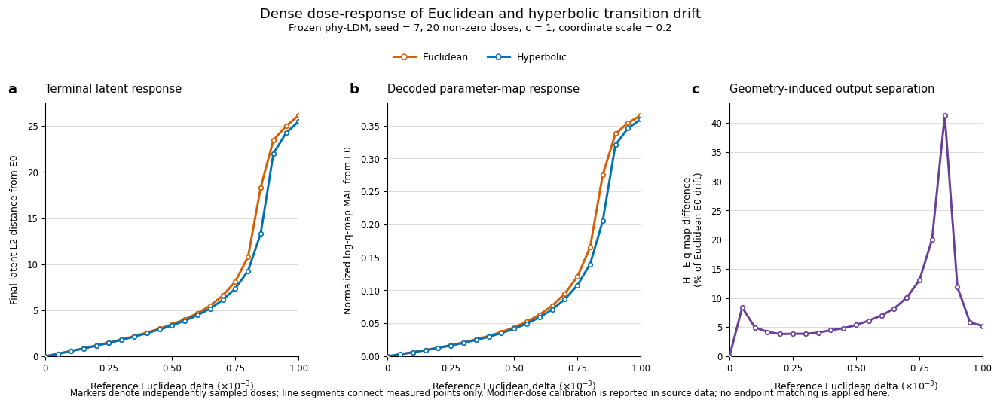

Dense dose-response figure saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/dose_calibration/dense_dose_response_seed_007.png
Dense dose-response PDF saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/dose_calibration/dense_dose_response_seed_007.pdf
Figure source data saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/dose_calibration/dense_dose_response_figure_data_seed_007.csv
Figure metadata saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/dose_calibration/dense_dose_response_figure_metadata_seed_007.json


In [20]:
# Cell 20 — Manuscript dense dose-response figure

from PIL import Image as PILImage
from matplotlib.lines import Line2D
import matplotlib as mpl

DOSE_FIGURE_DIR = (
    RESULTS
    / "manuscript"
    / "figures"
    / "dose_calibration"
)
DOSE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DOSE_FIGURE_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "dose_calibration"
)
DOSE_FIGURE_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

required_symbols = [
    "drift_dose_summary_df",
    "dose_pairing_summary_df",
    "EUCLIDEAN_DELTAS",
    "DOSE_CURVATURE",
    "DOSE_COORDINATE_SCALE",
    "HYPERBOLIC_DELTA_MULTIPLIER",
    "e0_seed",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing required dose-calibration objects:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_symbols
        )
    )

expected_nonzero_deltas = np.asarray(
    EUCLIDEAN_DELTAS[1:],
    dtype=float,
)

if len(expected_nonzero_deltas) < 10:
    raise RuntimeError(
        "This figure requires the dense dose grid from Cell 19."
    )

euclidean_dose_df = (
    drift_dose_summary_df[
        drift_dose_summary_df["geometry"] == "Euclidean"
    ]
    .copy()
    .sort_values("euclidean_delta")
    .reset_index(drop=True)
)

hyperbolic_dose_df = (
    drift_dose_summary_df[
        drift_dose_summary_df["geometry"] == "Hyperbolic"
    ]
    .copy()
    .sort_values("euclidean_delta")
    .reset_index(drop=True)
)

dose_pairing_plot_df = (
    dose_pairing_summary_df
    .copy()
    .sort_values("reference_euclidean_delta")
    .reset_index(drop=True)
)


def validate_dose_grid(
    dataframe,
    delta_column,
    dataframe_name,
):
    observed_deltas = dataframe[
        delta_column
    ].to_numpy(dtype=float)

    if len(observed_deltas) != len(
        expected_nonzero_deltas
    ):
        raise RuntimeError(
            f"{dataframe_name} has {len(observed_deltas)} "
            "dose points, but the dense grid requires "
            f"{len(expected_nonzero_deltas)}."
        )

    if not np.allclose(
        observed_deltas,
        expected_nonzero_deltas,
        rtol=0.0,
        atol=1e-10,
    ):
        raise RuntimeError(
            f"{dataframe_name} does not match the "
            "expected dense dose grid."
        )


validate_dose_grid(
    euclidean_dose_df,
    "euclidean_delta",
    "Euclidean dose table",
)

validate_dose_grid(
    hyperbolic_dose_df,
    "euclidean_delta",
    "Hyperbolic dose table",
)

validate_dose_grid(
    dose_pairing_plot_df,
    "reference_euclidean_delta",
    "Euclidean–hyperbolic pairing table",
)

required_finite_columns = [
    "final_latent_l2_difference_vs_E0",
    "normalized_q_map_mae_vs_E0",
]

for dataframe_name, dataframe in [
    ("Euclidean dose table", euclidean_dose_df),
    ("Hyperbolic dose table", hyperbolic_dose_df),
]:
    numeric_values = dataframe[
        required_finite_columns
    ].to_numpy(dtype=float)

    if not bool(np.isfinite(numeric_values).all()):
        raise FloatingPointError(
            f"Non-finite values were found in {dataframe_name}."
        )

if not bool(
    np.isfinite(
        dose_pairing_plot_df[
            "hyperbolic_minus_euclidean_qmap_mae"
        ].to_numpy(dtype=float)
    ).all()
):
    raise FloatingPointError(
        "Non-finite geometry-separation values were found."
    )


def prepend_shared_e0_baseline(
    x_values,
    y_values,
):
    return (
        np.concatenate(([0.0], np.asarray(x_values))),
        np.concatenate(([0.0], np.asarray(y_values))),
    )


def append_figure_data(
    rows,
    panel,
    curve,
    x_values,
    y_values,
    unit,
):
    for x_value, y_value in zip(x_values, y_values):
        rows.append(
            {
                "panel": panel,
                "curve": curve,
                "reference_euclidean_delta": float(x_value),
                "value": float(y_value),
                "unit": unit,
            }
        )


def style_dose_axis(
    axis,
    title,
    y_label,
):
    axis.set_title(
        title,
        loc="left",
        fontsize=10.5,
        pad=10,
    )

    axis.set_xlabel(
        r"Reference Euclidean delta ($\times 10^{-3}$)",
        labelpad=6,
    )

    axis.set_ylabel(
        y_label,
        labelpad=7,
    )

    axis.set_xlim(
        0.0,
        float(max(EUCLIDEAN_DELTAS)),
    )

    axis.set_xticks(
        [
            0.00000,
            0.00025,
            0.00050,
            0.00075,
            0.00100,
        ]
    )

    axis.set_xticklabels(
        [
            "0",
            "0.25",
            "0.50",
            "0.75",
            "1.00",
        ]
    )

    axis.set_ylim(bottom=0.0)

    axis.grid(
        axis="y",
        color="#D9D9D9",
        linewidth=0.7,
        alpha=0.9,
    )

    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

    axis.spines["left"].set_linewidth(0.8)
    axis.spines["bottom"].set_linewidth(0.8)

    axis.tick_params(
        axis="both",
        which="major",
        labelsize=8.5,
        width=0.8,
        length=3.5,
    )

    axis.set_box_aspect(1.0)


def add_panel_label(
    axis,
    panel_label,
):
    axis.text(
        -0.15,
        1.08,
        panel_label,
        transform=axis.transAxes,
        ha="left",
        va="top",
        fontsize=13,
        fontweight="bold",
    )


def plot_measured_curve(
    axis,
    x_values,
    y_values,
    color,
    label,
):
    return axis.plot(
        x_values,
        y_values,
        color=color,
        linewidth=2.1,
        marker="o",
        markersize=4.0,
        markerfacecolor="white",
        markeredgecolor=color,
        markeredgewidth=1.2,
        label=label,
        zorder=3,
    )[0]


def save_manuscript_figure(
    figure,
    png_path,
    pdf_path,
):
    figure.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
    )

    figure.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white",
    )

    with PILImage.open(png_path) as png_image:
        png_image.convert("RGB").save(png_path)


EUCLIDEAN_COLOR = "#D55E00"
HYPERBOLIC_COLOR = "#0072B2"
GEOMETRY_DIFFERENCE_COLOR = "#6A3D9A"

euclidean_x = euclidean_dose_df[
    "euclidean_delta"
].to_numpy(dtype=float)

hyperbolic_x = hyperbolic_dose_df[
    "euclidean_delta"
].to_numpy(dtype=float)

# Merge the direct H-E q-map difference with the Euclidean E0 drift.
geometry_plot_df = dose_pairing_plot_df.merge(
    euclidean_dose_df[
        [
            "euclidean_delta",
            "normalized_q_map_mae_vs_E0",
        ]
    ],
    left_on="reference_euclidean_delta",
    right_on="euclidean_delta",
    how="inner",
    validate="one_to_one",
)

geometry_plot_df = (
    geometry_plot_df
    .sort_values("reference_euclidean_delta")
    .reset_index(drop=True)
)

if len(geometry_plot_df) != len(
    expected_nonzero_deltas
):
    raise RuntimeError(
        "Could not align all paired geometry measurements."
    )

euclidean_qmap_drift = geometry_plot_df[
    "normalized_q_map_mae_vs_E0"
].to_numpy(dtype=float)

if bool((euclidean_qmap_drift <= 0.0).any()):
    raise FloatingPointError(
        "Euclidean q-map drift must be positive at every non-zero dose."
    )

geometry_relative_percent = (
    100.0
    * geometry_plot_df[
        "hyperbolic_minus_euclidean_qmap_mae"
    ].to_numpy(dtype=float)
    / euclidean_qmap_drift
)

if not bool(np.isfinite(geometry_relative_percent).all()):
    raise FloatingPointError(
        "Non-finite relative geometry-separation values were found."
    )

figure_data_rows = []

with mpl.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titleweight": "regular",
        "axes.labelweight": "regular",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    fig = plt.figure(
        figsize=(13.8, 5.6),
    )

    figure_grid = fig.add_gridspec(
        nrows=1,
        ncols=3,
        left=0.080,
        right=0.985,
        bottom=0.145,
        top=0.745,
        wspace=0.330,
    )

    axes = [
        fig.add_subplot(figure_grid[0, column_index])
        for column_index in range(3)
    ]

    # Panel a: terminal latent response.
    euclidean_terminal_x, euclidean_terminal_y = (
        prepend_shared_e0_baseline(
            euclidean_x,
            euclidean_dose_df[
                "final_latent_l2_difference_vs_E0"
            ].to_numpy(dtype=float),
        )
    )

    hyperbolic_terminal_x, hyperbolic_terminal_y = (
        prepend_shared_e0_baseline(
            hyperbolic_x,
            hyperbolic_dose_df[
                "final_latent_l2_difference_vs_E0"
            ].to_numpy(dtype=float),
        )
    )

    axis = axes[0]

    plot_measured_curve(
        axis,
        euclidean_terminal_x,
        euclidean_terminal_y,
        EUCLIDEAN_COLOR,
        "Euclidean",
    )

    plot_measured_curve(
        axis,
        hyperbolic_terminal_x,
        hyperbolic_terminal_y,
        HYPERBOLIC_COLOR,
        "Hyperbolic",
    )

    style_dose_axis(
        axis,
        "Terminal latent response",
        "Final latent L2 distance from E0",
    )

    add_panel_label(axis, "a")

    append_figure_data(
        figure_data_rows,
        "a",
        "Euclidean",
        euclidean_terminal_x,
        euclidean_terminal_y,
        "L2",
    )

    append_figure_data(
        figure_data_rows,
        "a",
        "Hyperbolic",
        hyperbolic_terminal_x,
        hyperbolic_terminal_y,
        "L2",
    )

    # Panel b: decoded parameter-map response.
    euclidean_qmap_x, euclidean_qmap_y = (
        prepend_shared_e0_baseline(
            euclidean_x,
            euclidean_dose_df[
                "normalized_q_map_mae_vs_E0"
            ].to_numpy(dtype=float),
        )
    )

    hyperbolic_qmap_x, hyperbolic_qmap_y = (
        prepend_shared_e0_baseline(
            hyperbolic_x,
            hyperbolic_dose_df[
                "normalized_q_map_mae_vs_E0"
            ].to_numpy(dtype=float),
        )
    )

    axis = axes[1]

    plot_measured_curve(
        axis,
        euclidean_qmap_x,
        euclidean_qmap_y,
        EUCLIDEAN_COLOR,
        "Euclidean",
    )

    plot_measured_curve(
        axis,
        hyperbolic_qmap_x,
        hyperbolic_qmap_y,
        HYPERBOLIC_COLOR,
        "Hyperbolic",
    )

    style_dose_axis(
        axis,
        "Decoded parameter-map response",
        "Normalized log-q-map MAE from E0",
    )

    add_panel_label(axis, "b")

    append_figure_data(
        figure_data_rows,
        "b",
        "Euclidean",
        euclidean_qmap_x,
        euclidean_qmap_y,
        "Normalized log-q-map MAE",
    )

    append_figure_data(
        figure_data_rows,
        "b",
        "Hyperbolic",
        hyperbolic_qmap_x,
        hyperbolic_qmap_y,
        "Normalized log-q-map MAE",
    )

    # Panel c: geometry-specific difference at the same reference dose.
    geometry_x, geometry_y = prepend_shared_e0_baseline(
        geometry_plot_df[
            "reference_euclidean_delta"
        ].to_numpy(dtype=float),
        geometry_relative_percent,
    )

    axis = axes[2]

    plot_measured_curve(
        axis,
        geometry_x,
        geometry_y,
        GEOMETRY_DIFFERENCE_COLOR,
        "Hyperbolic - Euclidean",
    )

    style_dose_axis(
        axis,
        "Geometry-induced output separation",
        "H - E q-map difference\n(% of Euclidean E0 drift)",
    )

    add_panel_label(axis, "c")

    append_figure_data(
        figure_data_rows,
        "c",
        "Hyperbolic - Euclidean",
        geometry_x,
        geometry_y,
        "Percent of Euclidean E0 drift",
    )

    figure_legend_handles = [
        Line2D(
            [0],
            [0],
            color=EUCLIDEAN_COLOR,
            linewidth=2.1,
            marker="o",
            markersize=5,
            markerfacecolor="white",
            markeredgecolor=EUCLIDEAN_COLOR,
            label="Euclidean",
        ),
        Line2D(
            [0],
            [0],
            color=HYPERBOLIC_COLOR,
            linewidth=2.1,
            marker="o",
            markersize=5,
            markerfacecolor="white",
            markeredgecolor=HYPERBOLIC_COLOR,
            label="Hyperbolic",
        ),
    ]

    fig.text(
        0.50,
        0.972,
        "Dense dose-response of Euclidean and hyperbolic transition drift",
        ha="center",
        va="top",
        fontsize=13,
        fontweight="regular",
    )

    fig.text(
        0.50,
        0.935,
        (
            f"Frozen phy-LDM; seed = {e0_seed}; "
            f"20 non-zero doses; c = {DOSE_CURVATURE:g}; "
            f"coordinate scale = {DOSE_COORDINATE_SCALE:g}"
        ),
        ha="center",
        va="top",
        fontsize=9.5,
    )

    fig.legend(
        handles=figure_legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.50, 0.885),
        ncol=2,
        frameon=False,
        fontsize=9,
        handlelength=2.3,
        columnspacing=2.0,
    )

    fig.text(
        0.50,
        0.045,
        (
            "Markers denote independently sampled doses; "
            "line segments connect measured points only. "
            "Modifier-dose calibration is reported in source data; "
            "no endpoint matching is applied here."
        ),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

    dose_figure_png_path = (
        DOSE_FIGURE_DIR
        / f"dense_dose_response_seed_{e0_seed:03d}.png"
    )

    dose_figure_pdf_path = (
        DOSE_FIGURE_DIR
        / f"dense_dose_response_seed_{e0_seed:03d}.pdf"
    )

    save_manuscript_figure(
        fig,
        dose_figure_png_path,
        dose_figure_pdf_path,
    )

    plt.show()


dose_figure_source_data_df = pd.DataFrame(
    figure_data_rows
)

dose_figure_source_data_path = (
    DOSE_FIGURE_DATA_DIR
    / f"dense_dose_response_figure_data_seed_{e0_seed:03d}.csv"
)

dose_figure_source_data_df.to_csv(
    dose_figure_source_data_path,
    index=False,
)

dose_figure_metadata_path = (
    DOSE_FIGURE_DATA_DIR
    / f"dense_dose_response_figure_metadata_seed_{e0_seed:03d}.json"
)

with open(dose_figure_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(e0_seed),
            "num_reverse_steps": int(
                CFG["num_inference_steps"]
            ),
            "number_of_nonzero_doses": int(
                len(EUCLIDEAN_DELTAS) - 1
            ),
            "reference_euclidean_deltas": [
                float(delta)
                for delta in EUCLIDEAN_DELTAS
            ],
            "curvature": float(DOSE_CURVATURE),
            "coordinate_scale": float(
                DOSE_COORDINATE_SCALE
            ),
            "hyperbolic_delta_multiplier": float(
                HYPERBOLIC_DELTA_MULTIPLIER
            ),
            "endpoint_matching_applied": False,
            "scientific_panels": {
                "a": (
                    "Terminal latent displacement from the shared "
                    "E0 baseline."
                ),
                "b": (
                    "Decoded normalized log-q-map departure from E0."
                ),
                "c": (
                    "Direct Hyperbolic-minus-Euclidean q-map "
                    "separation, normalized by Euclidean E0 drift."
                ),
            },
            "excluded_calibration_control": (
                "Mean modifier-update L2 is intentionally excluded "
                "from the manuscript figure because its Euclidean "
                "reference is analytically linear by construction. "
                "It remains available in the calibration source data."
            ),
            "figure_png": str(dose_figure_png_path),
            "figure_pdf": str(dose_figure_pdf_path),
            "source_data_csv": str(
                dose_figure_source_data_path
            ),
        },
        file,
        indent=2,
    )

print("Dense dose-response figure saved to:", dose_figure_png_path)
print("Dense dose-response PDF saved to:", dose_figure_pdf_path)
print(
    "Figure source data saved to:",
    dose_figure_source_data_path,
)
print(
    "Figure metadata saved to:",
    dose_figure_metadata_path,
)

In [21]:
# Cell 21 — Endpoint-matching preflight from the dense dose calibration

import geometry

ENDPOINT_EUCLIDEAN_DELTA = 0.00050
ENDPOINT_CURVATURE = 1.0
ENDPOINT_COORDINATE_SCALE = 0.2

ENDPOINT_BISECTION_STEPS = 7
ENDPOINT_MAX_RELATIVE_ERROR_PERCENT = 0.10

ENDPOINT_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "endpoint_matching"
)
ENDPOINT_DATA_DIR.mkdir(parents=True, exist_ok=True)

ENDPOINT_TRACE_DIR = ENDPOINT_DATA_DIR / "traces"
ENDPOINT_TRACE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

required_symbols = [
    "dose_results",
    "e0_dose_result",
    "drift_dose_summary_df",
    "EUCLIDEAN_DELTAS",
    "run_drift_method",
    "e0_seed",
    "DOSE_CURVATURE",
    "DOSE_COORDINATE_SCALE",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing dense-calibration objects:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_symbols
        )
    )

if not np.isclose(
    DOSE_CURVATURE,
    ENDPOINT_CURVATURE,
    rtol=0.0,
    atol=1e-12,
):
    raise RuntimeError(
        "The dense dose calibration and endpoint comparison "
        "must use the same hyperbolic curvature."
    )

if not np.isclose(
    DOSE_COORDINATE_SCALE,
    ENDPOINT_COORDINATE_SCALE,
    rtol=0.0,
    atol=1e-12,
):
    raise RuntimeError(
        "The dense dose calibration and endpoint comparison "
        "must use the same coordinate scale."
    )

if not any(
    np.isclose(
        delta,
        ENDPOINT_EUCLIDEAN_DELTA,
        rtol=0.0,
        atol=1e-12,
    )
    for delta in EUCLIDEAN_DELTAS
):
    raise RuntimeError(
        "ENDPOINT_EUCLIDEAN_DELTA is absent from the "
        "dense dose-calibration grid."
    )

e0_final_latent = e0_dose_result[
    "final_scaled_latent"
]

e0_norm_log_q_maps = e0_dose_result[
    "norm_log_q_maps"
]

euclidean_key = (
    f"Euclidean_{ENDPOINT_EUCLIDEAN_DELTA:.5f}"
)

if euclidean_key not in dose_results:
    raise KeyError(
        f"Missing {euclidean_key} in dose_results."
    )

euclidean_reference_result = dose_results[
    euclidean_key
]

target_terminal_l2 = float(
    torch.linalg.vector_norm(
        euclidean_reference_result[
            "final_scaled_latent"
        ]
        - e0_final_latent
    )
    .detach()
    .cpu()
)

target_qmap_mae = float(
    torch.mean(
        torch.abs(
            euclidean_reference_result[
                "norm_log_q_maps"
            ]
            - e0_norm_log_q_maps
        )
    )
    .detach()
    .cpu()
)

if target_terminal_l2 <= 0.0:
    raise RuntimeError(
        "The Euclidean reference terminal displacement "
        "must be positive."
    )


endpoint_grid_rows = []

for method_name, result in dose_results.items():
    if result["geometry"] != "Hyperbolic":
        continue

    terminal_l2 = float(
        torch.linalg.vector_norm(
            result["final_scaled_latent"]
            - e0_final_latent
        )
        .detach()
        .cpu()
    )

    qmap_mae_vs_e0 = float(
        torch.mean(
            torch.abs(
                result["norm_log_q_maps"]
                - e0_norm_log_q_maps
            )
        )
        .detach()
        .cpu()
    )

    endpoint_grid_rows.append(
        {
            "method": method_name,
            "reference_euclidean_delta": float(
                result["euclidean_delta"]
            ),
            "applied_hyperbolic_delta": float(
                result["applied_delta"]
            ),
            "terminal_latent_l2_vs_E0": terminal_l2,
            "terminal_l2_error_to_target": abs(
                terminal_l2 - target_terminal_l2
            ),
            "terminal_l2_relative_error_percent": (
                100.0
                * abs(terminal_l2 - target_terminal_l2)
                / target_terminal_l2
            ),
            "normalized_q_map_mae_vs_E0": qmap_mae_vs_e0,
            "mean_modifier_update_l2": float(
                result["trace"][
                    "modifier_update_l2"
                ].mean()
            ),
        }
    )

endpoint_grid_hyperbolic_df = (
    pd.DataFrame(endpoint_grid_rows)
    .sort_values("applied_hyperbolic_delta")
    .reset_index(drop=True)
)

expected_nonzero_deltas = np.asarray(
    EUCLIDEAN_DELTAS[1:],
    dtype=float,
)

observed_reference_deltas = (
    endpoint_grid_hyperbolic_df[
        "reference_euclidean_delta"
    ].to_numpy(dtype=float)
)

if len(observed_reference_deltas) != len(
    expected_nonzero_deltas
):
    raise RuntimeError(
        "The hyperbolic dense grid is incomplete."
    )

if not np.allclose(
    observed_reference_deltas,
    expected_nonzero_deltas,
    rtol=0.0,
    atol=1e-10,
):
    raise RuntimeError(
        "The hyperbolic dense grid does not match the "
        "expected reference-dose grid."
    )

if not bool(
    np.isfinite(
        endpoint_grid_hyperbolic_df.select_dtypes(
            include=[np.number]
        ).to_numpy()
    ).all()
):
    raise FloatingPointError(
        "Non-finite values were found in the hyperbolic grid."
    )


exact_match_rows = endpoint_grid_hyperbolic_df[
    endpoint_grid_hyperbolic_df[
        "terminal_l2_error_to_target"
    ]
    <= 1e-12
].copy()

endpoint_match_uses_dense_exact_solution = (
    len(exact_match_rows) > 0
)

if endpoint_match_uses_dense_exact_solution:
    selected_row = exact_match_rows.iloc[0]

    endpoint_bracket_lower_delta = float(
        selected_row["applied_hyperbolic_delta"]
    )

    endpoint_bracket_upper_delta = float(
        selected_row["applied_hyperbolic_delta"]
    )

    endpoint_bracket_lower_method = selected_row["method"]
    endpoint_bracket_upper_method = selected_row["method"]

    endpoint_bracket_lower_result = dose_results[
        endpoint_bracket_lower_method
    ]

    endpoint_bracket_upper_result = dose_results[
        endpoint_bracket_upper_method
    ]

    endpoint_initial_interpolated_delta = (
        endpoint_bracket_lower_delta
    )
else:
    bracket_candidates = []

    for row_index in range(
        len(endpoint_grid_hyperbolic_df) - 1
    ):
        lower_row = endpoint_grid_hyperbolic_df.iloc[
            row_index
        ]

        upper_row = endpoint_grid_hyperbolic_df.iloc[
            row_index + 1
        ]

        lower_terminal_l2 = float(
            lower_row["terminal_latent_l2_vs_E0"]
        )

        upper_terminal_l2 = float(
            upper_row["terminal_latent_l2_vs_E0"]
        )

        if upper_terminal_l2 < lower_terminal_l2:
            continue

        if (
            lower_terminal_l2
            <= target_terminal_l2
            <= upper_terminal_l2
        ):
            bracket_candidates.append(
                {
                    "lower_row_index": row_index,
                    "upper_row_index": row_index + 1,
                    "delta_width": float(
                        upper_row[
                            "applied_hyperbolic_delta"
                        ]
                        - lower_row[
                            "applied_hyperbolic_delta"
                        ]
                    ),
                }
            )

    if not bracket_candidates:
        raise RuntimeError(
            "The dense hyperbolic grid did not bracket the "
            "Euclidean target terminal displacement. "
            "Inspect the calibration range before extending it."
        )

    selected_bracket = min(
        bracket_candidates,
        key=lambda item: item["delta_width"],
    )

    lower_row = endpoint_grid_hyperbolic_df.iloc[
        selected_bracket["lower_row_index"]
    ]

    upper_row = endpoint_grid_hyperbolic_df.iloc[
        selected_bracket["upper_row_index"]
    ]

    endpoint_bracket_lower_delta = float(
        lower_row["applied_hyperbolic_delta"]
    )

    endpoint_bracket_upper_delta = float(
        upper_row["applied_hyperbolic_delta"]
    )

    endpoint_bracket_lower_method = lower_row["method"]
    endpoint_bracket_upper_method = upper_row["method"]

    endpoint_bracket_lower_result = dose_results[
        endpoint_bracket_lower_method
    ]

    endpoint_bracket_upper_result = dose_results[
        endpoint_bracket_upper_method
    ]

    lower_terminal_l2 = float(
        lower_row["terminal_latent_l2_vs_E0"]
    )

    upper_terminal_l2 = float(
        upper_row["terminal_latent_l2_vs_E0"]
    )

    interpolation_fraction = (
        (target_terminal_l2 - lower_terminal_l2)
        / (upper_terminal_l2 - lower_terminal_l2)
    )

    endpoint_initial_interpolated_delta = (
        endpoint_bracket_lower_delta
        + interpolation_fraction
        * (
            endpoint_bracket_upper_delta
            - endpoint_bracket_lower_delta
        )
    )


endpoint_preflight_summary_df = pd.DataFrame(
    [
        {
            "seed": e0_seed,
            "reference_euclidean_delta": (
                ENDPOINT_EUCLIDEAN_DELTA
            ),
            "target_terminal_l2_vs_E0": target_terminal_l2,
            "reference_normalized_qmap_mae_vs_E0": (
                target_qmap_mae
            ),
            "curvature": ENDPOINT_CURVATURE,
            "coordinate_scale": ENDPOINT_COORDINATE_SCALE,
            "dense_bracket_lower_delta": (
                endpoint_bracket_lower_delta
            ),
            "dense_bracket_upper_delta": (
                endpoint_bracket_upper_delta
            ),
            "initial_interpolated_hyperbolic_delta": (
                endpoint_initial_interpolated_delta
            ),
            "bisection_steps": ENDPOINT_BISECTION_STEPS,
            "maximum_terminal_relative_error_percent": (
                ENDPOINT_MAX_RELATIVE_ERROR_PERCENT
            ),
        }
    ]
)

endpoint_dense_grid_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_dense_grid_seed_{e0_seed:03d}.csv"
)

endpoint_preflight_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_preflight_seed_{e0_seed:03d}.csv"
)

endpoint_grid_hyperbolic_df.to_csv(
    endpoint_dense_grid_path,
    index=False,
)

endpoint_preflight_summary_df.to_csv(
    endpoint_preflight_path,
    index=False,
)

endpoint_preflight_metadata_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_preflight_seed_{e0_seed:03d}.json"
)

with open(endpoint_preflight_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(e0_seed),
            "reference_euclidean_delta": float(
                ENDPOINT_EUCLIDEAN_DELTA
            ),
            "target_terminal_l2_vs_E0": float(
                target_terminal_l2
            ),
            "reference_normalized_qmap_mae_vs_E0": float(
                target_qmap_mae
            ),
            "curvature": float(ENDPOINT_CURVATURE),
            "coordinate_scale": float(
                ENDPOINT_COORDINATE_SCALE
            ),
            "dense_bracket_lower_delta": float(
                endpoint_bracket_lower_delta
            ),
            "dense_bracket_upper_delta": float(
                endpoint_bracket_upper_delta
            ),
            "initial_interpolated_hyperbolic_delta": float(
                endpoint_initial_interpolated_delta
            ),
            "bisection_steps": int(
                ENDPOINT_BISECTION_STEPS
            ),
            "endpoint_matching_definition": (
                "Hyperbolic delta is selected solely to match the "
                "Euclidean terminal latent L2 displacement from E0. "
                "The q-map metric is diagnostic and is not used as "
                "an optimization target."
            ),
        },
        file,
        indent=2,
    )

print("Endpoint-matching preflight passed.")
print(
    "Reference Euclidean delta:",
    f"{ENDPOINT_EUCLIDEAN_DELTA:.5f}",
)
print(
    "Target terminal latent L2:",
    f"{target_terminal_l2:.6f}",
)
print(
    "Dense hyperbolic bracket:",
    f"[{endpoint_bracket_lower_delta:.8f}, "
    f"{endpoint_bracket_upper_delta:.8f}]",
)
print(
    "Initial interpolated hyperbolic delta:",
    f"{endpoint_initial_interpolated_delta:.8f}",
)
print(
    "No model sampling has been performed in this cell."
)
print("Dense grid saved to:", endpoint_dense_grid_path)
print("Preflight summary saved to:", endpoint_preflight_path)

display(endpoint_preflight_summary_df)

Endpoint-matching preflight passed.
Reference Euclidean delta: 0.00050
Target terminal latent L2: 3.470928
Dense hyperbolic bracket: [0.00055027, 0.00060530]
Initial interpolated hyperbolic delta: 0.00056308
No model sampling has been performed in this cell.
Dense grid saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/endpoint_dense_grid_seed_007.csv
Preflight summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/endpoint_preflight_seed_007.csv


,seed,reference_euclidean_delta,target_terminal_l2_vs_E0,reference_normalized_qmap_mae_vs_E0,curvature,coordinate_scale,dense_bracket_lower_delta,dense_bracket_upper_delta,initial_interpolated_hyperbolic_delta,bisection_steps,maximum_terminal_relative_error_percent
0,7,0.0005,3.470928,0.043903,1.0,0.2,0.00055,0.000605,0.000563,7,0.1


In [22]:
# Cell 22 — Bracketed endpoint matching of hyperbolic drift

import geometry

required_symbols = [
    "run_drift_method",
    "endpoint_bracket_lower_delta",
    "endpoint_bracket_upper_delta",
    "endpoint_bracket_lower_result",
    "endpoint_bracket_upper_result",
    "target_terminal_l2",
    "target_qmap_mae",
    "e0_final_latent",
    "e0_norm_log_q_maps",
    "ENDPOINT_CURVATURE",
    "ENDPOINT_COORDINATE_SCALE",
    "ENDPOINT_BISECTION_STEPS",
    "ENDPOINT_MAX_RELATIVE_ERROR_PERCENT",
    "ENDPOINT_DATA_DIR",
    "ENDPOINT_TRACE_DIR",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing endpoint-matching preflight objects:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_symbols
        )
    )


def endpoint_terminal_l2(result):
    return float(
        torch.linalg.vector_norm(
            result["final_scaled_latent"]
            - e0_final_latent
        )
        .detach()
        .cpu()
    )


def endpoint_qmap_mae_vs_e0(result):
    return float(
        torch.mean(
            torch.abs(
                result["norm_log_q_maps"]
                - e0_norm_log_q_maps
            )
        )
        .detach()
        .cpu()
    )


def endpoint_mean_modifier_l2(result):
    trace_df = result["trace"]

    if "modifier_update_l2" not in trace_df.columns:
        raise KeyError(
            "The transition trace does not contain "
            "modifier_update_l2."
        )

    return float(
        trace_df["modifier_update_l2"].mean()
    )


endpoint_match_results = {}
endpoint_match_rows = []

endpoint_live_summary_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_matching_evaluations_seed_{e0_seed:03d}.csv"
)


def save_live_endpoint_summary():
    pd.DataFrame(endpoint_match_rows).to_csv(
        endpoint_live_summary_path,
        index=False,
    )


def record_endpoint_result(
    result,
    phase,
    source,
):
    method_name = result["method_name"]

    terminal_l2 = endpoint_terminal_l2(result)
    qmap_mae_vs_e0 = endpoint_qmap_mae_vs_e0(result)

    row = {
        "method": method_name,
        "phase": phase,
        "source": source,
        "applied_hyperbolic_delta": float(
            result["applied_delta"]
        ),
        "mean_modifier_update_l2": (
            endpoint_mean_modifier_l2(result)
        ),
        "terminal_latent_l2_vs_E0": terminal_l2,
        "terminal_l2_error_to_target": abs(
            terminal_l2 - target_terminal_l2
        ),
        "terminal_l2_relative_error_percent": (
            100.0
            * abs(terminal_l2 - target_terminal_l2)
            / target_terminal_l2
        ),
        "normalized_q_map_mae_vs_E0": qmap_mae_vs_e0,
        "absolute_error_to_Euclidean_qmap_MAE": abs(
            qmap_mae_vs_e0 - target_qmap_mae
        ),
        "sampling_time_seconds": float(
            result["sampling_time_seconds"]
        ),
    }

    endpoint_match_results[method_name] = result
    endpoint_match_rows.append(row)

    result["trace"].to_csv(
        ENDPOINT_TRACE_DIR
        / (
            f"{method_name.lower()}"
            .replace(" ", "_")
            .replace("-", "_")
            + f"_trace_seed_{e0_seed:03d}.csv"
        ),
        index=False,
    )

    save_live_endpoint_summary()

    return terminal_l2


def evaluate_hyperbolic_candidate(
    applied_hyperbolic_delta,
    phase,
):
    method_name = (
        f"Hyperbolic_{phase}_"
        f"{applied_hyperbolic_delta:.10f}"
    )

    print(
        f"Running {phase}: "
        f"hyperbolic delta = {applied_hyperbolic_delta:.10f}"
    )

    result = run_drift_method(
        method_name=method_name,
        geometry_name="Hyperbolic endpoint-matched",
        euclidean_delta=ENDPOINT_EUCLIDEAN_DELTA,
        applied_delta=applied_hyperbolic_delta,
        transition_modifier=(
            geometry.make_hyperbolic_scalar_drift(
                delta=applied_hyperbolic_delta,
                curvature=ENDPOINT_CURVATURE,
                coordinate_scale=ENDPOINT_COORDINATE_SCALE,
            )
        ),
    )

    terminal_l2 = record_endpoint_result(
        result,
        phase=phase,
        source="new endpoint-matching evaluation",
    )

    return result, terminal_l2


# Record the two dense-calibration points that formed the bracket.
lower_terminal_l2 = record_endpoint_result(
    endpoint_bracket_lower_result,
    phase="dense bracket lower",
    source="reused dense dose calibration",
)

upper_terminal_l2 = record_endpoint_result(
    endpoint_bracket_upper_result,
    phase="dense bracket upper",
    source="reused dense dose calibration",
)

lower_delta = float(endpoint_bracket_lower_delta)
upper_delta = float(endpoint_bracket_upper_delta)

if lower_delta > upper_delta:
    raise RuntimeError(
        "The endpoint bracket has reversed delta ordering."
    )

if lower_terminal_l2 > upper_terminal_l2:
    raise RuntimeError(
        "The dense bracket is not locally monotonic in terminal "
        "latent displacement. Inspect the dose-response curve "
        "before applying bisection."
    )

if not (
    lower_terminal_l2
    <= target_terminal_l2
    <= upper_terminal_l2
):
    raise RuntimeError(
        "The dense bracket does not contain the target terminal "
        "latent displacement."
    )


if lower_delta == upper_delta:
    matched_hyperbolic_result = (
        endpoint_bracket_lower_result
    )

    matched_hyperbolic_applied_delta = lower_delta

    matched_terminal_l2 = lower_terminal_l2

    print(
        "The dense dose grid already contains an exact endpoint match."
    )
else:
    for iteration in range(
        ENDPOINT_BISECTION_STEPS
    ):
        middle_delta = 0.5 * (
            lower_delta + upper_delta
        )

        middle_result, middle_terminal_l2 = (
            evaluate_hyperbolic_candidate(
                middle_delta,
                phase=f"bisection_{iteration + 1:02d}",
            )
        )

        if middle_terminal_l2 < target_terminal_l2:
            lower_delta = middle_delta
            lower_terminal_l2 = middle_terminal_l2
            endpoint_bracket_lower_result = middle_result
        else:
            upper_delta = middle_delta
            upper_terminal_l2 = middle_terminal_l2
            endpoint_bracket_upper_result = middle_result

    interpolation_fraction = (
        (target_terminal_l2 - lower_terminal_l2)
        / (upper_terminal_l2 - lower_terminal_l2)
    )

    matched_hyperbolic_applied_delta = (
        lower_delta
        + interpolation_fraction
        * (upper_delta - lower_delta)
    )

    (
        matched_hyperbolic_result,
        matched_terminal_l2,
    ) = evaluate_hyperbolic_candidate(
        matched_hyperbolic_applied_delta,
        phase="terminal_matched",
    )


matched_terminal_l2_error = abs(
    matched_terminal_l2 - target_terminal_l2
)

matched_terminal_l2_relative_error_percent = (
    100.0
    * matched_terminal_l2_error
    / target_terminal_l2
)

if (
    matched_terminal_l2_relative_error_percent
    > ENDPOINT_MAX_RELATIVE_ERROR_PERCENT
):
    raise RuntimeError(
        "Endpoint matching did not meet the required precision.\n"
        f"Observed relative error: "
        f"{matched_terminal_l2_relative_error_percent:.6f}%\n"
        f"Required maximum: "
        f"{ENDPOINT_MAX_RELATIVE_ERROR_PERCENT:.6f}%"
    )

best_endpoint_match_name = (
    matched_hyperbolic_result["method_name"]
)

best_hyperbolic_result = matched_hyperbolic_result

endpoint_match_summary_df = (
    pd.DataFrame(endpoint_match_rows)
    .sort_values(
        "terminal_l2_error_to_target"
    )
    .reset_index(drop=True)
)

endpoint_final_summary_df = pd.DataFrame(
    [
        {
            "method": "Euclidean reference",
            "applied_delta": ENDPOINT_EUCLIDEAN_DELTA,
            "terminal_latent_l2_vs_E0": target_terminal_l2,
            "terminal_l2_error_to_target": 0.0,
            "terminal_l2_relative_error_percent": 0.0,
            "normalized_q_map_mae_vs_E0": target_qmap_mae,
        },
        {
            "method": "Hyperbolic terminal-matched",
            "applied_delta": (
                matched_hyperbolic_applied_delta
            ),
            "terminal_latent_l2_vs_E0": (
                matched_terminal_l2
            ),
            "terminal_l2_error_to_target": (
                matched_terminal_l2_error
            ),
            "terminal_l2_relative_error_percent": (
                matched_terminal_l2_relative_error_percent
            ),
            "normalized_q_map_mae_vs_E0": (
                endpoint_qmap_mae_vs_e0(
                    matched_hyperbolic_result
                )
            ),
        },
    ]
)

endpoint_final_summary_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_matched_summary_seed_{e0_seed:03d}.csv"
)

endpoint_match_summary_df.to_csv(
    endpoint_live_summary_path,
    index=False,
)

endpoint_final_summary_df.to_csv(
    endpoint_final_summary_path,
    index=False,
)


def serialize_endpoint_result(result):
    return {
        "method_name": result["method_name"],
        "geometry": result["geometry"],
        "euclidean_delta": float(
            result["euclidean_delta"]
        ),
        "applied_delta": float(result["applied_delta"]),
        "norm_log_q_maps": result[
            "norm_log_q_maps"
        ].detach().cpu(),
        "final_scaled_latent": result[
            "final_scaled_latent"
        ].detach().cpu(),
        "log_q_maps": result["log_q_maps"].detach().cpu(),
        "q_maps": result["q_maps"].detach().cpu(),
        "mri_images": {
            image_name: image.detach().cpu()
            for image_name, image in result[
                "mri_images"
            ].items()
        },
        "trace": result["trace"].copy(),
        "sampling_time_seconds": float(
            result["sampling_time_seconds"]
        ),
    }


endpoint_tensor_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_matched_outputs_seed_{e0_seed:03d}.pt"
)

torch.save(
    {
        "seed": e0_seed,
        "reference_euclidean_delta": (
            ENDPOINT_EUCLIDEAN_DELTA
        ),
        "curvature": ENDPOINT_CURVATURE,
        "coordinate_scale": ENDPOINT_COORDINATE_SCALE,
        "target_terminal_l2": target_terminal_l2,
        "matched_hyperbolic_delta": (
            matched_hyperbolic_applied_delta
        ),
        "matched_terminal_l2": matched_terminal_l2,
        "matched_terminal_l2_error": (
            matched_terminal_l2_error
        ),
        "matched_terminal_l2_relative_error_percent": (
            matched_terminal_l2_relative_error_percent
        ),
        "euclidean_reference_result": (
            serialize_endpoint_result(
                euclidean_reference_result
            )
        ),
        "matched_hyperbolic_result": (
            serialize_endpoint_result(
                matched_hyperbolic_result
            )
        ),
        "evaluations": {
            method_name: serialize_endpoint_result(result)
            for method_name, result in (
                endpoint_match_results.items()
            )
        },
    },
    endpoint_tensor_path,
)

endpoint_metadata_path = (
    ENDPOINT_DATA_DIR
    / f"endpoint_matching_metadata_seed_{e0_seed:03d}.json"
)

with open(endpoint_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(e0_seed),
            "reference_euclidean_delta": float(
                ENDPOINT_EUCLIDEAN_DELTA
            ),
            "curvature": float(ENDPOINT_CURVATURE),
            "coordinate_scale": float(
                ENDPOINT_COORDINATE_SCALE
            ),
            "target_terminal_l2_vs_E0": float(
                target_terminal_l2
            ),
            "matched_hyperbolic_delta": float(
                matched_hyperbolic_applied_delta
            ),
            "matched_terminal_l2_vs_E0": float(
                matched_terminal_l2
            ),
            "matched_terminal_l2_relative_error_percent": (
                float(
                    matched_terminal_l2_relative_error_percent
                )
            ),
            "bisection_steps": int(
                ENDPOINT_BISECTION_STEPS
            ),
            "endpoint_matching_definition": (
                "The hyperbolic delta is selected solely to match "
                "the Euclidean terminal latent L2 displacement "
                "from E0. q-map metrics are retained as diagnostics "
                "and are not optimization targets."
            ),
        },
        file,
        indent=2,
    )

print("Endpoint-matched hyperbolic comparison completed.")
print(
    "Reference Euclidean terminal L2:",
    f"{target_terminal_l2:.6f}",
)
print(
    "Matched hyperbolic delta:",
    f"{matched_hyperbolic_applied_delta:.10f}",
)
print(
    "Matched hyperbolic terminal L2:",
    f"{matched_terminal_l2:.6f}",
)
print(
    "Relative endpoint mismatch:",
    f"{matched_terminal_l2_relative_error_percent:.6f}%",
)
print("Evaluation table saved to:", endpoint_live_summary_path)
print("Final summary saved to:", endpoint_final_summary_path)
print("Endpoint tensors saved to:", endpoint_tensor_path)
print("Endpoint metadata saved to:", endpoint_metadata_path)

display(endpoint_final_summary_df)
display(endpoint_match_summary_df)

Running bisection_01: hyperbolic delta = 0.0005777839
Running bisection_02: hyperbolic delta = 0.0005640272
Running bisection_03: hyperbolic delta = 0.0005571488
Running bisection_04: hyperbolic delta = 0.0005605880
Running bisection_05: hyperbolic delta = 0.0005623076
Running bisection_06: hyperbolic delta = 0.0005631674
Running bisection_07: hyperbolic delta = 0.0005635973
Running terminal_matched: hyperbolic delta = 0.0005637494
Endpoint-matched hyperbolic comparison completed.
Reference Euclidean terminal L2: 3.470928
Matched hyperbolic delta: 0.0005637494
Matched hyperbolic terminal L2: 3.470358
Relative endpoint mismatch: 0.016438%
Evaluation table saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/endpoint_matching_evaluations_seed_007.csv
Final summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/endpoint_matched_summary_seed_007.csv
Endpoint tensors sav

,method,applied_delta,terminal_latent_l2_vs_E0,terminal_l2_error_to_target,terminal_l2_relative_error_percent,normalized_q_map_mae_vs_E0
0,Euclidean reference,0.000500,3.470928,0.000000,0.000000,0.043903
1,Hyperbolic terminal-matched,0.000564,3.470358,0.000571,0.016438,0.043545


,method,phase,source,applied_hyperbolic_delta,mean_modifier_update_l2,terminal_latent_l2_vs_E0,terminal_l2_error_to_target,terminal_l2_relative_error_percent,normalized_q_map_mae_vs_E0,absolute_error_to_Euclidean_qmap_MAE,sampling_time_seconds
0,Hyperbolic_terminal_matched_0.0005637494,terminal_matched,new endpoint-matching evaluation,0.000564,0.029692,3.470358,0.000571,0.016438,0.043545,0.000359,2.624115
1,Hyperbolic_bisection_07_0.0005635973,bisection_07,new endpoint-matching evaluation,0.000564,0.029684,3.468980,0.001948,0.056127,0.043525,0.000378,2.429945
2,Hyperbolic_bisection_02_0.0005640272,bisection_02,new endpoint-matching evaluation,0.000564,0.029707,3.474485,0.003557,0.102486,0.043614,0.000289,1.631601
3,Hyperbolic_bisection_06_0.0005631674,bisection_06,new endpoint-matching evaluation,0.000563,0.029662,3.466284,0.004644,0.133795,0.043489,0.000414,2.033772
4,Hyperbolic_bisection_05_0.0005623076,bisection_05,new endpoint-matching evaluation,0.000562,0.029616,3.459220,0.011708,0.337317,0.043394,0.000510,1.592932
5,Hyperbolic_bisection_04_0.0005605880,bisection_04,new endpoint-matching evaluation,0.000561,0.029526,3.442775,0.028153,0.811114,0.043134,0.000769,1.874100
6,Hyperbolic_bisection_03_0.0005571488,bisection_03,new endpoint-matching evaluation,0.000557,0.029345,3.411666,0.059262,1.707390,0.042668,0.001235,1.751959
7,Hyperbolic_0.00050,dense bracket lower,reused dense dose calibration,0.000550,0.028982,3.352326,0.118602,3.417005,0.041790,0.002113,1.687395
8,Hyperbolic_bisection_01_0.0005777839,bisection_01,new endpoint-matching evaluation,0.000578,0.030432,3.598407,0.127479,3.672766,0.045486,0.001583,2.087218
9,Hyperbolic_0.00055,dense bracket upper,reused dense dose calibration,0.000605,0.031881,3.861971,0.391043,11.266236,0.049537,0.005634,1.734254


In [23]:
# Cell 23 — Freeze and audit the fair endpoint-matched comparison

required_symbols = [
    "CFG",
    "RESULTS",
    "e0_dose_result",
    "e0_final_latent",
    "e0_norm_log_q_maps",
    "euclidean_reference_result",
    "matched_hyperbolic_result",
    "matched_hyperbolic_applied_delta",
    "target_terminal_l2",
    "target_qmap_mae",
    "ENDPOINT_EUCLIDEAN_DELTA",
    "ENDPOINT_CURVATURE",
    "ENDPOINT_COORDINATE_SCALE",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing endpoint-matching objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun Cells 21 and 22 before this cell."
    )

ENDPOINT_AUDIT_DIR = (
    Path(
        globals().get(
            "ENDPOINT_DATA_DIR",
            RESULTS / "manuscript" / "data" / "endpoint_matching",
        )
    )
    / "fair_comparison"
)
ENDPOINT_AUDIT_DIR.mkdir(parents=True, exist_ok=True)

endpoint_relative_error_threshold_percent = float(
    globals().get("ENDPOINT_MAX_RELATIVE_ERROR_PERCENT", 0.10)
)


def tensor_l2_distance(first, second):
    return float(
        torch.linalg.vector_norm(first - second).detach().cpu()
    )


def tensor_mae(first, second):
    return float(
        torch.mean(torch.abs(first - second)).detach().cpu()
    )


def mean_modifier_update_l2(result):
    trace = result.get("trace", None)

    if not isinstance(trace, pd.DataFrame):
        return np.nan

    if "modifier_update_l2" not in trace.columns:
        return np.nan

    return float(trace["modifier_update_l2"].mean())


e0_endpoint_result = e0_dose_result
euclidean_endpoint_result = euclidean_reference_result
hyperbolic_endpoint_result = matched_hyperbolic_result

for condition_name, result in {
    "E0": e0_endpoint_result,
    "Euclidean": euclidean_endpoint_result,
    "Hyperbolic endpoint-matched": hyperbolic_endpoint_result,
}.items():
    for tensor_name in [
        "final_scaled_latent",
        "norm_log_q_maps",
    ]:
        if tensor_name not in result:
            raise KeyError(
                f"{condition_name} result is missing '{tensor_name}'."
            )

        if not bool(torch.isfinite(result[tensor_name]).all()):
            raise FloatingPointError(
                f"Non-finite values found in {condition_name}: {tensor_name}"
            )

euclidean_terminal_l2 = tensor_l2_distance(
    euclidean_endpoint_result["final_scaled_latent"],
    e0_final_latent,
)

hyperbolic_terminal_l2 = tensor_l2_distance(
    hyperbolic_endpoint_result["final_scaled_latent"],
    e0_final_latent,
)

hyperbolic_terminal_error = abs(
    hyperbolic_terminal_l2 - target_terminal_l2
)

hyperbolic_terminal_relative_error_percent = (
    100.0
    * hyperbolic_terminal_error
    / max(target_terminal_l2, 1e-12)
)

if not np.isclose(
    euclidean_terminal_l2,
    target_terminal_l2,
    rtol=0.0,
    atol=1e-6,
):
    raise AssertionError(
        "The recomputed Euclidean endpoint does not equal the target "
        "used by Cell 22."
    )

if (
    hyperbolic_terminal_relative_error_percent
    > endpoint_relative_error_threshold_percent
):
    raise AssertionError(
        "The final hyperbolic endpoint match exceeds the configured "
        f"tolerance of {endpoint_relative_error_threshold_percent:.3f}%."
    )

euclidean_qmap_mae_vs_e0 = tensor_mae(
    euclidean_endpoint_result["norm_log_q_maps"],
    e0_norm_log_q_maps,
)

hyperbolic_qmap_mae_vs_e0 = tensor_mae(
    hyperbolic_endpoint_result["norm_log_q_maps"],
    e0_norm_log_q_maps,
)

hyperbolic_qmap_mae_vs_euclidean = tensor_mae(
    hyperbolic_endpoint_result["norm_log_q_maps"],
    euclidean_endpoint_result["norm_log_q_maps"],
)

hyperbolic_latent_l2_vs_euclidean = tensor_l2_distance(
    hyperbolic_endpoint_result["final_scaled_latent"],
    euclidean_endpoint_result["final_scaled_latent"],
)

endpoint_matched_comparison_results = {
    "E0": e0_endpoint_result,
    "Euclidean": euclidean_endpoint_result,
    "Hyperbolic endpoint-matched": hyperbolic_endpoint_result,
}

endpoint_matched_comparison_specs = [
    {
        "key": "E0",
        "label": "E0\nNo drift",
        "geometry": "No drift",
    },
    {
        "key": "Euclidean",
        "label": (
            "Euclidean drift\n"
            f"$\\delta$ = {ENDPOINT_EUCLIDEAN_DELTA:.5f}"
        ),
        "geometry": "Euclidean",
    },
    {
        "key": "Hyperbolic endpoint-matched",
        "label": (
            "Hyperbolic drift\n"
            f"$\\delta$ = {matched_hyperbolic_applied_delta:.7f}, "
            f"$c$ = {ENDPOINT_CURVATURE:g}"
        ),
        "geometry": "Hyperbolic",
    },
]

endpoint_fair_comparison_df = pd.DataFrame(
    [
        {
            "condition": "E0",
            "geometry": "No drift",
            "applied_delta": 0.0,
            "curvature": np.nan,
            "coordinate_scale": np.nan,
            "mean_modifier_update_l2": mean_modifier_update_l2(
                e0_endpoint_result
            ),
            "terminal_latent_l2_vs_E0": 0.0,
            "terminal_l2_error_to_Euclidean_target": np.nan,
            "terminal_l2_relative_error_percent": np.nan,
            "terminal_latent_l2_vs_Euclidean": euclidean_terminal_l2,
            "normalized_qmap_mae_vs_E0": 0.0,
            "normalized_qmap_mae_vs_Euclidean": euclidean_qmap_mae_vs_e0,
            "endpoint_status": "baseline",
        },
        {
            "condition": "Euclidean reference",
            "geometry": "Euclidean",
            "applied_delta": ENDPOINT_EUCLIDEAN_DELTA,
            "curvature": 0.0,
            "coordinate_scale": np.nan,
            "mean_modifier_update_l2": mean_modifier_update_l2(
                euclidean_endpoint_result
            ),
            "terminal_latent_l2_vs_E0": euclidean_terminal_l2,
            "terminal_l2_error_to_Euclidean_target": 0.0,
            "terminal_l2_relative_error_percent": 0.0,
            "terminal_latent_l2_vs_Euclidean": 0.0,
            "normalized_qmap_mae_vs_E0": euclidean_qmap_mae_vs_e0,
            "normalized_qmap_mae_vs_Euclidean": 0.0,
            "endpoint_status": "reference target",
        },
        {
            "condition": "Hyperbolic endpoint-matched",
            "geometry": "Hyperbolic",
            "applied_delta": float(matched_hyperbolic_applied_delta),
            "curvature": ENDPOINT_CURVATURE,
            "coordinate_scale": ENDPOINT_COORDINATE_SCALE,
            "mean_modifier_update_l2": mean_modifier_update_l2(
                hyperbolic_endpoint_result
            ),
            "terminal_latent_l2_vs_E0": hyperbolic_terminal_l2,
            "terminal_l2_error_to_Euclidean_target": (
                hyperbolic_terminal_error
            ),
            "terminal_l2_relative_error_percent": (
                hyperbolic_terminal_relative_error_percent
            ),
            "terminal_latent_l2_vs_Euclidean": (
                hyperbolic_latent_l2_vs_euclidean
            ),
            "normalized_qmap_mae_vs_E0": hyperbolic_qmap_mae_vs_e0,
            "normalized_qmap_mae_vs_Euclidean": (
                hyperbolic_qmap_mae_vs_euclidean
            ),
            "endpoint_status": "matched",
        },
    ]
)

endpoint_fair_comparison_csv_path = (
    ENDPOINT_AUDIT_DIR
    / f"endpoint_matched_fair_comparison_seed_{CFG['reference_seed']:03d}.csv"
)

endpoint_fair_comparison_df.to_csv(
    endpoint_fair_comparison_csv_path,
    index=False,
)

endpoint_fair_comparison_tensor_path = (
    ENDPOINT_AUDIT_DIR
    / f"endpoint_matched_fair_comparison_seed_{CFG['reference_seed']:03d}.pt"
)

torch.save(
    {
        "seed": int(CFG["reference_seed"]),
        "euclidean_delta": float(ENDPOINT_EUCLIDEAN_DELTA),
        "hyperbolic_delta": float(matched_hyperbolic_applied_delta),
        "curvature": float(ENDPOINT_CURVATURE),
        "coordinate_scale": float(ENDPOINT_COORDINATE_SCALE),
        "target_terminal_l2_vs_E0": float(target_terminal_l2),
        "conditions": {
            key: {
                "final_scaled_latent": result[
                    "final_scaled_latent"
                ].detach().cpu(),
                "norm_log_q_maps": result[
                    "norm_log_q_maps"
                ].detach().cpu(),
            }
            for key, result in endpoint_matched_comparison_results.items()
        },
    },
    endpoint_fair_comparison_tensor_path,
)

endpoint_fair_comparison_metadata_path = (
    ENDPOINT_AUDIT_DIR
    / f"endpoint_matched_fair_comparison_seed_{CFG['reference_seed']:03d}.json"
)

with open(endpoint_fair_comparison_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(CFG["reference_seed"]),
            "matching_target": (
                "Final scaled-latent L2 distance from E0"
            ),
            "euclidean_reference_delta": float(
                ENDPOINT_EUCLIDEAN_DELTA
            ),
            "hyperbolic_matched_delta": float(
                matched_hyperbolic_applied_delta
            ),
            "curvature": float(ENDPOINT_CURVATURE),
            "coordinate_scale": float(ENDPOINT_COORDINATE_SCALE),
            "target_terminal_l2_vs_E0": float(target_terminal_l2),
            "hyperbolic_terminal_l2_vs_E0": float(
                hyperbolic_terminal_l2
            ),
            "hyperbolic_terminal_l2_relative_error_percent": float(
                hyperbolic_terminal_relative_error_percent
            ),
            "maximum_allowed_relative_error_percent": float(
                endpoint_relative_error_threshold_percent
            ),
            "matching_passed": True,
            "note": (
                "q-map values were not used as matching targets; they are "
                "downstream geometry-sensitive readouts."
            ),
        },
        file,
        indent=2,
    )

print("Fair endpoint-matched comparison is frozen.")
print(
    "Euclidean terminal L2:",
    f"{euclidean_terminal_l2:.6f}",
)
print(
    "Hyperbolic terminal L2:",
    f"{hyperbolic_terminal_l2:.6f}",
)
print(
    "Hyperbolic relative endpoint mismatch:",
    f"{hyperbolic_terminal_relative_error_percent:.6f}%",
)
print(
    "Hyperbolic–Euclidean normalized q-map MAE:",
    f"{hyperbolic_qmap_mae_vs_euclidean:.6f}",
)
print("No model sampling has been performed in this cell.")
print("Comparison table saved to:", endpoint_fair_comparison_csv_path)
print("Comparison tensors saved to:", endpoint_fair_comparison_tensor_path)
print("Comparison metadata saved to:", endpoint_fair_comparison_metadata_path)

display(endpoint_fair_comparison_df)

Fair endpoint-matched comparison is frozen.
Euclidean terminal L2: 3.470928
Hyperbolic terminal L2: 3.470358
Hyperbolic relative endpoint mismatch: 0.016438%
Hyperbolic–Euclidean normalized q-map MAE: 0.000735
No model sampling has been performed in this cell.
Comparison table saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fair_comparison/endpoint_matched_fair_comparison_seed_007.csv
Comparison tensors saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fair_comparison/endpoint_matched_fair_comparison_seed_007.pt
Comparison metadata saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fair_comparison/endpoint_matched_fair_comparison_seed_007.json


,condition,geometry,applied_delta,curvature,coordinate_scale,mean_modifier_update_l2,terminal_latent_l2_vs_E0,terminal_l2_error_to_Euclidean_target,terminal_l2_relative_error_percent,terminal_latent_l2_vs_Euclidean,normalized_qmap_mae_vs_E0,normalized_qmap_mae_vs_Euclidean,endpoint_status
0,E0,No drift,0.000000,NaN,NaN,0.000000,0.000000,NaN,NaN,3.470928,0.000000,0.043903,baseline
1,Euclidean reference,Euclidean,0.000500,0.0,NaN,0.028982,3.470928,0.000000,0.000000,0.000000,0.043903,0.000000,reference target
2,Hyperbolic endpoint-matched,Hyperbolic,0.000564,1.0,0.2,0.029692,3.470358,0.000571,0.016438,0.044389,0.043545,0.000735,matched


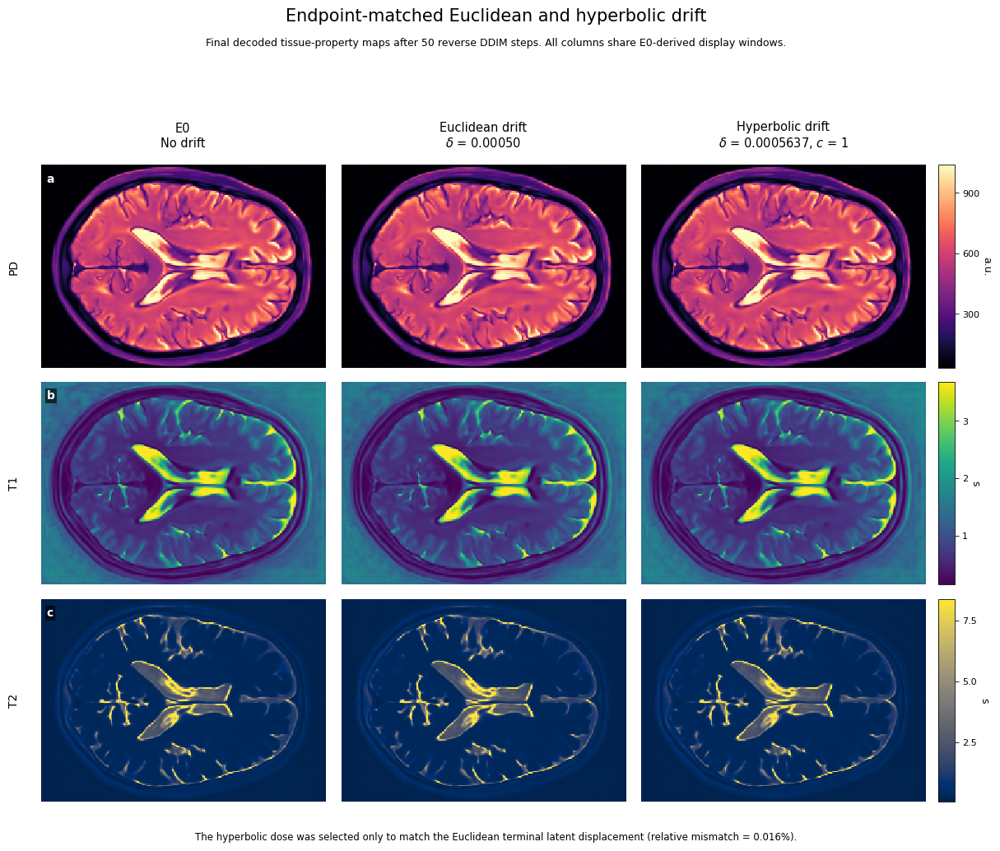

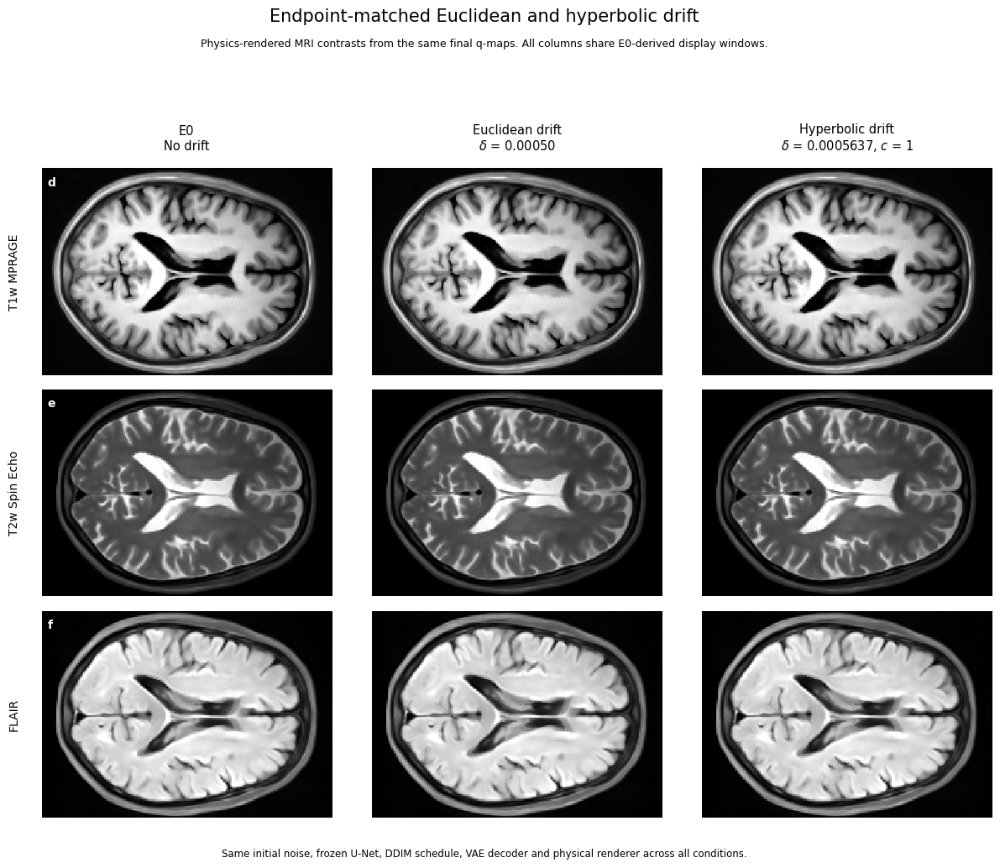

Endpoint-matched visual comparison completed.
Hyperbolic terminal-displacement mismatch: 0.016438%
q-map PNG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matched_comparison/endpoint_matched_qmaps_seed_007.png
q-map PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matched_comparison/endpoint_matched_qmaps_seed_007.pdf
MRI PNG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matched_comparison/endpoint_matched_mri_contrasts_seed_007.png
MRI PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matched_comparison/endpoint_matched_mri_contrasts_seed_007.pdf
Physical outputs: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fair_comparison/endpoint_matched_physical_outputs_seed_007.pt
Display windows: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/resu

In [24]:
# Cell 24 — Manuscript endpoint-matched visual comparison

from pathlib import Path
from PIL import Image
from matplotlib.ticker import MaxNLocator
import matplotlib as mpl

required_symbols = [
    "CFG",
    "RESULTS",
    "create_physical_outputs",
    "e0_display_windows",
    "endpoint_matched_comparison_results",
    "endpoint_matched_comparison_specs",
    "target_terminal_l2",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing endpoint-matched comparison objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun Cells 21–23 before this cell."
    )

required_window_keys = [
    "PD",
    "T1",
    "T2",
    "T1w MPRAGE",
    "T2w Spin Echo",
    "FLAIR",
]

missing_window_keys = [
    key for key in required_window_keys
    if key not in e0_display_windows
]

if missing_window_keys:
    raise KeyError(
        "Cell 8 E0 display windows are incomplete:\n"
        + "\n".join(f"  - {key}" for key in missing_window_keys)
    )

ENDPOINT_FIGURE_DIR = (
    RESULTS
    / "manuscript"
    / "figures"
    / "endpoint_matched_comparison"
)
ENDPOINT_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

ENDPOINT_VISUAL_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "endpoint_matching"
    / "fair_comparison"
)
ENDPOINT_VISUAL_DATA_DIR.mkdir(parents=True, exist_ok=True)

seed_tag = f"{CFG['reference_seed']:03d}"


def ensure_unbatched_q_maps(q_maps):
    if q_maps.ndim == 4:
        if q_maps.shape[0] != 1:
            raise ValueError(
                "Expected one decoded q-map sample, "
                f"got batch shape {tuple(q_maps.shape)}."
            )
        q_maps = q_maps[0]

    if q_maps.ndim != 3 or q_maps.shape[0] != 3:
        raise ValueError(
            "Expected q-maps with shape [3, H, W], "
            f"got {tuple(q_maps.shape)}."
        )

    return q_maps


def ensure_2d_image(image):
    while image.ndim > 2:
        if image.shape[0] != 1:
            raise ValueError(
                "Expected a singleton leading dimension while converting "
                f"to a 2D image, got {tuple(image.shape)}."
            )
        image = image[0]

    if image.ndim != 2:
        raise ValueError(
            f"Expected a 2D image, got {tuple(image.shape)}."
        )

    return image


def normalize_physical_output(physical_output):
    if isinstance(physical_output, tuple) and len(physical_output) == 3:
        log_q_maps, q_maps, mri_images = physical_output

    elif isinstance(physical_output, dict):
        log_q_maps = physical_output["log_q_maps"]
        q_maps = physical_output["q_maps"]
        mri_images = physical_output["mri_images"]

    else:
        raise TypeError(
            "create_physical_outputs must return either a three-item tuple "
            "or a dictionary with log_q_maps, q_maps, and mri_images."
        )

    q_maps = ensure_unbatched_q_maps(q_maps)

    normalized_mri_images = {
        name: ensure_2d_image(image)
        for name, image in mri_images.items()
    }

    return {
        "log_q_maps": log_q_maps.detach().cpu(),
        "q_maps": q_maps.detach().cpu(),
        "mri_images": {
            name: image.detach().cpu()
            for name, image in normalized_mri_images.items()
        },
    }


def tensor_to_2d_numpy(tensor):
    tensor = ensure_2d_image(tensor.detach().float().cpu())
    array = tensor.numpy()

    if not bool(np.isfinite(array).all()):
        raise FloatingPointError(
            "Non-finite values were found while preparing a display image."
        )

    return array


def save_rgb_png_and_pdf(figure, png_path, pdf_path):
    figure.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )

    temporary_rgb_path = png_path.with_name(
        f"{png_path.stem}_temporary_rgb.png"
    )

    with Image.open(png_path) as image:
        image.convert("RGB").save(temporary_rgb_path)

    temporary_rgb_path.replace(png_path)

    figure.savefig(
        pdf_path,
        format="pdf",
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )


# No U-Net or DDIM sampling is performed below.
# These are deterministic physical conversions of the final matched outputs.
endpoint_matched_comparison_outputs = {}

for specification in endpoint_matched_comparison_specs:
    condition_key = specification["key"]
    result = endpoint_matched_comparison_results[condition_key]

    endpoint_matched_comparison_outputs[condition_key] = (
        normalize_physical_output(
            create_physical_outputs(result["norm_log_q_maps"])
        )
    )

e0_label = "E0"
euclidean_label = "Euclidean"
hyperbolic_label = "Hyperbolic endpoint-matched"

e0_outputs = endpoint_matched_comparison_outputs[e0_label]
euclidean_outputs = endpoint_matched_comparison_outputs[euclidean_label]
hyperbolic_outputs = endpoint_matched_comparison_outputs[
    hyperbolic_label
]

e0_pd = tensor_to_2d_numpy(e0_outputs["q_maps"][0])

DISPLAY_FOREGROUND_QUANTILE = 0.20

foreground_threshold = float(
    np.quantile(
        e0_pd[np.isfinite(e0_pd)],
        DISPLAY_FOREGROUND_QUANTILE,
    )
)

foreground_mask = e0_pd > foreground_threshold

display_limits = {
    key: (
        float(e0_display_windows[key][0]),
        float(e0_display_windows[key][1]),
    )
    for key in required_window_keys
}

qmap_row_specs = [
    {
        "name": "PD",
        "unit": "a.u.",
        "channel": 0,
        "cmap": "magma",
        "panel_letter": "a",
    },
    {
        "name": "T1",
        "unit": "s",
        "channel": 1,
        "cmap": "viridis",
        "panel_letter": "b",
    },
    {
        "name": "T2",
        "unit": "s",
        "channel": 2,
        "cmap": "cividis",
        "panel_letter": "c",
    },
]

mri_row_specs = [
    {
        "name": "T1w MPRAGE",
        "panel_letter": "d",
    },
    {
        "name": "T2w Spin Echo",
        "panel_letter": "e",
    },
    {
        "name": "FLAIR",
        "panel_letter": "f",
    },
]

condition_keys = [
    specification["key"]
    for specification in endpoint_matched_comparison_specs
]

condition_labels = [
    specification["label"]
    for specification in endpoint_matched_comparison_specs
]

euclidean_terminal_l2 = float(
    torch.linalg.vector_norm(
        endpoint_matched_comparison_results[euclidean_label][
            "final_scaled_latent"
        ]
        - endpoint_matched_comparison_results[e0_label][
            "final_scaled_latent"
        ]
    )
    .detach()
    .cpu()
)

hyperbolic_terminal_l2 = float(
    torch.linalg.vector_norm(
        endpoint_matched_comparison_results[hyperbolic_label][
            "final_scaled_latent"
        ]
        - endpoint_matched_comparison_results[e0_label][
            "final_scaled_latent"
        ]
    )
    .detach()
    .cpu()
)

endpoint_relative_error_percent = (
    100.0
    * abs(hyperbolic_terminal_l2 - target_terminal_l2)
    / max(target_terminal_l2, 1e-12)
)

plot_style = {
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titleweight": "regular",
    "axes.linewidth": 0.6,
}


# Figure 1: physical tissue-property maps
with mpl.rc_context(plot_style):
    qmap_figure = plt.figure(figsize=(12.8, 10.6))

    qmap_grid = qmap_figure.add_gridspec(
        nrows=3,
        ncols=4,
        width_ratios=[1.0, 1.0, 1.0, 0.055],
        left=0.065,
        right=0.935,
        bottom=0.065,
        top=0.795,
        wspace=0.045,
        hspace=0.070,
    )

    qmap_axes = []

    for row_index, row_spec in enumerate(qmap_row_specs):
        row_axes = []

        for column_index, condition_key in enumerate(condition_keys):
            axis = qmap_figure.add_subplot(
                qmap_grid[row_index, column_index]
            )

            image = tensor_to_2d_numpy(
                endpoint_matched_comparison_outputs[condition_key][
                    "q_maps"
                ][row_spec["channel"]]
            )

            vmin, vmax = display_limits[row_spec["name"]]

            image_handle = axis.imshow(
                image,
                cmap=row_spec["cmap"],
                vmin=vmin,
                vmax=vmax,
                interpolation="nearest",
            )

            axis.set_axis_off()

            if row_index == 0:
                axis.set_title(
                    condition_labels[column_index],
                    fontsize=10.5,
                    pad=16,
                )

            if column_index == 0:
                axis.text(
                    0.02,
                    0.96,
                    row_spec["panel_letter"],
                    transform=axis.transAxes,
                    ha="left",
                    va="top",
                    fontsize=10,
                    fontweight="bold",
                    color="white",
                    bbox={
                        "facecolor": "black",
                        "edgecolor": "none",
                        "alpha": 0.65,
                        "pad": 1.5,
                    },
                )

                axis.text(
                    -0.095,
                    0.50,
                    row_spec["name"],
                    transform=axis.transAxes,
                    ha="center",
                    va="center",
                    rotation=90,
                    fontsize=10,
                    clip_on=False,
                )

            row_axes.append(axis)

        colorbar_axis = qmap_figure.add_subplot(qmap_grid[row_index, 3])

        colorbar = qmap_figure.colorbar(
            image_handle,
            cax=colorbar_axis,
        )

        colorbar.set_label(
            row_spec["unit"],
            rotation=270,
            labelpad=11,
            fontsize=9,
        )

        colorbar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        colorbar.ax.tick_params(labelsize=8, width=0.6)

        qmap_axes.append(row_axes)

    qmap_figure.suptitle(
        "Endpoint-matched Euclidean and hyperbolic drift",
        y=0.975,
        fontsize=15,
        fontweight="regular",
    )

    qmap_figure.text(
        0.5,
        0.935,
        (
            "Final decoded tissue-property maps after 50 reverse DDIM steps. "
            "All columns share E0-derived display windows."
        ),
        ha="center",
        va="center",
        fontsize=9,
    )

    qmap_figure.text(
        0.5,
        0.018,
        (
            "The hyperbolic dose was selected only to match the Euclidean "
            f"terminal latent displacement (relative mismatch = "
            f"{endpoint_relative_error_percent:.3f}%)."
        ),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

    endpoint_qmap_png_path = (
        ENDPOINT_FIGURE_DIR
        / f"endpoint_matched_qmaps_seed_{seed_tag}.png"
    )

    endpoint_qmap_pdf_path = endpoint_qmap_png_path.with_suffix(".pdf")

    save_rgb_png_and_pdf(
        qmap_figure,
        endpoint_qmap_png_path,
        endpoint_qmap_pdf_path,
    )

    plt.show()
    plt.close(qmap_figure)


# Figure 2: physics-rendered MRI contrasts
with mpl.rc_context(plot_style):
    mri_figure = plt.figure(figsize=(12.8, 10.6))

    mri_grid = mri_figure.add_gridspec(
        nrows=3,
        ncols=3,
        left=0.075,
        right=0.985,
        bottom=0.065,
        top=0.795,
        wspace=0.040,
        hspace=0.070,
    )

    for row_index, row_spec in enumerate(mri_row_specs):
        for column_index, condition_key in enumerate(condition_keys):
            axis = mri_figure.add_subplot(
                mri_grid[row_index, column_index]
            )

            image = tensor_to_2d_numpy(
                endpoint_matched_comparison_outputs[condition_key][
                    "mri_images"
                ][row_spec["name"]]
            )

            vmin, vmax = display_limits[row_spec["name"]]

            axis.imshow(
                image,
                cmap="gray",
                vmin=vmin,
                vmax=vmax,
                interpolation="nearest",
            )

            axis.set_axis_off()

            if row_index == 0:
                axis.set_title(
                    condition_labels[column_index],
                    fontsize=10.5,
                    pad=16,
                )

            if column_index == 0:
                axis.text(
                    0.02,
                    0.96,
                    row_spec["panel_letter"],
                    transform=axis.transAxes,
                    ha="left",
                    va="top",
                    fontsize=10,
                    fontweight="bold",
                    color="white",
                    bbox={
                        "facecolor": "black",
                        "edgecolor": "none",
                        "alpha": 0.65,
                        "pad": 1.5,
                    },
                )

                axis.text(
                    -0.095,
                    0.50,
                    row_spec["name"],
                    transform=axis.transAxes,
                    ha="center",
                    va="center",
                    rotation=90,
                    fontsize=10,
                    clip_on=False,
                )

    mri_figure.suptitle(
        "Endpoint-matched Euclidean and hyperbolic drift",
        y=0.975,
        fontsize=15,
        fontweight="regular",
    )

    mri_figure.text(
        0.5,
        0.935,
        (
            "Physics-rendered MRI contrasts from the same final q-maps. "
            "All columns share E0-derived display windows."
        ),
        ha="center",
        va="center",
        fontsize=9,
    )

    mri_figure.text(
        0.5,
        0.018,
        (
            "Same initial noise, frozen U-Net, DDIM schedule, VAE decoder "
            "and physical renderer across all conditions."
        ),
        ha="center",
        va="bottom",
        fontsize=8.5,
    )

    endpoint_mri_png_path = (
        ENDPOINT_FIGURE_DIR
        / f"endpoint_matched_mri_contrasts_seed_{seed_tag}.png"
    )

    endpoint_mri_pdf_path = endpoint_mri_png_path.with_suffix(".pdf")

    save_rgb_png_and_pdf(
        mri_figure,
        endpoint_mri_png_path,
        endpoint_mri_pdf_path,
    )

    plt.show()
    plt.close(mri_figure)


endpoint_physical_outputs_path = (
    ENDPOINT_VISUAL_DATA_DIR
    / f"endpoint_matched_physical_outputs_seed_{seed_tag}.pt"
)

torch.save(
    {
        "seed": int(CFG["reference_seed"]),
        "foreground_pd_quantile": DISPLAY_FOREGROUND_QUANTILE,
        "foreground_mask": torch.from_numpy(
            foreground_mask.astype(np.bool_)
        ),
        "display_windows": display_limits,
        "conditions": endpoint_matched_comparison_outputs,
    },
    endpoint_physical_outputs_path,
)

endpoint_display_windows_path = (
    ENDPOINT_VISUAL_DATA_DIR
    / f"endpoint_matched_display_windows_seed_{seed_tag}.json"
)

with open(endpoint_display_windows_path, "w") as file:
    json.dump(
        {
            key: {
                "vmin": float(value[0]),
                "vmax": float(value[1]),
            }
            for key, value in display_limits.items()
        },
        file,
        indent=2,
    )

endpoint_visual_metadata_path = (
    ENDPOINT_VISUAL_DATA_DIR
    / f"endpoint_matched_visual_metadata_seed_{seed_tag}.json"
)

with open(endpoint_visual_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(CFG["reference_seed"]),
            "number_of_reverse_ddim_steps": int(
                CFG["num_inference_steps"]
            ),
            "comparison_scope": (
                "Final endpoint outputs after terminal latent-displacement "
                "matching."
            ),
            "euclidean_terminal_l2_vs_E0": euclidean_terminal_l2,
            "hyperbolic_terminal_l2_vs_E0": hyperbolic_terminal_l2,
            "hyperbolic_terminal_relative_error_percent": (
                endpoint_relative_error_percent
            ),
            "display_window_reference": (
                "E0 fixed 1st–99th percentile windows from Cell 8."
            ),
            "qmap_colormaps": {
                "PD": "magma",
                "T1": "viridis",
                "T2": "cividis",
            },
            "mri_colormap": "gray",
        },
        file,
        indent=2,
    )

print("Endpoint-matched visual comparison completed.")
print(
    "Hyperbolic terminal-displacement mismatch:",
    f"{endpoint_relative_error_percent:.6f}%",
)
print("q-map PNG:", endpoint_qmap_png_path)
print("q-map PDF:", endpoint_qmap_pdf_path)
print("MRI PNG:", endpoint_mri_png_path)
print("MRI PDF:", endpoint_mri_pdf_path)
print("Physical outputs:", endpoint_physical_outputs_path)
print("Display windows:", endpoint_display_windows_path)
print("Visualization metadata:", endpoint_visual_metadata_path)

In [25]:
# Cell 25 — Trace-preserving sampler for the fixed-versus-matched control

FIXED_MATCHED_TRACE_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "endpoint_matching"
    / "fixed_vs_matched_trajectory"
)
FIXED_MATCHED_TRACE_DIR.mkdir(parents=True, exist_ok=True)

required_symbols = [
    "CFG",
    "DEVICE",
    "autoencoder",
    "unet",
    "ddim_scheduler",
    "scale_factor",
    "e0_initial_noise",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing sampler objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun the native baseline and endpoint-matching cells first."
    )

TRACE_EPS = 1e-12

FULL_TRACE_TENSOR_KEYS = [
    "x_t_scaled",
    "base_x_prev_scaled",
    "modified_x_prev_scaled",
    "predicted_x0_scaled",
    "predicted_epsilon",
    "modifier_update",
]


def trace_l2_norm(tensor):
    return torch.linalg.vector_norm(tensor)


def trace_rms(tensor):
    return torch.sqrt(torch.mean(tensor.square()))


def timestep_to_int(timestep):
    if torch.is_tensor(timestep):
        return int(timestep.detach().cpu())

    return int(timestep)


@torch.no_grad()
def ddim_sample_with_full_transition_trace(
    input_noise,
    diffusion_model,
    scheduler,
    autoencoder_model,
    latent_scale_factor,
    transition_modifier=None,
):
    """
    Run native DDIM sampling with an optional post-step transition modifier.

    The trace stores both the native DDIM state and the modified state at
    every reverse transition. With transition_modifier=None, this reproduces
    the unmodified native DDIM trajectory.
    """

    image = input_noise.clone()

    trace_records = []

    x_t_scaled = []
    base_x_prev_scaled = []
    modified_x_prev_scaled = []
    predicted_x0_scaled = []
    predicted_epsilon = []
    modifier_update = []

    for reverse_step, timestep in enumerate(scheduler.timesteps):
        image_before = image

        # This intentionally matches the installed MONAI sampler convention.
        timestep_tensor = torch.Tensor((timestep,)).to(
            input_noise.device
        )

        epsilon_prediction = diffusion_model(
            image_before,
            timesteps=timestep_tensor,
            context=None,
        )

        base_image_after, predicted_x0 = scheduler.step(
            epsilon_prediction,
            timestep,
            image_before,
        )

        if transition_modifier is None:
            image_after = base_image_after

        else:
            image_after = transition_modifier(
                x_t=image_before,
                base_x_prev=base_image_after,
                predicted_epsilon=epsilon_prediction,
                predicted_x0=predicted_x0,
                timestep=timestep,
                reverse_step=reverse_step,
            )

        if image_after.shape != base_image_after.shape:
            raise ValueError(
                "The transition modifier changed the latent tensor shape."
            )

        if not bool(torch.isfinite(image_after).all()):
            raise FloatingPointError(
                "Non-finite modified latent values at reverse step "
                f"{reverse_step}."
            )

        base_update = base_image_after - image_before
        current_modifier_update = image_after - base_image_after
        total_update = image_after - image_before

        trace_records.append(
            {
                "reverse_step": reverse_step,
                "timestep": timestep_to_int(timestep),
                "latent_before_l2": float(
                    trace_l2_norm(image_before).detach().cpu()
                ),
                "base_x_prev_l2": float(
                    trace_l2_norm(base_image_after).detach().cpu()
                ),
                "modified_x_prev_l2": float(
                    trace_l2_norm(image_after).detach().cpu()
                ),
                "latent_before_rms": float(
                    trace_rms(image_before).detach().cpu()
                ),
                "modified_x_prev_rms": float(
                    trace_rms(image_after).detach().cpu()
                ),
                "base_update_l2": float(
                    trace_l2_norm(base_update).detach().cpu()
                ),
                "modifier_update_l2": float(
                    trace_l2_norm(current_modifier_update).detach().cpu()
                ),
                "total_update_l2": float(
                    trace_l2_norm(total_update).detach().cpu()
                ),
                "relative_modifier_update": float(
                    (
                        trace_l2_norm(current_modifier_update)
                        / (
                            trace_l2_norm(base_image_after)
                            + TRACE_EPS
                        )
                    )
                    .detach()
                    .cpu()
                ),
            }
        )

        x_t_scaled.append(image_before.detach().cpu().clone())
        base_x_prev_scaled.append(
            base_image_after.detach().cpu().clone()
        )
        modified_x_prev_scaled.append(
            image_after.detach().cpu().clone()
        )
        predicted_x0_scaled.append(predicted_x0.detach().cpu().clone())
        predicted_epsilon.append(
            epsilon_prediction.detach().cpu().clone()
        )
        modifier_update.append(
            current_modifier_update.detach().cpu().clone()
        )

        image = image_after

    final_scaled_latent = image

    norm_log_q_maps = autoencoder_model.decode_stage_2_outputs(
        final_scaled_latent / latent_scale_factor
    )

    if not bool(torch.isfinite(final_scaled_latent).all()):
        raise FloatingPointError(
            "Non-finite final diffusion latent."
        )

    if not bool(torch.isfinite(norm_log_q_maps).all()):
        raise FloatingPointError(
            "Non-finite decoded normalized log-q maps."
        )

    trace_tensors = {
        "x_t_scaled": torch.stack(x_t_scaled),
        "base_x_prev_scaled": torch.stack(base_x_prev_scaled),
        "modified_x_prev_scaled": torch.stack(
            modified_x_prev_scaled
        ),
        "predicted_x0_scaled": torch.stack(predicted_x0_scaled),
        "predicted_epsilon": torch.stack(predicted_epsilon),
        "modifier_update": torch.stack(modifier_update),
    }

    return {
        "norm_log_q_maps": norm_log_q_maps,
        "final_scaled_latent": final_scaled_latent,
        "trace": pd.DataFrame(trace_records),
        "trace_tensors": trace_tensors,
    }


fixed_matched_trace_contract = {
    "reference_seed": int(CFG["reference_seed"]),
    "num_reverse_ddim_steps": int(CFG["num_inference_steps"]),
    "hook_location": (
        "After scheduler.step and before the next U-Net evaluation."
    ),
    "stored_tensors": FULL_TRACE_TENSOR_KEYS,
    "stored_state_definition": {
        "x_t_scaled": "Latent entering the current DDIM transition.",
        "base_x_prev_scaled": (
            "Native scheduler.step output before any modification."
        ),
        "modified_x_prev_scaled": (
            "Latent passed to the subsequent reverse DDIM transition."
        ),
        "predicted_x0_scaled": (
            "Denoiser estimate of the clean latent at the current step."
        ),
        "predicted_epsilon": (
            "U-Net predicted noise at the current DDIM step."
        ),
        "modifier_update": (
            "Modified latent minus native DDIM latent."
        ),
    },
    "sampling_performed_in_this_cell": False,
}

fixed_matched_trace_contract_path = (
    FIXED_MATCHED_TRACE_DIR
    / "fixed_vs_matched_trace_contract.json"
)

with open(fixed_matched_trace_contract_path, "w") as file:
    json.dump(
        fixed_matched_trace_contract,
        file,
        indent=2,
    )

print("Trace-preserving transition sampler is ready.")
print("No model sampling has been performed in this cell.")
print(
    "Stored tensors per condition:",
    ", ".join(FULL_TRACE_TENSOR_KEYS),
)
print(
    "Trace contract saved to:",
    fixed_matched_trace_contract_path,
)

Trace-preserving transition sampler is ready.
No model sampling has been performed in this cell.
Stored tensors per condition: x_t_scaled, base_x_prev_scaled, modified_x_prev_scaled, predicted_x0_scaled, predicted_epsilon, modifier_update
Trace contract saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_trace_contract.json


In [26]:
# Cell 26 — Run the fixed-versus-endpoint-matched trajectory control

required_symbols = [
    "CFG",
    "DEVICE",
    "geometry",
    "e0_initial_noise",
    "e0_native_final_scaled_latent",
    "e0_norm_log_q_maps",
    "target_terminal_l2",
    "ENDPOINT_EUCLIDEAN_DELTA",
    "ENDPOINT_CURVATURE",
    "ENDPOINT_COORDINATE_SCALE",
    "matched_hyperbolic_applied_delta",
    "make_scalar_latent_drift",
    "ddim_sample_with_full_transition_trace",
    "FIXED_MATCHED_TRACE_DIR",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing fixed-versus-matched control objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun Cells 12, 15, and 21–25 before this cell."
    )

FIXED_HYPERBOLIC_DELTA = float(ENDPOINT_EUCLIDEAN_DELTA)

trajectory_conditions = [
    {
        "name": "E0",
        "label": "E0\nNo drift",
        "geometry": "No drift",
        "comparison_role": "baseline",
        "applied_delta": 0.0,
        "curvature": np.nan,
        "coordinate_scale": np.nan,
        "modifier": None,
    },
    {
        "name": "Euclidean",
        "label": (
            "Euclidean drift\n"
            f"$\\delta$ = {ENDPOINT_EUCLIDEAN_DELTA:.5f}"
        ),
        "geometry": "Euclidean",
        "comparison_role": "reference endpoint",
        "applied_delta": float(ENDPOINT_EUCLIDEAN_DELTA),
        "curvature": 0.0,
        "coordinate_scale": np.nan,
        "modifier": make_scalar_latent_drift(
            ENDPOINT_EUCLIDEAN_DELTA
        ),
    },
    {
        "name": "Hyperbolic fixed delta",
        "label": (
            "Hyperbolic drift\n"
            f"fixed $\\delta$ = {FIXED_HYPERBOLIC_DELTA:.5f}"
        ),
        "geometry": "Hyperbolic",
        "comparison_role": "equal-coordinate control",
        "applied_delta": FIXED_HYPERBOLIC_DELTA,
        "curvature": float(ENDPOINT_CURVATURE),
        "coordinate_scale": float(ENDPOINT_COORDINATE_SCALE),
        "modifier": geometry.make_hyperbolic_scalar_drift(
            delta=FIXED_HYPERBOLIC_DELTA,
            curvature=ENDPOINT_CURVATURE,
            coordinate_scale=ENDPOINT_COORDINATE_SCALE,
        ),
    },
    {
        "name": "Hyperbolic endpoint-matched",
        "label": (
            "Hyperbolic drift\n"
            f"matched $\\delta$ = "
            f"{matched_hyperbolic_applied_delta:.7f}"
        ),
        "geometry": "Hyperbolic",
        "comparison_role": "endpoint-matched comparison",
        "applied_delta": float(matched_hyperbolic_applied_delta),
        "curvature": float(ENDPOINT_CURVATURE),
        "coordinate_scale": float(ENDPOINT_COORDINATE_SCALE),
        "modifier": geometry.make_hyperbolic_scalar_drift(
            delta=matched_hyperbolic_applied_delta,
            curvature=ENDPOINT_CURVATURE,
            coordinate_scale=ENDPOINT_COORDINATE_SCALE,
        ),
    },
]

trajectory_run_order = [
    condition["name"]
    for condition in trajectory_conditions
]

trajectory_results = {}

for condition in trajectory_conditions:
    condition_name = condition["name"]

    print(f"Running trajectory: {condition_name}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    result = ddim_sample_with_full_transition_trace(
        input_noise=e0_initial_noise,
        diffusion_model=unet,
        scheduler=ddim_scheduler,
        autoencoder_model=autoencoder,
        latent_scale_factor=scale_factor,
        transition_modifier=condition["modifier"],
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    result["sampling_time_seconds"] = (
        time.perf_counter() - start_time
    )

    result["condition"] = condition_name
    result["label"] = condition["label"]
    result["geometry"] = condition["geometry"]
    result["comparison_role"] = condition["comparison_role"]
    result["applied_delta"] = float(condition["applied_delta"])
    result["curvature"] = condition["curvature"]
    result["coordinate_scale"] = condition["coordinate_scale"]

    trace = result["trace"]

    if len(trace) != CFG["num_inference_steps"]:
        raise AssertionError(
            f"{condition_name} produced {len(trace)} trace rows; "
            f"expected {CFG['num_inference_steps']}."
        )

    if not bool(
        np.isfinite(
            trace.select_dtypes(include=[np.number]).to_numpy()
        ).all()
    ):
        raise FloatingPointError(
            f"Non-finite trajectory metrics found for {condition_name}."
        )

    trajectory_results[condition_name] = result

    print(
        f"Completed {condition_name} in "
        f"{result['sampling_time_seconds']:.3f} seconds."
    )

e0_trajectory_result = trajectory_results["E0"]
euclidean_trajectory_result = trajectory_results["Euclidean"]
fixed_hyperbolic_trajectory_result = trajectory_results[
    "Hyperbolic fixed delta"
]
matched_hyperbolic_trajectory_result = trajectory_results[
    "Hyperbolic endpoint-matched"
]

# Exact E0 identity check against the original native MONAI result.
e0_final_latent_max_abs_difference = float(
    torch.max(
        torch.abs(
            e0_trajectory_result["final_scaled_latent"]
            - e0_native_final_scaled_latent
        )
    )
    .detach()
    .cpu()
)

e0_decoded_max_abs_difference = float(
    torch.max(
        torch.abs(
            e0_trajectory_result["norm_log_q_maps"]
            - e0_norm_log_q_maps
        )
    )
    .detach()
    .cpu()
)

torch.testing.assert_close(
    e0_trajectory_result["final_scaled_latent"],
    e0_native_final_scaled_latent,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    e0_trajectory_result["norm_log_q_maps"],
    e0_norm_log_q_maps,
    rtol=0.0,
    atol=0.0,
)

torch.testing.assert_close(
    e0_trajectory_result["trace_tensors"]["modified_x_prev_scaled"],
    e0_trajectory_result["trace_tensors"]["base_x_prev_scaled"],
    rtol=0.0,
    atol=0.0,
)

assert bool(
    (
        e0_trajectory_result["trace"]["modifier_update_l2"]
        == 0.0
    ).all()
)

# Scalar Euclidean drift has an analytically known per-step L2 magnitude.
latent_numel = int(e0_initial_noise.numel())

expected_euclidean_modifier_l2 = (
    abs(ENDPOINT_EUCLIDEAN_DELTA)
    * np.sqrt(latent_numel)
)

euclidean_modifier_l2_values = (
    euclidean_trajectory_result["trace"][
        "modifier_update_l2"
    ].to_numpy(dtype=float)
)

np.testing.assert_allclose(
    euclidean_modifier_l2_values,
    expected_euclidean_modifier_l2,
    rtol=2e-5,
    atol=5e-7,
)

for condition_name in [
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]:
    modifier_values = trajectory_results[condition_name]["trace"][
        "modifier_update_l2"
    ].to_numpy(dtype=float)

    if not bool(np.isfinite(modifier_values).all()):
        raise FloatingPointError(
            f"Non-finite modifier values in {condition_name}."
        )

    if not bool((modifier_values > 0.0).all()):
        raise AssertionError(
            f"Expected non-zero hyperbolic drift in {condition_name}."
        )


def final_l2_vs_e0(result):
    return float(
        torch.linalg.vector_norm(
            result["final_scaled_latent"]
            - e0_trajectory_result["final_scaled_latent"]
        )
        .detach()
        .cpu()
    )


def normalized_qmap_mae(first_result, second_result):
    return float(
        torch.mean(
            torch.abs(
                first_result["norm_log_q_maps"]
                - second_result["norm_log_q_maps"]
            )
        )
        .detach()
        .cpu()
    )


trajectory_summary_rows = []

for condition_name in trajectory_run_order:
    result = trajectory_results[condition_name]
    trace = result["trace"]

    terminal_l2 = final_l2_vs_e0(result)

    trajectory_summary_rows.append(
        {
            "condition": condition_name,
            "geometry": result["geometry"],
            "comparison_role": result["comparison_role"],
            "applied_delta": result["applied_delta"],
            "curvature": result["curvature"],
            "coordinate_scale": result["coordinate_scale"],
            "terminal_latent_l2_vs_E0": terminal_l2,
            "terminal_l2_error_vs_Euclidean": abs(
                terminal_l2 - target_terminal_l2
            ),
            "terminal_l2_relative_error_vs_Euclidean_percent": (
                100.0
                * abs(terminal_l2 - target_terminal_l2)
                / max(target_terminal_l2, 1e-12)
            ),
            "normalized_q_map_mae_vs_E0": normalized_qmap_mae(
                result,
                e0_trajectory_result,
            ),
            "normalized_q_map_mae_vs_Euclidean": normalized_qmap_mae(
                result,
                euclidean_trajectory_result,
            ),
            "mean_modifier_update_l2": float(
                trace["modifier_update_l2"].mean()
            ),
            "sampling_time_seconds": result[
                "sampling_time_seconds"
            ],
        }
    )

trajectory_terminal_summary_df = pd.DataFrame(
    trajectory_summary_rows
)

fixed_terminal_l2 = float(
    trajectory_terminal_summary_df.loc[
        trajectory_terminal_summary_df["condition"]
        == "Hyperbolic fixed delta",
        "terminal_latent_l2_vs_E0",
    ].iloc[0]
)

matched_terminal_l2 = float(
    trajectory_terminal_summary_df.loc[
        trajectory_terminal_summary_df["condition"]
        == "Hyperbolic endpoint-matched",
        "terminal_latent_l2_vs_E0",
    ].iloc[0]
)

if abs(matched_terminal_l2 - target_terminal_l2) >= abs(
    fixed_terminal_l2 - target_terminal_l2
):
    raise AssertionError(
        "Endpoint matching did not improve terminal displacement "
        "relative to the fixed-coordinate hyperbolic control."
    )

for condition_name in trajectory_run_order:
    result = trajectory_results[condition_name]
    safe_name = (
        condition_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    trace_csv_path = (
        FIXED_MATCHED_TRACE_DIR
        / f"{safe_name}_trace_seed_{CFG['reference_seed']:03d}.csv"
    )

    trace_tensor_path = (
        FIXED_MATCHED_TRACE_DIR
        / f"{safe_name}_trace_tensors_seed_"
        f"{CFG['reference_seed']:03d}.pt"
    )

    result["trace"].to_csv(trace_csv_path, index=False)

    torch.save(
        {
            "seed": int(CFG["reference_seed"]),
            "condition": condition_name,
            "geometry": result["geometry"],
            "comparison_role": result["comparison_role"],
            "applied_delta": result["applied_delta"],
            "curvature": result["curvature"],
            "coordinate_scale": result["coordinate_scale"],
            "final_scaled_latent": result[
                "final_scaled_latent"
            ].detach().cpu(),
            "norm_log_q_maps": result[
                "norm_log_q_maps"
            ].detach().cpu(),
            **result["trace_tensors"],
        },
        trace_tensor_path,
    )

trajectory_summary_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_terminal_summary_seed_"
    f"{CFG['reference_seed']:03d}.csv"
)

trajectory_terminal_summary_df.to_csv(
    trajectory_summary_path,
    index=False,
)

trajectory_metadata_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_trajectory_metadata_seed_"
    f"{CFG['reference_seed']:03d}.json"
)

with open(trajectory_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(CFG["reference_seed"]),
            "num_reverse_ddim_steps": int(
                CFG["num_inference_steps"]
            ),
            "euclidean_reference_delta": float(
                ENDPOINT_EUCLIDEAN_DELTA
            ),
            "fixed_hyperbolic_delta": FIXED_HYPERBOLIC_DELTA,
            "endpoint_matched_hyperbolic_delta": float(
                matched_hyperbolic_applied_delta
            ),
            "target_terminal_l2_vs_E0": float(target_terminal_l2),
            "expected_euclidean_modifier_l2": float(
                expected_euclidean_modifier_l2
            ),
            "e0_latent_max_abs_vs_native_monai": (
                e0_final_latent_max_abs_difference
            ),
            "e0_decoded_max_abs_vs_native_monai": (
                e0_decoded_max_abs_difference
            ),
            "interpretation": (
                "The fixed hyperbolic condition shares the Euclidean "
                "coordinate delta but not necessarily its terminal "
                "latent displacement. The matched condition is calibrated "
                "to the Euclidean terminal displacement."
            ),
        },
        file,
        indent=2,
    )

print("All four 50-step trajectories completed successfully.")
print("E0 trace sampler equivalence passed.")
print(
    "E0 final latent maximum absolute difference:",
    e0_final_latent_max_abs_difference,
)
print(
    "E0 decoded q-map maximum absolute difference:",
    e0_decoded_max_abs_difference,
)
print(
    "Fixed hyperbolic terminal L2:",
    f"{fixed_terminal_l2:.6f}",
)
print(
    "Endpoint-matched hyperbolic terminal L2:",
    f"{matched_terminal_l2:.6f}",
)
print("Terminal summary saved to:", trajectory_summary_path)
print("Trajectory metadata saved to:", trajectory_metadata_path)

display(trajectory_terminal_summary_df)

Running trajectory: E0
Completed E0 in 2.044 seconds.
Running trajectory: Euclidean
Completed Euclidean in 1.507 seconds.
Running trajectory: Hyperbolic fixed delta
Completed Hyperbolic fixed delta in 1.662 seconds.
Running trajectory: Hyperbolic endpoint-matched
Completed Hyperbolic endpoint-matched in 1.929 seconds.
All four 50-step trajectories completed successfully.
E0 trace sampler equivalence passed.
E0 final latent maximum absolute difference: 0.0
E0 decoded q-map maximum absolute difference: 0.0
Fixed hyperbolic terminal L2: 2.940316
Endpoint-matched hyperbolic terminal L2: 3.470358
Terminal summary saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_terminal_summary_seed_007.csv
Trajectory metadata saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_trajectory_metadata_se

,condition,geometry,comparison_role,applied_delta,curvature,coordinate_scale,terminal_latent_l2_vs_E0,terminal_l2_error_vs_Euclidean,terminal_l2_relative_error_vs_Euclidean_percent,normalized_q_map_mae_vs_E0,normalized_q_map_mae_vs_Euclidean,mean_modifier_update_l2,sampling_time_seconds
0,E0,No drift,baseline,0.000000,NaN,NaN,0.000000,3.470928,100.000000,0.000000,0.043903,0.000000,2.044399
1,Euclidean,Euclidean,reference endpoint,0.000500,0.0,NaN,3.470928,0.000000,0.000000,0.043903,0.000000,0.028982,1.506928
2,Hyperbolic fixed delta,Hyperbolic,equal-coordinate control,0.000500,1.0,0.2,2.940316,0.530612,15.287330,0.035784,0.008545,0.026335,1.661670
3,Hyperbolic endpoint-matched,Hyperbolic,endpoint-matched comparison,0.000564,1.0,0.2,3.470358,0.000571,0.016438,0.043545,0.000735,0.029692,1.928707


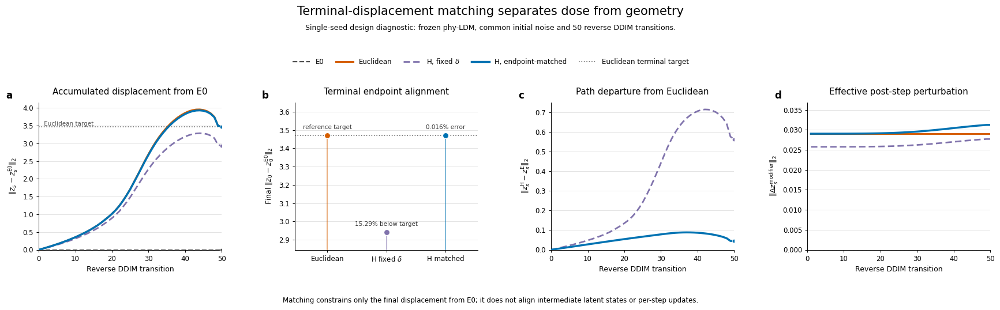

Fixed-versus-matched trajectory diagnostics completed.
PNG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/fixed_vs_matched_trajectory_diagnostics_seed_007.png
PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/fixed_vs_matched_trajectory_diagnostics_seed_007.pdf
Trajectory source data: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_trajectory_diagnostics_seed_007.csv
Endpoint source data: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_endpoint_diagnostics_seed_007.csv
Figure metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_trajectory_diagnostics_seed_007.json


,condition,display_label,terminal_l2_vs_E0,absolute_error_to_target,relative_error_percent
0,Euclidean,Euclidean,3.470928,0.000000,0.000000
1,Hyperbolic fixed delta,H fixed $\delta$,2.940316,0.530612,15.287330
2,Hyperbolic endpoint-matched,H matched,3.470358,0.000571,0.016438


In [27]:
# Cell 27 — Terminal matching separates intervention dose from geometry

from matplotlib.lines import Line2D
import matplotlib as mpl

required_symbols = [
    "CFG",
    "RESULTS",
    "trajectory_results",
    "trajectory_terminal_summary_df",
    "target_terminal_l2",
    "FIXED_MATCHED_TRACE_DIR",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing fixed-versus-matched trajectory objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun Cells 25 and 26 before this cell."
    )

required_trajectory_conditions = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]

missing_conditions = [
    name
    for name in required_trajectory_conditions
    if name not in trajectory_results
]

if missing_conditions:
    raise RuntimeError(
        "Missing trajectory conditions:\n"
        + "\n".join(f"  - {name}" for name in missing_conditions)
    )

if "save_rgb_png_and_pdf" not in globals():
    from PIL import Image

    def save_rgb_png_and_pdf(figure, png_path, pdf_path):
        figure.savefig(
            png_path,
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
            edgecolor="white",
        )

        temporary_rgb_path = png_path.with_name(
            f"{png_path.stem}_temporary_rgb.png"
        )

        with Image.open(png_path) as image:
            image.convert("RGB").save(temporary_rgb_path)

        temporary_rgb_path.replace(png_path)

        figure.savefig(
            pdf_path,
            format="pdf",
            bbox_inches="tight",
            facecolor="white",
            edgecolor="white",
        )


def safe_condition_name(condition_name):
    return (
        condition_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


def post_step_state_distance(result, reference_result):
    states = result["trace_tensors"]["modified_x_prev_scaled"]
    reference_states = reference_result["trace_tensors"][
        "modified_x_prev_scaled"
    ]

    if states.shape != reference_states.shape:
        raise ValueError(
            "Trajectory-state tensor shapes do not match:\n"
            f"  first: {tuple(states.shape)}\n"
            f"  second: {tuple(reference_states.shape)}"
        )

    difference = states - reference_states

    return (
        torch.linalg.vector_norm(
            difference.flatten(start_dim=1),
            dim=1,
        )
        .detach()
        .cpu()
        .numpy()
    )


def prepend_shared_initial_state(values):
    return np.concatenate(
        [
            np.asarray([0.0], dtype=float),
            np.asarray(values, dtype=float),
        ]
    )


def summary_value(condition_name, column_name):
    matching_rows = trajectory_terminal_summary_df[
        trajectory_terminal_summary_df["condition"] == condition_name
    ]

    if len(matching_rows) != 1:
        raise RuntimeError(
            f"Expected one summary row for {condition_name}, "
            f"found {len(matching_rows)}."
        )

    return float(matching_rows.iloc[0][column_name])


e0_trajectory_result = trajectory_results["E0"]
euclidean_trajectory_result = trajectory_results["Euclidean"]
fixed_hyperbolic_trajectory_result = trajectory_results[
    "Hyperbolic fixed delta"
]
matched_hyperbolic_trajectory_result = trajectory_results[
    "Hyperbolic endpoint-matched"
]

num_steps = int(CFG["num_inference_steps"])

if len(e0_trajectory_result["trace"]) != num_steps:
    raise AssertionError(
        "The E0 trajectory does not contain the configured number "
        "of DDIM transitions."
    )

transition_index = np.arange(num_steps + 1)
post_step_index = np.arange(1, num_steps + 1)

trajectory_metrics_df = pd.DataFrame(
    {
        "transition_index": transition_index,
        "reverse_step": np.concatenate(
            [
                np.asarray([-1], dtype=int),
                e0_trajectory_result["trace"][
                    "reverse_step"
                ].to_numpy(dtype=int),
            ]
        ),
        "timestep": np.concatenate(
            [
                np.asarray([np.nan]),
                e0_trajectory_result["trace"][
                    "timestep"
                ].to_numpy(dtype=float),
            ]
        ),
    }
)

for condition_name in required_trajectory_conditions:
    result = trajectory_results[condition_name]
    trace = result["trace"]
    safe_name = safe_condition_name(condition_name)

    trajectory_metrics_df[
        f"{safe_name}_distance_from_e0_l2"
    ] = prepend_shared_initial_state(
        post_step_state_distance(
            result,
            e0_trajectory_result,
        )
    )

    trajectory_metrics_df[
        f"{safe_name}_distance_from_euclidean_l2"
    ] = prepend_shared_initial_state(
        post_step_state_distance(
            result,
            euclidean_trajectory_result,
        )
    )

    trajectory_metrics_df[
        f"{safe_name}_modifier_update_l2"
    ] = np.concatenate(
        [
            np.asarray([np.nan]),
            trace["modifier_update_l2"].to_numpy(dtype=float),
        ]
    )

euclidean_terminal_l2 = summary_value(
    "Euclidean",
    "terminal_latent_l2_vs_E0",
)

fixed_terminal_l2 = summary_value(
    "Hyperbolic fixed delta",
    "terminal_latent_l2_vs_E0",
)

matched_terminal_l2 = summary_value(
    "Hyperbolic endpoint-matched",
    "terminal_latent_l2_vs_E0",
)

fixed_endpoint_error_percent = (
    100.0
    * abs(fixed_terminal_l2 - target_terminal_l2)
    / max(target_terminal_l2, 1e-12)
)

matched_endpoint_error_percent = (
    100.0
    * abs(matched_terminal_l2 - target_terminal_l2)
    / max(target_terminal_l2, 1e-12)
)

endpoint_diagnostic_df = pd.DataFrame(
    [
        {
            "condition": "Euclidean",
            "display_label": "Euclidean",
            "terminal_l2_vs_E0": euclidean_terminal_l2,
            "absolute_error_to_target": 0.0,
            "relative_error_percent": 0.0,
        },
        {
            "condition": "Hyperbolic fixed delta",
            "display_label": "H fixed $\\delta$",
            "terminal_l2_vs_E0": fixed_terminal_l2,
            "absolute_error_to_target": abs(
                fixed_terminal_l2 - target_terminal_l2
            ),
            "relative_error_percent": fixed_endpoint_error_percent,
        },
        {
            "condition": "Hyperbolic endpoint-matched",
            "display_label": "H matched",
            "terminal_l2_vs_E0": matched_terminal_l2,
            "absolute_error_to_target": abs(
                matched_terminal_l2 - target_terminal_l2
            ),
            "relative_error_percent": matched_endpoint_error_percent,
        },
    ]
)

trajectory_metrics_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_trajectory_diagnostics_seed_"
    f"{CFG['reference_seed']:03d}.csv"
)

endpoint_diagnostic_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_endpoint_diagnostics_seed_"
    f"{CFG['reference_seed']:03d}.csv"
)

trajectory_metrics_df.to_csv(
    trajectory_metrics_path,
    index=False,
)

endpoint_diagnostic_df.to_csv(
    endpoint_diagnostic_path,
    index=False,
)

TRAJECTORY_FIGURE_DIR = (
    RESULTS
    / "manuscript"
    / "figures"
    / "endpoint_matching"
)
TRAJECTORY_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

trajectory_diagnostics_png_path = (
    TRAJECTORY_FIGURE_DIR
    / f"fixed_vs_matched_trajectory_diagnostics_seed_"
    f"{CFG['reference_seed']:03d}.png"
)

trajectory_diagnostics_pdf_path = (
    trajectory_diagnostics_png_path.with_suffix(".pdf")
)

condition_labels = {
    "E0": "E0",
    "Euclidean": "Euclidean",
    "Hyperbolic fixed delta": "H, fixed $\\delta$",
    "Hyperbolic endpoint-matched": "H, endpoint-matched",
}

condition_colors = {
    "E0": "#4D4D4D",
    "Euclidean": "#D55E00",
    "Hyperbolic fixed delta": "#8073AC",
    "Hyperbolic endpoint-matched": "#0072B2",
}

condition_line_styles = {
    "E0": "--",
    "Euclidean": "-",
    "Hyperbolic fixed delta": (0, (4, 2)),
    "Hyperbolic endpoint-matched": "-",
}

condition_line_widths = {
    "E0": 1.6,
    "Euclidean": 2.2,
    "Hyperbolic fixed delta": 2.0,
    "Hyperbolic endpoint-matched": 2.5,
}


def style_axis(axis):
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.spines["left"].set_linewidth(0.7)
    axis.spines["bottom"].set_linewidth(0.7)

    axis.grid(
        axis="y",
        color="#D9D9D9",
        linewidth=0.7,
        alpha=0.75,
        zorder=0,
    )

    axis.tick_params(
        axis="both",
        labelsize=8.5,
        width=0.7,
        length=3,
    )


def add_panel_letter(axis, letter):
    axis.text(
        -0.18,
        1.08,
        letter,
        transform=axis.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="top",
    )


plot_style = {
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titleweight": "regular",
    "axes.labelweight": "regular",
}

with mpl.rc_context(plot_style):
    figure = plt.figure(figsize=(17.6, 5.5))

    grid = figure.add_gridspec(
        nrows=1,
        ncols=4,
        left=0.055,
        right=0.992,
        bottom=0.205,
        top=0.670,
        wspace=0.400,
    )

    axes = [
        figure.add_subplot(grid[0, panel_index])
        for panel_index in range(4)
    ]

    # Panel a: accumulated displacement from the common E0 trajectory.
    axis = axes[0]

    for condition_name in required_trajectory_conditions:
        safe_name = safe_condition_name(condition_name)

        axis.plot(
            transition_index,
            trajectory_metrics_df[
                f"{safe_name}_distance_from_e0_l2"
            ],
            color=condition_colors[condition_name],
            linestyle=condition_line_styles[condition_name],
            linewidth=condition_line_widths[condition_name],
            zorder=3,
        )

        axis.scatter(
            [num_steps],
            [
                trajectory_metrics_df[
                    f"{safe_name}_distance_from_e0_l2"
                ].iloc[-1]
            ],
            s=22,
            color=condition_colors[condition_name],
            edgecolor="white",
            linewidth=0.5,
            zorder=4,
        )

    axis.axhline(
        target_terminal_l2,
        color="#6B6B6B",
        linestyle=":",
        linewidth=1.2,
        zorder=1,
    )

    axis.text(
        1.0,
        target_terminal_l2,
        " Euclidean target",
        color="#555555",
        fontsize=7.5,
        va="bottom",
        ha="left",
    )

    axis.set_xlim(0, num_steps)
    axis.set_ylim(bottom=0.0)
    axis.set_xticks([0, 10, 20, 30, 40, 50])
    axis.set_title("Accumulated displacement from E0", pad=10)
    axis.set_xlabel("Reverse DDIM transition")
    axis.set_ylabel(r"$\Vert z_s - z_s^{\mathrm{E0}}\Vert_2$")
    style_axis(axis)
    add_panel_letter(axis, "a")

    # Panel b: endpoint alignment at the final transition.
    axis = axes[1]

    endpoint_positions = np.arange(len(endpoint_diagnostic_df))
    endpoint_values = endpoint_diagnostic_df[
        "terminal_l2_vs_E0"
    ].to_numpy(dtype=float)

    endpoint_span = float(
        endpoint_values.max() - endpoint_values.min()
    )

    endpoint_span = max(endpoint_span, 1e-6)
    endpoint_lower = float(
        endpoint_values.min() - 0.18 * endpoint_span
    )
    endpoint_upper = float(
        endpoint_values.max() + 0.34 * endpoint_span
    )

    endpoint_colors = [
        condition_colors["Euclidean"],
        condition_colors["Hyperbolic fixed delta"],
        condition_colors["Hyperbolic endpoint-matched"],
    ]

    axis.axhline(
        target_terminal_l2,
        color="#6B6B6B",
        linestyle=":",
        linewidth=1.2,
        zorder=1,
    )

    for position, value, color in zip(
        endpoint_positions,
        endpoint_values,
        endpoint_colors,
    ):
        axis.vlines(
            position,
            endpoint_lower,
            value,
            color=color,
            linewidth=1.5,
            alpha=0.50,
            zorder=2,
        )

        axis.scatter(
            position,
            value,
            s=52,
            color=color,
            edgecolor="white",
            linewidth=0.8,
            zorder=4,
        )

    endpoint_annotations = [
        "reference target",
        f"{fixed_endpoint_error_percent:.2f}% below target",
        f"{matched_endpoint_error_percent:.3f}% error",
    ]

    for position, value, annotation in zip(
        endpoint_positions,
        endpoint_values,
        endpoint_annotations,
    ):
        axis.text(
            position,
            value + 0.055 * endpoint_span,
            annotation,
            ha="center",
            va="bottom",
            fontsize=7.5,
            color="#333333",
        )

    axis.set_xlim(-0.55, len(endpoint_positions) - 0.45)
    axis.set_ylim(endpoint_lower, endpoint_upper)
    axis.set_xticks(endpoint_positions)
    axis.set_xticklabels(
        endpoint_diagnostic_df["display_label"].tolist(),
        fontsize=8,
    )
    axis.set_title("Terminal endpoint alignment", pad=10)
    axis.set_ylabel(r"Final $\Vert z_0 - z_0^{\mathrm{E0}}\Vert_2$")
    style_axis(axis)
    add_panel_letter(axis, "b")

    # Panel c: matching the radius from E0 does not align the full path.
    axis = axes[2]

    for condition_name in [
        "Hyperbolic fixed delta",
        "Hyperbolic endpoint-matched",
    ]:
        safe_name = safe_condition_name(condition_name)

        axis.plot(
            transition_index,
            trajectory_metrics_df[
                f"{safe_name}_distance_from_euclidean_l2"
            ],
            color=condition_colors[condition_name],
            linestyle=condition_line_styles[condition_name],
            linewidth=condition_line_widths[condition_name],
            zorder=3,
        )

        axis.scatter(
            [num_steps],
            [
                trajectory_metrics_df[
                    f"{safe_name}_distance_from_euclidean_l2"
                ].iloc[-1]
            ],
            s=22,
            color=condition_colors[condition_name],
            edgecolor="white",
            linewidth=0.5,
            zorder=4,
        )

    axis.set_xlim(0, num_steps)
    axis.set_ylim(bottom=0.0)
    axis.set_xticks([0, 10, 20, 30, 40, 50])
    axis.set_title("Path departure from Euclidean", pad=10)
    axis.set_xlabel("Reverse DDIM transition")
    axis.set_ylabel(r"$\Vert z_s^{\mathrm{H}} - z_s^{\mathrm{E}}\Vert_2$")
    style_axis(axis)
    add_panel_letter(axis, "c")

    # Panel d: actual perturbation magnitude at each transition.
    axis = axes[3]

    for condition_name in [
        "Euclidean",
        "Hyperbolic fixed delta",
        "Hyperbolic endpoint-matched",
    ]:
        safe_name = safe_condition_name(condition_name)

        axis.plot(
            post_step_index,
            trajectory_metrics_df[
                f"{safe_name}_modifier_update_l2"
            ].iloc[1:],
            color=condition_colors[condition_name],
            linestyle=condition_line_styles[condition_name],
            linewidth=condition_line_widths[condition_name],
            zorder=3,
        )

    axis.axhline(
        0.0,
        color="#4D4D4D",
        linestyle="--",
        linewidth=1.0,
        alpha=0.65,
        zorder=1,
    )

    modifier_values = np.concatenate(
        [
            trajectory_metrics_df[
                f"{safe_condition_name}_modifier_update_l2"
            ].iloc[1:].to_numpy(dtype=float)
            for safe_condition_name in [
                safe_condition_name("Euclidean"),
                safe_condition_name("Hyperbolic fixed delta"),
                safe_condition_name(
                    "Hyperbolic endpoint-matched"
                ),
            ]
        ]
    )

    axis.set_xlim(0, num_steps)
    axis.set_ylim(
        0.0,
        float(np.nanmax(modifier_values) * 1.18),
    )
    axis.set_xticks([0, 10, 20, 30, 40, 50])
    axis.set_title("Effective post-step perturbation", pad=10)
    axis.set_xlabel("Reverse DDIM transition")
    axis.set_ylabel(r"$\Vert \Delta z_s^{\mathrm{modifier}}\Vert_2$")
    style_axis(axis)
    add_panel_letter(axis, "d")

    legend_handles = [
        Line2D(
            [0],
            [0],
            color=condition_colors[condition_name],
            linestyle=condition_line_styles[condition_name],
            linewidth=condition_line_widths[condition_name],
            label=condition_labels[condition_name],
        )
        for condition_name in required_trajectory_conditions
    ]

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color="#6B6B6B",
            linestyle=":",
            linewidth=1.2,
            label="Euclidean terminal target",
        )
    )

    figure.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.832),
        ncol=5,
        frameon=False,
        fontsize=8.5,
        handlelength=2.6,
        columnspacing=1.7,
    )

    figure.suptitle(
        "Terminal-displacement matching separates dose from geometry",
        y=0.975,
        fontsize=15,
        fontweight="regular",
    )

    figure.text(
        0.5,
        0.905,
        (
            "Single-seed design diagnostic: frozen phy-LDM, common initial "
            "noise and 50 reverse DDIM transitions."
        ),
        ha="center",
        va="center",
        fontsize=9,
    )

    figure.text(
        0.5,
        0.045,
        (
            "Matching constrains only the final displacement from E0; "
            "it does not align intermediate latent states or per-step updates."
        ),
        ha="center",
        va="center",
        fontsize=8.5,
    )

    save_rgb_png_and_pdf(
        figure,
        trajectory_diagnostics_png_path,
        trajectory_diagnostics_pdf_path,
    )

    plt.show()
    plt.close(figure)

trajectory_diagnostic_metadata_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_trajectory_diagnostics_seed_"
    f"{CFG['reference_seed']:03d}.json"
)

with open(trajectory_diagnostic_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(CFG["reference_seed"]),
            "number_of_reverse_ddim_steps": num_steps,
            "figure_interpretation": (
                "The fixed-coordinate hyperbolic condition is not a "
                "fair geometry comparison because it does not reach the "
                "Euclidean terminal displacement. Subsequent geometry "
                "comparisons use the endpoint-matched condition."
            ),
            "target_terminal_l2_vs_E0": float(target_terminal_l2),
            "fixed_hyperbolic_terminal_l2_vs_E0": float(
                fixed_terminal_l2
            ),
            "fixed_hyperbolic_relative_endpoint_error_percent": float(
                fixed_endpoint_error_percent
            ),
            "matched_hyperbolic_terminal_l2_vs_E0": float(
                matched_terminal_l2
            ),
            "matched_hyperbolic_relative_endpoint_error_percent": float(
                matched_endpoint_error_percent
            ),
            "panels": {
                "a": "Accumulated latent displacement from E0.",
                "b": "Final endpoint alignment to the Euclidean target.",
                "c": (
                    "Hyperbolic path departure from the Euclidean "
                    "trajectory."
                ),
                "d": (
                    "Actual post-step transition-modifier magnitude."
                ),
            },
        },
        file,
        indent=2,
    )

print("Fixed-versus-matched trajectory diagnostics completed.")
print("PNG:", trajectory_diagnostics_png_path)
print("PDF:", trajectory_diagnostics_pdf_path)
print("Trajectory source data:", trajectory_metrics_path)
print("Endpoint source data:", endpoint_diagnostic_path)
print("Figure metadata:", trajectory_diagnostic_metadata_path)

display(endpoint_diagnostic_df)

Selected DDIM timesteps: [980, 800, 600, 400, 200, 0]
Selected reverse steps: [0, 9, 19, 29, 39, 49]
Selected transition numbers: [1, 10, 20, 30, 40, 50]
Decoding predicted-clean frames: E0
Decoding predicted-clean frames: Euclidean
Decoding predicted-clean frames: Hyperbolic fixed delta
Decoding predicted-clean frames: Hyperbolic endpoint-matched


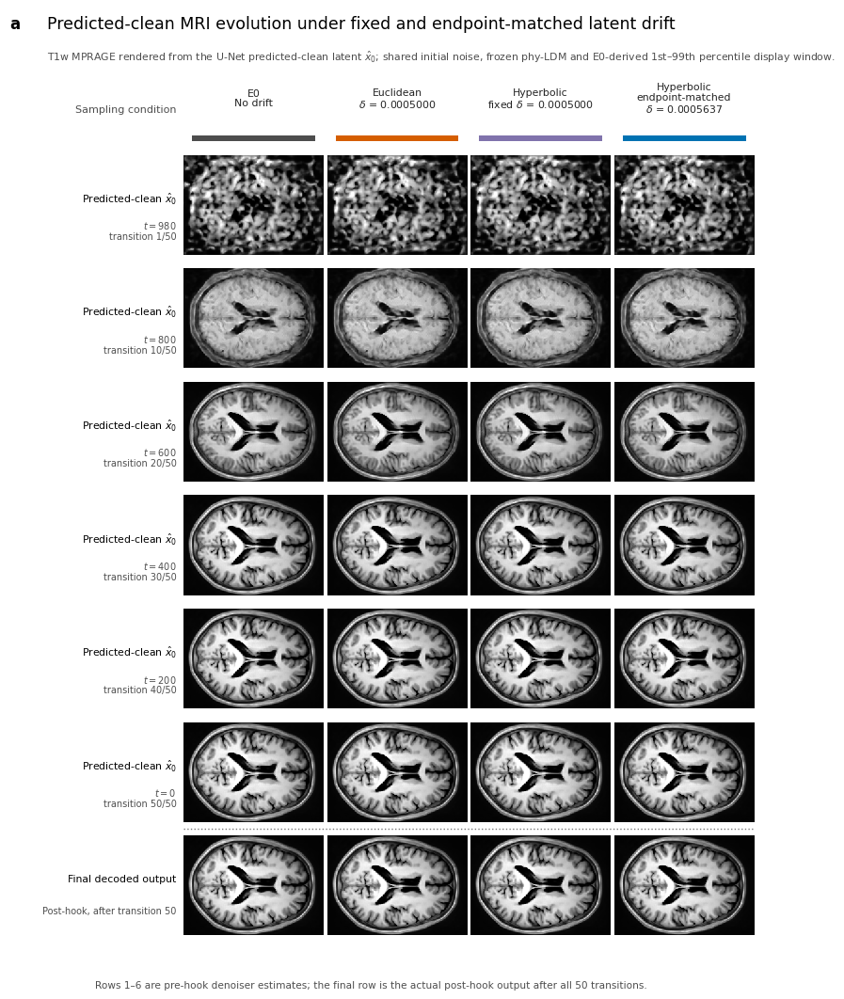

Portrait predicted-clean trajectory visualization completed.
PNG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/fixed_vs_matched_predicted_x0_frames_portrait_seed_007.png
PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/fixed_vs_matched_predicted_x0_frames_portrait_seed_007.pdf
Frame checks: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_predicted_x0_frame_checks_seed_007.csv
Frame tensors: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_predicted_x0_frames_seed_007.pt
Frame metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/endpoint_matching/fixed_vs_matched_trajectory/fixed_vs_matched_predicted_x0_frames_portrait_seed_007.json


,condition,last_predicted_x0_l2_vs_final_latent,last_predicted_x0_max_abs_vs_final_latent,last_predicted_x0_t1w_mae_vs_post_hook,terminal_modifier_update_l2
0,E0,0.000000,0.000000,0.024139,0.000000
1,Euclidean,0.028982,0.000500,0.033065,0.028982
2,Hyperbolic fixed delta,0.027710,0.000593,0.032672,0.027710
3,Hyperbolic endpoint-matched,0.031246,0.000669,0.034033,0.031246


In [28]:
# Cell 28 — Portrait predicted-clean MRI evolution across all trajectories

from pathlib import Path

import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from PIL import Image


required_symbols = [
    "CFG",
    "DEVICE",
    "RESULTS",
    "trajectory_results",
    "ddim_scheduler",
    "autoencoder",
    "scale_factor",
    "denormalize_log_q_map",
    "log_pd_prior_mean",
    "log_t1_prior_mean",
    "log_t2_prior_mean",
    "FIXED_MATCHED_TRACE_DIR",
]

missing_symbols = [
    name
    for name in required_symbols
    if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing trajectory-frame objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun Cells 3–4 and 25–26 before this cell."
    )

required_trajectory_conditions = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]

missing_conditions = [
    name
    for name in required_trajectory_conditions
    if name not in trajectory_results
]

if missing_conditions:
    raise RuntimeError(
        "Missing trajectory conditions:\n"
        + "\n".join(f"  - {name}" for name in missing_conditions)
    )


def save_trajectory_rgb_png_and_pdf(figure, png_path, pdf_path):
    figure.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )

    temporary_rgb_path = png_path.with_name(
        f"{png_path.stem}_temporary_rgb.png"
    )

    with Image.open(png_path) as image:
        image.convert("RGB").save(
            temporary_rgb_path,
            dpi=(600, 600),
        )

    temporary_rgb_path.replace(png_path)

    figure.savefig(
        pdf_path,
        format="pdf",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )


SELECTED_DDIM_TIMESTEPS = [980, 800, 600, 400, 200, 0]

FRAME_TE = 0.003
FRAME_TR = 2.4
FRAME_TI = 1.0

FRAME_LOW_QUANTILE = 0.01
FRAME_HIGH_QUANTILE = 0.99


def timestep_to_int(timestep):
    if torch.is_tensor(timestep):
        return int(timestep.detach().cpu())

    return int(timestep)


scheduler_timesteps = [
    timestep_to_int(timestep)
    for timestep in ddim_scheduler.timesteps
]

timestep_to_reverse_step = {
    timestep: reverse_step
    for reverse_step, timestep in enumerate(scheduler_timesteps)
}

missing_timesteps = [
    timestep
    for timestep in SELECTED_DDIM_TIMESTEPS
    if timestep not in timestep_to_reverse_step
]

if missing_timesteps:
    raise ValueError(
        "Requested timesteps are absent from the DDIM schedule:\n"
        f"{missing_timesteps}"
    )

selected_reverse_steps = [
    timestep_to_reverse_step[timestep]
    for timestep in SELECTED_DDIM_TIMESTEPS
]

selected_transition_numbers = [
    reverse_step + 1
    for reverse_step in selected_reverse_steps
]

print("Selected DDIM timesteps:", SELECTED_DDIM_TIMESTEPS)
print("Selected reverse steps:", selected_reverse_steps)
print(
    "Selected transition numbers:",
    selected_transition_numbers,
)


def prior_on_device(prior, reference_tensor):
    return torch.as_tensor(
        prior,
        device=reference_tensor.device,
        dtype=reference_tensor.dtype,
    )


@torch.no_grad()
def render_mprage_batch(q_maps, te, tr, ti):
    pd_map = q_maps[:, 0]
    t1_map = q_maps[:, 1]
    t2_map = q_maps[:, 2]

    return (
        pd_map
        * (
            1.0
            - (
                2.0 * torch.exp(-ti / t1_map)
            )
            / (
                1.0 + torch.exp(-tr / t1_map)
            )
        )
        * torch.exp(-te / t2_map)
    )


@torch.no_grad()
def physical_outputs_from_normalized_q_maps(norm_log_q_maps):
    log_q_maps = denormalize_log_q_map(
        norm_log_q_map=norm_log_q_maps,
        log_pd_mean=prior_on_device(
            log_pd_prior_mean,
            norm_log_q_maps,
        ),
        log_t1_mean=prior_on_device(
            log_t1_prior_mean,
            norm_log_q_maps,
        ),
        log_t2_mean=prior_on_device(
            log_t2_prior_mean,
            norm_log_q_maps,
        ),
    )

    q_maps = torch.exp(log_q_maps)

    if not bool(torch.isfinite(log_q_maps).all()):
        raise FloatingPointError(
            "Non-finite log q-map values were produced."
        )

    if not bool(torch.isfinite(q_maps).all()):
        raise FloatingPointError(
            "Non-finite physical q-map values were produced."
        )

    t1w_mprage = render_mprage_batch(
        q_maps=q_maps,
        te=FRAME_TE,
        tr=FRAME_TR,
        ti=FRAME_TI,
    )

    if not bool(torch.isfinite(t1w_mprage).all()):
        raise FloatingPointError(
            "Non-finite T1w MPRAGE values were produced."
        )

    return {
        "norm_log_q_maps": norm_log_q_maps,
        "log_q_maps": log_q_maps,
        "q_maps": q_maps,
        "mri_images": {
            "T1w MPRAGE": t1w_mprage,
        },
    }


@torch.no_grad()
def decode_predicted_clean_frames(result, reverse_steps):
    predicted_x0_trace = result["trace_tensors"][
        "predicted_x0_scaled"
    ]

    if predicted_x0_trace.ndim != 5:
        raise ValueError(
            "Expected predicted_x0_scaled with shape "
            "[steps, batch, channels, height, width]."
        )

    if predicted_x0_trace.shape[1] != 1:
        raise ValueError(
            "This visualization currently requires batch size 1."
        )

    selected_predicted_x0 = predicted_x0_trace[reverse_steps]

    if selected_predicted_x0.ndim != 5:
        raise ValueError(
            "Selected predicted-clean states must have shape "
            "[frames, batch, channels, height, width]."
        )

    scaled_latents = selected_predicted_x0[:, 0].contiguous().to(DEVICE)

    if scaled_latents.ndim != 4:
        raise ValueError(
            "VAE input must have shape [frames, channels, height, width]."
        )

    norm_log_q_maps = autoencoder.decode_stage_2_outputs(
        scaled_latents / scale_factor
    )

    predicted_clean_outputs = physical_outputs_from_normalized_q_maps(
        norm_log_q_maps
    )

    final_predicted_x0_scaled = (
        predicted_x0_trace[-1, 0].detach().to(DEVICE)
    )

    final_scaled_latent = result["final_scaled_latent"].detach().to(
        DEVICE
    )

    if final_scaled_latent.ndim == 4:
        if final_scaled_latent.shape[0] != 1:
            raise ValueError(
                "Expected a singleton final latent batch."
            )

        final_scaled_latent = final_scaled_latent[0]

    final_post_hook_outputs = physical_outputs_from_normalized_q_maps(
        result["norm_log_q_maps"].detach().to(DEVICE)
    )

    pre_hook_final_t1w = predicted_clean_outputs["mri_images"][
        "T1w MPRAGE"
    ][-1]

    post_hook_final_t1w = final_post_hook_outputs["mri_images"][
        "T1w MPRAGE"
    ][0]

    return {
        "predicted_clean": {
            "norm_log_q_maps": predicted_clean_outputs[
                "norm_log_q_maps"
            ].detach().cpu(),
            "log_q_maps": predicted_clean_outputs[
                "log_q_maps"
            ].detach().cpu(),
            "q_maps": predicted_clean_outputs[
                "q_maps"
            ].detach().cpu(),
            "mri_images": {
                name: image.detach().cpu()
                for name, image in predicted_clean_outputs[
                    "mri_images"
                ].items()
            },
        },
        "final_post_hook": {
            "norm_log_q_maps": final_post_hook_outputs[
                "norm_log_q_maps"
            ].detach().cpu(),
            "log_q_maps": final_post_hook_outputs[
                "log_q_maps"
            ].detach().cpu(),
            "q_maps": final_post_hook_outputs[
                "q_maps"
            ].detach().cpu(),
            "mri_images": {
                name: image.detach().cpu()
                for name, image in final_post_hook_outputs[
                    "mri_images"
                ].items()
            },
        },
        "last_predicted_x0_l2_vs_final_latent": float(
            torch.linalg.vector_norm(
                final_predicted_x0_scaled - final_scaled_latent
            )
            .detach()
            .cpu()
        ),
        "last_predicted_x0_max_abs_vs_final_latent": float(
            torch.max(
                torch.abs(
                    final_predicted_x0_scaled - final_scaled_latent
                )
            )
            .detach()
            .cpu()
        ),
        "last_predicted_x0_t1w_mae_vs_post_hook": float(
            torch.mean(
                torch.abs(pre_hook_final_t1w - post_hook_final_t1w)
            )
            .detach()
            .cpu()
        ),
        "terminal_modifier_update_l2": float(
            result["trace"].iloc[-1]["modifier_update_l2"]
        ),
    }


trajectory_frame_outputs = {}
frame_check_rows = []

for condition_name in required_trajectory_conditions:
    print(f"Decoding predicted-clean frames: {condition_name}")

    decoded_frames = decode_predicted_clean_frames(
        trajectory_results[condition_name],
        selected_reverse_steps,
    )

    trajectory_frame_outputs[condition_name] = decoded_frames

    frame_check_rows.append(
        {
            "condition": condition_name,
            "last_predicted_x0_l2_vs_final_latent": decoded_frames[
                "last_predicted_x0_l2_vs_final_latent"
            ],
            "last_predicted_x0_max_abs_vs_final_latent": decoded_frames[
                "last_predicted_x0_max_abs_vs_final_latent"
            ],
            "last_predicted_x0_t1w_mae_vs_post_hook": decoded_frames[
                "last_predicted_x0_t1w_mae_vs_post_hook"
            ],
            "terminal_modifier_update_l2": decoded_frames[
                "terminal_modifier_update_l2"
            ],
        }
    )

frame_check_df = pd.DataFrame(frame_check_rows)

e0_final_t1w = trajectory_frame_outputs["E0"][
    "final_post_hook"
]["mri_images"]["T1w MPRAGE"][0]

reference_t1w = (
    e0_final_t1w.detach().float().cpu().numpy()
)

reference_values = reference_t1w[np.isfinite(reference_t1w)]

if reference_values.size == 0:
    raise FloatingPointError(
        "No finite E0 final T1w values are available."
    )

frame_vmin, frame_vmax = np.quantile(
    reference_values,
    [FRAME_LOW_QUANTILE, FRAME_HIGH_QUANTILE],
)

frame_vmin = float(frame_vmin)
frame_vmax = float(frame_vmax)

if frame_vmax <= frame_vmin:
    frame_vmax = frame_vmin + 1e-6

condition_labels = {
    "E0": "E0\nNo drift",
    "Euclidean": "Euclidean\n$\\delta$ = 0.0005000",
    "Hyperbolic fixed delta": (
        "Hyperbolic\nfixed $\\delta$ = 0.0005000"
    ),
    "Hyperbolic endpoint-matched": (
        "Hyperbolic\nendpoint-matched\n"
        "$\\delta$ = 0.0005637"
    ),
}

condition_colors = {
    "E0": "#4D4D4D",
    "Euclidean": "#D55E00",
    "Hyperbolic fixed delta": "#8073AC",
    "Hyperbolic endpoint-matched": "#0072B2",
}

frame_row_labels = [
    (
        r"Predicted-clean $\hat{x}_0$",
        f"$t = {timestep}$\ntransition {transition}/50",
    )
    for timestep, transition in zip(
        SELECTED_DDIM_TIMESTEPS,
        selected_transition_numbers,
    )
]

frame_row_labels.append(
    (
        "Final decoded output",
        "Post-hook, after transition 50",
    )
)

FRAME_FIGURE_DIR = (
    RESULTS
    / "manuscript"
    / "figures"
    / "endpoint_matching"
)

FRAME_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

seed_tag = f"{CFG['reference_seed']:03d}"

frame_figure_png_path = (
    FRAME_FIGURE_DIR
    / (
        "fixed_vs_matched_predicted_x0_frames_portrait_"
        f"seed_{seed_tag}.png"
    )
)

frame_figure_pdf_path = frame_figure_png_path.with_suffix(".pdf")

plot_style = {
    "font.family": "DejaVu Sans",
    "font.size": 8.5,
    "axes.titleweight": "regular",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

with mpl.rc_context(plot_style):
    # Portrait, A4-safe layout:
    # columns = sampling conditions; rows = DDIM transitions plus final output.
    figure = plt.figure(figsize=(8.27, 10.9))

    grid = figure.add_gridspec(
        nrows=2 + len(frame_row_labels),
        ncols=1 + len(required_trajectory_conditions),
        height_ratios=[0.55, 0.66] + [1.0] * len(frame_row_labels),
        width_ratios=[1.22] + [1.0] * len(required_trajectory_conditions),
        left=0.035,
        right=0.992,
        bottom=0.065,
        top=0.972,
        wspace=0.025,
        hspace=0.072,
    )

    # Dedicated title area: no title overlaps with image panels.
    title_axis = figure.add_subplot(grid[0, :])
    title_axis.axis("off")

    title_axis.text(
        0.00,
        0.74,
        "a",
        transform=title_axis.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="center",
    )

    title_axis.text(
        0.05,
        0.74,
        (
            "Predicted-clean MRI evolution under fixed and "
            "endpoint-matched latent drift"
        ),
        transform=title_axis.transAxes,
        fontsize=12.5,
        fontweight="regular",
        ha="left",
        va="center",
    )

    title_axis.text(
        0.05,
        0.18,
        (
            "T1w MPRAGE rendered from the U-Net predicted-clean latent "
            r"$\hat{x}_0$; shared initial noise, frozen phy-LDM and "
            "E0-derived 1st–99th percentile display window."
        ),
        transform=title_axis.transAxes,
        fontsize=7.8,
        color="#4D4D4D",
        ha="left",
        va="center",
    )

    # Upper-left orientation label.
    orientation_axis = figure.add_subplot(grid[1, 0])
    orientation_axis.axis("off")

    orientation_axis.text(
        0.98,
        0.50,
        "Sampling condition",
        transform=orientation_axis.transAxes,
        fontsize=8.0,
        color="#4D4D4D",
        ha="right",
        va="center",
    )

    condition_header_axes = []

    for column_index, condition_name in enumerate(
        required_trajectory_conditions
    ):
        header_axis = figure.add_subplot(grid[1, column_index + 1])
        header_axis.axis("off")

        header_axis.text(
            0.50,
            0.66,
            condition_labels[condition_name],
            transform=header_axis.transAxes,
            fontsize=7.8,
            ha="center",
            va="center",
            linespacing=1.10,
            color="#222222",
        )

        # The original condition colours are retained as thin header stripes.
        header_axis.add_patch(
            Rectangle(
                (0.06, 0.05),
                0.88,
                0.075,
                transform=header_axis.transAxes,
                facecolor=condition_colors[condition_name],
                edgecolor="none",
                clip_on=False,
            )
        )

        condition_header_axes.append(header_axis)

    image_axes = np.empty(
        (
            len(frame_row_labels),
            len(required_trajectory_conditions),
        ),
        dtype=object,
    )

    for row_index, (row_title, row_detail) in enumerate(
        frame_row_labels
    ):
        row_label_axis = figure.add_subplot(grid[row_index + 2, 0])
        row_label_axis.axis("off")

        row_label_axis.text(
            0.98,
            0.56,
            row_title,
            transform=row_label_axis.transAxes,
            fontsize=7.8,
            fontweight="medium",
            ha="right",
            va="center",
        )

        row_label_axis.text(
            0.98,
            0.26,
            row_detail,
            transform=row_label_axis.transAxes,
            fontsize=7.0,
            color="#4D4D4D",
            ha="right",
            va="center",
            linespacing=1.10,
        )

        for column_index, condition_name in enumerate(
            required_trajectory_conditions
        ):
            image_axis = figure.add_subplot(
                grid[row_index + 2, column_index + 1]
            )

            predicted_t1w_frames = trajectory_frame_outputs[
                condition_name
            ]["predicted_clean"]["mri_images"]["T1w MPRAGE"]

            final_post_hook_t1w = trajectory_frame_outputs[
                condition_name
            ]["final_post_hook"]["mri_images"]["T1w MPRAGE"][0]

            if row_index < len(SELECTED_DDIM_TIMESTEPS):
                image = predicted_t1w_frames[row_index]
            else:
                image = final_post_hook_t1w

            image_np = (
                image.detach()
                .float()
                .cpu()
                .numpy()
            )

            image_axis.imshow(
                image_np,
                cmap="gray",
                vmin=frame_vmin,
                vmax=frame_vmax,
                interpolation="nearest",
            )

            image_axis.set_axis_off()

            image_axes[row_index, column_index] = image_axis

    figure.canvas.draw()

    # Separate predicted-clean frames from the actual final post-hook output.
    last_prediction_bbox = image_axes[-2, 0].get_position()
    final_output_bbox = image_axes[-1, 0].get_position()

    separator_y = 0.5 * (
        last_prediction_bbox.y0 + final_output_bbox.y1
    )

    figure.add_artist(
        Line2D(
            [
                image_axes[0, 0].get_position().x0,
                image_axes[0, -1].get_position().x1,
            ],
            [separator_y, separator_y],
            transform=figure.transFigure,
            color="#6B6B6B",
            linewidth=1.0,
            linestyle=":",
            alpha=0.90,
        )
    )

    figure.text(
        0.50,
        0.020,
        (
            "Rows 1–6 are pre-hook denoiser estimates; the final row is "
            "the actual post-hook output after all 50 transitions."
        ),
        ha="center",
        va="center",
        fontsize=7.6,
        color="#4D4D4D",
    )

    save_trajectory_rgb_png_and_pdf(
        figure,
        frame_figure_png_path,
        frame_figure_pdf_path,
    )

    plt.show()
    plt.close(figure)

frame_check_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_predicted_x0_frame_checks_seed_{seed_tag}.csv"
)

frame_tensor_path = (
    FIXED_MATCHED_TRACE_DIR
    / f"fixed_vs_matched_predicted_x0_frames_seed_{seed_tag}.pt"
)

frame_metadata_path = (
    FIXED_MATCHED_TRACE_DIR
    / (
        "fixed_vs_matched_predicted_x0_frames_portrait_"
        f"seed_{seed_tag}.json"
    )
)

frame_check_df.to_csv(
    frame_check_path,
    index=False,
)

torch.save(
    {
        "seed": int(CFG["reference_seed"]),
        "selected_ddim_timesteps": SELECTED_DDIM_TIMESTEPS,
        "selected_reverse_steps": selected_reverse_steps,
        "selected_transition_numbers": selected_transition_numbers,
        "display_window": {
            "vmin": frame_vmin,
            "vmax": frame_vmax,
            "reference": (
                "E0 final T1w MPRAGE, 1st–99th percentiles"
            ),
        },
        "frame_outputs": trajectory_frame_outputs,
    },
    frame_tensor_path,
)

with open(frame_metadata_path, "w") as file:
    json.dump(
        {
            "seed": int(CFG["reference_seed"]),
            "contrast": "T1w MPRAGE",
            "figure_layout": (
                "Portrait layout: conditions are columns and "
                "predicted-clean transitions are rows."
            ),
            "renderer": {
                "te": FRAME_TE,
                "tr": FRAME_TR,
                "ti": FRAME_TI,
            },
            "selected_ddim_timesteps": SELECTED_DDIM_TIMESTEPS,
            "selected_reverse_steps": selected_reverse_steps,
            "final_row_definition": (
                "Decoded final latent after the final post-step drift hook."
            ),
            "predicted_clean_rows_definition": (
                "U-Net predicted-clean latent before the current "
                "post-step drift hook."
            ),
            "display_window": {
                "vmin": frame_vmin,
                "vmax": frame_vmax,
                "reference": (
                    "E0 final T1w MPRAGE, 1st–99th percentiles"
                ),
            },
        },
        file,
        indent=2,
    )

print("Portrait predicted-clean trajectory visualization completed.")
print("PNG:", frame_figure_png_path)
print("PDF:", frame_figure_pdf_path)
print("Frame checks:", frame_check_path)
print("Frame tensors:", frame_tensor_path)
print("Frame metadata:", frame_metadata_path)

display(frame_check_df)

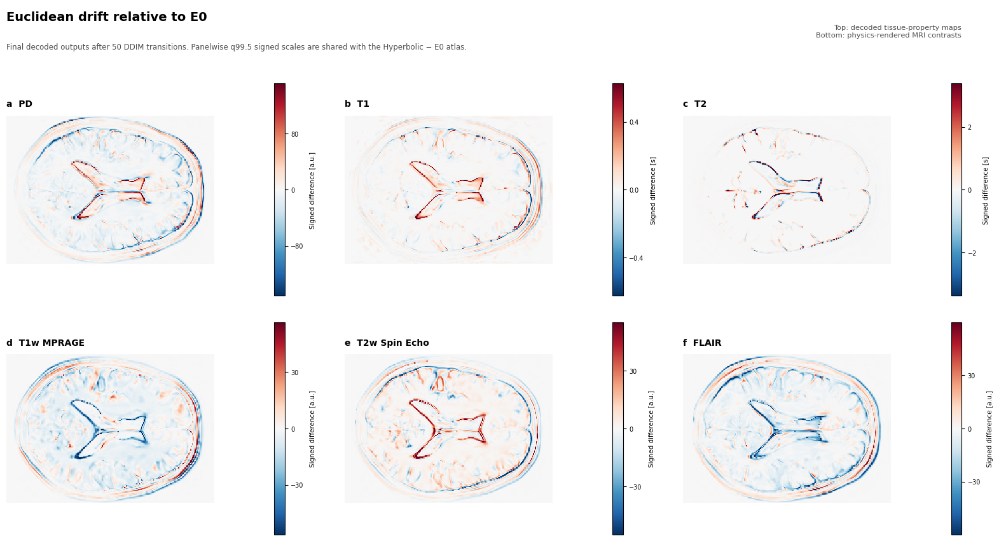

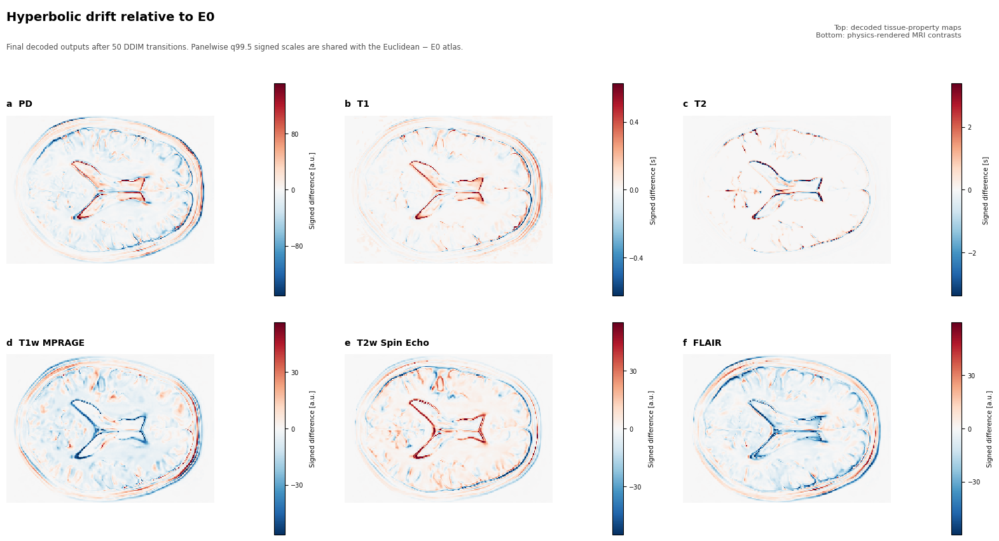

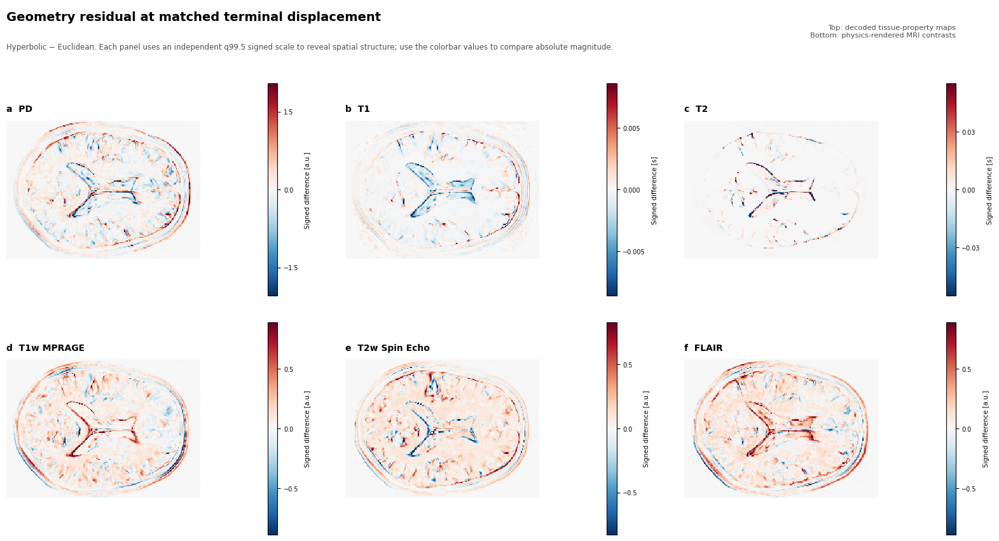

Euclidean − E0 atlas saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/endpoint_matched_euclidean_minus_e0_atlas_seed_007.png
Euclidean − E0 vector PDF saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/endpoint_matched_euclidean_minus_e0_atlas_seed_007.pdf
Hyperbolic − E0 atlas saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/endpoint_matched_hyperbolic_minus_e0_atlas_seed_007.png
Hyperbolic − E0 vector PDF saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/endpoint_matched_hyperbolic_minus_e0_atlas_seed_007.pdf
Hyperbolic − Euclidean atlas saved to: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/endpoint_matching/endpoint_matched_hyperbolic_minus_euclidean_atlas_seed_007.png
Hyperbolic − Euclide

,output,foreground_pixel_count,Euclidean_MAE_vs_E0,Hyperbolic_MAE_vs_E0,Hyperbolic_MAE_vs_Euclidean,H_minus_E_percent_of_Euclidean_drift,E0_change_spatial_correlation
0,PD [a.u.],28672,13.802092,13.683672,0.225525,1.633993,0.999938
1,T1 [s],28672,0.040505,0.040082,0.000671,1.655399,0.999947
2,T2 [s],28672,0.110913,0.109784,0.001922,1.732973,0.999928
3,T1w MPRAGE,28672,6.221061,6.144864,0.110899,1.782638,0.999929
4,T2w Spin Echo,28672,4.863914,4.836486,0.107304,2.206125,0.999926
5,FLAIR,28672,6.473039,6.394837,0.125379,1.936948,0.999921


In [29]:
# Cell 29 — Three unified endpoint-matched signed-difference atlases

import json
from pathlib import Path

import matplotlib as mpl
from matplotlib.ticker import MaxNLocator
from PIL import Image


CHANGE_DISPLAY_QUANTILE = 0.995

required_endpoint_objects = [
    "CFG",
    "RESULTS",
    "endpoint_matched_comparison_outputs",
]

missing_endpoint_objects = [
    name
    for name in required_endpoint_objects
    if name not in globals()
]

if missing_endpoint_objects:
    raise RuntimeError(
        "Missing endpoint-matched comparison objects:\n"
        + "\n".join(f"  - {name}" for name in missing_endpoint_objects)
        + "\nRun the endpoint-matching and endpoint-matched comparison cells first."
    )

required_output_keys = [
    "E0",
    "Euclidean",
    "Hyperbolic endpoint-matched",
]

available_output_keys = set(endpoint_matched_comparison_outputs)

missing_output_keys = [
    key
    for key in required_output_keys
    if key not in available_output_keys
]

if missing_output_keys:
    raise KeyError(
        "Endpoint-matched outputs are incomplete.\n"
        f"Missing: {missing_output_keys}\n"
        f"Available: {sorted(available_output_keys)}"
    )

e0_seed_for_difference = int(
    globals().get(
        "e0_seed",
        CFG["reference_seed"],
    )
)

DIFFERENCE_FIGURE_DIR = (
    RESULTS / "manuscript" / "figures" / "endpoint_matching"
)

DIFFERENCE_DATA_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "endpoint_matching"
    / "signed_difference_maps"
)

DIFFERENCE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DIFFERENCE_DATA_DIR.mkdir(parents=True, exist_ok=True)

e0_outputs = endpoint_matched_comparison_outputs["E0"]
euclidean_outputs = endpoint_matched_comparison_outputs["Euclidean"]
hyperbolic_outputs = endpoint_matched_comparison_outputs[
    "Hyperbolic endpoint-matched"
]


def tensor_to_2d_numpy(value):
    if torch.is_tensor(value):
        array = value.detach().float().cpu().numpy()
    else:
        array = np.asarray(value, dtype=np.float64)

    array = np.squeeze(array)

    if array.ndim != 2:
        raise ValueError(
            f"Expected a 2D image after squeeze, got shape {array.shape}."
        )

    return array


def extract_endpoint_image(outputs, source_name, channel_or_name):
    if source_name == "q_maps":
        q_maps = outputs["q_maps"]

        if q_maps.ndim == 4:
            image = q_maps[0, int(channel_or_name)]
        elif q_maps.ndim == 3:
            image = q_maps[int(channel_or_name)]
        else:
            raise ValueError(
                "Expected q-maps with shape [C, H, W] or [B, C, H, W], "
                f"got {tuple(q_maps.shape)}."
            )

    elif source_name == "mri_images":
        image = outputs["mri_images"][channel_or_name]

    else:
        raise ValueError(f"Unsupported output source: {source_name}")

    return tensor_to_2d_numpy(image)


def robust_symmetric_limit(images, valid_mask, quantile):
    absolute_values = []

    for image in images:
        absolute_values.append(np.abs(image[valid_mask]))

    absolute_values = np.concatenate(absolute_values)
    absolute_values = absolute_values[np.isfinite(absolute_values)]

    if absolute_values.size == 0:
        raise FloatingPointError(
            "No finite values were available for signed-difference scaling."
        )

    return max(float(np.quantile(absolute_values, quantile)), 1e-12)


def safe_change_correlation(first_change, second_change, valid_mask):
    first_values = first_change[valid_mask]
    second_values = second_change[valid_mask]

    if first_values.size < 2:
        return np.nan

    if (
        np.std(first_values) < 1e-12
        or np.std(second_values) < 1e-12
    ):
        return np.nan

    return float(np.corrcoef(first_values, second_values)[0, 1])


def save_rgb_png_and_pdf(figure, png_path, pdf_path):
    figure.savefig(
        png_path,
        dpi=600,
        facecolor="white",
        edgecolor="white",
        bbox_inches="tight",
    )

    with Image.open(png_path) as saved_image:
        saved_image.convert("RGB").save(
            png_path,
            dpi=(600, 600),
        )

    figure.savefig(
        pdf_path,
        dpi=600,
        facecolor="white",
        edgecolor="white",
        bbox_inches="tight",
    )


difference_panel_specs = [
    {
        "output": "PD [a.u.]",
        "short_name": "PD",
        "source": "q_maps",
        "selector": 0,
        "unit": "a.u.",
    },
    {
        "output": "T1 [s]",
        "short_name": "T1",
        "source": "q_maps",
        "selector": 1,
        "unit": "s",
    },
    {
        "output": "T2 [s]",
        "short_name": "T2",
        "source": "q_maps",
        "selector": 2,
        "unit": "s",
    },
    {
        "output": "T1w MPRAGE",
        "short_name": "T1w MPRAGE",
        "source": "mri_images",
        "selector": "T1w MPRAGE",
        "unit": "a.u.",
    },
    {
        "output": "T2w Spin Echo",
        "short_name": "T2w Spin Echo",
        "source": "mri_images",
        "selector": "T2w Spin Echo",
        "unit": "a.u.",
    },
    {
        "output": "FLAIR",
        "short_name": "FLAIR",
        "source": "mri_images",
        "selector": "FLAIR",
        "unit": "a.u.",
    },
]

e0_pd_map = extract_endpoint_image(
    e0_outputs,
    source_name="q_maps",
    channel_or_name=0,
)

if "foreground_mask" in globals():
    if torch.is_tensor(foreground_mask):
        tissue_mask = (
            foreground_mask.detach().cpu().numpy().astype(bool)
        )
    else:
        tissue_mask = np.asarray(foreground_mask, dtype=bool)
else:
    finite_pd_values = e0_pd_map[np.isfinite(e0_pd_map)]

    if finite_pd_values.size == 0:
        raise FloatingPointError(
            "No finite E0 PD values were available for tissue-mask construction."
        )

    pd_threshold = float(
        np.quantile(
            finite_pd_values,
            CFG["foreground_pd_quantile"],
        )
    )

    tissue_mask = (
        np.isfinite(e0_pd_map)
        & (e0_pd_map > pd_threshold)
    )

if tissue_mask.shape != e0_pd_map.shape:
    raise ValueError(
        "Foreground-mask shape does not match output shape: "
        f"{tissue_mask.shape} versus {e0_pd_map.shape}."
    )

if int(tissue_mask.sum()) < 2:
    raise RuntimeError(
        "The foreground mask contains too few pixels for spatial diagnostics."
    )

endpoint_difference_arrays = {}
difference_metric_rows = []
difference_scale_rows = []

for specification in difference_panel_specs:
    output_name = specification["output"]

    e0_image = extract_endpoint_image(
        e0_outputs,
        specification["source"],
        specification["selector"],
    )

    euclidean_image = extract_endpoint_image(
        euclidean_outputs,
        specification["source"],
        specification["selector"],
    )

    hyperbolic_image = extract_endpoint_image(
        hyperbolic_outputs,
        specification["source"],
        specification["selector"],
    )

    if not (
        e0_image.shape
        == euclidean_image.shape
        == hyperbolic_image.shape
        == tissue_mask.shape
    ):
        raise ValueError(
            f"Image-shape mismatch for {output_name}: "
            f"E0={e0_image.shape}, "
            f"Euclidean={euclidean_image.shape}, "
            f"Hyperbolic={hyperbolic_image.shape}, "
            f"mask={tissue_mask.shape}."
        )

    euclidean_minus_e0 = euclidean_image - e0_image
    hyperbolic_minus_e0 = hyperbolic_image - e0_image
    hyperbolic_minus_euclidean = hyperbolic_image - euclidean_image

    valid_mask = (
        tissue_mask
        & np.isfinite(euclidean_minus_e0)
        & np.isfinite(hyperbolic_minus_e0)
        & np.isfinite(hyperbolic_minus_euclidean)
    )

    if int(valid_mask.sum()) < 2:
        raise RuntimeError(
            f"Too few finite foreground pixels for {output_name}."
        )

    euclidean_values = euclidean_minus_e0[valid_mask]
    hyperbolic_values = hyperbolic_minus_e0[valid_mask]
    geometry_values = hyperbolic_minus_euclidean[valid_mask]

    # The same limit is deliberately used in the E−E0 and H−E0 figures.
    shared_drift_limit = robust_symmetric_limit(
        images=[
            euclidean_minus_e0,
            hyperbolic_minus_e0,
        ],
        valid_mask=valid_mask,
        quantile=CHANGE_DISPLAY_QUANTILE,
    )

    # The H−E residual receives its own scale in the third figure.
    geometry_residual_limit = robust_symmetric_limit(
        images=[hyperbolic_minus_euclidean],
        valid_mask=valid_mask,
        quantile=CHANGE_DISPLAY_QUANTILE,
    )

    euclidean_mae = float(np.mean(np.abs(euclidean_values)))
    hyperbolic_mae = float(np.mean(np.abs(hyperbolic_values)))
    geometry_mae = float(np.mean(np.abs(geometry_values)))

    geometry_percent_of_euclidean_drift = (
        100.0 * geometry_mae / euclidean_mae
        if euclidean_mae > 1e-12
        else np.nan
    )

    endpoint_difference_arrays[output_name] = {
        "euclidean_minus_e0": euclidean_minus_e0,
        "hyperbolic_minus_e0": hyperbolic_minus_e0,
        "hyperbolic_minus_euclidean": hyperbolic_minus_euclidean,
        "valid_mask": valid_mask,
        "shared_drift_limit": shared_drift_limit,
        "geometry_residual_limit": geometry_residual_limit,
    }

    difference_metric_rows.append(
        {
            "output": output_name,
            "foreground_pixel_count": int(valid_mask.sum()),
            "Euclidean_MAE_vs_E0": euclidean_mae,
            "Hyperbolic_MAE_vs_E0": hyperbolic_mae,
            "Hyperbolic_MAE_vs_Euclidean": geometry_mae,
            "H_minus_E_percent_of_Euclidean_drift": (
                geometry_percent_of_euclidean_drift
            ),
            "E0_change_spatial_correlation": safe_change_correlation(
                euclidean_minus_e0,
                hyperbolic_minus_e0,
                valid_mask,
            ),
        }
    )

    difference_scale_rows.append(
        {
            "output": output_name,
            "shared_E_minus_E0_and_H_minus_E0_limit": (
                shared_drift_limit
            ),
            "independent_H_minus_E_limit": geometry_residual_limit,
            "display_quantile": CHANGE_DISPLAY_QUANTILE,
        }
    )

endpoint_difference_metrics_df = pd.DataFrame(difference_metric_rows)
endpoint_difference_scales_df = pd.DataFrame(difference_scale_rows)

# Compatibility alias for later cells.
difference_map_metrics_df = endpoint_difference_metrics_df.copy()

difference_metrics_path = (
    DIFFERENCE_DATA_DIR
    / f"endpoint_matched_difference_metrics_seed_{e0_seed_for_difference:03d}.csv"
)

difference_scales_path = (
    DIFFERENCE_DATA_DIR
    / f"endpoint_matched_difference_scales_seed_{e0_seed_for_difference:03d}.csv"
)

endpoint_difference_metrics_df.to_csv(
    difference_metrics_path,
    index=False,
)

endpoint_difference_scales_df.to_csv(
    difference_scales_path,
    index=False,
)

difference_arrays_path = (
    DIFFERENCE_DATA_DIR
    / f"endpoint_matched_difference_arrays_seed_{e0_seed_for_difference:03d}.npz"
)

array_payload = {
    "tissue_mask": tissue_mask.astype(np.uint8),
}

for output_name, arrays in endpoint_difference_arrays.items():
    safe_name = (
        output_name.lower()
        .replace(" ", "_")
        .replace("[", "")
        .replace("]", "")
        .replace(".", "")
    )

    array_payload[f"{safe_name}_euclidean_minus_e0"] = arrays[
        "euclidean_minus_e0"
    ]
    array_payload[f"{safe_name}_hyperbolic_minus_e0"] = arrays[
        "hyperbolic_minus_e0"
    ]
    array_payload[f"{safe_name}_hyperbolic_minus_euclidean"] = arrays[
        "hyperbolic_minus_euclidean"
    ]

np.savez_compressed(
    difference_arrays_path,
    **array_payload,
)

difference_metadata_path = (
    DIFFERENCE_DATA_DIR
    / f"endpoint_matched_difference_metadata_seed_{e0_seed_for_difference:03d}.json"
)

with open(difference_metadata_path, "w") as file:
    json.dump(
        {
            "seed": e0_seed_for_difference,
            "display_quantile": CHANGE_DISPLAY_QUANTILE,
            "mask_definition": (
                "PD-derived E0 foreground mask shared across all panels"
            ),
            "fair_scale_statement": (
                "Corresponding Euclidean−E0 and Hyperbolic−E0 panels "
                "share the same symmetric signed display scale."
            ),
            "geometry_residual_statement": (
                "Hyperbolic−Euclidean residual panels use independent "
                "symmetric scales to reveal spatial structure."
            ),
        },
        file,
        indent=2,
    )


difference_cmap = mpl.colormaps["RdBu_r"].copy()
difference_cmap.set_bad("#F7F7F7")


def render_difference_atlas(
    difference_key,
    scale_key,
    figure_title,
    figure_subtitle,
    filename_stem,
):
    panel_letters = ["a", "b", "c", "d", "e", "f"]

    with mpl.rc_context(
        {
            "font.family": "DejaVu Sans",
            "font.size": 8.5,
            "axes.titleweight": "regular",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    ):
        figure = plt.figure(
            figsize=(15.6, 8.4),
            constrained_layout=True,
        )

        grid = figure.add_gridspec(
            nrows=3,
            ncols=6,
            height_ratios=[0.24, 1.0, 1.0],
            width_ratios=[1.0, 0.050, 1.0, 0.050, 1.0, 0.050],
            hspace=0.15,
            wspace=0.08,
        )

        # This dedicated header row prevents text from entering the first image row.
        header_axis = figure.add_subplot(grid[0, :])
        header_axis.axis("off")

        header_axis.text(
            0.00,
            0.78,
            figure_title,
            transform=header_axis.transAxes,
            ha="left",
            va="center",
            fontsize=14,
            fontweight="bold",
        )

        header_axis.text(
            0.00,
            0.20,
            figure_subtitle,
            transform=header_axis.transAxes,
            ha="left",
            va="center",
            fontsize=8.5,
            color="#4D4D4D",
        )

        header_axis.text(
            1.00,
            0.50,
            (
                "Top: decoded tissue-property maps\n"
                "Bottom: physics-rendered MRI contrasts"
            ),
            transform=header_axis.transAxes,
            ha="right",
            va="center",
            fontsize=8.2,
            color="#4D4D4D",
        )

        for panel_index, specification in enumerate(
            difference_panel_specs
        ):
            row_index = panel_index // 3
            column_index = panel_index % 3

            image_axis = figure.add_subplot(
                grid[row_index + 1, 2 * column_index]
            )

            colorbar_axis = figure.add_subplot(
                grid[row_index + 1, 2 * column_index + 1]
            )

            output_name = specification["output"]
            arrays = endpoint_difference_arrays[output_name]

            difference_image = arrays[difference_key]
            valid_mask = arrays["valid_mask"]
            symmetric_limit = arrays[scale_key]

            masked_difference = np.ma.masked_where(
                ~valid_mask,
                difference_image,
            )

            image_handle = image_axis.imshow(
                masked_difference,
                cmap=difference_cmap,
                vmin=-symmetric_limit,
                vmax=symmetric_limit,
                interpolation="nearest",
            )

            image_axis.axis("off")

            # Titles are above the axes, never overlaid onto the images.
            image_axis.set_title(
                (
                    f"{panel_letters[panel_index]}  "
                    f"{specification['short_name']}"
                ),
                loc="left",
                pad=10,
                fontsize=10,
                fontweight="bold",
            )

            colorbar = figure.colorbar(
                image_handle,
                cax=colorbar_axis,
            )

            colorbar.set_label(
                f"Signed difference [{specification['unit']}]",
                fontsize=7.4,
                labelpad=7,
            )

            colorbar.ax.yaxis.set_major_locator(
                MaxNLocator(nbins=4)
            )

            colorbar.ax.tick_params(labelsize=7)

        png_path = (
            DIFFERENCE_FIGURE_DIR
            / (
                f"{filename_stem}_seed_"
                f"{e0_seed_for_difference:03d}.png"
            )
        )

        pdf_path = (
            DIFFERENCE_FIGURE_DIR
            / (
                f"{filename_stem}_seed_"
                f"{e0_seed_for_difference:03d}.pdf"
            )
        )

        save_rgb_png_and_pdf(
            figure,
            png_path,
            pdf_path,
        )

        plt.show()
        plt.close(figure)

    return png_path, pdf_path


euclidean_change_figure_path, euclidean_change_pdf_path = (
    render_difference_atlas(
        difference_key="euclidean_minus_e0",
        scale_key="shared_drift_limit",
        figure_title="Euclidean drift relative to E0",
        figure_subtitle=(
            "Final decoded outputs after 50 DDIM transitions. "
            "Panelwise q99.5 signed scales are shared with the "
            "Hyperbolic − E0 atlas."
        ),
        filename_stem="endpoint_matched_euclidean_minus_e0_atlas",
    )
)

hyperbolic_change_figure_path, hyperbolic_change_pdf_path = (
    render_difference_atlas(
        difference_key="hyperbolic_minus_e0",
        scale_key="shared_drift_limit",
        figure_title="Hyperbolic drift relative to E0",
        figure_subtitle=(
            "Final decoded outputs after 50 DDIM transitions. "
            "Panelwise q99.5 signed scales are shared with the "
            "Euclidean − E0 atlas."
        ),
        filename_stem="endpoint_matched_hyperbolic_minus_e0_atlas",
    )
)

geometry_residual_figure_path, geometry_residual_pdf_path = (
    render_difference_atlas(
        difference_key="hyperbolic_minus_euclidean",
        scale_key="geometry_residual_limit",
        figure_title=(
            "Geometry residual at matched terminal displacement"
        ),
        figure_subtitle=(
            "Hyperbolic − Euclidean. Each panel uses an independent "
            "q99.5 signed scale to reveal spatial structure; use the "
            "colorbar values to compare absolute magnitude."
        ),
        filename_stem=(
            "endpoint_matched_hyperbolic_minus_euclidean_atlas"
        ),
    )
)

print("Euclidean − E0 atlas saved to:", euclidean_change_figure_path)
print("Euclidean − E0 vector PDF saved to:", euclidean_change_pdf_path)
print("Hyperbolic − E0 atlas saved to:", hyperbolic_change_figure_path)
print("Hyperbolic − E0 vector PDF saved to:", hyperbolic_change_pdf_path)
print("Hyperbolic − Euclidean atlas saved to:", geometry_residual_figure_path)
print("Hyperbolic − Euclidean vector PDF saved to:", geometry_residual_pdf_path)
print("Difference metrics saved to:", difference_metrics_path)
print("Difference scales saved to:", difference_scales_path)
print("Difference arrays saved to:", difference_arrays_path)
print("Difference metadata saved to:", difference_metadata_path)

display(endpoint_difference_metrics_df)

In [30]:
# Cell 30 — Dense single-seed curvature calibration
# Runner and checkpoint only: no figures are generated in this cell.

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

import geometry


required_notebook_symbols = [
    "CFG",
    "RESULTS",
    "ENDPOINT_EUCLIDEAN_DELTA",
    "ENDPOINT_COORDINATE_SCALE",
    "e0_dose_result",
    "euclidean_reference_result",
    "run_drift_method",
    "denormalize_log_q_map",
    "render_mprage",
    "render_spin_echo",
    "render_flair",
    "log_pd_prior_mean",
    "log_t1_prior_mean",
    "log_t2_prior_mean",
]

missing_notebook_symbols = [
    name
    for name in required_notebook_symbols
    if name not in globals()
]

if missing_notebook_symbols:
    raise RuntimeError(
        "The following notebook symbols are missing:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_notebook_symbols
        )
    )

geometry.run_geometry_sanity_checks()


DENSE_SEED = int(CFG["reference_seed"])

DENSE_CURVATURES = [
    round(0.1 * index, 1)
    for index in range(21)
]

DENSE_EUCLIDEAN_DELTA = float(
    ENDPOINT_EUCLIDEAN_DELTA
)

DENSE_COORDINATE_SCALE = float(
    ENDPOINT_COORDINATE_SCALE
)

DENSE_MAX_APPLIED_HYPERBOLIC_DELTA = 0.00080
DENSE_BISECTION_STEPS = 9
DENSE_MAX_ENDPOINT_ERROR_PERCENT = 0.25
DENSE_FOREGROUND_PD_QUANTILE = 0.20

DENSE_OUTPUT_SPECS = [
    ("PD [a.u.]", "q_maps", 0),
    ("T1 [s]", "q_maps", 1),
    ("T2 [s]", "q_maps", 2),
    ("T1w MPRAGE", "mri_images", "T1w MPRAGE"),
    ("T2w Spin Echo", "mri_images", "T2w Spin Echo"),
    ("FLAIR", "mri_images", "FLAIR"),
]

DENSE_RESULT_TAG = (
    f"c0_to_c2_step_0p1_seed_{DENSE_SEED:03d}"
)

DENSE_CURVATURE_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "dense_single_seed_curvature"
)

DENSE_CURVATURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DENSE_CONFIG_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_config_{DENSE_RESULT_TAG}.json"
)

DENSE_SUMMARY_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_summary_{DENSE_RESULT_TAG}.csv"
)

DENSE_OUTPUT_METRICS_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_output_metrics_{DENSE_RESULT_TAG}.csv"
)

DENSE_MATCHING_EVALUATIONS_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_matching_evaluations_{DENSE_RESULT_TAG}.csv"
)


dense_config = {
    "seed": DENSE_SEED,
    "curvatures": DENSE_CURVATURES,
    "euclidean_reference_delta": DENSE_EUCLIDEAN_DELTA,
    "coordinate_scale": DENSE_COORDINATE_SCALE,
    "maximum_applied_hyperbolic_delta": (
        DENSE_MAX_APPLIED_HYPERBOLIC_DELTA
    ),
    "bisection_steps": DENSE_BISECTION_STEPS,
    "maximum_relative_endpoint_error_percent": (
        DENSE_MAX_ENDPOINT_ERROR_PERCENT
    ),
    "endpoint_matching_target": (
        "Euclidean terminal latent L2 displacement from E0"
    ),
    "output_metric": (
        "100 * MAE(Hyperbolic - Euclidean) "
        "/ MAE(Euclidean - E0)"
    ),
}

if DENSE_CONFIG_PATH.is_file():
    with open(DENSE_CONFIG_PATH, "r", encoding="utf-8") as file:
        previous_dense_config = json.load(file)

    comparison_keys = [
        "seed",
        "curvatures",
        "euclidean_reference_delta",
        "coordinate_scale",
        "maximum_applied_hyperbolic_delta",
        "bisection_steps",
        "maximum_relative_endpoint_error_percent",
    ]

    inconsistent_keys = [
        key
        for key in comparison_keys
        if previous_dense_config.get(key) != dense_config.get(key)
    ]

    if inconsistent_keys:
        raise RuntimeError(
            "Existing dense-curvature checkpoint uses a different "
            "configuration:\n"
            + "\n".join(
                f"  - {key}"
                for key in inconsistent_keys
            )
        )

with open(DENSE_CONFIG_PATH, "w", encoding="utf-8") as file:
    json.dump(
        dense_config,
        file,
        indent=2,
    )


dense_summary_columns = [
    "seed",
    "curvature",
    "geometry",
    "euclidean_reference_delta",
    "applied_hyperbolic_delta",
    "hyperbolic_to_euclidean_delta_ratio",
    "target_terminal_l2_vs_E0",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_absolute_error",
    "terminal_l2_relative_error_percent",
    "mean_modifier_update_l2",
    "sampling_time_seconds",
    "matching_evaluations",
    "c0_latent_max_abs_vs_euclidean",
    "c0_qmap_max_abs_vs_euclidean",
]

dense_output_metric_columns = [
    "output",
    "foreground_pixel_count",
    "Euclidean_MAE_vs_E0",
    "Hyperbolic_MAE_vs_E0",
    "Hyperbolic_MAE_vs_Euclidean",
    "H_minus_E_percent_of_Euclidean_drift",
    "E0_change_spatial_correlation",
    "seed",
    "curvature",
    "applied_hyperbolic_delta",
    "hyperbolic_to_euclidean_delta_ratio",
]

dense_matching_columns = [
    "curvature",
    "stage",
    "applied_hyperbolic_delta",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_error_to_target",
    "terminal_l2_relative_error_percent",
    "sampling_time_seconds",
]


def dense_to_2d_numpy(tensor):
    array = (
        tensor
        .detach()
        .float()
        .cpu()
        .squeeze()
        .numpy()
    )

    if array.ndim != 2:
        raise ValueError(
            "Expected a 2D tensor after squeeze, "
            f"got shape {array.shape}."
        )

    return array


@torch.no_grad()
def dense_make_physical_outputs(norm_log_q_maps):
    log_q_maps = denormalize_log_q_map(
        norm_log_q_map=norm_log_q_maps,
        log_pd_mean=log_pd_prior_mean,
        log_t1_mean=log_t1_prior_mean,
        log_t2_mean=log_t2_prior_mean,
    )

    q_maps = torch.exp(log_q_maps)
    q_map_single = q_maps[0]

    mri_images = {
        "T1w MPRAGE": render_mprage(
            q_map_single,
            te=0.003,
            tr=2.4,
            ti=1.0,
        ),
        "T2w Spin Echo": render_spin_echo(
            q_map_single,
            te=0.45,
            tr=3.2,
        ),
        "FLAIR": render_flair(
            q_map_single,
            te=0.091,
            tr=9.0,
            ti=2.5,
        ),
    }

    return {
        "norm_log_q_maps": (
            norm_log_q_maps.detach().cpu()
        ),
        "log_q_maps": log_q_maps.detach().cpu(),
        "q_maps": q_maps.detach().cpu(),
        "mri_images": {
            name: image.detach().cpu()
            for name, image in mri_images.items()
        },
    }


def dense_load_or_create_table(path, columns):
    if path.is_file():
        return pd.read_csv(path)

    return pd.DataFrame(columns=columns)


def dense_curvature_mask(dataframe, curvature):
    if dataframe.empty:
        return np.zeros(len(dataframe), dtype=bool)

    return np.isclose(
        dataframe["curvature"].to_numpy(dtype=float),
        float(curvature),
        rtol=0.0,
        atol=1e-12,
    )


def dense_replace_curvature_rows(
    dataframe,
    curvature,
    new_rows,
):
    if not dataframe.empty:
        dataframe = dataframe.loc[
            ~dense_curvature_mask(
                dataframe,
                curvature,
            )
        ].copy()

    return pd.concat(
        [
            dataframe,
            pd.DataFrame(new_rows),
        ],
        ignore_index=True,
    )


def dense_extract_2d_output(
    outputs,
    source_name,
    channel_or_name,
):
    if source_name == "q_maps":
        tensor = outputs["q_maps"][:, channel_or_name]

    elif source_name == "mri_images":
        tensor = outputs["mri_images"][channel_or_name]

    else:
        raise ValueError(
            f"Unsupported output source: {source_name}"
        )

    return dense_to_2d_numpy(tensor)


def dense_finite_correlation(
    first,
    second,
    valid_mask,
):
    first_values = first[valid_mask]
    second_values = second[valid_mask]

    if first_values.size < 2:
        return np.nan

    if (
        np.std(first_values) < 1e-12
        or np.std(second_values) < 1e-12
    ):
        return np.nan

    return float(
        np.corrcoef(
            first_values,
            second_values,
        )[0, 1]
    )


def dense_terminal_l2_vs_e0(
    result,
    e0_final_latent,
):
    return float(
        torch.linalg.vector_norm(
            result["final_scaled_latent"]
            - e0_final_latent
        )
        .detach()
        .cpu()
    )


dense_e0_final_latent = e0_dose_result[
    "final_scaled_latent"
]

dense_euclidean_final_latent = euclidean_reference_result[
    "final_scaled_latent"
]

dense_target_terminal_l2 = float(
    torch.linalg.vector_norm(
        dense_euclidean_final_latent
        - dense_e0_final_latent
    )
    .detach()
    .cpu()
)

dense_e0_outputs = dense_make_physical_outputs(
    e0_dose_result["norm_log_q_maps"]
)

dense_euclidean_outputs = dense_make_physical_outputs(
    euclidean_reference_result["norm_log_q_maps"]
)

dense_e0_pd = dense_extract_2d_output(
    dense_e0_outputs,
    "q_maps",
    0,
)

dense_pd_values = dense_e0_pd[
    np.isfinite(dense_e0_pd)
]

if dense_pd_values.size == 0:
    raise FloatingPointError(
        "No finite E0 PD values were available for foreground masking."
    )

dense_foreground_threshold = float(
    np.quantile(
        dense_pd_values,
        DENSE_FOREGROUND_PD_QUANTILE,
    )
)

dense_foreground_mask = (
    dense_e0_pd > dense_foreground_threshold
)

if int(dense_foreground_mask.sum()) == 0:
    raise RuntimeError(
        "The dense-curvature foreground mask is empty."
    )


def dense_run_hyperbolic_candidate(
    curvature,
    applied_hyperbolic_delta,
    stage,
):
    method_name = (
        f"Dense_c{curvature:.1f}_"
        f"{stage}_"
        f"delta_{applied_hyperbolic_delta:.10f}"
    )

    modifier = geometry.make_hyperbolic_scalar_drift(
        delta=float(applied_hyperbolic_delta),
        curvature=float(curvature),
        coordinate_scale=DENSE_COORDINATE_SCALE,
    )

    result = run_drift_method(
        method_name=method_name,
        geometry_name=(
            "Hyperbolic c=0 Euclidean-limit control"
            if float(curvature) == 0.0
            else "Hyperbolic endpoint-matched"
        ),
        euclidean_delta=DENSE_EUCLIDEAN_DELTA,
        applied_delta=float(applied_hyperbolic_delta),
        transition_modifier=modifier,
    )

    if not bool(
        torch.isfinite(
            result["final_scaled_latent"]
        ).all()
    ):
        raise FloatingPointError(
            f"Non-finite final latent at c = {curvature}."
        )

    if not bool(
        torch.isfinite(
            result["norm_log_q_maps"]
        ).all()
    ):
        raise FloatingPointError(
            f"Non-finite decoded q-maps at c = {curvature}."
        )

    return result


def dense_make_matching_evaluation_row(
    curvature,
    stage,
    applied_hyperbolic_delta,
    result,
):
    terminal_l2 = dense_terminal_l2_vs_e0(
        result,
        dense_e0_final_latent,
    )

    terminal_error = abs(
        terminal_l2
        - dense_target_terminal_l2
    )

    return {
        "curvature": float(curvature),
        "stage": stage,
        "applied_hyperbolic_delta": float(
            applied_hyperbolic_delta
        ),
        "terminal_latent_l2_vs_E0": terminal_l2,
        "terminal_l2_error_to_target": terminal_error,
        "terminal_l2_relative_error_percent": (
            100.0
            * terminal_error
            / dense_target_terminal_l2
        ),
        "sampling_time_seconds": float(
            result["sampling_time_seconds"]
        ),
    }


def dense_endpoint_match_curvature(curvature):
    evaluations = []

    lower_delta = 0.0
    lower_l2 = 0.0

    upper_delta = DENSE_MAX_APPLIED_HYPERBOLIC_DELTA

    upper_result = dense_run_hyperbolic_candidate(
        curvature=curvature,
        applied_hyperbolic_delta=upper_delta,
        stage="upper_bracket",
    )

    upper_evaluation = dense_make_matching_evaluation_row(
        curvature=curvature,
        stage="upper_bracket",
        applied_hyperbolic_delta=upper_delta,
        result=upper_result,
    )

    evaluations.append(upper_evaluation)

    upper_l2 = float(
        upper_evaluation[
            "terminal_latent_l2_vs_E0"
        ]
    )

    if upper_l2 < dense_target_terminal_l2:
        raise RuntimeError(
            f"Curvature {curvature:.1f} is not bracketed by "
            f"{DENSE_MAX_APPLIED_HYPERBOLIC_DELTA:.8f}. "
            "Increase the maximum delta only after checking stability."
        )

    for iteration in range(DENSE_BISECTION_STEPS):
        middle_delta = 0.5 * (
            lower_delta
            + upper_delta
        )

        middle_result = dense_run_hyperbolic_candidate(
            curvature=curvature,
            applied_hyperbolic_delta=middle_delta,
            stage=f"bisection_{iteration + 1:02d}",
        )

        middle_evaluation = dense_make_matching_evaluation_row(
            curvature=curvature,
            stage=f"bisection_{iteration + 1:02d}",
            applied_hyperbolic_delta=middle_delta,
            result=middle_result,
        )

        evaluations.append(middle_evaluation)

        middle_l2 = float(
            middle_evaluation[
                "terminal_latent_l2_vs_E0"
            ]
        )

        if middle_l2 < dense_target_terminal_l2:
            lower_delta = middle_delta
            lower_l2 = middle_l2
        else:
            upper_delta = middle_delta
            upper_l2 = middle_l2

    interpolation_fraction = (
        (dense_target_terminal_l2 - lower_l2)
        / (upper_l2 - lower_l2)
    )

    matched_delta = (
        lower_delta
        + interpolation_fraction
        * (upper_delta - lower_delta)
    )

    matched_result = dense_run_hyperbolic_candidate(
        curvature=curvature,
        applied_hyperbolic_delta=matched_delta,
        stage="terminal_matched",
    )

    evaluations.append(
        dense_make_matching_evaluation_row(
            curvature=curvature,
            stage="terminal_matched",
            applied_hyperbolic_delta=matched_delta,
            result=matched_result,
        )
    )

    return matched_delta, matched_result, evaluations


def dense_make_output_metric_rows(
    curvature,
    applied_hyperbolic_delta,
    hyperbolic_outputs,
):
    metric_rows = []

    for output_name, source_name, channel_or_name in (
        DENSE_OUTPUT_SPECS
    ):
        e0_image = dense_extract_2d_output(
            dense_e0_outputs,
            source_name,
            channel_or_name,
        )

        euclidean_image = dense_extract_2d_output(
            dense_euclidean_outputs,
            source_name,
            channel_or_name,
        )

        hyperbolic_image = dense_extract_2d_output(
            hyperbolic_outputs,
            source_name,
            channel_or_name,
        )

        valid_mask = (
            dense_foreground_mask
            & np.isfinite(e0_image)
            & np.isfinite(euclidean_image)
            & np.isfinite(hyperbolic_image)
        )

        if int(valid_mask.sum()) == 0:
            raise FloatingPointError(
                f"No valid foreground pixels for {output_name}."
            )

        euclidean_change = (
            euclidean_image
            - e0_image
        )

        hyperbolic_change = (
            hyperbolic_image
            - e0_image
        )

        geometry_change = (
            hyperbolic_image
            - euclidean_image
        )

        euclidean_mae_vs_e0 = float(
            np.mean(
                np.abs(
                    euclidean_change[valid_mask]
                )
            )
        )

        hyperbolic_mae_vs_e0 = float(
            np.mean(
                np.abs(
                    hyperbolic_change[valid_mask]
                )
            )
        )

        hyperbolic_mae_vs_euclidean = float(
            np.mean(
                np.abs(
                    geometry_change[valid_mask]
                )
            )
        )

        metric_rows.append(
            {
                "output": output_name,
                "foreground_pixel_count": int(
                    valid_mask.sum()
                ),
                "Euclidean_MAE_vs_E0": (
                    euclidean_mae_vs_e0
                ),
                "Hyperbolic_MAE_vs_E0": (
                    hyperbolic_mae_vs_e0
                ),
                "Hyperbolic_MAE_vs_Euclidean": (
                    hyperbolic_mae_vs_euclidean
                ),
                "H_minus_E_percent_of_Euclidean_drift": (
                    100.0
                    * hyperbolic_mae_vs_euclidean
                    / euclidean_mae_vs_e0
                ),
                "E0_change_spatial_correlation": (
                    dense_finite_correlation(
                        euclidean_change,
                        hyperbolic_change,
                        valid_mask,
                    )
                ),
                "seed": DENSE_SEED,
                "curvature": float(curvature),
                "applied_hyperbolic_delta": float(
                    applied_hyperbolic_delta
                ),
                "hyperbolic_to_euclidean_delta_ratio": (
                    float(applied_hyperbolic_delta)
                    / DENSE_EUCLIDEAN_DELTA
                ),
            }
        )

    return metric_rows


def dense_write_checkpoints(
    summary_dataframe,
    output_metrics_dataframe,
    matching_evaluations_dataframe,
):
    (
        summary_dataframe
        .sort_values("curvature")
        .to_csv(
            DENSE_SUMMARY_PATH,
            index=False,
        )
    )

    (
        output_metrics_dataframe
        .sort_values(["curvature", "output"])
        .to_csv(
            DENSE_OUTPUT_METRICS_PATH,
            index=False,
        )
    )

    (
        matching_evaluations_dataframe
        .sort_values(
            [
                "curvature",
                "applied_hyperbolic_delta",
            ]
        )
        .to_csv(
            DENSE_MATCHING_EVALUATIONS_PATH,
            index=False,
        )
    )


dense_summary_df = dense_load_or_create_table(
    DENSE_SUMMARY_PATH,
    dense_summary_columns,
)

dense_output_metrics_df = dense_load_or_create_table(
    DENSE_OUTPUT_METRICS_PATH,
    dense_output_metric_columns,
)

dense_matching_evaluations_df = dense_load_or_create_table(
    DENSE_MATCHING_EVALUATIONS_PATH,
    dense_matching_columns,
)

completed_curvatures = []

for curvature in DENSE_CURVATURES:
    summary_complete = (
        int(
            dense_curvature_mask(
                dense_summary_df,
                curvature,
            ).sum()
        )
        == 1
    )

    metrics_complete = (
        int(
            dense_curvature_mask(
                dense_output_metrics_df,
                curvature,
            ).sum()
        )
        == len(DENSE_OUTPUT_SPECS)
    )

    matching_complete = (
        int(
            dense_curvature_mask(
                dense_matching_evaluations_df,
                curvature,
            ).sum()
        )
        >= 1
    )

    if (
        summary_complete
        and metrics_complete
        and matching_complete
    ):
        completed_curvatures.append(curvature)

pending_curvatures = [
    curvature
    for curvature in DENSE_CURVATURES
    if curvature not in completed_curvatures
]

print("Dense single-seed curvature calibration is configured.")
print("Seed:", DENSE_SEED)
print("Curvature grid:", DENSE_CURVATURES)
print(
    "Number of curvature values:",
    len(DENSE_CURVATURES),
)
print(
    "Euclidean reference delta:",
    f"{DENSE_EUCLIDEAN_DELTA:.7f}",
)
print(
    "Coordinate scale:",
    DENSE_COORDINATE_SCALE,
)
print(
    "Bisection steps per positive curvature:",
    DENSE_BISECTION_STEPS,
)
print(
    "Euclidean terminal L2 target:",
    f"{dense_target_terminal_l2:.6f}",
)
print("Completed curvatures:", completed_curvatures)
print("Pending curvatures:", pending_curvatures)
print(
    "No brain images will be saved for individual curvatures; "
    "only reproducible scalar metrics are checkpointed."
)

for curvature_index, curvature in enumerate(
    pending_curvatures,
    start=1,
):
    print(
        f"\n[{curvature_index:02d}/"
        f"{len(pending_curvatures):02d}] "
        f"Running curvature c = {curvature:.1f}"
    )

    if curvature == 0.0:
        dense_result = dense_run_hyperbolic_candidate(
            curvature=0.0,
            applied_hyperbolic_delta=DENSE_EUCLIDEAN_DELTA,
            stage="euclidean_limit_control",
        )

        c0_latent_max_abs_difference = float(
            torch.max(
                torch.abs(
                    dense_result["final_scaled_latent"]
                    - dense_euclidean_final_latent
                )
            )
            .detach()
            .cpu()
        )

        c0_qmap_max_abs_difference = float(
            torch.max(
                torch.abs(
                    dense_result["norm_log_q_maps"]
                    - euclidean_reference_result[
                        "norm_log_q_maps"
                    ]
                )
            )
            .detach()
            .cpu()
        )

        torch.testing.assert_close(
            dense_result["final_scaled_latent"],
            dense_euclidean_final_latent,
            rtol=0.0,
            atol=0.0,
        )

        torch.testing.assert_close(
            dense_result["norm_log_q_maps"],
            euclidean_reference_result[
                "norm_log_q_maps"
            ],
            rtol=0.0,
            atol=0.0,
        )

        dense_applied_delta = DENSE_EUCLIDEAN_DELTA

        dense_matching_rows = [
            dense_make_matching_evaluation_row(
                curvature=0.0,
                stage="euclidean_limit_control",
                applied_hyperbolic_delta=dense_applied_delta,
                result=dense_result,
            )
        ]

        print(
            "c = 0 Euclidean-limit control passed exactly."
        )

    else:
        (
            dense_applied_delta,
            dense_result,
            dense_matching_rows,
        ) = dense_endpoint_match_curvature(
            curvature=curvature
        )

        c0_latent_max_abs_difference = np.nan
        c0_qmap_max_abs_difference = np.nan

    dense_terminal_l2 = dense_terminal_l2_vs_e0(
        dense_result,
        dense_e0_final_latent,
    )

    dense_terminal_absolute_error = abs(
        dense_terminal_l2
        - dense_target_terminal_l2
    )

    dense_terminal_relative_error_percent = (
        100.0
        * dense_terminal_absolute_error
        / dense_target_terminal_l2
    )

    if (
        curvature > 0.0
        and dense_terminal_relative_error_percent
        > DENSE_MAX_ENDPOINT_ERROR_PERCENT
    ):
        raise AssertionError(
            f"Endpoint mismatch exceeded tolerance at c = {curvature:.1f}: "
            f"{dense_terminal_relative_error_percent:.6f}%"
        )

    dense_hyperbolic_outputs = dense_make_physical_outputs(
        dense_result["norm_log_q_maps"]
    )

    dense_summary_row = {
        "seed": DENSE_SEED,
        "curvature": float(curvature),
        "geometry": (
            "Hyperbolic c=0 Euclidean-limit control"
            if curvature == 0.0
            else "Hyperbolic endpoint-matched"
        ),
        "euclidean_reference_delta": (
            DENSE_EUCLIDEAN_DELTA
        ),
        "applied_hyperbolic_delta": (
            dense_applied_delta
        ),
        "hyperbolic_to_euclidean_delta_ratio": (
            dense_applied_delta
            / DENSE_EUCLIDEAN_DELTA
        ),
        "target_terminal_l2_vs_E0": (
            dense_target_terminal_l2
        ),
        "terminal_latent_l2_vs_E0": dense_terminal_l2,
        "terminal_l2_absolute_error": (
            dense_terminal_absolute_error
        ),
        "terminal_l2_relative_error_percent": (
            dense_terminal_relative_error_percent
        ),
        "mean_modifier_update_l2": float(
            dense_result["trace"][
                "modifier_update_l2"
            ].mean()
        ),
        "sampling_time_seconds": float(
            dense_result["sampling_time_seconds"]
        ),
        "matching_evaluations": int(
            len(dense_matching_rows)
        ),
        "c0_latent_max_abs_vs_euclidean": (
            c0_latent_max_abs_difference
        ),
        "c0_qmap_max_abs_vs_euclidean": (
            c0_qmap_max_abs_difference
        ),
    }

    dense_metric_rows = dense_make_output_metric_rows(
        curvature=curvature,
        applied_hyperbolic_delta=dense_applied_delta,
        hyperbolic_outputs=dense_hyperbolic_outputs,
    )

    dense_summary_df = dense_replace_curvature_rows(
        dense_summary_df,
        curvature,
        [dense_summary_row],
    )

    dense_output_metrics_df = dense_replace_curvature_rows(
        dense_output_metrics_df,
        curvature,
        dense_metric_rows,
    )

    dense_matching_evaluations_df = dense_replace_curvature_rows(
        dense_matching_evaluations_df,
        curvature,
        dense_matching_rows,
    )

    dense_write_checkpoints(
        summary_dataframe=dense_summary_df,
        output_metrics_dataframe=dense_output_metrics_df,
        matching_evaluations_dataframe=(
            dense_matching_evaluations_df
        ),
    )

    print(
        f"Completed curvature c = {curvature:.1f}: "
        f"delta_H = {dense_applied_delta:.7f}, "
        f"endpoint error = "
        f"{dense_terminal_relative_error_percent:.5f}%"
    )


dense_summary_df = (
    pd.read_csv(DENSE_SUMMARY_PATH)
    .sort_values("curvature")
    .reset_index(drop=True)
)

dense_output_metrics_df = (
    pd.read_csv(DENSE_OUTPUT_METRICS_PATH)
    .sort_values(["curvature", "output"])
    .reset_index(drop=True)
)

dense_matching_evaluations_df = pd.read_csv(
    DENSE_MATCHING_EVALUATIONS_PATH
)

if len(dense_summary_df) != len(DENSE_CURVATURES):
    raise RuntimeError(
        "Dense curvature summary does not contain every curvature."
    )

expected_metric_rows = (
    len(DENSE_CURVATURES)
    * len(DENSE_OUTPUT_SPECS)
)

if len(dense_output_metrics_df) != expected_metric_rows:
    raise RuntimeError(
        "Dense output-metric table has incomplete coverage."
    )

dense_c0_row = dense_summary_df.loc[
    np.isclose(
        dense_summary_df["curvature"],
        0.0,
    )
].iloc[0]

assert float(
    dense_c0_row[
        "c0_latent_max_abs_vs_euclidean"
    ]
) == 0.0

assert float(
    dense_c0_row[
        "c0_qmap_max_abs_vs_euclidean"
    ]
) == 0.0

dense_positive_rows = dense_summary_df.loc[
    dense_summary_df["curvature"] > 0.0
].copy()

dense_max_endpoint_error_percent = float(
    dense_positive_rows[
        "terminal_l2_relative_error_percent"
    ].max()
)

assert (
    dense_max_endpoint_error_percent
    <= DENSE_MAX_ENDPOINT_ERROR_PERCENT
)

dense_delta_ratios = dense_positive_rows[
    "hyperbolic_to_euclidean_delta_ratio"
].to_numpy(dtype=float)

assert bool(
    np.all(np.diff(dense_delta_ratios) > 0.0)
)

print("\nDense single-seed curvature calibration completed.")
print(
    "Exact c = 0 Euclidean-limit control: passed."
)
print(
    "Maximum positive-curvature endpoint mismatch [%]:",
    f"{dense_max_endpoint_error_percent:.6f}",
)
print(
    "Required hyperbolic-dose ratio monotonic:",
    True,
)
print("Summary table:", DENSE_SUMMARY_PATH)
print("Output metrics:", DENSE_OUTPUT_METRICS_PATH)
print(
    "Matching evaluations:",
    DENSE_MATCHING_EVALUATIONS_PATH,
)

Poincare exp/log round-trip: passed
Zero-drift identity: passed
Small-curvature Euclidean limit: passed
Maximum Poincare-ball norm: 0.2571424697277736
Dense single-seed curvature calibration is configured.
Seed: 7
Curvature grid: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0]
Number of curvature values: 21
Euclidean reference delta: 0.0005000
Coordinate scale: 0.2
Bisection steps per positive curvature: 9
Euclidean terminal L2 target: 3.470928
Completed curvatures: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0]
Pending curvatures: []
No brain images will be saved for individual curvatures; only reproducible scalar metrics are checkpointed.

Dense single-seed curvature calibration completed.
Exact c = 0 Euclidean-limit control: passed.
Maximum positive-curvature endpoint mismatch [%]: 0.037209
Required hyperbolic-dose ratio monotonic: True
Summary table: /mnt/g/Research/

In [31]:
# Cell 31 — Audit the dense single-seed curvature calibration
# This cell intentionally produces no figure.
# It validates the calibration generated by Cell 30 and saves compact,
# manuscript-ready audit tables.

from pathlib import Path
import json

DENSE_SEED = int(CFG["reference_seed"])

DENSE_CURVATURE_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "dense_single_seed_curvature"
)

DENSE_CURVATURE_STEM = "c0_to_c2_step_0p1"
DENSE_CONFIG_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_config_{DENSE_CURVATURE_STEM}_seed_{DENSE_SEED:03d}.json"
)
DENSE_SUMMARY_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_summary_{DENSE_CURVATURE_STEM}_seed_{DENSE_SEED:03d}.csv"
)
DENSE_OUTPUT_METRICS_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_output_metrics_{DENSE_CURVATURE_STEM}_seed_{DENSE_SEED:03d}.csv"
)
DENSE_MATCHING_EVALUATIONS_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_matching_evaluations_{DENSE_CURVATURE_STEM}_seed_{DENSE_SEED:03d}.csv"
)

DENSE_AUDIT_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_audit_seed_{DENSE_SEED:03d}.csv"
)
DENSE_RESPONSE_SCREEN_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_response_screen_seed_{DENSE_SEED:03d}.csv"
)
DENSE_AUDIT_METADATA_PATH = (
    DENSE_CURVATURE_DIR
    / f"dense_curvature_audit_metadata_seed_{DENSE_SEED:03d}.json"
)

required_paths = [
    DENSE_CONFIG_PATH,
    DENSE_SUMMARY_PATH,
    DENSE_OUTPUT_METRICS_PATH,
    DENSE_MATCHING_EVALUATIONS_PATH,
]

missing_paths = [
    str(path)
    for path in required_paths
    if not path.is_file()
]

if missing_paths:
    raise FileNotFoundError(
        "Dense-curvature calibration files are missing:\n"
        + "\n".join(f"  - {path}" for path in missing_paths)
        + "\nRun Cell 30 before running this audit."
    )

with open(DENSE_CONFIG_PATH, "r") as file:
    dense_config = json.load(file)

dense_summary_df = pd.read_csv(DENSE_SUMMARY_PATH)
dense_output_metrics_df = pd.read_csv(DENSE_OUTPUT_METRICS_PATH)
dense_matching_evaluations_df = pd.read_csv(
    DENSE_MATCHING_EVALUATIONS_PATH
)

required_summary_columns = {
    "seed",
    "curvature",
    "applied_hyperbolic_delta",
    "hyperbolic_to_euclidean_delta_ratio",
    "target_terminal_l2_vs_E0",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_absolute_error",
    "terminal_l2_relative_error_percent",
    "matching_evaluations",
    "c0_latent_max_abs_vs_euclidean",
    "c0_qmap_max_abs_vs_euclidean",
}

required_output_columns = {
    "output",
    "seed",
    "curvature",
    "H_minus_E_percent_of_Euclidean_drift",
    "E0_change_spatial_correlation",
}

missing_summary_columns = (
    required_summary_columns - set(dense_summary_df.columns)
)
missing_output_columns = (
    required_output_columns - set(dense_output_metrics_df.columns)
)

if missing_summary_columns:
    raise KeyError(
        "Dense summary is missing required columns:\n"
        + "\n".join(
            f"  - {name}"
            for name in sorted(missing_summary_columns)
        )
    )

if missing_output_columns:
    raise KeyError(
        "Dense output metrics are missing required columns:\n"
        + "\n".join(
            f"  - {name}"
            for name in sorted(missing_output_columns)
        )
    )

expected_curvatures = np.asarray(
    dense_config["curvatures"],
    dtype=float,
)

observed_curvatures = np.sort(
    dense_summary_df["curvature"].to_numpy(dtype=float)
)

if len(observed_curvatures) != len(expected_curvatures):
    raise RuntimeError(
        "Unexpected number of curvature rows.\n"
        f"Expected: {len(expected_curvatures)}\n"
        f"Observed: {len(observed_curvatures)}"
    )

if not np.allclose(
    observed_curvatures,
    expected_curvatures,
    rtol=0.0,
    atol=1e-12,
):
    raise RuntimeError(
        "Observed curvature grid does not match the saved configuration."
    )

observed_seeds = set(
    dense_summary_df["seed"].astype(int).unique()
)

if observed_seeds != {DENSE_SEED}:
    raise RuntimeError(
        "Dense summary contains an unexpected seed set.\n"
        f"Expected: {[DENSE_SEED]}\n"
        f"Observed: {sorted(observed_seeds)}"
    )

if not bool(
    np.isfinite(
        dense_summary_df.select_dtypes(include=[np.number]).to_numpy()
    ).all()
    | (
        dense_summary_df[
            [
                "c0_latent_max_abs_vs_euclidean",
                "c0_qmap_max_abs_vs_euclidean",
            ]
        ]
        .isna()
        .to_numpy()
        .all()
    )
):
    numeric_summary = dense_summary_df.select_dtypes(include=[np.number])
    allowed_nan_columns = {
        "c0_latent_max_abs_vs_euclidean",
        "c0_qmap_max_abs_vs_euclidean",
    }

    for column in numeric_summary.columns:
        if column in allowed_nan_columns:
            continue

        if not bool(np.isfinite(numeric_summary[column]).all()):
            raise FloatingPointError(
                f"Non-finite values found in dense-summary column: {column}"
            )

c0_rows = dense_summary_df[
    np.isclose(dense_summary_df["curvature"], 0.0)
].copy()

if len(c0_rows) != 1:
    raise RuntimeError(
        f"Expected exactly one c = 0 row, found {len(c0_rows)}."
    )

c0_row = c0_rows.iloc[0]

if float(c0_row["c0_latent_max_abs_vs_euclidean"]) != 0.0:
    raise AssertionError(
        "The c = 0 latent control is not exactly Euclidean."
    )

if float(c0_row["c0_qmap_max_abs_vs_euclidean"]) != 0.0:
    raise AssertionError(
        "The c = 0 decoded q-map control is not exactly Euclidean."
    )

if float(c0_row["terminal_l2_absolute_error"]) != 0.0:
    raise AssertionError(
        "The c = 0 endpoint error is not exactly zero."
    )

positive_curvature_rows = dense_summary_df[
    dense_summary_df["curvature"] > 0.0
].copy()

if positive_curvature_rows.empty:
    raise RuntimeError(
        "No positive-curvature rows were found in the dense calibration."
    )

endpoint_tolerance_percent = float(
    dense_config["maximum_relative_endpoint_error_percent"]
)

max_endpoint_error_percent = float(
    positive_curvature_rows[
        "terminal_l2_relative_error_percent"
    ].max()
)

median_endpoint_error_percent = float(
    positive_curvature_rows[
        "terminal_l2_relative_error_percent"
    ].median()
)

if max_endpoint_error_percent > endpoint_tolerance_percent:
    raise AssertionError(
        "Dense endpoint matching failed the pre-specified tolerance.\n"
        f"Observed maximum: {max_endpoint_error_percent:.6f}%\n"
        f"Tolerance: {endpoint_tolerance_percent:.6f}%"
    )

positive_curvature_rows = positive_curvature_rows.sort_values(
    "curvature"
).reset_index(drop=True)

dose_ratios = positive_curvature_rows[
    "hyperbolic_to_euclidean_delta_ratio"
].to_numpy(dtype=float)

dose_ratio_monotonic = bool(
    np.all(np.diff(dose_ratios) > 0.0)
)

if not dose_ratio_monotonic:
    raise AssertionError(
        "The required hyperbolic-dose ratio is not strictly monotonic."
    )

dose_slope, dose_intercept = np.polyfit(
    positive_curvature_rows["curvature"].to_numpy(dtype=float),
    dose_ratios,
    deg=1,
)

dose_predictions = (
    dose_slope
    * positive_curvature_rows["curvature"].to_numpy(dtype=float)
    + dose_intercept
)

dose_residual_sum_squares = float(
    np.sum((dose_ratios - dose_predictions) ** 2)
)

dose_total_sum_squares = float(
    np.sum((dose_ratios - np.mean(dose_ratios)) ** 2)
)

dose_linear_r_squared = (
    1.0 - dose_residual_sum_squares / dose_total_sum_squares
    if dose_total_sum_squares > 0.0
    else np.nan
)

expected_evaluation_count = (
    1
    + len(positive_curvature_rows)
    * (int(dense_config["bisection_steps"]) + 2)
)

observed_evaluation_count = len(dense_matching_evaluations_df)

if observed_evaluation_count != expected_evaluation_count:
    raise RuntimeError(
        "Unexpected number of matching evaluations.\n"
        f"Expected: {expected_evaluation_count}\n"
        f"Observed: {observed_evaluation_count}"
    )

dense_audit_df = pd.DataFrame(
    [
        {
            "seed": DENSE_SEED,
            "curvature_grid_size": len(expected_curvatures),
            "positive_curvature_values": len(positive_curvature_rows),
            "c0_latent_max_abs_vs_euclidean": float(
                c0_row["c0_latent_max_abs_vs_euclidean"]
            ),
            "c0_qmap_max_abs_vs_euclidean": float(
                c0_row["c0_qmap_max_abs_vs_euclidean"]
            ),
            "maximum_endpoint_mismatch_percent": (
                max_endpoint_error_percent
            ),
            "median_endpoint_mismatch_percent": (
                median_endpoint_error_percent
            ),
            "endpoint_mismatch_tolerance_percent": (
                endpoint_tolerance_percent
            ),
            "endpoint_matching_evaluation_count": (
                observed_evaluation_count
            ),
            "delta_ratio_at_c0": float(
                c0_row["hyperbolic_to_euclidean_delta_ratio"]
            ),
            "delta_ratio_at_c2": float(
                positive_curvature_rows.iloc[-1][
                    "hyperbolic_to_euclidean_delta_ratio"
                ]
            ),
            "delta_ratio_monotonic": dose_ratio_monotonic,
            "delta_ratio_linear_r_squared": dose_linear_r_squared,
        }
    ]
)

output_screen_rows = []

for output_name, output_df in dense_output_metrics_df.groupby("output"):
    output_df = output_df.sort_values("curvature").reset_index(drop=True)

    output_curvatures = output_df["curvature"].to_numpy(dtype=float)
    output_response = output_df[
        "H_minus_E_percent_of_Euclidean_drift"
    ].to_numpy(dtype=float)

    if not np.allclose(
        output_curvatures,
        expected_curvatures,
        rtol=0.0,
        atol=1e-12,
    ):
        raise RuntimeError(
            f"Output {output_name!r} does not cover the full curvature grid."
        )

    positive_output_df = output_df[
        output_df["curvature"] > 0.0
    ].copy()

    response_slope, response_intercept = np.polyfit(
        positive_output_df["curvature"].to_numpy(dtype=float),
        positive_output_df[
            "H_minus_E_percent_of_Euclidean_drift"
        ].to_numpy(dtype=float),
        deg=1,
    )

    response_predictions = (
        response_slope
        * positive_output_df["curvature"].to_numpy(dtype=float)
        + response_intercept
    )

    response_values = positive_output_df[
        "H_minus_E_percent_of_Euclidean_drift"
    ].to_numpy(dtype=float)

    response_residual_sum_squares = float(
        np.sum((response_values - response_predictions) ** 2)
    )

    response_total_sum_squares = float(
        np.sum((response_values - np.mean(response_values)) ** 2)
    )

    response_linear_r_squared = (
        1.0
        - response_residual_sum_squares / response_total_sum_squares
        if response_total_sum_squares > 0.0
        else np.nan
    )

    def response_at_curvature(curvature_value):
        selected = output_df[
            np.isclose(
                output_df["curvature"],
                curvature_value,
                rtol=0.0,
                atol=1e-12,
            )
        ]

        if len(selected) != 1:
            raise RuntimeError(
                f"Expected one {output_name} row at c={curvature_value}."
            )

        return float(
            selected.iloc[0][
                "H_minus_E_percent_of_Euclidean_drift"
            ]
        )

    c2_row = output_df[
        np.isclose(
            output_df["curvature"],
            expected_curvatures.max(),
            rtol=0.0,
            atol=1e-12,
        )
    ].iloc[0]

    output_screen_rows.append(
        {
            "output": output_name,
            "response_at_c0p1_percent": response_at_curvature(0.1),
            "response_at_c1_percent": response_at_curvature(1.0),
            "response_at_c2_percent": response_at_curvature(2.0),
            "response_slope_percent_per_curvature": response_slope,
            "response_linear_r_squared": response_linear_r_squared,
            "spatial_correlation_at_c2": float(
                c2_row["E0_change_spatial_correlation"]
            ),
        }
    )

dense_response_screen_df = (
    pd.DataFrame(output_screen_rows)
    .sort_values("output")
    .reset_index(drop=True)
)

dense_audit_df.to_csv(DENSE_AUDIT_PATH, index=False)
dense_response_screen_df.to_csv(
    DENSE_RESPONSE_SCREEN_PATH,
    index=False,
)

dense_audit_metadata = {
    "purpose": (
        "Single-seed dense-curvature calibration audit. "
        "This is a numerical implementation and matching control, "
        "not a replicate-level or clinical-realism analysis."
    ),
    "seed": DENSE_SEED,
    "curvature_grid": [
        float(curvature)
        for curvature in expected_curvatures.tolist()
    ],
    "euclidean_reference_delta": float(
        dense_config["euclidean_reference_delta"]
    ),
    "coordinate_scale": float(
        dense_config["coordinate_scale"]
    ),
    "bisection_steps": int(dense_config["bisection_steps"]),
    "endpoint_mismatch_tolerance_percent": endpoint_tolerance_percent,
    "maximum_observed_endpoint_mismatch_percent": (
        max_endpoint_error_percent
    ),
    "median_observed_endpoint_mismatch_percent": (
        median_endpoint_error_percent
    ),
    "c0_control_exact": True,
    "hyperbolic_dose_ratio_strictly_monotonic": (
        dose_ratio_monotonic
    ),
    "matching_evaluation_count": observed_evaluation_count,
    "figures_intentionally_produced": False,
}

with open(DENSE_AUDIT_METADATA_PATH, "w") as file:
    json.dump(dense_audit_metadata, file, indent=2)

print("Dense calibration audit passed.")
print("Exact c = 0 Euclidean-limit control: passed.")
print(
    "Maximum endpoint mismatch [%]:",
    f"{max_endpoint_error_percent:.6f}",
)
print(
    "Required hyperbolic-dose ratio monotonic:",
    dose_ratio_monotonic,
)
print(
    "This cell intentionally produces no figure. "
    "It is a single-seed calibration control, not a replicate-level "
    "or clinical-realism claim."
)

print("\nCalibration audit:")
display(dense_audit_df)

print("\nOutput-response screen:")
display(dense_response_screen_df)

print("\nSaved:")
print("  -", DENSE_AUDIT_PATH)
print("  -", DENSE_RESPONSE_SCREEN_PATH)
print("  -", DENSE_AUDIT_METADATA_PATH)

Dense calibration audit passed.
Exact c = 0 Euclidean-limit control: passed.
Maximum endpoint mismatch [%]: 0.037209
Required hyperbolic-dose ratio monotonic: True
This cell intentionally produces no figure. It is a single-seed calibration control, not a replicate-level or clinical-realism claim.

Calibration audit:


,seed,curvature_grid_size,positive_curvature_values,c0_latent_max_abs_vs_euclidean,c0_qmap_max_abs_vs_euclidean,maximum_endpoint_mismatch_percent,median_endpoint_mismatch_percent,endpoint_mismatch_tolerance_percent,endpoint_matching_evaluation_count,delta_ratio_at_c0,delta_ratio_at_c2,delta_ratio_monotonic,delta_ratio_linear_r_squared
0,7,21,20,0.0,0.0,0.037209,0.009936,0.25,221,1.0,1.250366,True,0.999903



Output-response screen:


,output,response_at_c0p1_percent,response_at_c1_percent,response_at_c2_percent,response_slope_percent_per_curvature,response_linear_r_squared,spatial_correlation_at_c2
0,FLAIR,0.601240,1.882063,3.410704,1.521568,0.998604,0.999762
1,PD [a.u.],0.581160,1.580099,2.821994,1.204835,0.998558,0.999810
2,T1 [s],0.503509,1.585051,2.890064,1.290560,0.998941,0.999833
3,T1w MPRAGE,0.548042,1.709774,3.113467,1.388137,0.998732,0.999782
4,T2 [s],0.478906,1.645541,3.068832,1.389786,0.998588,0.999759
5,T2w Spin Echo,0.595801,2.155725,3.976173,1.830824,0.999140,0.999775



Saved:
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/dense_single_seed_curvature/dense_curvature_audit_seed_007.csv
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/dense_single_seed_curvature/dense_curvature_response_screen_seed_007.csv
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/dense_single_seed_curvature/dense_curvature_audit_metadata_seed_007.json


In [32]:
# Cell 32 — Define the branch-aware multi-seed endpoint-matched protocol

from pathlib import Path
import json

import numpy as np
import geometry


# ---------------------------------------------------------------------
# Verify notebook state and geometry implementation.
# ---------------------------------------------------------------------

required_notebook_symbols = [
    "CFG",
    "DEVICE",
    "RESULTS",
    "autoencoder",
    "unet",
    "ddim_scheduler",
    "scale_factor",
    "seed_everything",
    "make_scalar_latent_drift",
    "ddim_sample_with_transition_modifier",
    "denormalize_log_q_map",
    "log_pd_prior_mean",
    "log_t1_prior_mean",
    "log_t2_prior_mean",
]

missing_notebook_symbols = [
    name
    for name in required_notebook_symbols
    if name not in globals()
]

if missing_notebook_symbols:
    raise RuntimeError(
        "The following notebook symbols are missing:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_notebook_symbols
        )
    )

required_geometry_symbols = [
    "make_hyperbolic_scalar_drift",
    "run_geometry_sanity_checks",
]

missing_geometry_symbols = [
    name
    for name in required_geometry_symbols
    if not hasattr(geometry, name)
]

if missing_geometry_symbols:
    raise RuntimeError(
        "The geometry module is missing required symbols:\n"
        + "\n".join(
            f"  - {name}"
            for name in missing_geometry_symbols
        )
    )

geometry.run_geometry_sanity_checks()

autoencoder.eval()
unet.eval()

ddim_scheduler.set_timesteps(
    num_inference_steps=CFG["num_inference_steps"]
)


# ---------------------------------------------------------------------
# Study definition.
# ---------------------------------------------------------------------

MULTISEED_STUDY_NAME = (
    "multiseed_endpoint_matched_geometry"
)

MULTISEED_STUDY_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / MULTISEED_STUDY_NAME
)

MULTISEED_AGGREGATE_DIR = (
    MULTISEED_STUDY_DIR
    / "aggregates"
)

MULTISEED_SEEDS = [
    int(seed)
    for seed in CFG["audit_seeds"]
]

MULTISEED_CURVATURES = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.00,
    1.25,
    1.50,
    1.75,
    2.00,
]

MULTISEED_POSITIVE_CURVATURES = [
    curvature
    for curvature in MULTISEED_CURVATURES
    if curvature > 0.0
]

MULTISEED_REFERENCE_EUCLIDEAN_DELTA = 0.00050
MULTISEED_FIXED_HYPERBOLIC_DELTA = 0.00050
MULTISEED_FIXED_DELTA_CURVATURE = 1.0
MULTISEED_COORDINATE_SCALE = 0.2
MULTISEED_ENDPOINT_TOLERANCE_PERCENT = 0.25


# ---------------------------------------------------------------------
# Branch-aware endpoint-matching solver.
# ---------------------------------------------------------------------

# This grid spans the dose range established by the preceding
# single-seed calibration. The first sign-changing interval selects
# the smallest positive hyperbolic intervention reaching the target.
MULTISEED_BRACKET_GRID = np.linspace(
    0.00045,
    0.00075,
    13,
).tolist()

MULTISEED_BISECTION_STEPS = 13

# Fixed per positive curvature:
# 13 grid evaluations + 13 local bisections + 1 interpolation evaluation.
MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE = (
    len(MULTISEED_BRACKET_GRID)
    + MULTISEED_BISECTION_STEPS
    + 1
)

MULTISEED_BRANCH_SELECTION_RULE = (
    "smallest_positive_delta_sign_change"
)

MULTISEED_FINAL_CANDIDATE_RULE = (
    "minimum_endpoint_error_among_bracket_endpoints_and_interpolation"
)


# ---------------------------------------------------------------------
# Conditions, physical outputs, and expected computation budget.
# ---------------------------------------------------------------------

MULTISEED_FAIRNESS_CONDITIONS = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]

MULTISEED_OUTPUT_SPECS = [
    {
        "output": "PD [a.u.]",
        "source": "q_maps",
        "index_or_name": 0,
    },
    {
        "output": "T1 [s]",
        "source": "q_maps",
        "index_or_name": 1,
    },
    {
        "output": "T2 [s]",
        "source": "q_maps",
        "index_or_name": 2,
    },
    {
        "output": "T1w MPRAGE",
        "source": "mri_images",
        "index_or_name": "T1w MPRAGE",
    },
    {
        "output": "T2w Spin Echo",
        "source": "mri_images",
        "index_or_name": "T2w Spin Echo",
    },
    {
        "output": "FLAIR",
        "source": "mri_images",
        "index_or_name": "FLAIR",
    },
]

# E0, Euclidean reference, fixed-delta H(c=1), and c=0 control.
MULTISEED_FIXED_PROTOCOL_RUNS_PER_SEED = 4

MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED = (
    MULTISEED_FIXED_PROTOCOL_RUNS_PER_SEED
    + len(MULTISEED_POSITIVE_CURVATURES)
    * MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE
)

MULTISEED_EXPECTED_DDIM_RUNS_TOTAL = (
    len(MULTISEED_SEEDS)
    * MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
)


# ---------------------------------------------------------------------
# Canonical output paths.
# ---------------------------------------------------------------------

MULTISEED_PROTOCOL_PATH = (
    MULTISEED_STUDY_DIR
    / "protocol.json"
)

MULTISEED_PROGRESS_PATH = (
    MULTISEED_STUDY_DIR
    / "progress.json"
)

MULTISEED_FAIRNESS_RESULTS_PATH = (
    MULTISEED_STUDY_DIR
    / "endpoint_fairness_per_seed.csv"
)

MULTISEED_CURVATURE_RESULTS_PATH = (
    MULTISEED_STUDY_DIR
    / "matched_curvature_per_seed.csv"
)

MULTISEED_OUTPUT_RESULTS_PATH = (
    MULTISEED_STUDY_DIR
    / "matched_curvature_outputs_per_seed.csv"
)

MULTISEED_RUN_LOG_PATH = (
    MULTISEED_STUDY_DIR
    / "sampling_log.csv"
)


# ---------------------------------------------------------------------
# Immutable protocol manifest.
# ---------------------------------------------------------------------

protocol_manifest = {
    "study_name": MULTISEED_STUDY_NAME,
    "audit_seeds": MULTISEED_SEEDS,
    "num_inference_steps": int(
        CFG["num_inference_steps"]
    ),
    "latent_shape": list(CFG["latent_shape"]),
    "reference_euclidean_delta": (
        MULTISEED_REFERENCE_EUCLIDEAN_DELTA
    ),
    "fixed_hyperbolic_delta": (
        MULTISEED_FIXED_HYPERBOLIC_DELTA
    ),
    "fixed_delta_curvature": (
        MULTISEED_FIXED_DELTA_CURVATURE
    ),
    "curvatures": MULTISEED_CURVATURES,
    "coordinate_scale": MULTISEED_COORDINATE_SCALE,
    "endpoint_tolerance_percent": (
        MULTISEED_ENDPOINT_TOLERANCE_PERCENT
    ),
    "bracket_grid": MULTISEED_BRACKET_GRID,
    "branch_selection_rule": (
        MULTISEED_BRANCH_SELECTION_RULE
    ),
    "bisection_steps": MULTISEED_BISECTION_STEPS,
    "final_candidate_rule": (
        MULTISEED_FINAL_CANDIDATE_RULE
    ),
    "matching_evaluations_per_positive_curvature": (
        MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE
    ),
    "fixed_protocol_runs_per_seed": (
        MULTISEED_FIXED_PROTOCOL_RUNS_PER_SEED
    ),
    "expected_ddim_runs_per_seed": (
        MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
    ),
    "expected_ddim_runs_total": (
        MULTISEED_EXPECTED_DDIM_RUNS_TOTAL
    ),
    "fairness_conditions": MULTISEED_FAIRNESS_CONDITIONS,
    "physical_output_channels": [
        spec["output"]
        for spec in MULTISEED_OUTPUT_SPECS
    ],
    "interpretation": (
        "This protocol evaluates controlled inference-time geometry "
        "effects under matched terminal latent displacement. It does "
        "not claim clinical realism, diagnostic utility, or biological "
        "validity without held-out real MRI data."
    ),
}

MULTISEED_STUDY_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MULTISEED_AGGREGATE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

existing_items = sorted(
    path.name
    for path in MULTISEED_STUDY_DIR.iterdir()
)

if MULTISEED_PROTOCOL_PATH.is_file():
    with open(MULTISEED_PROTOCOL_PATH, "r") as file:
        existing_manifest = json.load(file)

    if existing_manifest != protocol_manifest:
        raise RuntimeError(
            "The existing protocol manifest differs from the current "
            "notebook configuration.\n"
            "Delete the study directory before changing the protocol."
        )
else:
    unexpected_items = [
        item
        for item in existing_items
        if item != "aggregates"
    ]

    if unexpected_items:
        raise RuntimeError(
            "The study directory is not clean and has no protocol "
            "manifest.\n"
            f"Unexpected items: {unexpected_items}"
        )

    with open(MULTISEED_PROTOCOL_PATH, "w") as file:
        json.dump(
            protocol_manifest,
            file,
            indent=2,
        )

if not MULTISEED_PROGRESS_PATH.is_file():
    with open(MULTISEED_PROGRESS_PATH, "w") as file:
        json.dump(
            {
                "status": "not_started",
                "completed_seeds": [],
                "pending_seeds": MULTISEED_SEEDS,
            },
            file,
            indent=2,
        )


print("Branch-aware multi-seed endpoint-matched protocol is ready.")
print("Study directory:", MULTISEED_STUDY_DIR)
print("Audit seeds:", MULTISEED_SEEDS)
print("DDIM steps:", CFG["num_inference_steps"])
print(
    "Reference Euclidean delta:",
    f"{MULTISEED_REFERENCE_EUCLIDEAN_DELTA:.7f}",
)
print("Curvature grid:", MULTISEED_CURVATURES)
print(
    "Bracket grid:",
    [f"{delta:.7f}" for delta in MULTISEED_BRACKET_GRID],
)
print(
    "Branch selection rule:",
    MULTISEED_BRANCH_SELECTION_RULE,
)
print(
    "Local bisection steps:",
    MULTISEED_BISECTION_STEPS,
)
print(
    "Matching evaluations per positive curvature:",
    MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE,
)
print(
    "Fixed DDIM runs per seed:",
    MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED,
)
print(
    "Fixed DDIM runs overall:",
    MULTISEED_EXPECTED_DDIM_RUNS_TOTAL,
)
print(
    "Endpoint tolerance [%]:",
    MULTISEED_ENDPOINT_TOLERANCE_PERCENT,
)
print("Protocol manifest:", MULTISEED_PROTOCOL_PATH)
print("No model sampling has been performed in this cell.")

Poincare exp/log round-trip: passed
Zero-drift identity: passed
Small-curvature Euclidean limit: passed
Maximum Poincare-ball norm: 0.2571424697277736
Branch-aware multi-seed endpoint-matched protocol is ready.
Study directory: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry
Audit seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
DDIM steps: 50
Reference Euclidean delta: 0.0005000
Curvature grid: [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
Bracket grid: ['0.0004500', '0.0004750', '0.0005000', '0.0005250', '0.0005500', '0.0005750', '0.0006000', '0.0006250', '0.0006500', '0.0006750', '0.0007000', '0.0007250', '0.0007500']
Branch selection rule: smallest_positive_delta_sign_change
Local bisection steps: 13
Matching evaluations per positive curvature: 27
Fixed DDIM runs per seed: 220
Fixed DDIM runs overall: 3520
Endpoint tolerance [%]: 0.25
Protocol manifest: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri

In [33]:
# Cell 33 — Run the branch-aware multi-seed endpoint-matched geometry study

import gc
import json
from datetime import datetime, timezone
from pathlib import Path

import geometry


required_symbols = [
    "CFG",
    "DEVICE",
    "RESULTS",
    "autoencoder",
    "unet",
    "ddim_scheduler",
    "scale_factor",
    "seed_everything",
    "denormalize_log_q_map",
    "render_mprage",
    "render_spin_echo",
    "render_flair",
    "make_scalar_latent_drift",
    "ddim_sample_with_transition_modifier",
    "log_pd_prior_mean",
    "log_t1_prior_mean",
    "log_t2_prior_mean",
    "MULTISEED_STUDY_DIR",
    "MULTISEED_SEEDS",
    "MULTISEED_CURVATURES",
    "MULTISEED_POSITIVE_CURVATURES",
    "MULTISEED_REFERENCE_EUCLIDEAN_DELTA",
    "MULTISEED_FIXED_DELTA_CURVATURE",
    "MULTISEED_COORDINATE_SCALE",
    "MULTISEED_BRACKET_GRID",
    "MULTISEED_BISECTION_STEPS",
    "MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE",
    "MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED",
    "MULTISEED_ENDPOINT_TOLERANCE_PERCENT",
]

missing_symbols = [
    name
    for name in required_symbols
    if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "The following notebook symbols are missing:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\nRun Cells 1–32 before running this study cell."
    )

geometry.run_geometry_sanity_checks()

MULTISEED_STUDY_DIR = Path(MULTISEED_STUDY_DIR)
MULTISEED_STUDY_DIR.mkdir(parents=True, exist_ok=True)

MULTISEED_FAIRNESS_PATH = (
    MULTISEED_STUDY_DIR / "endpoint_fairness_per_seed.csv"
)
MULTISEED_CURVATURE_PATH = (
    MULTISEED_STUDY_DIR / "matched_curvature_per_seed.csv"
)
MULTISEED_OUTPUT_PATH = (
    MULTISEED_STUDY_DIR / "matched_curvature_outputs_per_seed.csv"
)
MULTISEED_SAMPLING_LOG_PATH = (
    MULTISEED_STUDY_DIR / "sampling_log.csv"
)
MULTISEED_PROGRESS_PATH = (
    MULTISEED_STUDY_DIR / "progress.json"
)

MULTISEED_OUTPUT_SPECS = [
    ("PD [a.u.]", "q_maps", 0),
    ("T1 [s]", "q_maps", 1),
    ("T2 [s]", "q_maps", 2),
    ("T1w MPRAGE", "mri_images", "T1w MPRAGE"),
    ("T2w Spin Echo", "mri_images", "T2w Spin Echo"),
    ("FLAIR", "mri_images", "FLAIR"),
]

MULTISEED_FAIRNESS_CONDITIONS = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]

FAIRNESS_COLUMNS = [
    "seed",
    "condition",
    "geometry",
    "comparison_role",
    "applied_delta",
    "curvature",
    "coordinate_scale",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_error_vs_Euclidean",
    "terminal_l2_relative_error_vs_Euclidean_percent",
    "normalized_q_map_mae_vs_E0",
    "normalized_q_map_mae_vs_Euclidean",
    "mean_modifier_update_l2",
    "sampling_time_seconds",
]

CURVATURE_COLUMNS = [
    "seed",
    "curvature",
    "applied_hyperbolic_delta",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_absolute_error",
    "terminal_l2_relative_error_percent",
    "hyperbolic_qmap_mae_vs_euclidean",
    "qmap_geometry_difference_percent_of_e0_drift",
    "hyperbolic_mean_modifier_update_l2",
    "matching_evaluations",
    "first_bracket_lower_delta",
    "first_bracket_upper_delta",
    "selected_candidate_source",
    "selected_sampling_time_seconds",
    "c0_latent_max_abs_vs_euclidean",
    "c0_qmap_max_abs_vs_euclidean",
]

OUTPUT_COLUMNS = [
    "seed",
    "curvature",
    "output",
    "applied_hyperbolic_delta",
    "euclidean_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_euclidean",
    "geometry_difference_percent_of_e0_drift",
    "change_spatial_correlation_with_euclidean",
]

SAMPLING_LOG_COLUMNS = [
    "seed",
    "evaluation_index",
    "curvature",
    "phase",
    "method",
    "applied_hyperbolic_delta",
    "terminal_latent_l2_vs_E0",
    "signed_error_to_target",
    "absolute_error_to_target",
    "relative_error_percent",
    "sampling_time_seconds",
]


def curvature_key(value):
    return round(float(value), 8)


def load_study_table(path, expected_columns):
    if not path.is_file():
        return pd.DataFrame(columns=expected_columns)

    dataframe = pd.read_csv(path)

    missing_columns = [
        column
        for column in expected_columns
        if column not in dataframe.columns
    ]
    unexpected_columns = [
        column
        for column in dataframe.columns
        if column not in expected_columns
    ]

    if missing_columns or unexpected_columns:
        raise RuntimeError(
            f"Incompatible existing table: {path}\n"
            f"Missing columns: {missing_columns}\n"
            f"Unexpected columns: {unexpected_columns}\n"
            "Use a clean study directory rather than mixing protocols."
        )

    return dataframe.loc[:, expected_columns].copy()


def append_records(existing_dataframe, records, columns):
    new_dataframe = pd.DataFrame(
        records,
        columns=columns,
    )

    if existing_dataframe.empty:
        return new_dataframe.copy()

    return pd.concat(
        [
            existing_dataframe,
            new_dataframe,
        ],
        ignore_index=True,
    )


def write_study_tables(
    fairness_dataframe,
    curvature_dataframe,
    output_dataframe,
    sampling_log_dataframe,
):
    fairness_dataframe.sort_values(
        ["seed", "condition"],
        kind="stable",
    ).to_csv(
        MULTISEED_FAIRNESS_PATH,
        index=False,
    )

    curvature_dataframe.sort_values(
        ["seed", "curvature"],
        kind="stable",
    ).to_csv(
        MULTISEED_CURVATURE_PATH,
        index=False,
    )

    output_dataframe.sort_values(
        ["seed", "curvature", "output"],
        kind="stable",
    ).to_csv(
        MULTISEED_OUTPUT_PATH,
        index=False,
    )

    sampling_log_dataframe.sort_values(
        ["seed", "evaluation_index"],
        kind="stable",
    ).to_csv(
        MULTISEED_SAMPLING_LOG_PATH,
        index=False,
    )


def save_progress(
    status,
    completed_seeds,
    pending_seeds,
    failed_seed=None,
):
    payload = {
        "status": str(status),
        "updated_utc": datetime.now(timezone.utc).isoformat(),
        "completed_seeds": [int(seed) for seed in completed_seeds],
        "pending_seeds": [int(seed) for seed in pending_seeds],
        "failed_seed": (
            None if failed_seed is None else int(failed_seed)
        ),
        "expected_ddim_runs_per_seed": int(
            MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
        ),
        "expected_ddim_runs_total": int(
            len(MULTISEED_SEEDS)
            * MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
        ),
    }

    with open(
        MULTISEED_PROGRESS_PATH,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(payload, file, indent=2)


def tensor_l2_difference(first, second):
    return float(
        torch.linalg.vector_norm(first - second).detach().cpu()
    )


def tensor_mae(first, second):
    return float(
        torch.mean(torch.abs(first - second)).detach().cpu()
    )


def tensor_max_absolute_difference(first, second):
    return float(
        torch.max(torch.abs(first - second)).detach().cpu()
    )


def make_seeded_noise(seed):
    seed_everything(int(seed))

    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(int(seed))

    return torch.randn(
        (1, *CFG["latent_shape"]),
        generator=generator,
        device=DEVICE,
    )


def run_transition_sample(
    input_noise,
    method_name,
    geometry_name,
    applied_delta,
    curvature,
    transition_modifier,
):
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    (
        norm_log_q_maps,
        final_scaled_latent,
        trace_dataframe,
    ) = ddim_sample_with_transition_modifier(
        input_noise=input_noise,
        diffusion_model=unet,
        scheduler=ddim_scheduler,
        autoencoder_model=autoencoder,
        latent_scale_factor=scale_factor,
        transition_modifier=transition_modifier,
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_seconds = time.perf_counter() - start_time

    if not bool(torch.isfinite(final_scaled_latent).all()):
        raise FloatingPointError(
            f"Non-finite final latent in {method_name}."
        )

    if not bool(torch.isfinite(norm_log_q_maps).all()):
        raise FloatingPointError(
            f"Non-finite decoded q-maps in {method_name}."
        )

    if len(trace_dataframe) != CFG["num_inference_steps"]:
        raise RuntimeError(
            f"Unexpected trace length for {method_name}: "
            f"{len(trace_dataframe)}."
        )

    numeric_trace = trace_dataframe.select_dtypes(
        include=[np.number]
    )

    if not bool(np.isfinite(numeric_trace.to_numpy()).all()):
        raise FloatingPointError(
            f"Non-finite transition metrics in {method_name}."
        )

    return {
        "method_name": str(method_name),
        "geometry": str(geometry_name),
        "applied_delta": float(applied_delta),
        "curvature": float(curvature),
        "norm_log_q_maps": norm_log_q_maps,
        "final_scaled_latent": final_scaled_latent,
        "trace": trace_dataframe,
        "mean_modifier_update_l2": float(
            trace_dataframe["modifier_update_l2"].mean()
        ),
        "sampling_time_seconds": float(elapsed_seconds),
    }


def terminal_statistics(
    result,
    e0_result,
    target_terminal_l2,
):
    terminal_l2 = tensor_l2_difference(
        result["final_scaled_latent"],
        e0_result["final_scaled_latent"],
    )

    signed_error = terminal_l2 - float(target_terminal_l2)
    absolute_error = abs(signed_error)

    relative_error_percent = (
        100.0
        * absolute_error
        / max(abs(float(target_terminal_l2)), 1e-12)
    )

    return {
        "terminal_latent_l2_vs_E0": float(terminal_l2),
        "signed_error_to_target": float(signed_error),
        "absolute_error_to_target": float(absolute_error),
        "relative_error_percent": float(relative_error_percent),
    }


def append_sampling_log(
    records,
    seed,
    curvature,
    phase,
    result,
    e0_result,
    target_terminal_l2,
):
    statistics = terminal_statistics(
        result=result,
        e0_result=e0_result,
        target_terminal_l2=target_terminal_l2,
    )

    records.append(
        {
            "seed": int(seed),
            "evaluation_index": int(len(records) + 1),
            "curvature": float(curvature),
            "phase": str(phase),
            "method": result["method_name"],
            "applied_hyperbolic_delta": float(
                result["applied_delta"]
            ),
            "terminal_latent_l2_vs_E0": (
                statistics["terminal_latent_l2_vs_E0"]
            ),
            "signed_error_to_target": (
                statistics["signed_error_to_target"]
            ),
            "absolute_error_to_target": (
                statistics["absolute_error_to_target"]
            ),
            "relative_error_percent": (
                statistics["relative_error_percent"]
            ),
            "sampling_time_seconds": float(
                result["sampling_time_seconds"]
            ),
        }
    )


def run_hyperbolic_trial(
    seed,
    input_noise,
    e0_result,
    target_terminal_l2,
    curvature,
    applied_delta,
    phase,
    sampling_log_records,
):
    modifier = geometry.make_hyperbolic_scalar_drift(
        delta=float(applied_delta),
        curvature=float(curvature),
        coordinate_scale=float(MULTISEED_COORDINATE_SCALE),
    )

    result = run_transition_sample(
        input_noise=input_noise,
        method_name=(
            f"Hyperbolic c={curvature:.2f}, "
            f"delta={applied_delta:.10f}"
        ),
        geometry_name="Hyperbolic",
        applied_delta=float(applied_delta),
        curvature=float(curvature),
        transition_modifier=modifier,
    )

    statistics = terminal_statistics(
        result=result,
        e0_result=e0_result,
        target_terminal_l2=target_terminal_l2,
    )

    append_sampling_log(
        records=sampling_log_records,
        seed=seed,
        curvature=curvature,
        phase=phase,
        result=result,
        e0_result=e0_result,
        target_terminal_l2=target_terminal_l2,
    )

    return {
        "source": str(phase),
        "applied_delta": float(applied_delta),
        "result": result,
        **statistics,
    }


def find_first_sign_change(trials):
    for index in range(len(trials) - 1):
        first_error = trials[index]["signed_error_to_target"]
        second_error = trials[index + 1]["signed_error_to_target"]

        has_sign_change = (
            first_error == 0.0
            or second_error == 0.0
            or (first_error < 0.0 and second_error > 0.0)
            or (first_error > 0.0 and second_error < 0.0)
        )

        if has_sign_change:
            return index

    diagnostic_dataframe = pd.DataFrame(
        [
            {
                "delta": trial["applied_delta"],
                "terminal_l2_vs_E0": (
                    trial["terminal_latent_l2_vs_E0"]
                ),
                "signed_error_to_target": (
                    trial["signed_error_to_target"]
                ),
            }
            for trial in trials
        ]
    )

    raise RuntimeError(
        "The pre-specified bracket grid did not contain a "
        "sign-changing interval.\n"
        "Do not silently extend or alter the grid for one seed.\n"
        f"Diagnostics:\n{diagnostic_dataframe.to_string(index=False)}"
    )


def select_first_branch_endpoint_match(
    seed,
    input_noise,
    e0_result,
    target_terminal_l2,
    curvature,
    sampling_log_records,
):
    starting_log_length = len(sampling_log_records)

    grid_trials = []

    for grid_index, applied_delta in enumerate(
        MULTISEED_BRACKET_GRID,
        start=1,
    ):
        grid_trials.append(
            run_hyperbolic_trial(
                seed=seed,
                input_noise=input_noise,
                e0_result=e0_result,
                target_terminal_l2=target_terminal_l2,
                curvature=curvature,
                applied_delta=float(applied_delta),
                phase=f"grid_{grid_index:02d}",
                sampling_log_records=sampling_log_records,
            )
        )

    first_crossing_index = find_first_sign_change(grid_trials)

    lower_trial = grid_trials[first_crossing_index]
    upper_trial = grid_trials[first_crossing_index + 1]

    if lower_trial["applied_delta"] >= upper_trial["applied_delta"]:
        raise RuntimeError(
            "Invalid endpoint-matching bracket ordering."
        )

    for bisection_index in range(
        1,
        MULTISEED_BISECTION_STEPS + 1,
    ):
        middle_delta = 0.5 * (
            lower_trial["applied_delta"]
            + upper_trial["applied_delta"]
        )

        middle_trial = run_hyperbolic_trial(
            seed=seed,
            input_noise=input_noise,
            e0_result=e0_result,
            target_terminal_l2=target_terminal_l2,
            curvature=curvature,
            applied_delta=middle_delta,
            phase=f"bisection_{bisection_index:02d}",
            sampling_log_records=sampling_log_records,
        )

        lower_error = lower_trial["signed_error_to_target"]
        middle_error = middle_trial["signed_error_to_target"]
        upper_error = upper_trial["signed_error_to_target"]

        if lower_error == 0.0:
            upper_trial = middle_trial
        elif upper_error == 0.0:
            lower_trial = middle_trial
        elif (
            (lower_error < 0.0 and middle_error > 0.0)
            or (lower_error > 0.0 and middle_error < 0.0)
            or middle_error == 0.0
        ):
            upper_trial = middle_trial
        else:
            lower_trial = middle_trial

    lower_delta = lower_trial["applied_delta"]
    upper_delta = upper_trial["applied_delta"]

    lower_l2 = lower_trial["terminal_latent_l2_vs_E0"]
    upper_l2 = upper_trial["terminal_latent_l2_vs_E0"]

    denominator = upper_l2 - lower_l2

    if abs(denominator) < 1e-12:
        interpolated_delta = 0.5 * (lower_delta + upper_delta)
    else:
        interpolation_fraction = (
            (target_terminal_l2 - lower_l2)
            / denominator
        )
        interpolation_fraction = float(
            np.clip(interpolation_fraction, 0.0, 1.0)
        )
        interpolated_delta = (
            lower_delta
            + interpolation_fraction * (upper_delta - lower_delta)
        )

    interpolated_trial = run_hyperbolic_trial(
        seed=seed,
        input_noise=input_noise,
        e0_result=e0_result,
        target_terminal_l2=target_terminal_l2,
        curvature=curvature,
        applied_delta=interpolated_delta,
        phase="interpolated_candidate",
        sampling_log_records=sampling_log_records,
    )

    candidate_trials = [
        lower_trial,
        upper_trial,
        interpolated_trial,
    ]

    selected_trial = min(
        candidate_trials,
        key=lambda trial: (
            trial["absolute_error_to_target"],
            trial["applied_delta"],
        ),
    )

    matching_evaluations = (
        len(sampling_log_records) - starting_log_length
    )

    if (
        matching_evaluations
        != MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE
    ):
        raise RuntimeError(
            "Endpoint-matching evaluation budget was violated.\n"
            f"Expected: "
            f"{MULTISEED_MATCHING_EVALUATIONS_PER_POSITIVE_CURVATURE}\n"
            f"Observed: {matching_evaluations}"
        )

    if (
        selected_trial["relative_error_percent"]
        > MULTISEED_ENDPOINT_TOLERANCE_PERCENT
    ):
        raise AssertionError(
            "Branch-aware endpoint matching exceeded tolerance.\n"
            f"Seed: {seed}\n"
            f"Curvature magnitude c: {curvature:.2f}\n"
            f"Selected delta: "
            f"{selected_trial['applied_delta']:.10f}\n"
            f"Observed error: "
            f"{selected_trial['relative_error_percent']:.6f}%\n"
            f"Tolerance: "
            f"{MULTISEED_ENDPOINT_TOLERANCE_PERCENT:.6f}%"
        )

    return {
        "result": selected_trial["result"],
        "applied_delta": selected_trial["applied_delta"],
        "terminal_latent_l2_vs_E0": (
            selected_trial["terminal_latent_l2_vs_E0"]
        ),
        "absolute_error_to_target": (
            selected_trial["absolute_error_to_target"]
        ),
        "relative_error_percent": (
            selected_trial["relative_error_percent"]
        ),
        "matching_evaluations": int(matching_evaluations),
        "first_bracket_lower_delta": float(
            grid_trials[first_crossing_index]["applied_delta"]
        ),
        "first_bracket_upper_delta": float(
            grid_trials[first_crossing_index + 1]["applied_delta"]
        ),
        "selected_candidate_source": selected_trial["source"],
    }


@torch.no_grad()
def materialize_physical_outputs(norm_log_q_maps):
    log_q_maps = denormalize_log_q_map(
        norm_log_q_map=norm_log_q_maps,
        log_pd_mean=log_pd_prior_mean,
        log_t1_mean=log_t1_prior_mean,
        log_t2_mean=log_t2_prior_mean,
    )

    q_maps = torch.exp(log_q_maps)[0]

    mri_images = {
        "T1w MPRAGE": render_mprage(
            q_maps,
            te=0.003,
            tr=2.4,
            ti=1.0,
        ),
        "T2w Spin Echo": render_spin_echo(
            q_maps,
            te=0.45,
            tr=3.2,
        ),
        "FLAIR": render_flair(
            q_maps,
            te=0.091,
            tr=9.0,
            ti=2.5,
        ),
    }

    return {
        "q_maps": q_maps.detach().cpu(),
        "mri_images": {
            name: image.detach().cpu()
            for name, image in mri_images.items()
        },
    }


def to_2d_numpy(tensor):
    array = tensor.detach().float().cpu().squeeze().numpy()

    if array.ndim != 2:
        raise ValueError(
            f"Expected a 2D image, received shape {array.shape}."
        )

    return array


def output_image(outputs, source_name, channel_or_name):
    if source_name == "q_maps":
        return to_2d_numpy(
            outputs["q_maps"][channel_or_name]
        )

    if source_name == "mri_images":
        return to_2d_numpy(
            outputs["mri_images"][channel_or_name]
        )

    raise ValueError(f"Unsupported output source: {source_name}")


def masked_mae(first, second, mask):
    valid_mask = (
        mask
        & np.isfinite(first)
        & np.isfinite(second)
    )

    if valid_mask.sum() == 0:
        raise FloatingPointError(
            "No finite foreground values were available for MAE."
        )

    return float(
        np.mean(np.abs(first[valid_mask] - second[valid_mask]))
    )


def masked_change_correlation(
    candidate,
    euclidean,
    e0,
    mask,
):
    candidate_change = candidate - e0
    euclidean_change = euclidean - e0

    valid_mask = (
        mask
        & np.isfinite(candidate_change)
        & np.isfinite(euclidean_change)
    )

    first = candidate_change[valid_mask]
    second = euclidean_change[valid_mask]

    if first.size < 2:
        raise FloatingPointError(
            "Insufficient finite values for spatial correlation."
        )

    if np.std(first) < 1e-12 or np.std(second) < 1e-12:
        raise FloatingPointError(
            "Degenerate values prevented spatial correlation."
        )

    return float(np.corrcoef(first, second)[0, 1])


def make_output_metric_rows(
    seed,
    curvature,
    applied_delta,
    e0_outputs,
    euclidean_outputs,
    hyperbolic_outputs,
):
    e0_pd = output_image(
        e0_outputs,
        "q_maps",
        0,
    )

    finite_pd = e0_pd[np.isfinite(e0_pd)]

    if finite_pd.size == 0:
        raise FloatingPointError(
            "No finite E0 PD values were available."
        )

    foreground_threshold = np.quantile(
        finite_pd,
        CFG["foreground_pd_quantile"],
    )
    foreground_mask = e0_pd > foreground_threshold

    if foreground_mask.sum() < 2:
        raise FloatingPointError(
            "Foreground mask contains too few pixels."
        )

    rows = []

    for output_name, source_name, channel_or_name in (
        MULTISEED_OUTPUT_SPECS
    ):
        e0_image = output_image(
            e0_outputs,
            source_name,
            channel_or_name,
        )
        euclidean_image = output_image(
            euclidean_outputs,
            source_name,
            channel_or_name,
        )
        hyperbolic_image = output_image(
            hyperbolic_outputs,
            source_name,
            channel_or_name,
        )

        euclidean_mae_vs_e0 = masked_mae(
            euclidean_image,
            e0_image,
            foreground_mask,
        )
        hyperbolic_mae_vs_e0 = masked_mae(
            hyperbolic_image,
            e0_image,
            foreground_mask,
        )
        hyperbolic_mae_vs_euclidean = masked_mae(
            hyperbolic_image,
            euclidean_image,
            foreground_mask,
        )

        geometry_difference_percent = (
            100.0
            * hyperbolic_mae_vs_euclidean
            / max(euclidean_mae_vs_e0, 1e-12)
        )

        rows.append(
            {
                "seed": int(seed),
                "curvature": float(curvature),
                "output": output_name,
                "applied_hyperbolic_delta": float(
                    applied_delta
                ),
                "euclidean_output_mae_vs_e0": float(
                    euclidean_mae_vs_e0
                ),
                "hyperbolic_output_mae_vs_e0": float(
                    hyperbolic_mae_vs_e0
                ),
                "hyperbolic_output_mae_vs_euclidean": float(
                    hyperbolic_mae_vs_euclidean
                ),
                "geometry_difference_percent_of_e0_drift": float(
                    geometry_difference_percent
                ),
                "change_spatial_correlation_with_euclidean": (
                    masked_change_correlation(
                        candidate=hyperbolic_image,
                        euclidean=euclidean_image,
                        e0=e0_image,
                        mask=foreground_mask,
                    )
                ),
            }
        )

    return rows


def make_fairness_record(
    seed,
    condition,
    geometry_name,
    comparison_role,
    result,
    e0_result,
    euclidean_result,
    curvature,
    coordinate_scale,
):
    euclidean_terminal_l2 = tensor_l2_difference(
        euclidean_result["final_scaled_latent"],
        e0_result["final_scaled_latent"],
    )

    terminal_l2 = tensor_l2_difference(
        result["final_scaled_latent"],
        e0_result["final_scaled_latent"],
    )

    terminal_error = abs(
        terminal_l2 - euclidean_terminal_l2
    )

    return {
        "seed": int(seed),
        "condition": str(condition),
        "geometry": str(geometry_name),
        "comparison_role": str(comparison_role),
        "applied_delta": float(result["applied_delta"]),
        "curvature": float(curvature),
        "coordinate_scale": float(coordinate_scale),
        "terminal_latent_l2_vs_E0": float(terminal_l2),
        "terminal_l2_error_vs_Euclidean": float(terminal_error),
        "terminal_l2_relative_error_vs_Euclidean_percent": (
            100.0
            * terminal_error
            / max(euclidean_terminal_l2, 1e-12)
        ),
        "normalized_q_map_mae_vs_E0": tensor_mae(
            result["norm_log_q_maps"],
            e0_result["norm_log_q_maps"],
        ),
        "normalized_q_map_mae_vs_Euclidean": tensor_mae(
            result["norm_log_q_maps"],
            euclidean_result["norm_log_q_maps"],
        ),
        "mean_modifier_update_l2": float(
            result["mean_modifier_update_l2"]
        ),
        "sampling_time_seconds": float(
            result["sampling_time_seconds"]
        ),
    }


def make_curvature_record(
    seed,
    curvature,
    match_information,
    e0_result,
    euclidean_result,
    c0_latent_max_abs_difference,
    c0_qmap_max_abs_difference,
):
    result = match_information["result"]

    euclidean_qmap_mae_vs_e0 = tensor_mae(
        euclidean_result["norm_log_q_maps"],
        e0_result["norm_log_q_maps"],
    )

    hyperbolic_qmap_mae_vs_euclidean = tensor_mae(
        result["norm_log_q_maps"],
        euclidean_result["norm_log_q_maps"],
    )

    return {
        "seed": int(seed),
        "curvature": float(curvature),
        "applied_hyperbolic_delta": float(
            match_information["applied_delta"]
        ),
        "terminal_latent_l2_vs_E0": float(
            match_information["terminal_latent_l2_vs_E0"]
        ),
        "terminal_l2_absolute_error": float(
            match_information["absolute_error_to_target"]
        ),
        "terminal_l2_relative_error_percent": float(
            match_information["relative_error_percent"]
        ),
        "hyperbolic_qmap_mae_vs_euclidean": float(
            hyperbolic_qmap_mae_vs_euclidean
        ),
        "qmap_geometry_difference_percent_of_e0_drift": (
            100.0
            * hyperbolic_qmap_mae_vs_euclidean
            / max(euclidean_qmap_mae_vs_e0, 1e-12)
        ),
        "hyperbolic_mean_modifier_update_l2": float(
            result["mean_modifier_update_l2"]
        ),
        "matching_evaluations": int(
            match_information["matching_evaluations"]
        ),
        "first_bracket_lower_delta": (
            match_information["first_bracket_lower_delta"]
        ),
        "first_bracket_upper_delta": (
            match_information["first_bracket_upper_delta"]
        ),
        "selected_candidate_source": (
            match_information["selected_candidate_source"]
        ),
        "selected_sampling_time_seconds": float(
            result["sampling_time_seconds"]
        ),
        "c0_latent_max_abs_vs_euclidean": float(
            c0_latent_max_abs_difference
        ),
        "c0_qmap_max_abs_vs_euclidean": float(
            c0_qmap_max_abs_difference
        ),
    }


def require_finite_columns(
    dataframe,
    columns,
    table_name,
):
    values = dataframe.loc[:, columns].to_numpy(
        dtype=float
    )

    if not bool(np.isfinite(values).all()):
        raise FloatingPointError(
            f"Non-finite values found in {table_name}."
        )


def seed_is_complete(
    seed,
    fairness_dataframe,
    curvature_dataframe,
    output_dataframe,
    sampling_log_dataframe,
):
    seed_fairness = fairness_dataframe[
        fairness_dataframe["seed"] == seed
    ]
    seed_curvature = curvature_dataframe[
        curvature_dataframe["seed"] == seed
    ]
    seed_outputs = output_dataframe[
        output_dataframe["seed"] == seed
    ]
    seed_log = sampling_log_dataframe[
        sampling_log_dataframe["seed"] == seed
    ]

    expected_curvatures = {
        curvature_key(curvature)
        for curvature in MULTISEED_CURVATURES
    }

    expected_output_pairs = {
        (curvature_key(curvature), output_name)
        for curvature in MULTISEED_CURVATURES
        for output_name, _, _ in MULTISEED_OUTPUT_SPECS
    }

    observed_curvatures = {
        curvature_key(curvature)
        for curvature in seed_curvature["curvature"].tolist()
    }

    observed_output_pairs = {
        (
            curvature_key(row.curvature),
            str(row.output),
        )
        for row in seed_outputs.itertuples(index=False)
    }

    fairness_complete = (
        len(seed_fairness)
        == len(MULTISEED_FAIRNESS_CONDITIONS)
        and set(seed_fairness["condition"])
        == set(MULTISEED_FAIRNESS_CONDITIONS)
    )

    curvature_complete = (
        len(seed_curvature) == len(MULTISEED_CURVATURES)
        and observed_curvatures == expected_curvatures
    )

    outputs_complete = (
        len(seed_outputs)
        == len(MULTISEED_CURVATURES)
        * len(MULTISEED_OUTPUT_SPECS)
        and observed_output_pairs == expected_output_pairs
    )

    log_complete = (
        len(seed_log)
        == MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
    )

    any_existing_rows = any(
        len(dataframe) > 0
        for dataframe in [
            seed_fairness,
            seed_curvature,
            seed_outputs,
            seed_log,
        ]
    )

    complete = (
        fairness_complete
        and curvature_complete
        and outputs_complete
        and log_complete
    )

    if any_existing_rows and not complete:
        raise RuntimeError(
            f"Seed {seed} has an incomplete checkpoint.\n"
            "This protocol only checkpoints fully completed seeds.\n"
            "Remove the incomplete study directory before restarting."
        )

    return complete


def validate_completed_study(
    fairness_dataframe,
    curvature_dataframe,
    output_dataframe,
    sampling_log_dataframe,
):
    expected_fairness_rows = (
        len(MULTISEED_SEEDS)
        * len(MULTISEED_FAIRNESS_CONDITIONS)
    )
    expected_curvature_rows = (
        len(MULTISEED_SEEDS)
        * len(MULTISEED_CURVATURES)
    )
    expected_output_rows = (
        len(MULTISEED_SEEDS)
        * len(MULTISEED_CURVATURES)
        * len(MULTISEED_OUTPUT_SPECS)
    )
    expected_log_rows = (
        len(MULTISEED_SEEDS)
        * MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
    )

    if len(fairness_dataframe) != expected_fairness_rows:
        raise RuntimeError("Unexpected fairness-table row count.")

    if len(curvature_dataframe) != expected_curvature_rows:
        raise RuntimeError("Unexpected curvature-table row count.")

    if len(output_dataframe) != expected_output_rows:
        raise RuntimeError("Unexpected output-table row count.")

    if len(sampling_log_dataframe) != expected_log_rows:
        raise RuntimeError("Unexpected sampling-log row count.")

    for seed in MULTISEED_SEEDS:
        seed_log_count = int(
            (sampling_log_dataframe["seed"] == seed).sum()
        )

        if (
            seed_log_count
            != MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
        ):
            raise RuntimeError(
                f"Seed {seed} has {seed_log_count} sampling-log rows; "
                f"expected "
                f"{MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED}."
            )

    c0_rows = curvature_dataframe[
        np.isclose(curvature_dataframe["curvature"], 0.0)
    ].copy()

    if len(c0_rows) != len(MULTISEED_SEEDS):
        raise RuntimeError(
            "Missing c = 0 Euclidean-limit controls."
        )

    if not bool(
        (
            c0_rows["c0_latent_max_abs_vs_euclidean"]
            == 0.0
        ).all()
    ):
        raise AssertionError(
            "The c = 0 latent Euclidean-limit control failed."
        )

    if not bool(
        (
            c0_rows["c0_qmap_max_abs_vs_euclidean"]
            == 0.0
        ).all()
    ):
        raise AssertionError(
            "The c = 0 decoded-output Euclidean-limit control failed."
        )

    positive_rows = curvature_dataframe[
        curvature_dataframe["curvature"] > 0.0
    ].copy()

    require_finite_columns(
        positive_rows,
        [
            "applied_hyperbolic_delta",
            "terminal_latent_l2_vs_E0",
            "terminal_l2_absolute_error",
            "terminal_l2_relative_error_percent",
            "hyperbolic_qmap_mae_vs_euclidean",
            "qmap_geometry_difference_percent_of_e0_drift",
            "hyperbolic_mean_modifier_update_l2",
            "matching_evaluations",
        ],
        "matched-curvature table",
    )

    maximum_error_percent = float(
        positive_rows[
            "terminal_l2_relative_error_percent"
        ].max()
    )

    if maximum_error_percent > MULTISEED_ENDPOINT_TOLERANCE_PERCENT:
        raise AssertionError(
            "A positive-curvature endpoint match exceeded tolerance."
        )

    require_finite_columns(
        output_dataframe,
        [
            "euclidean_output_mae_vs_e0",
            "hyperbolic_output_mae_vs_e0",
            "hyperbolic_output_mae_vs_euclidean",
            "geometry_difference_percent_of_e0_drift",
            "change_spatial_correlation_with_euclidean",
        ],
        "per-output table",
    )

    return maximum_error_percent


fairness_results_df = load_study_table(
    MULTISEED_FAIRNESS_PATH,
    FAIRNESS_COLUMNS,
)
curvature_results_df = load_study_table(
    MULTISEED_CURVATURE_PATH,
    CURVATURE_COLUMNS,
)
output_results_df = load_study_table(
    MULTISEED_OUTPUT_PATH,
    OUTPUT_COLUMNS,
)
sampling_log_df = load_study_table(
    MULTISEED_SAMPLING_LOG_PATH,
    SAMPLING_LOG_COLUMNS,
)

observed_seed_ids = set()

for dataframe in [
    fairness_results_df,
    curvature_results_df,
    output_results_df,
    sampling_log_df,
]:
    if not dataframe.empty:
        observed_seed_ids.update(
            int(seed)
            for seed in dataframe["seed"].dropna().unique()
        )

unexpected_seed_ids = observed_seed_ids - set(MULTISEED_SEEDS)

if unexpected_seed_ids:
    raise RuntimeError(
        "Existing tables contain unexpected seed IDs: "
        f"{sorted(unexpected_seed_ids)}"
    )

completed_seeds = [
    seed
    for seed in MULTISEED_SEEDS
    if seed_is_complete(
        seed=seed,
        fairness_dataframe=fairness_results_df,
        curvature_dataframe=curvature_results_df,
        output_dataframe=output_results_df,
        sampling_log_dataframe=sampling_log_df,
    )
]

pending_seeds = [
    seed
    for seed in MULTISEED_SEEDS
    if seed not in completed_seeds
]

save_progress(
    status="running",
    completed_seeds=completed_seeds,
    pending_seeds=pending_seeds,
)

print("Branch-aware multi-seed study runner initialized.")
print("Completed seeds:", completed_seeds)
print("Pending seeds:", pending_seeds)
print("No per-seed brain images or trajectory tensors will be stored.")
print(
    "Each completed seed checkpoints fairness, curvature, "
    "output, and sampling-log tables."
)

for seed_index, seed in enumerate(
    pending_seeds,
    start=1,
):
    seed_start_time = time.perf_counter()

    print(
        f"\n[{seed_index}/{len(pending_seeds)}] "
        f"Running seed {seed}"
    )

    try:
        ddim_scheduler.set_timesteps(
            num_inference_steps=CFG["num_inference_steps"]
        )

        input_noise = make_seeded_noise(seed)

        e0_result = run_transition_sample(
            input_noise=input_noise,
            method_name="E0",
            geometry_name="No drift",
            applied_delta=0.0,
            curvature=0.0,
            transition_modifier=None,
        )

        euclidean_result = run_transition_sample(
            input_noise=input_noise,
            method_name="Euclidean",
            geometry_name="Euclidean",
            applied_delta=MULTISEED_REFERENCE_EUCLIDEAN_DELTA,
            curvature=0.0,
            transition_modifier=make_scalar_latent_drift(
                delta=MULTISEED_REFERENCE_EUCLIDEAN_DELTA
            ),
        )

        fixed_hyperbolic_result = run_transition_sample(
            input_noise=input_noise,
            method_name="Hyperbolic fixed delta",
            geometry_name="Hyperbolic",
            applied_delta=MULTISEED_REFERENCE_EUCLIDEAN_DELTA,
            curvature=MULTISEED_FIXED_DELTA_CURVATURE,
            transition_modifier=geometry.make_hyperbolic_scalar_drift(
                delta=MULTISEED_REFERENCE_EUCLIDEAN_DELTA,
                curvature=MULTISEED_FIXED_DELTA_CURVATURE,
                coordinate_scale=MULTISEED_COORDINATE_SCALE,
            ),
        )

        c0_result = run_transition_sample(
            input_noise=input_noise,
            method_name="Hyperbolic c = 0 Euclidean limit",
            geometry_name="Hyperbolic Euclidean limit",
            applied_delta=MULTISEED_REFERENCE_EUCLIDEAN_DELTA,
            curvature=0.0,
            transition_modifier=geometry.make_hyperbolic_scalar_drift(
                delta=MULTISEED_REFERENCE_EUCLIDEAN_DELTA,
                curvature=0.0,
                coordinate_scale=MULTISEED_COORDINATE_SCALE,
            ),
        )

        torch.testing.assert_close(
            c0_result["final_scaled_latent"],
            euclidean_result["final_scaled_latent"],
            rtol=0.0,
            atol=0.0,
        )

        torch.testing.assert_close(
            c0_result["norm_log_q_maps"],
            euclidean_result["norm_log_q_maps"],
            rtol=0.0,
            atol=0.0,
        )

        c0_latent_max_abs_difference = (
            tensor_max_absolute_difference(
                c0_result["final_scaled_latent"],
                euclidean_result["final_scaled_latent"],
            )
        )

        c0_qmap_max_abs_difference = (
            tensor_max_absolute_difference(
                c0_result["norm_log_q_maps"],
                euclidean_result["norm_log_q_maps"],
            )
        )

        euclidean_terminal_l2_vs_e0 = tensor_l2_difference(
            euclidean_result["final_scaled_latent"],
            e0_result["final_scaled_latent"],
        )

        seed_sampling_log_records = []

        append_sampling_log(
            records=seed_sampling_log_records,
            seed=seed,
            curvature=0.0,
            phase="baseline_e0",
            result=e0_result,
            e0_result=e0_result,
            target_terminal_l2=euclidean_terminal_l2_vs_e0,
        )

        append_sampling_log(
            records=seed_sampling_log_records,
            seed=seed,
            curvature=0.0,
            phase="euclidean_reference",
            result=euclidean_result,
            e0_result=e0_result,
            target_terminal_l2=euclidean_terminal_l2_vs_e0,
        )

        append_sampling_log(
            records=seed_sampling_log_records,
            seed=seed,
            curvature=MULTISEED_FIXED_DELTA_CURVATURE,
            phase="fixed_delta_control",
            result=fixed_hyperbolic_result,
            e0_result=e0_result,
            target_terminal_l2=euclidean_terminal_l2_vs_e0,
        )

        append_sampling_log(
            records=seed_sampling_log_records,
            seed=seed,
            curvature=0.0,
            phase="c0_euclidean_limit_control",
            result=c0_result,
            e0_result=e0_result,
            target_terminal_l2=euclidean_terminal_l2_vs_e0,
        )

        matched_results_by_curvature = {}

        for curvature in MULTISEED_POSITIVE_CURVATURES:
            print(
                f"  Matching curvature c = {curvature:.2f}"
            )

            matched_results_by_curvature[curvature] = (
                select_first_branch_endpoint_match(
                    seed=seed,
                    input_noise=input_noise,
                    e0_result=e0_result,
                    target_terminal_l2=(
                        euclidean_terminal_l2_vs_e0
                    ),
                    curvature=curvature,
                    sampling_log_records=(
                        seed_sampling_log_records
                    ),
                )
            )

        matched_c1_information = matched_results_by_curvature[
            MULTISEED_FIXED_DELTA_CURVATURE
        ]
        matched_c1_result = matched_c1_information["result"]

        seed_fairness_records = [
            make_fairness_record(
                seed=seed,
                condition="E0",
                geometry_name="No drift",
                comparison_role="baseline",
                result=e0_result,
                e0_result=e0_result,
                euclidean_result=euclidean_result,
                curvature=0.0,
                coordinate_scale=np.nan,
            ),
            make_fairness_record(
                seed=seed,
                condition="Euclidean",
                geometry_name="Euclidean",
                comparison_role="reference endpoint",
                result=euclidean_result,
                e0_result=e0_result,
                euclidean_result=euclidean_result,
                curvature=0.0,
                coordinate_scale=np.nan,
            ),
            make_fairness_record(
                seed=seed,
                condition="Hyperbolic fixed delta",
                geometry_name="Hyperbolic",
                comparison_role="equal-coordinate control",
                result=fixed_hyperbolic_result,
                e0_result=e0_result,
                euclidean_result=euclidean_result,
                curvature=MULTISEED_FIXED_DELTA_CURVATURE,
                coordinate_scale=MULTISEED_COORDINATE_SCALE,
            ),
            make_fairness_record(
                seed=seed,
                condition="Hyperbolic endpoint-matched",
                geometry_name="Hyperbolic",
                comparison_role="endpoint-matched comparison",
                result=matched_c1_result,
                e0_result=e0_result,
                euclidean_result=euclidean_result,
                curvature=MULTISEED_FIXED_DELTA_CURVATURE,
                coordinate_scale=MULTISEED_COORDINATE_SCALE,
            ),
        ]

        c0_information = {
            "result": c0_result,
            "applied_delta": (
                MULTISEED_REFERENCE_EUCLIDEAN_DELTA
            ),
            "terminal_latent_l2_vs_E0": (
                euclidean_terminal_l2_vs_e0
            ),
            "absolute_error_to_target": 0.0,
            "relative_error_percent": 0.0,
            "matching_evaluations": 0,
            "first_bracket_lower_delta": np.nan,
            "first_bracket_upper_delta": np.nan,
            "selected_candidate_source": (
                "euclidean_limit_control"
            ),
        }

        seed_curvature_records = [
            make_curvature_record(
                seed=seed,
                curvature=0.0,
                match_information=c0_information,
                e0_result=e0_result,
                euclidean_result=euclidean_result,
                c0_latent_max_abs_difference=(
                    c0_latent_max_abs_difference
                ),
                c0_qmap_max_abs_difference=(
                    c0_qmap_max_abs_difference
                ),
            )
        ]

        for curvature in MULTISEED_POSITIVE_CURVATURES:
            seed_curvature_records.append(
                make_curvature_record(
                    seed=seed,
                    curvature=curvature,
                    match_information=(
                        matched_results_by_curvature[curvature]
                    ),
                    e0_result=e0_result,
                    euclidean_result=euclidean_result,
                    c0_latent_max_abs_difference=np.nan,
                    c0_qmap_max_abs_difference=np.nan,
                )
            )

        e0_outputs = materialize_physical_outputs(
            e0_result["norm_log_q_maps"]
        )
        euclidean_outputs = materialize_physical_outputs(
            euclidean_result["norm_log_q_maps"]
        )

        seed_output_records = []

        c0_outputs = materialize_physical_outputs(
            c0_result["norm_log_q_maps"]
        )

        seed_output_records.extend(
            make_output_metric_rows(
                seed=seed,
                curvature=0.0,
                applied_delta=(
                    MULTISEED_REFERENCE_EUCLIDEAN_DELTA
                ),
                e0_outputs=e0_outputs,
                euclidean_outputs=euclidean_outputs,
                hyperbolic_outputs=c0_outputs,
            )
        )

        for curvature in MULTISEED_POSITIVE_CURVATURES:
            match_information = matched_results_by_curvature[
                curvature
            ]

            matched_outputs = materialize_physical_outputs(
                match_information["result"]["norm_log_q_maps"]
            )

            seed_output_records.extend(
                make_output_metric_rows(
                    seed=seed,
                    curvature=curvature,
                    applied_delta=(
                        match_information["applied_delta"]
                    ),
                    e0_outputs=e0_outputs,
                    euclidean_outputs=euclidean_outputs,
                    hyperbolic_outputs=matched_outputs,
                )
            )

        expected_seed_fairness_rows = len(
            MULTISEED_FAIRNESS_CONDITIONS
        )
        expected_seed_curvature_rows = len(
            MULTISEED_CURVATURES
        )
        expected_seed_output_rows = (
            len(MULTISEED_CURVATURES)
            * len(MULTISEED_OUTPUT_SPECS)
        )
        expected_seed_log_rows = (
            MULTISEED_EXPECTED_DDIM_RUNS_PER_SEED
        )

        if (
            len(seed_fairness_records)
            != expected_seed_fairness_rows
        ):
            raise RuntimeError(
                "Unexpected per-seed fairness row count."
            )

        if (
            len(seed_curvature_records)
            != expected_seed_curvature_rows
        ):
            raise RuntimeError(
                "Unexpected per-seed curvature row count."
            )

        if (
            len(seed_output_records)
            != expected_seed_output_rows
        ):
            raise RuntimeError(
                "Unexpected per-seed output row count."
            )

        if (
            len(seed_sampling_log_records)
            != expected_seed_log_rows
        ):
            raise RuntimeError(
                "Unexpected per-seed sampling-log row count.\n"
                f"Expected: {expected_seed_log_rows}\n"
                f"Observed: {len(seed_sampling_log_records)}"
            )

        fairness_results_df = append_records(
            fairness_results_df,
            seed_fairness_records,
            FAIRNESS_COLUMNS,
        )

        curvature_results_df = append_records(
            curvature_results_df,
            seed_curvature_records,
            CURVATURE_COLUMNS,
        )

        output_results_df = append_records(
            output_results_df,
            seed_output_records,
            OUTPUT_COLUMNS,
        )

        sampling_log_df = append_records(
            sampling_log_df,
            seed_sampling_log_records,
            SAMPLING_LOG_COLUMNS,
        )

        write_study_tables(
            fairness_dataframe=fairness_results_df,
            curvature_dataframe=curvature_results_df,
            output_dataframe=output_results_df,
            sampling_log_dataframe=sampling_log_df,
        )

        completed_seeds = sorted(
            set(completed_seeds + [seed])
        )
        remaining_seeds = [
            candidate_seed
            for candidate_seed in MULTISEED_SEEDS
            if candidate_seed not in completed_seeds
        ]

        save_progress(
            status="running",
            completed_seeds=completed_seeds,
            pending_seeds=remaining_seeds,
        )

        elapsed_seconds = time.perf_counter() - seed_start_time

        fixed_terminal_l2 = tensor_l2_difference(
            fixed_hyperbolic_result["final_scaled_latent"],
            e0_result["final_scaled_latent"],
        )

        print(
            f"Seed {seed} completed in {elapsed_seconds:.1f} seconds."
        )
        print(
            "  Euclidean endpoint L2:",
            f"{euclidean_terminal_l2_vs_e0:.6f}",
        )
        print(
            "  Fixed-delta hyperbolic endpoint L2:",
            f"{fixed_terminal_l2:.6f}",
        )
        print(
            "  Endpoint-matched c = 1 delta:",
            f"{matched_c1_information['applied_delta']:.8f}",
        )
        print(
            "  Endpoint-matched c = 1 terminal L2:",
            f"{matched_c1_information['terminal_latent_l2_vs_E0']:.6f}",
        )
        print(
            "  Checkpoint saved:",
            MULTISEED_STUDY_DIR,
        )

        del (
            input_noise,
            e0_result,
            euclidean_result,
            fixed_hyperbolic_result,
            c0_result,
            matched_results_by_curvature,
        )

        gc.collect()

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    except Exception:
        completed_now = [
            candidate_seed
            for candidate_seed in MULTISEED_SEEDS
            if candidate_seed in completed_seeds
        ]
        pending_now = [
            candidate_seed
            for candidate_seed in MULTISEED_SEEDS
            if candidate_seed not in completed_now
        ]

        save_progress(
            status="failed",
            completed_seeds=completed_now,
            pending_seeds=pending_now,
            failed_seed=seed,
        )

        raise

maximum_endpoint_error_percent = validate_completed_study(
    fairness_dataframe=fairness_results_df,
    curvature_dataframe=curvature_results_df,
    output_dataframe=output_results_df,
    sampling_log_dataframe=sampling_log_df,
)

save_progress(
    status="completed",
    completed_seeds=MULTISEED_SEEDS,
    pending_seeds=[],
)

print("\nBranch-aware multi-seed study completed successfully.")
print(
    "Exact c = 0 Euclidean-limit controls:",
    f"{len(MULTISEED_SEEDS)}/{len(MULTISEED_SEEDS)}",
)
print(
    "Maximum positive-curvature endpoint mismatch [%]:",
    f"{maximum_endpoint_error_percent:.6f}",
)
print("Endpoint-fairness table:", MULTISEED_FAIRNESS_PATH)
print("Matched-curvature table:", MULTISEED_CURVATURE_PATH)
print("Per-output table:", MULTISEED_OUTPUT_PATH)
print("Sampling log:", MULTISEED_SAMPLING_LOG_PATH)
print("Progress manifest:", MULTISEED_PROGRESS_PATH)

Poincare exp/log round-trip: passed
Zero-drift identity: passed
Small-curvature Euclidean limit: passed
Maximum Poincare-ball norm: 0.2571424697277736
Branch-aware multi-seed study runner initialized.
Completed seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
Pending seeds: []
No per-seed brain images or trajectory tensors will be stored.
Each completed seed checkpoints fairness, curvature, output, and sampling-log tables.

Branch-aware multi-seed study completed successfully.
Exact c = 0 Euclidean-limit controls: 16/16
Maximum positive-curvature endpoint mismatch [%]: 0.177257
Endpoint-fairness table: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/endpoint_fairness_per_seed.csv
Matched-curvature table: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/matched_curvature_per_seed.csv
Per-output table: /mnt/g/Research/TUM_Multimodal/phy

In [34]:
# Cell 34 — Independently audit the completed multi-seed study

from pathlib import Path
import json

import numpy as np
import pandas as pd

from IPython.display import display


ROOT = Path.cwd().resolve()

STUDY_DIR = (
    ROOT
    / "results"
    / "euclidean_audit"
    / "manuscript"
    / "data"
    / "multiseed_endpoint_matched_geometry"
)

FAIRNESS_PATH = STUDY_DIR / "endpoint_fairness_per_seed.csv"
CURVATURE_PATH = STUDY_DIR / "matched_curvature_per_seed.csv"
OUTPUT_PATH = STUDY_DIR / "matched_curvature_outputs_per_seed.csv"
SAMPLING_LOG_PATH = STUDY_DIR / "sampling_log.csv"
PROTOCOL_PATH = STUDY_DIR / "protocol.json"
PROGRESS_PATH = STUDY_DIR / "progress.json"

QC_SUMMARY_PATH = STUDY_DIR / "multiseed_quality_control_summary.csv"
QC_PER_SEED_PATH = STUDY_DIR / "multiseed_quality_control_per_seed.csv"

EXPECTED_SEEDS = list(range(16))
EXPECTED_CURVATURES = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.00,
    1.25,
    1.50,
    1.75,
    2.00,
]
EXPECTED_POSITIVE_CURVATURES = [
    curvature
    for curvature in EXPECTED_CURVATURES
    if curvature > 0.0
]

EXPECTED_OUTPUTS = [
    "PD [a.u.]",
    "T1 [s]",
    "T2 [s]",
    "T1w MPRAGE",
    "T2w Spin Echo",
    "FLAIR",
]

EXPECTED_FAIRNESS_CONDITIONS = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]

EXPECTED_MATCHING_EVALUATIONS = 27
EXPECTED_DDIM_RUNS_PER_SEED = 220
ENDPOINT_TOLERANCE_PERCENT = 0.25

FAIRNESS_COLUMNS = [
    "seed",
    "condition",
    "geometry",
    "comparison_role",
    "applied_delta",
    "curvature",
    "coordinate_scale",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_error_vs_Euclidean",
    "terminal_l2_relative_error_vs_Euclidean_percent",
    "normalized_q_map_mae_vs_E0",
    "normalized_q_map_mae_vs_Euclidean",
    "mean_modifier_update_l2",
    "sampling_time_seconds",
]

CURVATURE_COLUMNS = [
    "seed",
    "curvature",
    "applied_hyperbolic_delta",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_absolute_error",
    "terminal_l2_relative_error_percent",
    "hyperbolic_qmap_mae_vs_euclidean",
    "qmap_geometry_difference_percent_of_e0_drift",
    "hyperbolic_mean_modifier_update_l2",
    "matching_evaluations",
    "first_bracket_lower_delta",
    "first_bracket_upper_delta",
    "selected_candidate_source",
    "selected_sampling_time_seconds",
    "c0_latent_max_abs_vs_euclidean",
    "c0_qmap_max_abs_vs_euclidean",
]

OUTPUT_COLUMNS = [
    "seed",
    "curvature",
    "output",
    "applied_hyperbolic_delta",
    "euclidean_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_euclidean",
    "geometry_difference_percent_of_e0_drift",
    "change_spatial_correlation_with_euclidean",
]

SAMPLING_LOG_COLUMNS = [
    "seed",
    "evaluation_index",
    "curvature",
    "phase",
    "method",
    "applied_hyperbolic_delta",
    "terminal_latent_l2_vs_E0",
    "signed_error_to_target",
    "absolute_error_to_target",
    "relative_error_percent",
    "sampling_time_seconds",
]


def curvature_key(value):
    return round(float(value), 8)


def require_file(path):
    if not path.is_file():
        raise FileNotFoundError(f"Required study file not found: {path}")


def read_checked_csv(path, expected_columns):
    require_file(path)

    dataframe = pd.read_csv(path)

    missing_columns = [
        column
        for column in expected_columns
        if column not in dataframe.columns
    ]
    unexpected_columns = [
        column
        for column in dataframe.columns
        if column not in expected_columns
    ]

    if missing_columns or unexpected_columns:
        raise RuntimeError(
            f"Incompatible table schema: {path.name}\n"
            f"Missing columns: {missing_columns}\n"
            f"Unexpected columns: {unexpected_columns}"
        )

    return dataframe.loc[:, expected_columns].copy()


def require_finite_columns(dataframe, columns, table_name):
    values = dataframe.loc[:, columns].to_numpy(dtype=float)

    if not bool(np.isfinite(values).all()):
        raise FloatingPointError(
            f"Non-finite values found in {table_name}."
        )


def require_expected_set(
    observed_values,
    expected_values,
    label,
):
    observed = set(observed_values)
    expected = set(expected_values)

    if observed != expected:
        raise RuntimeError(
            f"Unexpected {label}.\n"
            f"Expected: {sorted(expected)}\n"
            f"Observed: {sorted(observed)}"
        )


for required_path in [
    FAIRNESS_PATH,
    CURVATURE_PATH,
    OUTPUT_PATH,
    SAMPLING_LOG_PATH,
    PROTOCOL_PATH,
    PROGRESS_PATH,
]:
    require_file(required_path)

with open(PROTOCOL_PATH, "r", encoding="utf-8") as file:
    protocol = json.load(file)

with open(PROGRESS_PATH, "r", encoding="utf-8") as file:
    progress = json.load(file)

if progress.get("status") != "completed":
    raise RuntimeError(
        "The multi-seed study is not marked as completed.\n"
        f"Observed status: {progress.get('status')}"
    )

require_expected_set(
    observed_values=[
        int(seed)
        for seed in progress.get("completed_seeds", [])
    ],
    expected_values=EXPECTED_SEEDS,
    label="completed seed IDs in progress.json",
)

if progress.get("pending_seeds", []):
    raise RuntimeError(
        "progress.json still reports pending seeds: "
        f"{progress['pending_seeds']}"
    )

fairness_df = read_checked_csv(
    FAIRNESS_PATH,
    FAIRNESS_COLUMNS,
)
curvature_df = read_checked_csv(
    CURVATURE_PATH,
    CURVATURE_COLUMNS,
)
output_df = read_checked_csv(
    OUTPUT_PATH,
    OUTPUT_COLUMNS,
)
sampling_log_df = read_checked_csv(
    SAMPLING_LOG_PATH,
    SAMPLING_LOG_COLUMNS,
)

expected_fairness_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_FAIRNESS_CONDITIONS)
)
expected_curvature_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_CURVATURES)
)
expected_output_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_CURVATURES)
    * len(EXPECTED_OUTPUTS)
)
expected_sampling_log_rows = (
    len(EXPECTED_SEEDS)
    * EXPECTED_DDIM_RUNS_PER_SEED
)

if len(fairness_df) != expected_fairness_rows:
    raise RuntimeError(
        f"Unexpected fairness-table row count: {len(fairness_df)}"
    )

if len(curvature_df) != expected_curvature_rows:
    raise RuntimeError(
        f"Unexpected curvature-table row count: {len(curvature_df)}"
    )

if len(output_df) != expected_output_rows:
    raise RuntimeError(
        f"Unexpected output-table row count: {len(output_df)}"
    )

if len(sampling_log_df) != expected_sampling_log_rows:
    raise RuntimeError(
        "Unexpected sampling-log row count: "
        f"{len(sampling_log_df)}"
    )

require_expected_set(
    observed_values=[
        int(seed)
        for seed in fairness_df["seed"].unique()
    ],
    expected_values=EXPECTED_SEEDS,
    label="fairness-table seed IDs",
)

require_expected_set(
    observed_values=[
        int(seed)
        for seed in curvature_df["seed"].unique()
    ],
    expected_values=EXPECTED_SEEDS,
    label="curvature-table seed IDs",
)

require_expected_set(
    observed_values=[
        int(seed)
        for seed in output_df["seed"].unique()
    ],
    expected_values=EXPECTED_SEEDS,
    label="output-table seed IDs",
)

require_expected_set(
    observed_values=[
        int(seed)
        for seed in sampling_log_df["seed"].unique()
    ],
    expected_values=EXPECTED_SEEDS,
    label="sampling-log seed IDs",
)

expected_curvature_keys = {
    curvature_key(curvature)
    for curvature in EXPECTED_CURVATURES
}

expected_output_pairs = {
    (curvature_key(curvature), output_name)
    for curvature in EXPECTED_CURVATURES
    for output_name in EXPECTED_OUTPUTS
}

for seed in EXPECTED_SEEDS:
    seed_fairness = fairness_df[
        fairness_df["seed"] == seed
    ]
    seed_curvature = curvature_df[
        curvature_df["seed"] == seed
    ]
    seed_outputs = output_df[
        output_df["seed"] == seed
    ]
    seed_log = sampling_log_df[
        sampling_log_df["seed"] == seed
    ]

    require_expected_set(
        observed_values=seed_fairness["condition"].tolist(),
        expected_values=EXPECTED_FAIRNESS_CONDITIONS,
        label=f"fairness conditions for seed {seed}",
    )

    observed_curvature_keys = {
        curvature_key(curvature)
        for curvature in seed_curvature["curvature"].tolist()
    }

    if observed_curvature_keys != expected_curvature_keys:
        raise RuntimeError(
            f"Incomplete curvature coverage for seed {seed}."
        )

    observed_output_pairs = {
        (
            curvature_key(row.curvature),
            str(row.output),
        )
        for row in seed_outputs.itertuples(index=False)
    }

    if observed_output_pairs != expected_output_pairs:
        raise RuntimeError(
            f"Incomplete output coverage for seed {seed}."
        )

    if len(seed_log) != EXPECTED_DDIM_RUNS_PER_SEED:
        raise RuntimeError(
            f"Unexpected sampling-log count for seed {seed}: "
            f"{len(seed_log)}"
        )

    observed_evaluation_indices = sorted(
        int(index)
        for index in seed_log["evaluation_index"].tolist()
    )

    expected_evaluation_indices = list(
        range(1, EXPECTED_DDIM_RUNS_PER_SEED + 1)
    )

    if observed_evaluation_indices != expected_evaluation_indices:
        raise RuntimeError(
            f"Sampling-log evaluation indices are invalid for seed {seed}."
        )

    baseline_phase_counts = {
        phase: int((seed_log["phase"] == phase).sum())
        for phase in [
            "baseline_e0",
            "euclidean_reference",
            "fixed_delta_control",
            "c0_euclidean_limit_control",
        ]
    }

    if any(count != 1 for count in baseline_phase_counts.values()):
        raise RuntimeError(
            f"Baseline sampling-log coverage is invalid for seed {seed}: "
            f"{baseline_phase_counts}"
        )

    c0_log_count = int(
        np.isclose(seed_log["curvature"], 0.0).sum()
    )

    if c0_log_count != 3:
        raise RuntimeError(
            f"Expected three c = 0 log entries for seed {seed}, "
            f"observed {c0_log_count}."
        )

    for curvature in EXPECTED_POSITIVE_CURVATURES:
        curvature_log_count = int(
            np.isclose(
                seed_log["curvature"],
                curvature,
            ).sum()
        )

        expected_count = (
            EXPECTED_MATCHING_EVALUATIONS
            + (
                1
                if np.isclose(curvature, 1.0)
                else 0
            )
        )

        if curvature_log_count != expected_count:
            raise RuntimeError(
                f"Unexpected log count for seed {seed}, "
                f"c = {curvature:.2f}: "
                f"{curvature_log_count}."
            )

c0_rows = curvature_df[
    np.isclose(curvature_df["curvature"], 0.0)
].copy()

positive_curvature_rows = curvature_df[
    curvature_df["curvature"] > 0.0
].copy()

if len(c0_rows) != len(EXPECTED_SEEDS):
    raise RuntimeError("Missing c = 0 Euclidean-limit controls.")

if not bool(
    (
        c0_rows["c0_latent_max_abs_vs_euclidean"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 latent Euclidean-limit control failed."
    )

if not bool(
    (
        c0_rows["c0_qmap_max_abs_vs_euclidean"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 decoded-output Euclidean-limit control failed."
    )

if not bool(
    (c0_rows["matching_evaluations"] == 0).all()
):
    raise AssertionError(
        "The c = 0 rows should not have endpoint-matching evaluations."
    )

if not bool(
    (
        c0_rows["terminal_l2_relative_error_percent"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 Euclidean-limit endpoints are not exact."
    )

if not bool(
    (
        positive_curvature_rows["matching_evaluations"]
        == EXPECTED_MATCHING_EVALUATIONS
    ).all()
):
    raise AssertionError(
        "A positive-curvature row used an unexpected matching budget."
    )

require_finite_columns(
    positive_curvature_rows,
    [
        "applied_hyperbolic_delta",
        "terminal_latent_l2_vs_E0",
        "terminal_l2_absolute_error",
        "terminal_l2_relative_error_percent",
        "hyperbolic_qmap_mae_vs_euclidean",
        "qmap_geometry_difference_percent_of_e0_drift",
        "hyperbolic_mean_modifier_update_l2",
        "matching_evaluations",
        "first_bracket_lower_delta",
        "first_bracket_upper_delta",
        "selected_sampling_time_seconds",
    ],
    "positive-curvature table",
)

if not bool(
    (
        positive_curvature_rows[
            "applied_hyperbolic_delta"
        ]
        >= positive_curvature_rows[
            "first_bracket_lower_delta"
        ]
    ).all()
):
    raise AssertionError(
        "A selected hyperbolic delta fell below its first bracket."
    )

if not bool(
    (
        positive_curvature_rows[
            "applied_hyperbolic_delta"
        ]
        <= positive_curvature_rows[
            "first_bracket_upper_delta"
        ]
    ).all()
):
    raise AssertionError(
        "A selected hyperbolic delta exceeded its first bracket."
    )

maximum_endpoint_error_percent = float(
    positive_curvature_rows[
        "terminal_l2_relative_error_percent"
    ].max()
)

if maximum_endpoint_error_percent > ENDPOINT_TOLERANCE_PERCENT:
    raise AssertionError(
        "Endpoint matching exceeded the pre-specified tolerance."
    )

require_finite_columns(
    fairness_df,
    [
        "applied_delta",
        "terminal_latent_l2_vs_E0",
        "terminal_l2_error_vs_Euclidean",
        "terminal_l2_relative_error_vs_Euclidean_percent",
        "normalized_q_map_mae_vs_E0",
        "normalized_q_map_mae_vs_Euclidean",
        "mean_modifier_update_l2",
        "sampling_time_seconds",
    ],
    "endpoint-fairness table",
)

require_finite_columns(
    output_df,
    [
        "applied_hyperbolic_delta",
        "euclidean_output_mae_vs_e0",
        "hyperbolic_output_mae_vs_e0",
        "hyperbolic_output_mae_vs_euclidean",
        "geometry_difference_percent_of_e0_drift",
        "change_spatial_correlation_with_euclidean",
    ],
    "per-output table",
)

fixed_fairness_df = fairness_df[
    fairness_df["condition"] == "Hyperbolic fixed delta"
].copy()

matched_fairness_df = fairness_df[
    fairness_df["condition"] == "Hyperbolic endpoint-matched"
].copy()

matched_c1_df = curvature_df[
    np.isclose(curvature_df["curvature"], 1.0)
].copy()

c1_reconciliation_df = matched_fairness_df.merge(
    matched_c1_df[
        [
            "seed",
            "terminal_latent_l2_vs_E0",
            "terminal_l2_relative_error_percent",
        ]
    ],
    on="seed",
    suffixes=("_fairness", "_curvature"),
    validate="one_to_one",
)

c1_terminal_difference = np.abs(
    c1_reconciliation_df[
        "terminal_latent_l2_vs_E0_fairness"
    ]
    - c1_reconciliation_df[
        "terminal_latent_l2_vs_E0_curvature"
    ]
)

c1_error_difference = np.abs(
    c1_reconciliation_df[
        "terminal_l2_relative_error_vs_Euclidean_percent"
    ]
    - c1_reconciliation_df[
        "terminal_l2_relative_error_percent"
    ]
)

if float(c1_terminal_difference.max()) > 1e-10:
    raise AssertionError(
        "The c = 1 matched endpoint differs between result tables."
    )

if float(c1_error_difference.max()) > 1e-10:
    raise AssertionError(
        "The c = 1 matched endpoint error differs between result tables."
    )

c0_output_rows = output_df[
    np.isclose(output_df["curvature"], 0.0)
].copy()

c0_output_max_difference = float(
    c0_output_rows[
        "hyperbolic_output_mae_vs_euclidean"
    ].max()
)

per_seed_qc_rows = []

for seed in EXPECTED_SEEDS:
    seed_positive = positive_curvature_rows[
        positive_curvature_rows["seed"] == seed
    ]

    seed_fixed = fixed_fairness_df[
        fixed_fairness_df["seed"] == seed
    ].iloc[0]

    seed_matched = matched_fairness_df[
        matched_fairness_df["seed"] == seed
    ].iloc[0]

    seed_c0 = c0_rows[
        c0_rows["seed"] == seed
    ].iloc[0]

    seed_c1 = matched_c1_df[
        matched_c1_df["seed"] == seed
    ].iloc[0]

    per_seed_qc_rows.append(
        {
            "seed": int(seed),
            "c0_latent_max_abs_vs_euclidean": float(
                seed_c0[
                    "c0_latent_max_abs_vs_euclidean"
                ]
            ),
            "c0_qmap_max_abs_vs_euclidean": float(
                seed_c0[
                    "c0_qmap_max_abs_vs_euclidean"
                ]
            ),
            "maximum_endpoint_mismatch_percent": float(
                seed_positive[
                    "terminal_l2_relative_error_percent"
                ].max()
            ),
            "median_endpoint_mismatch_percent": float(
                seed_positive[
                    "terminal_l2_relative_error_percent"
                ].median()
            ),
            "fixed_c1_endpoint_mismatch_percent": float(
                seed_fixed[
                    "terminal_l2_relative_error_vs_Euclidean_percent"
                ]
            ),
            "matched_c1_endpoint_mismatch_percent": float(
                seed_matched[
                    "terminal_l2_relative_error_vs_Euclidean_percent"
                ]
            ),
            "matched_c1_applied_delta": float(
                seed_c1["applied_hyperbolic_delta"]
            ),
        }
    )

per_seed_qc_df = pd.DataFrame(
    per_seed_qc_rows
).sort_values("seed").reset_index(drop=True)

qc_summary_df = pd.DataFrame(
    [
        {
            "n_seeds": len(EXPECTED_SEEDS),
            "n_curvatures_per_seed": len(EXPECTED_CURVATURES),
            "n_positive_curvatures_per_seed": len(
                EXPECTED_POSITIVE_CURVATURES
            ),
            "n_outputs_per_curvature": len(EXPECTED_OUTPUTS),
            "fairness_table_rows": len(fairness_df),
            "curvature_table_rows": len(curvature_df),
            "output_table_rows": len(output_df),
            "sampling_log_rows": len(sampling_log_df),
            "expected_sampling_log_rows": expected_sampling_log_rows,
            "endpoint_tolerance_percent": (
                ENDPOINT_TOLERANCE_PERCENT
            ),
            "maximum_endpoint_mismatch_percent": (
                maximum_endpoint_error_percent
            ),
            "median_endpoint_mismatch_percent": float(
                positive_curvature_rows[
                    "terminal_l2_relative_error_percent"
                ].median()
            ),
            "maximum_c0_output_mae_vs_euclidean": (
                c0_output_max_difference
            ),
            "median_fixed_c1_endpoint_mismatch_percent": float(
                fixed_fairness_df[
                    "terminal_l2_relative_error_vs_Euclidean_percent"
                ].median()
            ),
            "median_matched_c1_endpoint_mismatch_percent": float(
                matched_fairness_df[
                    "terminal_l2_relative_error_vs_Euclidean_percent"
                ].median()
            ),
            "protocol_branch_selection_rule": protocol.get(
                "branch_selection_rule",
                "recorded in protocol.json",
            ),
        }
    ]
)

qc_summary_df.to_csv(
    QC_SUMMARY_PATH,
    index=False,
)

per_seed_qc_df.to_csv(
    QC_PER_SEED_PATH,
    index=False,
)

print("Multi-seed quality-control audit passed.")
print(
    "Exact c = 0 Euclidean-limit controls:",
    f"{len(c0_rows)}/{len(EXPECTED_SEEDS)}",
)
print(
    "Maximum positive-curvature endpoint mismatch [%]:",
    f"{maximum_endpoint_error_percent:.6f}",
)
print(
    "Endpoint-matching tolerance [%]:",
    f"{ENDPOINT_TOLERANCE_PERCENT:.6f}",
)
print(
    "Maximum c = 0 output MAE versus Euclidean:",
    f"{c0_output_max_difference:.3e}",
)
print("No model loading or DDIM sampling was performed.")

print("\nQuality-control summary:")
display(qc_summary_df)

print("\nPer-seed audit:")
display(per_seed_qc_df)

print("\nSaved:")
print("  -", QC_SUMMARY_PATH)
print("  -", QC_PER_SEED_PATH)

Multi-seed quality-control audit passed.
Exact c = 0 Euclidean-limit controls: 16/16
Maximum positive-curvature endpoint mismatch [%]: 0.177257
Endpoint-matching tolerance [%]: 0.250000
Maximum c = 0 output MAE versus Euclidean: 0.000e+00
No model loading or DDIM sampling was performed.

Quality-control summary:


,n_seeds,n_curvatures_per_seed,n_positive_curvatures_per_seed,n_outputs_per_curvature,fairness_table_rows,curvature_table_rows,output_table_rows,sampling_log_rows,expected_sampling_log_rows,endpoint_tolerance_percent,maximum_endpoint_mismatch_percent,median_endpoint_mismatch_percent,maximum_c0_output_mae_vs_euclidean,median_fixed_c1_endpoint_mismatch_percent,median_matched_c1_endpoint_mismatch_percent,protocol_branch_selection_rule
0,16,9,8,6,64,144,864,3520,3520,0.25,0.177257,0.002246,0.0,10.929387,0.002468,smallest_positive_delta_sign_change



Per-seed audit:


,seed,c0_latent_max_abs_vs_euclidean,c0_qmap_max_abs_vs_euclidean,maximum_endpoint_mismatch_percent,median_endpoint_mismatch_percent,fixed_c1_endpoint_mismatch_percent,matched_c1_endpoint_mismatch_percent,matched_c1_applied_delta
0,0,0.0,0.0,0.010880,0.004149,18.053052,0.004006,0.000560
1,1,0.0,0.0,0.005942,0.002296,9.561578,0.000090,0.000558
2,2,0.0,0.0,0.015578,0.003922,15.431917,0.012026,0.000566
3,3,0.0,0.0,0.006235,0.004495,12.236632,0.000346,0.000564
4,4,0.0,0.0,0.002640,0.001349,1.065234,0.002640,0.000562
5,5,0.0,0.0,0.008827,0.002230,10.146748,0.002707,0.000557
6,6,0.0,0.0,0.005571,0.003120,10.234539,0.001127,0.000558
7,7,0.0,0.0,0.018842,0.002651,15.287330,0.015861,0.000564
8,8,0.0,0.0,0.005128,0.001658,11.847567,0.000549,0.000562
9,9,0.0,0.0,0.004852,0.001777,19.571757,0.004852,0.000566



Saved:
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/multiseed_quality_control_summary.csv
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/multiseed_quality_control_per_seed.csv


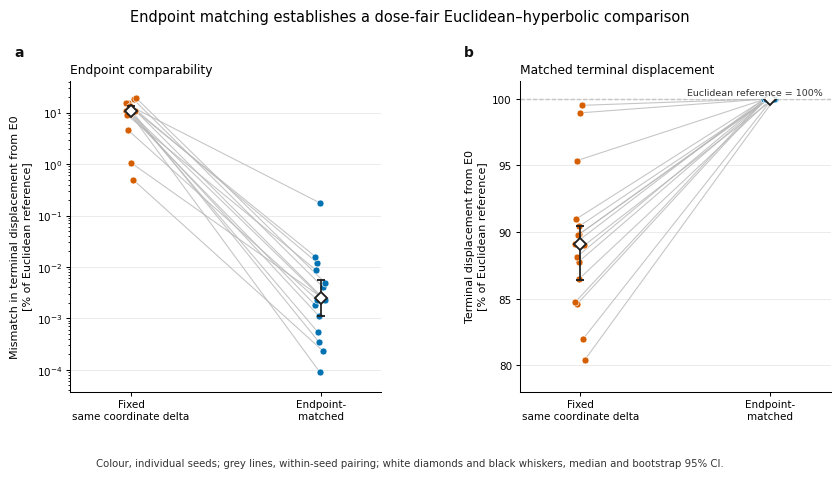

Endpoint-fairness analysis completed.
No model loading or DDIM sampling was performed.
Median fixed-delta endpoint mismatch [%]: 10.929387
Median endpoint-matched mismatch [%]: 0.002468
Median mismatch reduction factor: 4428.8x

Summary table:


,condition,n_seeds,endpoint_mismatch_median_percent,endpoint_mismatch_ci95_low_percent,endpoint_mismatch_ci95_high_percent,terminal_displacement_median_percent_of_euclidean,terminal_displacement_ci95_low_percent,terminal_displacement_ci95_high_percent,matched_hyperbolic_delta_median,matched_to_euclidean_delta_ratio_median,median_endpoint_mismatch_reduction_factor
0,Hyperbolic fixed coordinate delta,16,10.929387,9.561578,13.524378,89.070613,86.475622,90.438422,NaN,NaN,4428.816701
1,Hyperbolic endpoint-matched,16,0.002468,0.001127,0.005634,99.998819,99.996849,100.000289,0.000562,1.123743,4428.816701



Per-seed endpoint-fairness data:


,seed,euclidean_terminal_l2_vs_e0,euclidean_applied_delta,fixed_hyperbolic_terminal_l2_vs_e0,fixed_hyperbolic_applied_delta,matched_hyperbolic_terminal_l2_vs_e0,matched_hyperbolic_applied_delta,fixed_endpoint_mismatch_percent,matched_endpoint_mismatch_percent,fixed_terminal_percent_of_euclidean,matched_terminal_percent_of_euclidean,matched_to_euclidean_delta_ratio
0,0,4.820788,0.0005,3.950489,0.0005,4.820595,0.000560,18.053052,0.004006,81.946948,99.995994,1.119006
1,1,2.648114,0.0005,2.394912,0.0005,2.648112,0.000558,9.561578,0.000090,90.438422,99.999910,1.115918
2,2,19.064146,0.0005,16.122183,0.0005,19.066439,0.000566,15.431917,0.012026,84.568083,100.012026,1.132823
3,3,3.445048,0.0005,3.023490,0.0005,3.445036,0.000564,12.236632,0.000346,87.763368,99.999654,1.127490
4,4,29.404684,0.0005,29.091455,0.0005,29.403908,0.000562,1.065234,0.002640,98.934766,99.997360,1.124115
5,5,5.056023,0.0005,4.543001,0.0005,5.055886,0.000557,10.146748,0.002707,89.853252,99.997293,1.114896
6,6,2.918776,0.0005,2.620052,0.0005,2.918808,0.000558,10.234539,0.001127,89.765461,100.001127,1.116214
7,7,3.470928,0.0005,2.940316,0.0005,3.470378,0.000564,15.287330,0.015861,84.712670,99.984139,1.127408
8,8,3.737891,0.0005,3.295042,0.0005,3.737871,0.000562,11.847567,0.000549,88.152433,99.999451,1.124988
9,9,21.462597,0.0005,17.261990,0.0005,21.461555,0.000566,19.571757,0.004852,80.428243,99.995148,1.132422



Saved:
  - PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/endpoint_matching_fairness_multiseed.png
  - PDF (vector): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/endpoint_matching_fairness_multiseed.pdf
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/endpoint_matching_fairness_per_seed.csv
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/endpoint_matching_fairness_summary.csv
  - /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/endpoint_matching_fairness_metadata.json


In [35]:
# Cell 35 — Multi-seed endpoint-fairness analysis and square-panel manuscript figure

from pathlib import Path
import json

from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


if "RESULTS" not in globals():
    ROOT = Path.cwd().resolve()
    RESULTS = ROOT / "results" / "euclidean_audit"

if "PNG_DPI" not in globals():
    PNG_DPI = 600

if "manuscript_font" not in globals():
    manuscript_font = "DejaVu Sans"


MULTISEED_STUDY_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "multiseed_endpoint_matched_geometry"
)

FAIRNESS_SOURCE_PATH = (
    MULTISEED_STUDY_DIR / "endpoint_fairness_per_seed.csv"
)

PROTOCOL_PATH = MULTISEED_STUDY_DIR / "protocol.json"

FIGURE_DIR = RESULTS / "manuscript" / "figures" / "main"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FAIRNESS_PER_SEED_PATH = (
    MULTISEED_STUDY_DIR / "endpoint_matching_fairness_per_seed.csv"
)

FAIRNESS_SUMMARY_PATH = (
    MULTISEED_STUDY_DIR / "endpoint_matching_fairness_summary.csv"
)

FAIRNESS_METADATA_PATH = (
    MULTISEED_STUDY_DIR / "endpoint_matching_fairness_metadata.json"
)

FAIRNESS_FIGURE_PNG_PATH = (
    FIGURE_DIR / "endpoint_matching_fairness_multiseed.png"
)

FAIRNESS_FIGURE_PDF_PATH = (
    FIGURE_DIR / "endpoint_matching_fairness_multiseed.pdf"
)


for required_path in [FAIRNESS_SOURCE_PATH, PROTOCOL_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Required study file was not found:\n{required_path}"
        )


fairness_raw_df = pd.read_csv(FAIRNESS_SOURCE_PATH)

with open(PROTOCOL_PATH, "r") as file:
    multiseed_protocol = json.load(file)


def resolve_column(dataframe, candidates, description):
    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    raise KeyError(
        f"Could not resolve {description}.\n"
        f"Expected one of: {candidates}\n"
        f"Available columns: {list(dataframe.columns)}"
    )


seed_column = resolve_column(
    fairness_raw_df,
    ["seed"],
    "seed column",
)

condition_column = resolve_column(
    fairness_raw_df,
    ["condition", "method", "comparison_condition"],
    "condition column",
)

terminal_l2_column = resolve_column(
    fairness_raw_df,
    [
        "terminal_latent_l2_vs_E0",
        "terminal_l2_vs_E0",
    ],
    "terminal latent displacement column",
)

applied_delta_column = resolve_column(
    fairness_raw_df,
    [
        "applied_delta",
        "hyperbolic_applied_delta",
        "delta",
    ],
    "applied drift-coordinate column",
)


def normalize_text(series):
    return (
        series.astype(str)
        .str.lower()
        .str.replace(r"[^a-z0-9]+", " ", regex=True)
        .str.strip()
    )


normalized_conditions = normalize_text(
    fairness_raw_df[condition_column]
)


def select_condition(condition_kind):
    if condition_kind == "euclidean":
        mask = normalized_conditions.eq("euclidean")

        if not bool(mask.any()):
            mask = (
                normalized_conditions.str.contains("euclidean")
                & ~normalized_conditions.str.contains("hyperbolic")
            )

    elif condition_kind == "fixed_hyperbolic":
        mask = (
            normalized_conditions.str.contains("hyperbolic")
            & normalized_conditions.str.contains("fixed")
        )

    elif condition_kind == "matched_hyperbolic":
        mask = (
            normalized_conditions.str.contains("hyperbolic")
            & normalized_conditions.str.contains("matched")
            & ~normalized_conditions.str.contains("fixed")
        )

    else:
        raise ValueError(f"Unsupported condition kind: {condition_kind}")

    selected = fairness_raw_df.loc[
        mask,
        [
            seed_column,
            terminal_l2_column,
            applied_delta_column,
        ],
    ].copy()

    if selected.empty:
        raise RuntimeError(
            f"No rows found for condition: {condition_kind}\n"
            f"Observed labels: "
            f"{sorted(fairness_raw_df[condition_column].astype(str).unique())}"
        )

    if bool(selected[seed_column].duplicated().any()):
        raise RuntimeError(
            f"More than one row per seed was found for: {condition_kind}"
        )

    return selected


def prepare_condition_table(condition_kind, prefix):
    dataframe = select_condition(condition_kind).rename(
        columns={
            seed_column: "seed",
            terminal_l2_column: f"{prefix}_terminal_l2_vs_e0",
            applied_delta_column: f"{prefix}_applied_delta",
        }
    )

    dataframe["seed"] = dataframe["seed"].astype(int)

    return dataframe


euclidean_df = prepare_condition_table(
    condition_kind="euclidean",
    prefix="euclidean",
)

fixed_hyperbolic_df = prepare_condition_table(
    condition_kind="fixed_hyperbolic",
    prefix="fixed_hyperbolic",
)

matched_hyperbolic_df = prepare_condition_table(
    condition_kind="matched_hyperbolic",
    prefix="matched_hyperbolic",
)


endpoint_fairness_per_seed_df = (
    euclidean_df
    .merge(
        fixed_hyperbolic_df,
        on="seed",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        matched_hyperbolic_df,
        on="seed",
        how="inner",
        validate="one_to_one",
    )
    .sort_values("seed")
    .reset_index(drop=True)
)


expected_seeds = set(
    int(seed)
    for seed in multiseed_protocol.get(
        "audit_seeds",
        endpoint_fairness_per_seed_df["seed"].tolist(),
    )
)

observed_seeds = set(endpoint_fairness_per_seed_df["seed"].tolist())

if observed_seeds != expected_seeds:
    raise RuntimeError(
        "Unexpected seed coverage.\n"
        f"Expected: {sorted(expected_seeds)}\n"
        f"Observed: {sorted(observed_seeds)}"
    )


numeric_columns = [
    "euclidean_terminal_l2_vs_e0",
    "fixed_hyperbolic_terminal_l2_vs_e0",
    "matched_hyperbolic_terminal_l2_vs_e0",
    "euclidean_applied_delta",
    "fixed_hyperbolic_applied_delta",
    "matched_hyperbolic_applied_delta",
]

for column_name in numeric_columns:
    values = endpoint_fairness_per_seed_df[column_name].to_numpy(
        dtype=float
    )

    if not bool(np.isfinite(values).all()):
        raise FloatingPointError(
            f"Non-finite values found in: {column_name}"
        )


if bool(
    (
        endpoint_fairness_per_seed_df[
            "euclidean_terminal_l2_vs_e0"
        ] <= 0.0
    ).any()
):
    raise RuntimeError(
        "Euclidean terminal displacement from E0 must be positive."
    )


euclidean_terminal_l2 = endpoint_fairness_per_seed_df[
    "euclidean_terminal_l2_vs_e0"
]

endpoint_fairness_per_seed_df[
    "fixed_endpoint_mismatch_percent"
] = (
    100.0
    * np.abs(
        endpoint_fairness_per_seed_df[
            "fixed_hyperbolic_terminal_l2_vs_e0"
        ]
        - euclidean_terminal_l2
    )
    / euclidean_terminal_l2
)

endpoint_fairness_per_seed_df[
    "matched_endpoint_mismatch_percent"
] = (
    100.0
    * np.abs(
        endpoint_fairness_per_seed_df[
            "matched_hyperbolic_terminal_l2_vs_e0"
        ]
        - euclidean_terminal_l2
    )
    / euclidean_terminal_l2
)

endpoint_fairness_per_seed_df[
    "fixed_terminal_percent_of_euclidean"
] = (
    100.0
    * endpoint_fairness_per_seed_df[
        "fixed_hyperbolic_terminal_l2_vs_e0"
    ]
    / euclidean_terminal_l2
)

endpoint_fairness_per_seed_df[
    "matched_terminal_percent_of_euclidean"
] = (
    100.0
    * endpoint_fairness_per_seed_df[
        "matched_hyperbolic_terminal_l2_vs_e0"
    ]
    / euclidean_terminal_l2
)

endpoint_fairness_per_seed_df[
    "matched_to_euclidean_delta_ratio"
] = (
    endpoint_fairness_per_seed_df[
        "matched_hyperbolic_applied_delta"
    ]
    / endpoint_fairness_per_seed_df[
        "euclidean_applied_delta"
    ]
)

endpoint_fairness_per_seed_df.to_csv(
    FAIRNESS_PER_SEED_PATH,
    index=False,
)


BOOTSTRAP_RESAMPLES = 20_000
BOOTSTRAP_SEED = 20261003


def median_and_bootstrap_ci(values, random_generator):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError("No finite values were available.")

    median_value = float(np.median(values))

    bootstrap_indices = random_generator.integers(
        low=0,
        high=values.size,
        size=(BOOTSTRAP_RESAMPLES, values.size),
    )

    bootstrap_medians = np.median(
        values[bootstrap_indices],
        axis=1,
    )

    ci_low, ci_high = np.quantile(
        bootstrap_medians,
        [0.025, 0.975],
    )

    return median_value, float(ci_low), float(ci_high)


summary_rng = np.random.default_rng(BOOTSTRAP_SEED)

fixed_mismatch_median, fixed_mismatch_ci_low, fixed_mismatch_ci_high = (
    median_and_bootstrap_ci(
        endpoint_fairness_per_seed_df[
            "fixed_endpoint_mismatch_percent"
        ],
        summary_rng,
    )
)

matched_mismatch_median, matched_mismatch_ci_low, matched_mismatch_ci_high = (
    median_and_bootstrap_ci(
        endpoint_fairness_per_seed_df[
            "matched_endpoint_mismatch_percent"
        ],
        summary_rng,
    )
)

fixed_terminal_median, fixed_terminal_ci_low, fixed_terminal_ci_high = (
    median_and_bootstrap_ci(
        endpoint_fairness_per_seed_df[
            "fixed_terminal_percent_of_euclidean"
        ],
        summary_rng,
    )
)

matched_terminal_median, matched_terminal_ci_low, matched_terminal_ci_high = (
    median_and_bootstrap_ci(
        endpoint_fairness_per_seed_df[
            "matched_terminal_percent_of_euclidean"
        ],
        summary_rng,
    )
)

matched_delta_median, matched_delta_ci_low, matched_delta_ci_high = (
    median_and_bootstrap_ci(
        endpoint_fairness_per_seed_df[
            "matched_hyperbolic_applied_delta"
        ],
        summary_rng,
    )
)

matched_ratio_median, matched_ratio_ci_low, matched_ratio_ci_high = (
    median_and_bootstrap_ci(
        endpoint_fairness_per_seed_df[
            "matched_to_euclidean_delta_ratio"
        ],
        summary_rng,
    )
)

if matched_mismatch_median <= 0.0:
    raise FloatingPointError(
        "The matched endpoint-mismatch median must be positive "
        "for a finite reduction factor."
    )

mismatch_reduction_factor = (
    fixed_mismatch_median / matched_mismatch_median
)


endpoint_fairness_summary_df = pd.DataFrame(
    [
        {
            "condition": "Hyperbolic fixed coordinate delta",
            "n_seeds": len(endpoint_fairness_per_seed_df),
            "endpoint_mismatch_median_percent": fixed_mismatch_median,
            "endpoint_mismatch_ci95_low_percent": (
                fixed_mismatch_ci_low
            ),
            "endpoint_mismatch_ci95_high_percent": (
                fixed_mismatch_ci_high
            ),
            "terminal_displacement_median_percent_of_euclidean": (
                fixed_terminal_median
            ),
            "terminal_displacement_ci95_low_percent": (
                fixed_terminal_ci_low
            ),
            "terminal_displacement_ci95_high_percent": (
                fixed_terminal_ci_high
            ),
            "matched_hyperbolic_delta_median": np.nan,
            "matched_to_euclidean_delta_ratio_median": np.nan,
            "median_endpoint_mismatch_reduction_factor": (
                mismatch_reduction_factor
            ),
        },
        {
            "condition": "Hyperbolic endpoint-matched",
            "n_seeds": len(endpoint_fairness_per_seed_df),
            "endpoint_mismatch_median_percent": matched_mismatch_median,
            "endpoint_mismatch_ci95_low_percent": (
                matched_mismatch_ci_low
            ),
            "endpoint_mismatch_ci95_high_percent": (
                matched_mismatch_ci_high
            ),
            "terminal_displacement_median_percent_of_euclidean": (
                matched_terminal_median
            ),
            "terminal_displacement_ci95_low_percent": (
                matched_terminal_ci_low
            ),
            "terminal_displacement_ci95_high_percent": (
                matched_terminal_ci_high
            ),
            "matched_hyperbolic_delta_median": (
                matched_delta_median
            ),
            "matched_to_euclidean_delta_ratio_median": (
                matched_ratio_median
            ),
            "median_endpoint_mismatch_reduction_factor": (
                mismatch_reduction_factor
            ),
        },
    ]
)

endpoint_fairness_summary_df.to_csv(
    FAIRNESS_SUMMARY_PATH,
    index=False,
)


# ---------------------------------------------------------------------
# Nature-style plotting utilities.
# ---------------------------------------------------------------------

FIXED_COLOR = "#D55E00"
MATCHED_COLOR = "#0072B2"
PAIRED_LINE_COLOR = "#B8B8B8"
SUMMARY_COLOR = "#202020"
GRID_COLOR = "#E6E6E6"


def style_axis(axis):
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

    axis.spines["left"].set_linewidth(0.75)
    axis.spines["bottom"].set_linewidth(0.75)

    axis.tick_params(
        axis="both",
        which="major",
        labelsize=7.5,
        width=0.75,
        length=3.0,
        direction="out",
        pad=2.5,
    )

    axis.tick_params(
        axis="both",
        which="minor",
        width=0.60,
        length=1.8,
        direction="out",
    )

    axis.set_axisbelow(True)

    axis.grid(
        axis="y",
        color=GRID_COLOR,
        linewidth=0.55,
        alpha=1.0,
        zorder=0,
    )


def add_panel_label(axis, label):
    axis.text(
        -0.18,
        1.07,
        label,
        transform=axis.transAxes,
        fontsize=10,
        fontweight="bold",
        ha="left",
        va="bottom",
        color="#111111",
        clip_on=False,
    )


def add_median_ci_marker(
    axis,
    x_position,
    values,
    random_generator,
):
    """
    Add a deliberately neutral summary marker.

    Individual observations remain condition-coloured. The white-filled,
    deep-charcoal diamond and charcoal CI whisker form a visually distinct
    statistical summary without competing with the paired seed points.
    """
    median_value, ci_low, ci_high = median_and_bootstrap_ci(
        values,
        random_generator,
    )

    axis.errorbar(
        x=x_position,
        y=median_value,
        yerr=np.array(
            [
                [max(median_value - ci_low, 0.0)],
                [max(ci_high - median_value, 0.0)],
            ]
        ),
        fmt="D",
        markersize=6.4,
        markerfacecolor="white",
        markeredgecolor=SUMMARY_COLOR,
        markeredgewidth=1.35,
        color=SUMMARY_COLOR,
        ecolor=SUMMARY_COLOR,
        elinewidth=1.25,
        capsize=3.0,
        capthick=1.10,
        zorder=9,
    )


def plot_paired_seed_values(
    axis,
    fixed_values,
    matched_values,
    fixed_color,
    matched_color,
    bootstrap_generator,
    horizontal_jitter,
):
    fixed_values = np.asarray(fixed_values, dtype=float)
    matched_values = np.asarray(matched_values, dtype=float)
    horizontal_jitter = np.asarray(horizontal_jitter, dtype=float)

    if fixed_values.shape != matched_values.shape:
        raise RuntimeError(
            "Fixed and endpoint-matched values must have identical shape."
        )

    if horizontal_jitter.shape != fixed_values.shape:
        raise RuntimeError(
            "Horizontal jitter must contain exactly one value per seed."
        )

    for fixed_value, matched_value, offset in zip(
        fixed_values,
        matched_values,
        horizontal_jitter,
    ):
        axis.plot(
            [0.0 + offset, 1.0 + offset],
            [fixed_value, matched_value],
            color=PAIRED_LINE_COLOR,
            linewidth=0.78,
            alpha=0.82,
            solid_capstyle="round",
            zorder=1,
        )

    axis.scatter(
        0.0 + horizontal_jitter,
        fixed_values,
        s=25,
        color=fixed_color,
        edgecolor="white",
        linewidth=0.45,
        zorder=4,
    )

    axis.scatter(
        1.0 + horizontal_jitter,
        matched_values,
        s=25,
        color=matched_color,
        edgecolor="white",
        linewidth=0.45,
        zorder=4,
    )

    add_median_ci_marker(
        axis=axis,
        x_position=0.0,
        values=fixed_values,
        random_generator=bootstrap_generator,
    )

    add_median_ci_marker(
        axis=axis,
        x_position=1.0,
        values=matched_values,
        random_generator=bootstrap_generator,
    )

    axis.set_xlim(-0.32, 1.32)
    axis.set_xticks([0.0, 1.0])
    axis.set_xticklabels(
        [
            "Fixed\nsame coordinate delta",
            "Endpoint-\nmatched",
        ],
        fontsize=7.4,
    )


fixed_mismatch_values = endpoint_fairness_per_seed_df[
    "fixed_endpoint_mismatch_percent"
].to_numpy(dtype=float)

matched_mismatch_values = endpoint_fairness_per_seed_df[
    "matched_endpoint_mismatch_percent"
].to_numpy(dtype=float)

fixed_terminal_values = endpoint_fairness_per_seed_df[
    "fixed_terminal_percent_of_euclidean"
].to_numpy(dtype=float)

matched_terminal_values = endpoint_fairness_per_seed_df[
    "matched_terminal_percent_of_euclidean"
].to_numpy(dtype=float)


if bool((matched_mismatch_values <= 0.0).any()):
    raise FloatingPointError(
        "Matched endpoint-mismatch values must be positive "
        "for the logarithmic panel."
    )


plot_bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED + 1)
jitter_rng = np.random.default_rng(BOOTSTRAP_SEED + 2)

# One jitter value per seed is reused in both panels. This preserves the
# visual identity of each paired seed without creating unnecessary noise.
seed_jitter = jitter_rng.normal(
    loc=0.0,
    scale=0.020,
    size=fixed_mismatch_values.size,
)


with mpl.rc_context(
    {
        "font.family": manuscript_font,
        "font.size": 8,
        "axes.titleweight": "regular",
        "axes.labelweight": "regular",
        "axes.linewidth": 0.75,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    # The canvas is horizontal because it contains two panels, but every
    # plotting box below is explicitly square.
    fig = plt.figure(figsize=(8.65, 5.10))

    grid_spec = fig.add_gridspec(
        nrows=1,
        ncols=2,
        left=0.105,
        right=0.990,
        bottom=0.205,
        top=0.815,
        wspace=0.42,
    )

    ax_a = fig.add_subplot(grid_spec[0, 0])
    ax_b = fig.add_subplot(grid_spec[0, 1])

    for axis in [ax_a, ax_b]:
        axis.set_box_aspect(1.0)

    # -----------------------------------------------------------------
    # Panel a: why equal coordinate delta is not a fair comparison.
    # -----------------------------------------------------------------
    plot_paired_seed_values(
        axis=ax_a,
        fixed_values=fixed_mismatch_values,
        matched_values=matched_mismatch_values,
        fixed_color=FIXED_COLOR,
        matched_color=MATCHED_COLOR,
        bootstrap_generator=plot_bootstrap_rng,
        horizontal_jitter=seed_jitter,
    )

    ax_a.set_yscale("log")
    ax_a.set_ylim(
        max(float(np.min(matched_mismatch_values)) * 0.42, 1e-6),
        float(np.max(fixed_mismatch_values)) * 2.15,
    )

    ax_a.set_title(
        "Endpoint comparability",
        loc="left",
        fontsize=8.8,
        pad=5.5,
    )

    ax_a.set_ylabel(
        "Mismatch in terminal displacement from E0\n"
        "[% of Euclidean reference]",
        fontsize=8,
    )

    style_axis(ax_a)
    add_panel_label(ax_a, "a")

    # -----------------------------------------------------------------
    # Panel b: endpoint matching returns every seed to the Euclidean
    # terminal displacement, while fixed delta systematically underdoses.
    # -----------------------------------------------------------------
    plot_paired_seed_values(
        axis=ax_b,
        fixed_values=fixed_terminal_values,
        matched_values=matched_terminal_values,
        fixed_color=FIXED_COLOR,
        matched_color=MATCHED_COLOR,
        bootstrap_generator=plot_bootstrap_rng,
        horizontal_jitter=seed_jitter,
    )

    ax_b.axhline(
        100.0,
        color="#4A4A4A",
        linewidth=0.85,
        linestyle="--",
        alpha=0.85,
        zorder=0,
    )

    terminal_values = np.concatenate(
        [
            fixed_terminal_values,
            matched_terminal_values,
        ]
    )

    ax_b.set_ylim(
        max(0.0, float(np.min(terminal_values)) - 2.4),
        float(np.max(terminal_values)) + 1.35,
    )

    ax_b.set_title(
        "Matched terminal displacement",
        loc="left",
        fontsize=8.8,
        pad=5.5,
    )

    ax_b.set_ylabel(
        "Terminal displacement from E0\n"
        "[% of Euclidean reference]",
        fontsize=8,
    )

    ax_b.text(
        0.975,
        0.975,
        "Euclidean reference = 100%",
        transform=ax_b.transAxes,
        fontsize=6.8,
        ha="right",
        va="top",
        color="#333333",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
            "pad": 1.0,
        },
        zorder=10,
    )

    style_axis(ax_b)
    add_panel_label(ax_b, "b")

    fig.suptitle(
        "Endpoint matching establishes a dose-fair Euclidean–hyperbolic comparison",
        fontsize=10.5,
        y=0.955,
    )

    fig.text(
        0.5,
        0.065,
        (
            "Colour, individual seeds; grey lines, within-seed pairing; "
            "white diamonds and black whiskers, median and bootstrap 95% CI."
        ),
        ha="center",
        va="center",
        fontsize=7.3,
        color="#333333",
    )

    fig.savefig(
        FAIRNESS_FIGURE_PNG_PATH,
        dpi=PNG_DPI,
        bbox_inches="tight",
        facecolor="white",
        transparent=False,
    )

    # Enforce an RGB 600 dpi PNG for journal submission systems.
    with Image.open(FAIRNESS_FIGURE_PNG_PATH) as image:
        image.convert("RGB").save(
            FAIRNESS_FIGURE_PNG_PATH,
            dpi=(PNG_DPI, PNG_DPI),
        )

    fig.savefig(
        FAIRNESS_FIGURE_PDF_PATH,
        format="pdf",
        dpi=PNG_DPI,
        bbox_inches="tight",
        facecolor="white",
        transparent=False,
        metadata={
            "Title": (
                "Endpoint matching establishes a dose-fair "
                "Euclidean-hyperbolic comparison"
            ),
            "Creator": "Matplotlib",
        },
    )

    plt.show()
    plt.close(fig)


fairness_metadata = {
    "n_seeds": int(len(endpoint_fairness_per_seed_df)),
    "bootstrap_resamples": int(BOOTSTRAP_RESAMPLES),
    "bootstrap_random_seed": int(BOOTSTRAP_SEED),
    "png_dpi": int(PNG_DPI),
    "png_color_mode": "RGB",
    "endpoint_definition": (
        "100 * abs(||z_H - z_E0||_2 - ||z_E - z_E0||_2) "
        "/ ||z_E - z_E0||_2"
    ),
    "normalization_definition": (
        "All terminal displacements are measured from E0 and "
        "normalized by the Euclidean reference displacement."
    ),
    "summary_marker_definition": (
        "White-filled charcoal diamonds denote medians; "
        "charcoal vertical whiskers denote bootstrap 95% confidence "
        "intervals for the median."
    ),
    "paired_line_definition": (
        "Each grey line links the fixed-delta and endpoint-matched "
        "conditions from the same generation seed."
    ),
    "panel_geometry": (
        "Two equal square plotting boxes in one horizontal manuscript panel."
    ),
    "figure_panels": [
        "Endpoint displacement mismatch from E0",
        "Terminal displacement from E0",
    ],
    "coordinate_dose_ratio_note": (
        "The coordinate-dose ratio is retained in the summary table "
        "but intentionally omitted from the main figure."
    ),
    "median_fixed_endpoint_mismatch_percent": (
        float(fixed_mismatch_median)
    ),
    "median_matched_endpoint_mismatch_percent": (
        float(matched_mismatch_median)
    ),
    "median_endpoint_mismatch_reduction_factor": (
        float(mismatch_reduction_factor)
    ),
    "png_path": str(FAIRNESS_FIGURE_PNG_PATH),
    "pdf_path": str(FAIRNESS_FIGURE_PDF_PATH),
    "per_seed_data_path": str(FAIRNESS_PER_SEED_PATH),
    "summary_data_path": str(FAIRNESS_SUMMARY_PATH),
}

with open(FAIRNESS_METADATA_PATH, "w") as file:
    json.dump(fairness_metadata, file, indent=2)


print("Endpoint-fairness analysis completed.")
print("No model loading or DDIM sampling was performed.")
print(
    "Median fixed-delta endpoint mismatch [%]:",
    f"{fixed_mismatch_median:.6f}",
)
print(
    "Median endpoint-matched mismatch [%]:",
    f"{matched_mismatch_median:.6f}",
)
print(
    "Median mismatch reduction factor:",
    f"{mismatch_reduction_factor:.1f}x",
)

print("\nSummary table:")
display(endpoint_fairness_summary_df)

print("\nPer-seed endpoint-fairness data:")
display(endpoint_fairness_per_seed_df)

print("\nSaved:")
print("  - PNG (RGB, 600 dpi):", FAIRNESS_FIGURE_PNG_PATH)
print("  - PDF (vector):", FAIRNESS_FIGURE_PDF_PATH)
print("  -", FAIRNESS_PER_SEED_PATH)
print("  -", FAIRNESS_SUMMARY_PATH)
print("  -", FAIRNESS_METADATA_PATH)

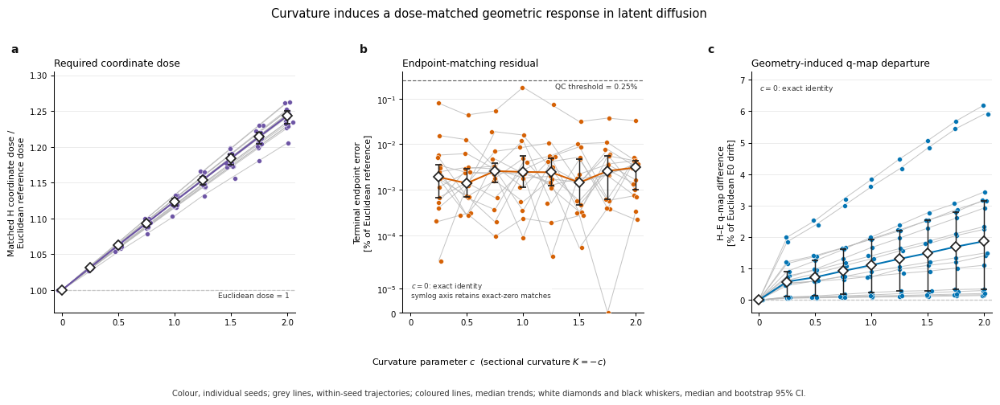

Endpoint-matched curvature-response analysis completed.
No model loading or DDIM sampling was performed.
Exact c = 0 Euclidean-limit controls: 16/16
Maximum positive-curvature endpoint mismatch [%]: 0.177257
Monotonic q-map departure across curvature: 15/16 seeds
Monotonic matched-dose response across curvature: 16/16 seeds
Median matched dose ratio at c = 2.00: 1.243130
Median q-map departure at c = 2.00 [%]: 1.869016

Curvature-response summary:


,curvature_c,sectional_curvature_K,n_seeds,matched_coordinate_dose_ratio_median,matched_coordinate_dose_ratio_ci95_low,matched_coordinate_dose_ratio_ci95_high,matched_coordinate_dose_ratio_mean,matched_coordinate_dose_ratio_std,matched_coordinate_dose_ratio_minimum,matched_coordinate_dose_ratio_maximum,...,terminal_l2_relative_error_percent_std,terminal_l2_relative_error_percent_minimum,terminal_l2_relative_error_percent_maximum,qmap_geometry_difference_percent_of_e0_drift_median,qmap_geometry_difference_percent_of_e0_drift_ci95_low,qmap_geometry_difference_percent_of_e0_drift_ci95_high,qmap_geometry_difference_percent_of_e0_drift_mean,qmap_geometry_difference_percent_of_e0_drift_std,qmap_geometry_difference_percent_of_e0_drift_minimum,qmap_geometry_difference_percent_of_e0_drift_maximum
0,0.00,-0.00,16,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.25,-0.25,16,1.031475,1.029674,1.032227,1.030932,0.001941,1.026253,1.033856,...,0.019515,0.000027,0.079521,0.583037,0.099996,0.910100,0.696170,0.610012,0.056305,1.996398
2,0.50,-0.50,16,1.062744,1.059253,1.064288,1.061643,0.003589,1.053335,1.066797,...,0.010776,0.000275,0.043724,0.723427,0.128406,1.248372,0.873674,0.773711,0.067913,2.530282
3,0.75,-0.75,16,1.093234,1.088379,1.096014,1.091893,0.005573,1.078310,1.100000,...,0.013316,0.000095,0.053639,0.923799,0.181126,1.609095,1.091075,0.973213,0.076907,3.203650
4,1.00,-1.00,16,1.123743,1.117770,1.127408,1.121948,0.007483,1.103448,1.132823,...,0.043557,0.000090,0.177257,1.108973,0.239392,1.926695,1.301730,1.173696,0.090244,3.837041
5,1.25,-1.25,16,1.153656,1.146466,1.158392,1.151983,0.008881,1.131647,1.165729,...,0.018050,0.000034,0.074372,1.308640,0.279568,2.198839,1.523595,1.363427,0.100244,4.487736
6,1.50,-1.50,16,1.183918,1.175128,1.189484,1.181633,0.010798,1.156261,1.198169,...,0.007817,0.000053,0.031303,1.491370,0.297371,2.529356,1.740042,1.565098,0.114542,5.071563
7,1.75,-1.75,16,1.213834,1.203638,1.220017,1.211135,0.012722,1.180676,1.230408,...,0.009050,0.000000,0.037400,1.695369,0.332863,2.805268,1.955206,1.759348,0.128165,5.689412
8,2.00,-2.00,16,1.243130,1.231897,1.250206,1.240343,0.014637,1.205182,1.262671,...,0.007720,0.000222,0.032680,1.869016,0.350200,3.159424,2.159835,1.921381,0.142458,6.199317



Long-form statistics:


,metric,metric_label,unit,curvature_c,sectional_curvature_K,n_seeds,median,ci95_low,ci95_high,mean,std,minimum,maximum
0,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,0.00,-0.00,16,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
1,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,0.25,-0.25,16,1.031475,1.029674,1.032227,1.030932,0.001941,1.026253,1.033856
2,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,0.50,-0.50,16,1.062744,1.059253,1.064288,1.061643,0.003589,1.053335,1.066797
3,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,0.75,-0.75,16,1.093234,1.088379,1.096014,1.091893,0.005573,1.078310,1.100000
4,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,1.00,-1.00,16,1.123743,1.117770,1.127408,1.121948,0.007483,1.103448,1.132823
5,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,1.25,-1.25,16,1.153656,1.146466,1.158392,1.151983,0.008881,1.131647,1.165729
6,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,1.50,-1.50,16,1.183918,1.175128,1.189484,1.181633,0.010798,1.156261,1.198169
7,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,1.75,-1.75,16,1.213834,1.203638,1.220017,1.211135,0.012722,1.180676,1.230408
8,matched_coordinate_dose_ratio,Matched hyperbolic coordinate dose / Euclidean...,ratio,2.00,-2.00,16,1.243130,1.231897,1.250206,1.240343,0.014637,1.205182,1.262671
9,qmap_geometry_difference_percent_of_e0_drift,Hyperbolic–Euclidean q-map departure / Euclide...,%,0.00,-0.00,16,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000



Saved:
  - PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/curvature_response_endpoint_matched_multiseed.png
  - PDF (vector): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/curvature_response_endpoint_matched_multiseed.pdf
  - Source data: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/curvature_response_multiseed_source_data.csv
  - Summary: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/curvature_response_multiseed_summary.csv
  - Statistics: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/curvature_response_multiseed_statistics.csv
  - Metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/cu

In [36]:
# Cell 36 — Endpoint-matched multi-seed curvature response and manuscript figure

from pathlib import Path
import json

from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


if "RESULTS" not in globals():
    ROOT = Path.cwd().resolve()
    RESULTS = ROOT / "results" / "euclidean_audit"

if "PNG_DPI" not in globals():
    PNG_DPI = 600

if "manuscript_font" not in globals():
    manuscript_font = "DejaVu Sans"


STUDY_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "multiseed_endpoint_matched_geometry"
)

CURVATURE_SOURCE_PATH = STUDY_DIR / "matched_curvature_per_seed.csv"
PROTOCOL_PATH = STUDY_DIR / "protocol.json"

FIGURE_DIR = RESULTS / "manuscript" / "figures" / "main"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_DATA_PATH = (
    STUDY_DIR / "curvature_response_multiseed_source_data.csv"
)

SUMMARY_PATH = (
    STUDY_DIR / "curvature_response_multiseed_summary.csv"
)

STATISTICS_PATH = (
    STUDY_DIR / "curvature_response_multiseed_statistics.csv"
)

METADATA_PATH = (
    STUDY_DIR / "curvature_response_multiseed_metadata.json"
)

FIGURE_PNG_PATH = (
    FIGURE_DIR / "curvature_response_endpoint_matched_multiseed.png"
)

FIGURE_PDF_PATH = (
    FIGURE_DIR / "curvature_response_endpoint_matched_multiseed.pdf"
)


for required_path in [CURVATURE_SOURCE_PATH, PROTOCOL_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Required study file was not found:\n{required_path}"
        )


CURVATURE_COLUMNS = [
    "seed",
    "curvature",
    "applied_hyperbolic_delta",
    "terminal_latent_l2_vs_E0",
    "terminal_l2_absolute_error",
    "terminal_l2_relative_error_percent",
    "hyperbolic_qmap_mae_vs_euclidean",
    "qmap_geometry_difference_percent_of_e0_drift",
    "hyperbolic_mean_modifier_update_l2",
    "matching_evaluations",
    "first_bracket_lower_delta",
    "first_bracket_upper_delta",
    "selected_candidate_source",
    "selected_sampling_time_seconds",
    "c0_latent_max_abs_vs_euclidean",
    "c0_qmap_max_abs_vs_euclidean",
]


def curvature_key(value):
    return round(float(value), 8)


def read_checked_csv(path, expected_columns):
    dataframe = pd.read_csv(path)

    missing_columns = [
        column
        for column in expected_columns
        if column not in dataframe.columns
    ]

    unexpected_columns = [
        column
        for column in dataframe.columns
        if column not in expected_columns
    ]

    if missing_columns or unexpected_columns:
        raise RuntimeError(
            f"Incompatible table schema: {path.name}\n"
            f"Missing columns: {missing_columns}\n"
            f"Unexpected columns: {unexpected_columns}"
        )

    return dataframe.loc[:, expected_columns].copy()


def require_finite(dataframe, columns, name):
    values = dataframe.loc[:, columns].to_numpy(dtype=float)

    if not bool(np.isfinite(values).all()):
        raise FloatingPointError(
            f"Non-finite values found in {name}."
        )


with open(PROTOCOL_PATH, "r", encoding="utf-8") as file:
    protocol = json.load(file)

curvature_df = read_checked_csv(
    CURVATURE_SOURCE_PATH,
    CURVATURE_COLUMNS,
)

EXPECTED_SEEDS = sorted(
    int(seed)
    for seed in protocol["audit_seeds"]
)

EXPECTED_CURVATURES = sorted(
    float(curvature)
    for curvature in protocol["curvatures"]
)

POSITIVE_CURVATURES = [
    curvature
    for curvature in EXPECTED_CURVATURES
    if curvature > 0.0
]

REFERENCE_EUCLIDEAN_DELTA = float(
    protocol["reference_euclidean_delta"]
)

ENDPOINT_TOLERANCE_PERCENT = float(
    protocol["endpoint_tolerance_percent"]
)

EXPECTED_MATCHING_EVALUATIONS = int(
    protocol["matching_evaluations_per_positive_curvature"]
)

expected_rows = len(EXPECTED_SEEDS) * len(EXPECTED_CURVATURES)

if len(curvature_df) != expected_rows:
    raise RuntimeError(
        "Unexpected matched-curvature row count.\n"
        f"Expected: {expected_rows}\n"
        f"Observed: {len(curvature_df)}"
    )

if bool(
    curvature_df.duplicated(
        subset=["seed", "curvature"]
    ).any()
):
    raise RuntimeError(
        "The matched-curvature table contains duplicate seed-curvature rows."
    )

observed_seeds = sorted(
    int(seed)
    for seed in curvature_df["seed"].unique()
)

if observed_seeds != EXPECTED_SEEDS:
    raise RuntimeError(
        "Unexpected seed coverage.\n"
        f"Expected: {EXPECTED_SEEDS}\n"
        f"Observed: {observed_seeds}"
    )

expected_curvature_keys = {
    curvature_key(curvature)
    for curvature in EXPECTED_CURVATURES
}

for seed in EXPECTED_SEEDS:
    seed_curvature_keys = {
        curvature_key(curvature)
        for curvature in curvature_df.loc[
            curvature_df["seed"] == seed,
            "curvature",
        ].tolist()
    }

    if seed_curvature_keys != expected_curvature_keys:
        raise RuntimeError(
            f"Incomplete curvature coverage for seed {seed}."
        )


c0_rows = curvature_df[
    np.isclose(curvature_df["curvature"], 0.0)
].copy()

positive_rows = curvature_df[
    curvature_df["curvature"] > 0.0
].copy()

if len(c0_rows) != len(EXPECTED_SEEDS):
    raise RuntimeError(
        "Missing c = 0 Euclidean-limit controls."
    )

if not bool(
    (
        c0_rows["c0_latent_max_abs_vs_euclidean"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 latent Euclidean-limit control failed."
    )

if not bool(
    (
        c0_rows["c0_qmap_max_abs_vs_euclidean"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 q-map Euclidean-limit control failed."
    )

if not bool(
    (
        c0_rows["terminal_l2_relative_error_percent"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 endpoint control is not exact."
    )

if not bool(
    (
        c0_rows["hyperbolic_qmap_mae_vs_euclidean"]
        == 0.0
    ).all()
):
    raise AssertionError(
        "The c = 0 q-map departure is not exact."
    )

if not bool(
    np.isclose(
        c0_rows["applied_hyperbolic_delta"],
        REFERENCE_EUCLIDEAN_DELTA,
        rtol=0.0,
        atol=1e-12,
    ).all()
):
    raise AssertionError(
        "The c = 0 coordinate dose does not equal the Euclidean reference."
    )

if not bool(
    (
        positive_rows["matching_evaluations"]
        == EXPECTED_MATCHING_EVALUATIONS
    ).all()
):
    raise AssertionError(
        "A positive-curvature row used an unexpected matching budget."
    )

require_finite(
    positive_rows,
    [
        "applied_hyperbolic_delta",
        "terminal_l2_relative_error_percent",
        "hyperbolic_qmap_mae_vs_euclidean",
        "qmap_geometry_difference_percent_of_e0_drift",
    ],
    "positive-curvature table",
)

maximum_endpoint_error_percent = float(
    positive_rows[
        "terminal_l2_relative_error_percent"
    ].max()
)

if maximum_endpoint_error_percent > ENDPOINT_TOLERANCE_PERCENT:
    raise AssertionError(
        "Endpoint matching exceeded the pre-specified tolerance."
    )


# ---------------------------------------------------------------------
# Figure-ready source data and bootstrap summaries.
# ---------------------------------------------------------------------

source_df = (
    curvature_df
    .copy()
    .sort_values(["seed", "curvature"])
    .reset_index(drop=True)
)

source_df["sectional_curvature_K"] = -source_df["curvature"]

source_df["matched_coordinate_dose_ratio"] = (
    source_df["applied_hyperbolic_delta"]
    / REFERENCE_EUCLIDEAN_DELTA
)

source_df["matched_coordinate_dose_percent_of_euclidean"] = (
    100.0 * source_df["matched_coordinate_dose_ratio"]
)

source_df.to_csv(
    SOURCE_DATA_PATH,
    index=False,
)


BOOTSTRAP_RESAMPLES = 20_000
BOOTSTRAP_SEED = 20261003


def median_and_bootstrap_ci(values, random_generator):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError("No finite values were available.")

    median_value = float(np.median(values))

    bootstrap_indices = random_generator.integers(
        low=0,
        high=values.size,
        size=(BOOTSTRAP_RESAMPLES, values.size),
    )

    bootstrap_medians = np.median(
        values[bootstrap_indices],
        axis=1,
    )

    ci_low, ci_high = np.quantile(
        bootstrap_medians,
        [0.025, 0.975],
    )

    return median_value, float(ci_low), float(ci_high)


METRICS = [
    {
        "key": "matched_coordinate_dose_ratio",
        "column": "matched_coordinate_dose_ratio",
        "label": (
            "Matched hyperbolic coordinate dose / "
            "Euclidean reference dose"
        ),
        "unit": "ratio",
    },
    {
        "key": "terminal_l2_relative_error_percent",
        "column": "terminal_l2_relative_error_percent",
        "label": "Endpoint-matching residual",
        "unit": "% of Euclidean reference",
    },
    {
        "key": "qmap_geometry_difference_percent_of_e0_drift",
        "column": (
            "qmap_geometry_difference_percent_of_e0_drift"
        ),
        "label": (
            "Hyperbolic–Euclidean q-map departure / "
            "Euclidean E0 drift"
        ),
        "unit": "%",
    },
]


statistics_tables = {}
statistics_rows = []

for metric_index, metric in enumerate(METRICS):
    metric_rows = []

    for curvature_index, curvature in enumerate(
        EXPECTED_CURVATURES
    ):
        values = source_df.loc[
            np.isclose(source_df["curvature"], curvature),
            metric["column"],
        ].to_numpy(dtype=float)

        if len(values) != len(EXPECTED_SEEDS):
            raise RuntimeError(
                "Unexpected seed count in a curvature summary.\n"
                f"Metric: {metric['key']}\n"
                f"Curvature: {curvature}"
            )

        random_generator = np.random.default_rng(
            BOOTSTRAP_SEED
            + 1000 * metric_index
            + curvature_index
        )

        median_value, ci_low, ci_high = median_and_bootstrap_ci(
            values,
            random_generator,
        )

        metric_rows.append(
            {
                "metric": metric["key"],
                "metric_label": metric["label"],
                "unit": metric["unit"],
                "curvature_c": float(curvature),
                "sectional_curvature_K": float(-curvature),
                "n_seeds": int(len(values)),
                "median": median_value,
                "ci95_low": ci_low,
                "ci95_high": ci_high,
                "mean": float(np.mean(values)),
                "std": float(np.std(values, ddof=1)),
                "minimum": float(np.min(values)),
                "maximum": float(np.max(values)),
            }
        )

    metric_table = pd.DataFrame(metric_rows).sort_values(
        "curvature_c"
    ).reset_index(drop=True)

    statistics_tables[metric["key"]] = metric_table
    statistics_rows.extend(metric_rows)


statistics_df = pd.DataFrame(statistics_rows).sort_values(
    ["metric", "curvature_c"]
).reset_index(drop=True)

statistics_df.to_csv(
    STATISTICS_PATH,
    index=False,
)


summary_df = pd.DataFrame(
    {
        "curvature_c": EXPECTED_CURVATURES,
        "sectional_curvature_K": [
            -curvature
            for curvature in EXPECTED_CURVATURES
        ],
        "n_seeds": len(EXPECTED_SEEDS),
    }
)

for metric in METRICS:
    metric_key = metric["key"]
    metric_table = statistics_tables[metric_key]

    renamed_table = metric_table[
        [
            "curvature_c",
            "median",
            "ci95_low",
            "ci95_high",
            "mean",
            "std",
            "minimum",
            "maximum",
        ]
    ].rename(
        columns={
            "median": f"{metric_key}_median",
            "ci95_low": f"{metric_key}_ci95_low",
            "ci95_high": f"{metric_key}_ci95_high",
            "mean": f"{metric_key}_mean",
            "std": f"{metric_key}_std",
            "minimum": f"{metric_key}_minimum",
            "maximum": f"{metric_key}_maximum",
        }
    )

    summary_df = summary_df.merge(
        renamed_table,
        on="curvature_c",
        how="left",
        validate="one_to_one",
    )

summary_df.to_csv(
    SUMMARY_PATH,
    index=False,
)


qmap_pivot = (
    source_df
    .pivot(
        index="seed",
        columns="curvature",
        values=(
            "qmap_geometry_difference_percent_of_e0_drift"
        ),
    )
    .reindex(
        index=EXPECTED_SEEDS,
        columns=EXPECTED_CURVATURES,
    )
)

dose_pivot = (
    source_df
    .pivot(
        index="seed",
        columns="curvature",
        values="matched_coordinate_dose_ratio",
    )
    .reindex(
        index=EXPECTED_SEEDS,
        columns=EXPECTED_CURVATURES,
    )
)

n_qmap_monotonic_seeds = int(
    (
        np.diff(
            qmap_pivot.to_numpy(dtype=float),
            axis=1,
        )
        >= -1e-12
    ).all(axis=1).sum()
)

n_dose_monotonic_seeds = int(
    (
        np.diff(
            dose_pivot.to_numpy(dtype=float),
            axis=1,
        )
        >= -1e-12
    ).all(axis=1).sum()
)


# ---------------------------------------------------------------------
# Nature-style figure.
# ---------------------------------------------------------------------

DOSE_COLOR = "#6A51A3"
QC_COLOR = "#D55E00"
QMAP_COLOR = "#0072B2"

SEED_LINE_COLOR = "#B8B8B8"
SUMMARY_COLOR = "#202020"
GRID_COLOR = "#E6E6E6"


def style_axis(axis):
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
    axis.spines["left"].set_linewidth(0.75)
    axis.spines["bottom"].set_linewidth(0.75)

    axis.tick_params(
        axis="both",
        which="major",
        labelsize=7.3,
        width=0.75,
        length=3.0,
        direction="out",
        pad=2.5,
    )

    axis.tick_params(
        axis="both",
        which="minor",
        width=0.60,
        length=1.8,
        direction="out",
    )

    axis.set_axisbelow(True)

    axis.grid(
        axis="y",
        color=GRID_COLOR,
        linewidth=0.55,
        alpha=1.0,
        zorder=0,
    )


def add_panel_label(axis, label):
    axis.text(
        -0.18,
        1.07,
        label,
        transform=axis.transAxes,
        fontsize=10,
        fontweight="bold",
        ha="left",
        va="bottom",
        color="#111111",
        clip_on=False,
    )


def plot_seed_metric(
    axis,
    dataframe,
    metric_column,
    metric_key,
    curvatures,
    point_color,
    jitter_generator,
):
    metric_pivot = (
        dataframe
        .pivot(
            index="seed",
            columns="curvature",
            values=metric_column,
        )
        .reindex(
            index=EXPECTED_SEEDS,
            columns=curvatures,
        )
    )

    if bool(metric_pivot.isna().any().any()):
        raise RuntimeError(
            f"Missing values for plotted metric: {metric_key}"
        )

    values = metric_pivot.to_numpy(dtype=float)
    curvature_values = np.asarray(curvatures, dtype=float)

    for seed_values in values:
        axis.plot(
            curvature_values,
            seed_values,
            color=SEED_LINE_COLOR,
            linewidth=0.72,
            alpha=0.82,
            solid_capstyle="round",
            zorder=1,
        )

    horizontal_jitter = jitter_generator.normal(
        loc=0.0,
        scale=0.015,
        size=values.shape,
    )

    axis.scatter(
        np.broadcast_to(
            curvature_values,
            values.shape,
        ).ravel()
        + horizontal_jitter.ravel(),
        values.ravel(),
        s=18,
        color=point_color,
        edgecolor="white",
        linewidth=0.38,
        alpha=0.98,
        zorder=4,
    )

    summary_table = statistics_tables[metric_key]
    summary_table = summary_table[
        summary_table["curvature_c"].isin(curvatures)
    ].copy()

    summary_table = summary_table.sort_values(
        "curvature_c"
    ).reset_index(drop=True)

    if not bool(
        np.allclose(
            summary_table["curvature_c"].to_numpy(dtype=float),
            curvature_values,
            rtol=0.0,
            atol=1e-12,
        )
    ):
        raise RuntimeError(
            f"Summary ordering mismatch for metric: {metric_key}"
        )

    medians = summary_table["median"].to_numpy(dtype=float)
    ci_low = summary_table["ci95_low"].to_numpy(dtype=float)
    ci_high = summary_table["ci95_high"].to_numpy(dtype=float)

    axis.plot(
        curvature_values,
        medians,
        color=point_color,
        linewidth=1.45,
        zorder=6,
    )

    axis.errorbar(
        curvature_values,
        medians,
        yerr=np.vstack(
            [
                np.maximum(medians - ci_low, 0.0),
                np.maximum(ci_high - medians, 0.0),
            ]
        ),
        fmt="D",
        markersize=5.8,
        markerfacecolor="white",
        markeredgecolor=SUMMARY_COLOR,
        markeredgewidth=1.25,
        color=SUMMARY_COLOR,
        ecolor=SUMMARY_COLOR,
        elinewidth=1.05,
        capsize=2.7,
        capthick=1.0,
        zorder=9,
    )


CURVATURE_TICKS = [0.0, 0.5, 1.0, 1.5, 2.0]
CURVATURE_TICK_LABELS = ["0", "0.5", "1.0", "1.5", "2.0"]

positive_endpoint_errors = positive_rows[
    "terminal_l2_relative_error_percent"
].to_numpy(dtype=float)

nonzero_endpoint_errors = positive_endpoint_errors[
    positive_endpoint_errors > 0.0
]

if nonzero_endpoint_errors.size > 0:
    endpoint_linthresh = max(
        float(np.min(nonzero_endpoint_errors)) * 0.65,
        1e-6,
    )
else:
    endpoint_linthresh = max(
        ENDPOINT_TOLERANCE_PERCENT / 1000.0,
        1e-6,
    )

endpoint_y_max = max(
    ENDPOINT_TOLERANCE_PERCENT * 1.55,
    float(np.max(positive_endpoint_errors)) * 1.95,
    endpoint_linthresh * 10.0,
)


with mpl.rc_context(
    {
        "font.family": manuscript_font,
        "font.size": 8,
        "axes.titleweight": "regular",
        "axes.labelweight": "regular",
        "axes.linewidth": 0.75,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    fig = plt.figure(figsize=(12.75, 5.35))

    grid_spec = fig.add_gridspec(
        nrows=1,
        ncols=3,
        left=0.075,
        right=0.992,
        bottom=0.245,
        top=0.805,
        wspace=0.43,
    )

    ax_a = fig.add_subplot(grid_spec[0, 0])
    ax_b = fig.add_subplot(grid_spec[0, 1])
    ax_c = fig.add_subplot(grid_spec[0, 2])

    for axis in [ax_a, ax_b, ax_c]:
        axis.set_box_aspect(1.0)
        axis.set_xlim(-0.07, 2.07)
        axis.set_xticks(CURVATURE_TICKS)
        axis.set_xticklabels(CURVATURE_TICK_LABELS)

    plot_jitter_rng = np.random.default_rng(
        BOOTSTRAP_SEED + 50
    )

    # Panel a — dose required to reach the Euclidean endpoint.
    plot_seed_metric(
        axis=ax_a,
        dataframe=source_df,
        metric_column="matched_coordinate_dose_ratio",
        metric_key="matched_coordinate_dose_ratio",
        curvatures=EXPECTED_CURVATURES,
        point_color=DOSE_COLOR,
        jitter_generator=plot_jitter_rng,
    )

    dose_values = source_df[
        "matched_coordinate_dose_ratio"
    ].to_numpy(dtype=float)

    dose_span = max(
        float(np.max(dose_values) - np.min(dose_values)),
        0.02,
    )

    ax_a.set_ylim(
        max(0.0, float(np.min(dose_values)) - 0.12 * dose_span),
        float(np.max(dose_values)) + 0.16 * dose_span,
    )

    ax_a.axhline(
        1.0,
        color="#4A4A4A",
        linewidth=0.80,
        linestyle="--",
        alpha=0.85,
        zorder=0,
    )

    ax_a.text(
        0.975,
        0.055,
        "Euclidean dose = 1",
        transform=ax_a.transAxes,
        fontsize=6.6,
        ha="right",
        va="bottom",
        color="#333333",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
            "pad": 0.9,
        },
        zorder=10,
    )

    ax_a.set_title(
        "Required coordinate dose",
        loc="left",
        fontsize=8.8,
        pad=5.5,
    )

    ax_a.set_ylabel(
        "Matched H coordinate dose /\n"
        "Euclidean reference dose",
        fontsize=7.8,
    )

    style_axis(ax_a)
    add_panel_label(ax_a, "a")

    # Panel b — symlog retains exact-zero endpoint residuals.
    plot_seed_metric(
        axis=ax_b,
        dataframe=positive_rows,
        metric_column="terminal_l2_relative_error_percent",
        metric_key="terminal_l2_relative_error_percent",
        curvatures=POSITIVE_CURVATURES,
        point_color=QC_COLOR,
        jitter_generator=plot_jitter_rng,
    )

    ax_b.set_yscale(
        "symlog",
        linthresh=endpoint_linthresh,
        linscale=0.85,
        base=10,
    )

    ax_b.set_ylim(0.0, endpoint_y_max)

    ax_b.axhline(
        ENDPOINT_TOLERANCE_PERCENT,
        color="#4A4A4A",
        linewidth=0.85,
        linestyle="--",
        alpha=0.85,
        zorder=0,
    )

    ax_b.text(
        0.975,
        0.955,
        f"QC threshold = {ENDPOINT_TOLERANCE_PERCENT:.2f}%",
        transform=ax_b.transAxes,
        fontsize=6.6,
        ha="right",
        va="top",
        color="#333333",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
            "pad": 0.9,
        },
        zorder=10,
    )

    ax_b.text(
        0.035,
        0.055,
        r"$c=0$: exact identity"
        "\nsymlog axis retains exact-zero matches",
        transform=ax_b.transAxes,
        fontsize=6.3,
        ha="left",
        va="bottom",
        color="#333333",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
            "pad": 0.9,
        },
        zorder=10,
    )

    ax_b.set_title(
        "Endpoint-matching residual",
        loc="left",
        fontsize=8.8,
        pad=5.5,
    )

    ax_b.set_ylabel(
        "Terminal endpoint error\n"
        "[% of Euclidean reference]",
        fontsize=7.8,
    )

    style_axis(ax_b)
    add_panel_label(ax_b, "b")

    # Panel c — residual q-map difference after endpoint matching.
    plot_seed_metric(
        axis=ax_c,
        dataframe=source_df,
        metric_column=(
            "qmap_geometry_difference_percent_of_e0_drift"
        ),
        metric_key=(
            "qmap_geometry_difference_percent_of_e0_drift"
        ),
        curvatures=EXPECTED_CURVATURES,
        point_color=QMAP_COLOR,
        jitter_generator=plot_jitter_rng,
    )

    qmap_values = source_df[
        "qmap_geometry_difference_percent_of_e0_drift"
    ].to_numpy(dtype=float)

    qmap_upper_limit = max(
        float(np.max(qmap_values)) * 1.17,
        0.10,
    )

    ax_c.set_ylim(
        -0.055 * qmap_upper_limit,
        qmap_upper_limit,
    )

    ax_c.axhline(
        0.0,
        color="#4A4A4A",
        linewidth=0.80,
        linestyle="--",
        alpha=0.85,
        zorder=0,
    )

    ax_c.text(
        0.035,
        0.955,
        r"$c=0$: exact identity",
        transform=ax_c.transAxes,
        fontsize=6.6,
        ha="left",
        va="top",
        color="#333333",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.88,
            "pad": 0.9,
        },
        zorder=10,
    )

    ax_c.set_title(
        "Geometry-induced q-map departure",
        loc="left",
        fontsize=8.8,
        pad=5.5,
    )

    ax_c.set_ylabel(
        "H–E q-map difference\n"
        "[% of Euclidean E0 drift]",
        fontsize=7.8,
    )

    style_axis(ax_c)
    add_panel_label(ax_c, "c")

    fig.suptitle(
        "Curvature induces a dose-matched geometric response in latent diffusion",
        fontsize=10.5,
        y=0.955,
    )

    fig.text(
        0.5,
        0.130,
        r"Curvature parameter $c$  (sectional curvature $K=-c$)",
        ha="center",
        va="center",
        fontsize=8.0,
    )

    fig.text(
        0.5,
        0.058,
        (
            "Colour, individual seeds; grey lines, within-seed trajectories; "
            "coloured lines, median trends; white diamonds and black whiskers, "
            "median and bootstrap 95% CI."
        ),
        ha="center",
        va="center",
        fontsize=7.1,
        color="#333333",
    )

    fig.savefig(
        FIGURE_PNG_PATH,
        dpi=PNG_DPI,
        bbox_inches="tight",
        facecolor="white",
        transparent=False,
    )

    with Image.open(FIGURE_PNG_PATH) as image:
        image.convert("RGB").save(
            FIGURE_PNG_PATH,
            dpi=(PNG_DPI, PNG_DPI),
        )

    fig.savefig(
        FIGURE_PDF_PATH,
        format="pdf",
        dpi=PNG_DPI,
        bbox_inches="tight",
        facecolor="white",
        transparent=False,
        metadata={
            "Title": (
                "Curvature response under endpoint-matched "
                "Euclidean-hyperbolic latent interventions"
            ),
            "Creator": "Matplotlib",
        },
    )

    plt.show()
    plt.close(fig)


max_curvature = float(max(EXPECTED_CURVATURES))

max_curvature_row = summary_df[
    np.isclose(summary_df["curvature_c"], max_curvature)
].iloc[0]

max_curvature_dose_ratio = float(
    max_curvature_row[
        "matched_coordinate_dose_ratio_median"
    ]
)

max_curvature_qmap_departure = float(
    max_curvature_row[
        "qmap_geometry_difference_percent_of_e0_drift_median"
    ]
)

metadata = {
    "study_name": protocol.get(
        "study_name",
        "multiseed_endpoint_matched_geometry",
    ),
    "n_seeds": int(len(EXPECTED_SEEDS)),
    "audit_seeds": EXPECTED_SEEDS,
    "curvature_parameter_values_c": EXPECTED_CURVATURES,
    "sectional_curvature_definition": "K = -c",
    "reference_euclidean_coordinate_delta": (
        REFERENCE_EUCLIDEAN_DELTA
    ),
    "endpoint_tolerance_percent": (
        ENDPOINT_TOLERANCE_PERCENT
    ),
    "maximum_positive_curvature_endpoint_error_percent": (
        maximum_endpoint_error_percent
    ),
    "bootstrap_resamples": int(BOOTSTRAP_RESAMPLES),
    "bootstrap_random_seed": int(BOOTSTRAP_SEED),
    "png_dpi": int(PNG_DPI),
    "png_color_mode": "RGB",
    "panel_geometry": (
        "Three equal square plotting boxes in one horizontal manuscript figure."
    ),
    "endpoint_panel_scale": (
        "Symmetric logarithmic scale; exact-zero residuals are retained."
    ),
    "qmap_departure_definition": (
        "100 * MAE(q_H, q_E) / MAE(q_E, q_E0), evaluated after "
        "endpoint matching."
    ),
    "c0_control": (
        "At c = 0, the hyperbolic branch is exactly identical to "
        "the Euclidean reference in latent and decoded q-map space."
    ),
    "n_monotonic_qmap_departure_seeds": (
        n_qmap_monotonic_seeds
    ),
    "n_monotonic_dose_response_seeds": (
        n_dose_monotonic_seeds
    ),
    "interpretation": (
        "This figure reports a controlled inference-time geometry "
        "effect under matched terminal latent displacement. It does "
        "not claim clinical realism, diagnostic utility, or biological "
        "validity without held-out real MRI data."
    ),
    "png_path": str(FIGURE_PNG_PATH),
    "pdf_path": str(FIGURE_PDF_PATH),
    "source_data_path": str(SOURCE_DATA_PATH),
    "summary_path": str(SUMMARY_PATH),
    "statistics_path": str(STATISTICS_PATH),
}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)


print("Endpoint-matched curvature-response analysis completed.")
print("No model loading or DDIM sampling was performed.")

print(
    "Exact c = 0 Euclidean-limit controls:",
    f"{len(c0_rows)}/{len(EXPECTED_SEEDS)}",
)

print(
    "Maximum positive-curvature endpoint mismatch [%]:",
    f"{maximum_endpoint_error_percent:.6f}",
)

print(
    "Monotonic q-map departure across curvature:",
    f"{n_qmap_monotonic_seeds}/{len(EXPECTED_SEEDS)} seeds",
)

print(
    "Monotonic matched-dose response across curvature:",
    f"{n_dose_monotonic_seeds}/{len(EXPECTED_SEEDS)} seeds",
)

print(
    f"Median matched dose ratio at c = {max_curvature:.2f}:",
    f"{max_curvature_dose_ratio:.6f}",
)

print(
    f"Median q-map departure at c = {max_curvature:.2f} [%]:",
    f"{max_curvature_qmap_departure:.6f}",
)

print("\nCurvature-response summary:")
display(summary_df)

print("\nLong-form statistics:")
display(statistics_df)

print("\nSaved:")
print("  - PNG (RGB, 600 dpi):", FIGURE_PNG_PATH)
print("  - PDF (vector):", FIGURE_PDF_PATH)
print("  - Source data:", SOURCE_DATA_PATH)
print("  - Summary:", SUMMARY_PATH)
print("  - Statistics:", STATISTICS_PATH)
print("  - Metadata:", METADATA_PATH)

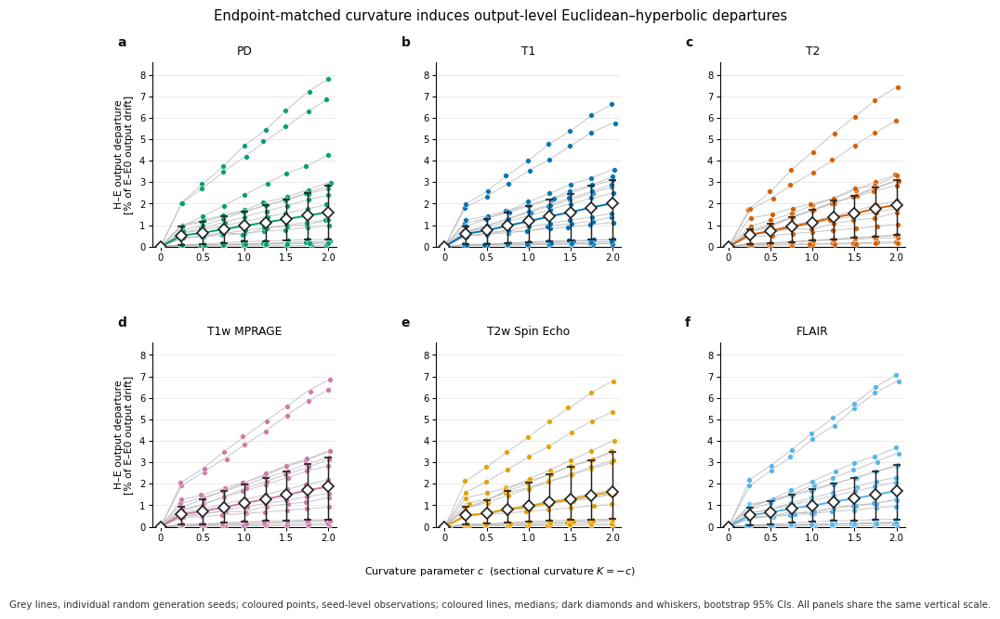

Endpoint-matched physical-output response analysis completed.
No model loading or DDIM sampling was performed.
Output-level seed-curvature records: 864 (16 seeds × 9 curvatures × 6 outputs)
Exact decoded c = 0 Euclidean-limit controls: 96/96
Maximum positive-curvature endpoint mismatch [%]: 0.177257
Paper-statistics curvature: c = 1.00 (K = -1.00)

C = 1 paper statistics:


,output,curvature_c,sectional_curvature_K,n_seeds,geometry_effect_median_percent,geometry_effect_ci95_low_percent,geometry_effect_ci95_high_percent,raw_hyperbolic_euclidean_mae_median,raw_hyperbolic_euclidean_mae_ci95_low,raw_hyperbolic_euclidean_mae_ci95_high,change_spatial_correlation_median_r,change_spatial_correlation_ci95_low_r,change_spatial_correlation_ci95_high_r,n_non_decreasing_effect_seeds,fraction_non_decreasing_effect_seeds
0,PD [a.u.],1.0,-1.0,16,0.965969,0.229650,1.643629,0.268140,0.189293,0.428806,0.999958,0.999913,0.999997,15,0.9375
1,T1 [s],1.0,-1.0,16,1.181627,0.225854,1.881963,0.000480,0.000430,0.000529,0.999953,0.999884,0.999997,15,0.9375
2,T2 [s],1.0,-1.0,16,1.127989,0.287039,1.718200,0.001444,0.001070,0.001860,0.999937,0.999853,0.999989,15,0.9375
3,T1w MPRAGE,1.0,-1.0,16,1.100317,0.236440,1.951706,0.071160,0.055857,0.096802,0.999950,0.999853,0.999997,15,0.9375
4,T2w Spin Echo,1.0,-1.0,16,0.959954,0.249150,2.037920,0.065124,0.044865,0.082446,0.999943,0.999869,0.999997,15,0.9375
5,FLAIR,1.0,-1.0,16,0.978608,0.235230,1.747893,0.119166,0.074265,0.148481,0.999953,0.999881,0.999997,15,0.9375



Saved:
  - PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/output_response_endpoint_matched_multiseed.png
  - PDF (vector): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/output_response_endpoint_matched_multiseed.pdf
  - Source data: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/output_response_multiseed_source_data.csv
  - Summary: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/output_response_multiseed_summary.csv
  - Statistics: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/output_response_multiseed_statistics.csv
  - C = 1 paper table: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/output_r

In [37]:
# Cell 37 — Endpoint-matched multi-seed physical-output response
#           and manuscript-ready six-output figure

from pathlib import Path
import json

from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


# ---------------------------------------------------------------------
# Reproducible paths and manuscript defaults.
# ---------------------------------------------------------------------

if "RESULTS" not in globals():
    ROOT = Path.cwd().resolve()
    RESULTS = ROOT / "results" / "euclidean_audit"

RESULTS = Path(RESULTS)

if "PNG_DPI" not in globals():
    PNG_DPI = 600

if "manuscript_font" not in globals():
    manuscript_font = "DejaVu Sans"


MULTISEED_STUDY_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "multiseed_endpoint_matched_geometry"
)

OUTPUT_SOURCE_PATH = (
    MULTISEED_STUDY_DIR
    / "matched_curvature_outputs_per_seed.csv"
)

CURVATURE_SOURCE_PATH = (
    MULTISEED_STUDY_DIR
    / "matched_curvature_per_seed.csv"
)

PROTOCOL_PATH = MULTISEED_STUDY_DIR / "protocol.json"

FIGURE_DIR = RESULTS / "manuscript" / "figures" / "main"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_RESPONSE_SOURCE_DATA_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_multiseed_source_data.csv"
)

OUTPUT_RESPONSE_SUMMARY_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_multiseed_summary.csv"
)

OUTPUT_RESPONSE_STATS_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_multiseed_statistics.csv"
)

OUTPUT_RESPONSE_C1_TABLE_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_c1_paper_statistics.csv"
)

OUTPUT_RESPONSE_SEED_CONSISTENCY_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_seed_consistency.csv"
)

OUTPUT_RESPONSE_METADATA_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_multiseed_metadata.json"
)

OUTPUT_RESPONSE_PNG_PATH = (
    FIGURE_DIR
    / "output_response_endpoint_matched_multiseed.png"
)

OUTPUT_RESPONSE_PDF_PATH = (
    FIGURE_DIR
    / "output_response_endpoint_matched_multiseed.pdf"
)


for required_path in [
    OUTPUT_SOURCE_PATH,
    CURVATURE_SOURCE_PATH,
    PROTOCOL_PATH,
]:
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Required study file was not found:\n{required_path}"
        )


# ---------------------------------------------------------------------
# Immutable schema and protocol checks.
# ---------------------------------------------------------------------

OUTPUT_COLUMNS = [
    "seed",
    "curvature",
    "output",
    "applied_hyperbolic_delta",
    "euclidean_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_euclidean",
    "geometry_difference_percent_of_e0_drift",
    "change_spatial_correlation_with_euclidean",
]

CURVATURE_REQUIRED_COLUMNS = [
    "seed",
    "curvature",
    "terminal_l2_relative_error_percent",
]

OUTPUT_ORDER = [
    "PD [a.u.]",
    "T1 [s]",
    "T2 [s]",
    "T1w MPRAGE",
    "T2w Spin Echo",
    "FLAIR",
]

OUTPUT_DISPLAY_LABELS = {
    "PD [a.u.]": "PD",
    "T1 [s]": "T1",
    "T2 [s]": "T2",
    "T1w MPRAGE": "T1w MPRAGE",
    "T2w Spin Echo": "T2w Spin Echo",
    "FLAIR": "FLAIR",
}

OUTPUT_COLORS = {
    "PD [a.u.]": "#009E73",
    "T1 [s]": "#0072B2",
    "T2 [s]": "#D55E00",
    "T1w MPRAGE": "#CC79A7",
    "T2w Spin Echo": "#E69F00",
    "FLAIR": "#56B4E9",
}

SEED_LINE_COLOR = "#B8B8B8"
SUMMARY_COLOR = "#202020"
GRID_COLOR = "#E6E6E6"

BOOTSTRAP_RESAMPLES = 20_000
BOOTSTRAP_SEED = 20261037
C0_ABSOLUTE_TOLERANCE = 1e-12


def curvature_key(value):
    return round(float(value), 8)


def read_required_csv(path, required_columns):
    dataframe = pd.read_csv(path)

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise RuntimeError(
            f"Incompatible table schema: {path.name}\n"
            f"Missing columns: {missing_columns}\n"
            f"Available columns: {list(dataframe.columns)}"
        )

    return dataframe.loc[:, required_columns].copy()


def require_finite_columns(dataframe, columns, table_name):
    values = dataframe.loc[:, columns].to_numpy(dtype=float)

    if not bool(np.isfinite(values).all()):
        raise FloatingPointError(
            f"Non-finite values found in {table_name}."
        )


with open(PROTOCOL_PATH, "r", encoding="utf-8") as file:
    multiseed_protocol = json.load(file)

output_df = read_required_csv(
    OUTPUT_SOURCE_PATH,
    OUTPUT_COLUMNS,
)

curvature_df = read_required_csv(
    CURVATURE_SOURCE_PATH,
    CURVATURE_REQUIRED_COLUMNS,
)

output_df["seed"] = output_df["seed"].astype(int)
curvature_df["seed"] = curvature_df["seed"].astype(int)

output_df["curvature"] = output_df["curvature"].astype(float)
curvature_df["curvature"] = curvature_df["curvature"].astype(float)

output_df["output"] = output_df["output"].astype(str)

EXPECTED_SEEDS = sorted(
    int(seed)
    for seed in multiseed_protocol["audit_seeds"]
)

EXPECTED_CURVATURES = sorted(
    float(curvature)
    for curvature in multiseed_protocol["curvatures"]
)

EXPECTED_POSITIVE_CURVATURES = [
    curvature
    for curvature in EXPECTED_CURVATURES
    if curvature > 0.0
]

ENDPOINT_TOLERANCE_PERCENT = float(
    multiseed_protocol["endpoint_tolerance_percent"]
)

C1_CURVATURE = float(
    multiseed_protocol.get("fixed_delta_curvature", 1.0)
)

PROTOCOL_OUTPUTS = list(
    multiseed_protocol["physical_output_channels"]
)

if set(PROTOCOL_OUTPUTS) != set(OUTPUT_ORDER):
    raise RuntimeError(
        "The output names in protocol.json do not match the expected "
        "six-output physical synthesis protocol.\n"
        f"Protocol outputs: {PROTOCOL_OUTPUTS}\n"
        f"Expected outputs: {OUTPUT_ORDER}"
    )

if not any(
    np.isclose(curvature, C1_CURVATURE)
    for curvature in EXPECTED_CURVATURES
):
    raise RuntimeError(
        f"The requested c = {C1_CURVATURE:.2f} summary is absent "
        "from the curvature protocol."
    )

expected_output_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_CURVATURES)
    * len(OUTPUT_ORDER)
)

expected_curvature_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_CURVATURES)
)

if len(output_df) != expected_output_rows:
    raise RuntimeError(
        "Unexpected output-table row count.\n"
        f"Expected: {expected_output_rows}\n"
        f"Observed: {len(output_df)}"
    )

if len(curvature_df) != expected_curvature_rows:
    raise RuntimeError(
        "Unexpected curvature-table row count.\n"
        f"Expected: {expected_curvature_rows}\n"
        f"Observed: {len(curvature_df)}"
    )

if bool(
    output_df.duplicated(
        subset=["seed", "curvature", "output"]
    ).any()
):
    raise RuntimeError(
        "The output table contains duplicate seed-curvature-output rows."
    )

if bool(
    curvature_df.duplicated(
        subset=["seed", "curvature"]
    ).any()
):
    raise RuntimeError(
        "The curvature table contains duplicate seed-curvature rows."
    )

observed_output_seeds = sorted(
    int(seed)
    for seed in output_df["seed"].unique()
)

if observed_output_seeds != EXPECTED_SEEDS:
    raise RuntimeError(
        "Unexpected output-table seed coverage.\n"
        f"Expected: {EXPECTED_SEEDS}\n"
        f"Observed: {observed_output_seeds}"
    )

observed_curvature_seeds = sorted(
    int(seed)
    for seed in curvature_df["seed"].unique()
)

if observed_curvature_seeds != EXPECTED_SEEDS:
    raise RuntimeError(
        "Unexpected curvature-table seed coverage.\n"
        f"Expected: {EXPECTED_SEEDS}\n"
        f"Observed: {observed_curvature_seeds}"
    )

expected_curvature_keys = {
    curvature_key(curvature)
    for curvature in EXPECTED_CURVATURES
}

expected_seed_output_pairs = {
    (curvature_key(curvature), output_name)
    for curvature in EXPECTED_CURVATURES
    for output_name in OUTPUT_ORDER
}

for seed in EXPECTED_SEEDS:
    seed_outputs = output_df[
        output_df["seed"] == seed
    ].copy()

    seed_curvatures = curvature_df[
        curvature_df["seed"] == seed
    ].copy()

    observed_output_pairs = {
        (
            curvature_key(row.curvature),
            str(row.output),
        )
        for row in seed_outputs.itertuples(index=False)
    }

    if observed_output_pairs != expected_seed_output_pairs:
        raise RuntimeError(
            f"Incomplete output coverage for seed {seed}."
        )

    observed_curvature_keys = {
        curvature_key(curvature)
        for curvature in seed_curvatures["curvature"].tolist()
    }

    if observed_curvature_keys != expected_curvature_keys:
        raise RuntimeError(
            f"Incomplete curvature coverage for seed {seed}."
        )

require_finite_columns(
    output_df,
    [
        "applied_hyperbolic_delta",
        "euclidean_output_mae_vs_e0",
        "hyperbolic_output_mae_vs_e0",
        "hyperbolic_output_mae_vs_euclidean",
        "geometry_difference_percent_of_e0_drift",
        "change_spatial_correlation_with_euclidean",
    ],
    "matched physical-output study",
)

positive_curvature_df = curvature_df[
    curvature_df["curvature"] > 0.0
].copy()

maximum_endpoint_error_percent = float(
    positive_curvature_df[
        "terminal_l2_relative_error_percent"
    ].max()
)

if maximum_endpoint_error_percent > ENDPOINT_TOLERANCE_PERCENT:
    raise AssertionError(
        "A positive-curvature endpoint match exceeded the "
        "pre-specified tolerance."
    )

c0_output_df = output_df[
    np.isclose(output_df["curvature"], 0.0)
].copy()

expected_c0_output_rows = (
    len(EXPECTED_SEEDS)
    * len(OUTPUT_ORDER)
)

if len(c0_output_df) != expected_c0_output_rows:
    raise RuntimeError(
        "Missing decoded c = 0 Euclidean-limit controls."
    )

c0_raw_departures = c0_output_df[
    "hyperbolic_output_mae_vs_euclidean"
].to_numpy(dtype=float)

c0_controls_exact = bool(
    np.all(
        np.abs(c0_raw_departures)
        <= C0_ABSOLUTE_TOLERANCE
    )
)

if not c0_controls_exact:
    raise AssertionError(
        "The decoded c = 0 Euclidean-limit control failed."
    )

# ---------------------------------------------------------------------
# Figure-ready source data.
# ---------------------------------------------------------------------

output_response_source_df = (
    output_df
    .copy()
    .sort_values(
        ["output", "seed", "curvature"],
        kind="stable",
    )
    .reset_index(drop=True)
)

output_response_source_df[
    "sectional_curvature_K"
] = -output_response_source_df["curvature"]

output_response_source_df.to_csv(
    OUTPUT_RESPONSE_SOURCE_DATA_PATH,
    index=False,
)


# ---------------------------------------------------------------------
# Bootstrap summaries across random generation seeds.
# ---------------------------------------------------------------------

def median_and_bootstrap_ci(values, random_generator):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError("No finite values were available.")

    median_value = float(np.median(values))

    bootstrap_indices = random_generator.integers(
        low=0,
        high=values.size,
        size=(BOOTSTRAP_RESAMPLES, values.size),
    )

    bootstrap_medians = np.median(
        values[bootstrap_indices],
        axis=1,
    )

    ci_low, ci_high = np.quantile(
        bootstrap_medians,
        [0.025, 0.975],
    )

    return median_value, float(ci_low), float(ci_high)


METRIC_SPECS = [
    {
        "key": "geometry_difference_percent_of_e0_drift",
        "column": "geometry_difference_percent_of_e0_drift",
        "label": (
            "Hyperbolic–Euclidean output departure / "
            "Euclidean E0 output drift"
        ),
        "unit": "%",
    },
    {
        "key": "hyperbolic_output_mae_vs_euclidean",
        "column": "hyperbolic_output_mae_vs_euclidean",
        "label": "Absolute Hyperbolic–Euclidean output departure",
        "unit": "native output units",
    },
    {
        "key": "change_spatial_correlation_with_euclidean",
        "column": "change_spatial_correlation_with_euclidean",
        "label": (
            "Spatial correlation of Hyperbolic and Euclidean "
            "output-change maps"
        ),
        "unit": "Pearson r",
    },
]

statistics_rows = []

for output_index, output_name in enumerate(OUTPUT_ORDER):
    output_rows = output_response_source_df[
        output_response_source_df["output"] == output_name
    ].copy()

    for metric_index, metric_spec in enumerate(METRIC_SPECS):
        for curvature_index, curvature in enumerate(
            EXPECTED_CURVATURES
        ):
            values = output_rows.loc[
                np.isclose(
                    output_rows["curvature"],
                    curvature,
                ),
                metric_spec["column"],
            ].to_numpy(dtype=float)

            if len(values) != len(EXPECTED_SEEDS):
                raise RuntimeError(
                    "Unexpected seed count in output summary.\n"
                    f"Output: {output_name}\n"
                    f"Metric: {metric_spec['key']}\n"
                    f"Curvature: {curvature}"
                )

            random_generator = np.random.default_rng(
                BOOTSTRAP_SEED
                + 10_000 * output_index
                + 1_000 * metric_index
                + curvature_index
            )

            median_value, ci_low, ci_high = (
                median_and_bootstrap_ci(
                    values,
                    random_generator,
                )
            )

            statistics_rows.append(
                {
                    "output": output_name,
                    "metric": metric_spec["key"],
                    "metric_label": metric_spec["label"],
                    "unit": metric_spec["unit"],
                    "curvature_c": float(curvature),
                    "sectional_curvature_K": float(-curvature),
                    "n_seeds": int(len(values)),
                    "median": median_value,
                    "ci95_low": ci_low,
                    "ci95_high": ci_high,
                    "mean": float(np.mean(values)),
                    "std": float(np.std(values, ddof=1)),
                    "minimum": float(np.min(values)),
                    "maximum": float(np.max(values)),
                    "n_values_greater_than_zero": int(
                        np.sum(values > 0.0)
                    ),
                }
            )

output_response_statistics_df = pd.DataFrame(
    statistics_rows
)

output_order_lookup = {
    output_name: index
    for index, output_name in enumerate(OUTPUT_ORDER)
}

output_response_statistics_df["_output_order"] = (
    output_response_statistics_df["output"].map(output_order_lookup)
)

output_response_statistics_df = (
    output_response_statistics_df
    .sort_values(
        ["_output_order", "metric", "curvature_c"],
        kind="stable",
    )
    .drop(columns="_output_order")
    .reset_index(drop=True)
)

output_response_statistics_df.to_csv(
    OUTPUT_RESPONSE_STATS_PATH,
    index=False,
)


def get_metric_statistics(output_name, metric_key):
    dataframe = output_response_statistics_df[
        (
            output_response_statistics_df["output"]
            == output_name
        )
        & (
            output_response_statistics_df["metric"]
            == metric_key
        )
    ].copy()

    dataframe = dataframe.sort_values(
        "curvature_c",
        kind="stable",
    ).reset_index(drop=True)

    observed_curvatures = dataframe[
        "curvature_c"
    ].to_numpy(dtype=float)

    if len(dataframe) != len(EXPECTED_CURVATURES) or not bool(
        np.allclose(
            observed_curvatures,
            np.asarray(EXPECTED_CURVATURES, dtype=float),
            rtol=0.0,
            atol=1e-12,
        )
    ):
        raise RuntimeError(
            "Unexpected curvature ordering in output statistics.\n"
            f"Output: {output_name}\n"
            f"Metric: {metric_key}"
        )

    return dataframe


# ---------------------------------------------------------------------
# Wide per-output summary and descriptive seed consistency.
# ---------------------------------------------------------------------

summary_rows = []

for output_name in OUTPUT_ORDER:
    for curvature in EXPECTED_CURVATURES:
        summary_row = {
            "output": output_name,
            "curvature_c": float(curvature),
            "sectional_curvature_K": float(-curvature),
            "n_seeds": int(len(EXPECTED_SEEDS)),
        }

        for metric_spec in METRIC_SPECS:
            metric_df = get_metric_statistics(
                output_name,
                metric_spec["key"],
            )

            metric_row = metric_df[
                np.isclose(
                    metric_df["curvature_c"],
                    curvature,
                )
            ]

            if len(metric_row) != 1:
                raise RuntimeError(
                    "Could not resolve a unique output summary row."
                )

            metric_row = metric_row.iloc[0]
            prefix = metric_spec["key"]

            for statistic_name in [
                "median",
                "ci95_low",
                "ci95_high",
                "mean",
                "std",
                "minimum",
                "maximum",
                "n_values_greater_than_zero",
            ]:
                summary_row[
                    f"{prefix}_{statistic_name}"
                ] = metric_row[statistic_name]

        summary_rows.append(summary_row)

output_response_summary_df = pd.DataFrame(summary_rows)

output_response_summary_df["_output_order"] = (
    output_response_summary_df["output"].map(output_order_lookup)
)

output_response_summary_df = (
    output_response_summary_df
    .sort_values(
        ["_output_order", "curvature_c"],
        kind="stable",
    )
    .drop(columns="_output_order")
    .reset_index(drop=True)
)

output_response_summary_df.to_csv(
    OUTPUT_RESPONSE_SUMMARY_PATH,
    index=False,
)

primary_effect_column = (
    "geometry_difference_percent_of_e0_drift"
)

raw_departure_column = (
    "hyperbolic_output_mae_vs_euclidean"
)

spatial_correlation_column = (
    "change_spatial_correlation_with_euclidean"
)

c1_index = next(
    index
    for index, curvature in enumerate(EXPECTED_CURVATURES)
    if np.isclose(curvature, C1_CURVATURE)
)

seed_consistency_rows = []
output_consistency = {}

for output_name in OUTPUT_ORDER:
    output_rows = output_response_source_df[
        output_response_source_df["output"] == output_name
    ].copy()

    primary_pivot_df = (
        output_rows
        .pivot(
            index="seed",
            columns="curvature",
            values=primary_effect_column,
        )
        .reindex(
            index=EXPECTED_SEEDS,
            columns=EXPECTED_CURVATURES,
        )
    )

    raw_pivot_df = (
        output_rows
        .pivot(
            index="seed",
            columns="curvature",
            values=raw_departure_column,
        )
        .reindex(
            index=EXPECTED_SEEDS,
            columns=EXPECTED_CURVATURES,
        )
    )

    correlation_pivot_df = (
        output_rows
        .pivot(
            index="seed",
            columns="curvature",
            values=spatial_correlation_column,
        )
        .reindex(
            index=EXPECTED_SEEDS,
            columns=EXPECTED_CURVATURES,
        )
    )

    if bool(primary_pivot_df.isna().any().any()):
        raise RuntimeError(
            f"Missing primary-effect values for output: {output_name}"
        )

    if bool(raw_pivot_df.isna().any().any()):
        raise RuntimeError(
            f"Missing raw-departure values for output: {output_name}"
        )

    if bool(correlation_pivot_df.isna().any().any()):
        raise RuntimeError(
            f"Missing spatial-correlation values for output: {output_name}"
        )

    primary_values = primary_pivot_df.to_numpy(dtype=float)
    raw_values = raw_pivot_df.to_numpy(dtype=float)
    correlation_values = correlation_pivot_df.to_numpy(dtype=float)

    monotonic_primary_effect = (
        np.diff(primary_values, axis=1) >= -1e-12
    ).all(axis=1)

    output_consistency[output_name] = int(
        monotonic_primary_effect.sum()
    )

    for seed_index, seed in enumerate(EXPECTED_SEEDS):
        seed_consistency_rows.append(
            {
                "output": output_name,
                "seed": int(seed),
                "c0_raw_hyperbolic_euclidean_mae": float(
                    raw_values[seed_index, 0]
                ),
                "c1_geometry_effect_percent": float(
                    primary_values[seed_index, c1_index]
                ),
                "c2_geometry_effect_percent": float(
                    primary_values[seed_index, -1]
                ),
                "c1_change_spatial_correlation_with_euclidean": (
                    float(
                        correlation_values[
                            seed_index,
                            c1_index,
                        ]
                    )
                ),
                "effect_non_decreasing_across_curvature": bool(
                    monotonic_primary_effect[seed_index]
                ),
            }
        )

output_response_seed_consistency_df = (
    pd.DataFrame(seed_consistency_rows)
    .sort_values(["output", "seed"], kind="stable")
    .reset_index(drop=True)
)

output_response_seed_consistency_df.to_csv(
    OUTPUT_RESPONSE_SEED_CONSISTENCY_PATH,
    index=False,
)

c1_table_rows = []

for output_name in OUTPUT_ORDER:
    primary_stats_df = get_metric_statistics(
        output_name,
        "geometry_difference_percent_of_e0_drift",
    )

    raw_stats_df = get_metric_statistics(
        output_name,
        "hyperbolic_output_mae_vs_euclidean",
    )

    correlation_stats_df = get_metric_statistics(
        output_name,
        "change_spatial_correlation_with_euclidean",
    )

    primary_row = primary_stats_df[
        np.isclose(
            primary_stats_df["curvature_c"],
            C1_CURVATURE,
        )
    ].iloc[0]

    raw_row = raw_stats_df[
        np.isclose(
            raw_stats_df["curvature_c"],
            C1_CURVATURE,
        )
    ].iloc[0]

    correlation_row = correlation_stats_df[
        np.isclose(
            correlation_stats_df["curvature_c"],
            C1_CURVATURE,
        )
    ].iloc[0]

    c1_table_rows.append(
        {
            "output": output_name,
            "curvature_c": float(C1_CURVATURE),
            "sectional_curvature_K": float(-C1_CURVATURE),
            "n_seeds": int(len(EXPECTED_SEEDS)),
            "geometry_effect_median_percent": float(
                primary_row["median"]
            ),
            "geometry_effect_ci95_low_percent": float(
                primary_row["ci95_low"]
            ),
            "geometry_effect_ci95_high_percent": float(
                primary_row["ci95_high"]
            ),
            "raw_hyperbolic_euclidean_mae_median": float(
                raw_row["median"]
            ),
            "raw_hyperbolic_euclidean_mae_ci95_low": float(
                raw_row["ci95_low"]
            ),
            "raw_hyperbolic_euclidean_mae_ci95_high": float(
                raw_row["ci95_high"]
            ),
            "change_spatial_correlation_median_r": float(
                correlation_row["median"]
            ),
            "change_spatial_correlation_ci95_low_r": float(
                correlation_row["ci95_low"]
            ),
            "change_spatial_correlation_ci95_high_r": float(
                correlation_row["ci95_high"]
            ),
            "n_non_decreasing_effect_seeds": int(
                output_consistency[output_name]
            ),
            "fraction_non_decreasing_effect_seeds": float(
                output_consistency[output_name]
                / len(EXPECTED_SEEDS)
            ),
        }
    )

output_response_c1_paper_statistics_df = pd.DataFrame(
    c1_table_rows
)

output_response_c1_paper_statistics_df.to_csv(
    OUTPUT_RESPONSE_C1_TABLE_PATH,
    index=False,
)


# ---------------------------------------------------------------------
# Nature-style plotting utilities.
# ---------------------------------------------------------------------

def style_axis(axis):
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

    axis.spines["left"].set_linewidth(0.75)
    axis.spines["bottom"].set_linewidth(0.75)

    axis.tick_params(
        axis="both",
        which="major",
        labelsize=7.2,
        width=0.75,
        length=3.0,
        direction="out",
        pad=2.5,
    )

    axis.set_axisbelow(True)

    axis.grid(
        axis="y",
        color=GRID_COLOR,
        linewidth=0.55,
        alpha=1.0,
        zorder=0,
    )


def add_panel_label(axis, label):
    axis.text(
        -0.19,
        1.07,
        label,
        transform=axis.transAxes,
        fontsize=10,
        fontweight="bold",
        ha="left",
        va="bottom",
        color="#111111",
        clip_on=False,
    )


def plot_output_response_panel(
    axis,
    output_name,
    panel_label,
    point_color,
    jitter_generator,
    y_upper,
):
    output_rows = output_response_source_df[
        output_response_source_df["output"] == output_name
    ].copy()

    primary_pivot_df = (
        output_rows
        .pivot(
            index="seed",
            columns="curvature",
            values=primary_effect_column,
        )
        .reindex(
            index=EXPECTED_SEEDS,
            columns=EXPECTED_CURVATURES,
        )
    )

    if bool(primary_pivot_df.isna().any().any()):
        raise RuntimeError(
            f"Missing plotted values for output: {output_name}"
        )

    values = primary_pivot_df.to_numpy(dtype=float)
    curvature_values = np.asarray(
        EXPECTED_CURVATURES,
        dtype=float,
    )

    horizontal_jitter = jitter_generator.normal(
        loc=0.0,
        scale=0.014,
        size=values.shape,
    )

    axis.axhline(
        0.0,
        color="#8F8F8F",
        linewidth=0.65,
        zorder=0,
    )

    for seed_values in values:
        axis.plot(
            curvature_values,
            seed_values,
            color=SEED_LINE_COLOR,
            linewidth=0.68,
            alpha=0.82,
            solid_capstyle="round",
            zorder=1,
        )

    axis.scatter(
        np.tile(
            curvature_values,
            values.shape[0],
        )
        + horizontal_jitter.ravel(),
        values.ravel(),
        s=17,
        color=point_color,
        edgecolor="white",
        linewidth=0.36,
        alpha=0.98,
        zorder=4,
    )

    summary_df = get_metric_statistics(
        output_name,
        "geometry_difference_percent_of_e0_drift",
    )

    medians = summary_df["median"].to_numpy(dtype=float)
    ci_lows = summary_df["ci95_low"].to_numpy(dtype=float)
    ci_highs = summary_df["ci95_high"].to_numpy(dtype=float)

    axis.plot(
        curvature_values,
        medians,
        color=point_color,
        linewidth=1.40,
        zorder=6,
    )

    axis.errorbar(
        curvature_values,
        medians,
        yerr=np.vstack(
            [
                np.maximum(medians - ci_lows, 0.0),
                np.maximum(ci_highs - medians, 0.0),
            ]
        ),
        fmt="D",
        markersize=5.7,
        markerfacecolor="white",
        markeredgecolor=SUMMARY_COLOR,
        markeredgewidth=1.20,
        color=SUMMARY_COLOR,
        ecolor=SUMMARY_COLOR,
        elinewidth=1.05,
        capsize=2.6,
        capthick=1.0,
        zorder=9,
    )

    axis.set_xlim(-0.10, 2.10)
    axis.set_ylim(0.0, y_upper)

    axis.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
    axis.set_xticklabels(["0", "0.5", "1.0", "1.5", "2.0"])

    axis.set_title(
        OUTPUT_DISPLAY_LABELS[output_name],
        fontsize=8.8,
        pad=6,
    )

    axis.set_box_aspect(1.0)

    style_axis(axis)
    add_panel_label(axis, panel_label)


primary_plot_values = output_response_source_df[
    primary_effect_column
].to_numpy(dtype=float)

primary_ci_upper = output_response_statistics_df.loc[
    (
        output_response_statistics_df["metric"]
        == "geometry_difference_percent_of_e0_drift"
    ),
    "ci95_high",
].to_numpy(dtype=float)

primary_y_upper = 1.10 * float(
    max(
        np.max(primary_plot_values),
        np.max(primary_ci_upper),
    )
)

if primary_y_upper <= 0.0:
    raise RuntimeError(
        "No positive output-level geometry departure was available "
        "for plotting."
    )


with mpl.rc_context(
    {
        "font.family": manuscript_font,
        "font.size": 8,
        "axes.titleweight": "regular",
        "axes.labelweight": "regular",
        "axes.linewidth": 0.75,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
):
    fig = plt.figure(figsize=(9.15, 7.15))

    grid_spec = fig.add_gridspec(
        nrows=2,
        ncols=3,
        left=0.075,
        right=0.992,
        bottom=0.175,
        top=0.875,
        wspace=0.34,
        hspace=0.52,
    )

    axes = []

    for output_index, output_name in enumerate(OUTPUT_ORDER):
        row_index = output_index // 3
        column_index = output_index % 3

        axis = fig.add_subplot(
            grid_spec[row_index, column_index]
        )

        plot_output_response_panel(
            axis=axis,
            output_name=output_name,
            panel_label=chr(ord("a") + output_index),
            point_color=OUTPUT_COLORS[output_name],
            jitter_generator=np.random.default_rng(
                BOOTSTRAP_SEED + 50_000 + output_index
            ),
            y_upper=primary_y_upper,
        )

        if column_index == 0:
            axis.set_ylabel(
                "H–E output departure\n"
                "[% of E–E0 output drift]",
                fontsize=7.8,
            )

        axes.append(axis)

    fig.suptitle(
        "Endpoint-matched curvature induces output-level "
        "Euclidean–hyperbolic departures",
        fontsize=10.6,
        y=0.955,
    )

    fig.text(
        0.5,
        0.108,
        r"Curvature parameter $c$  (sectional curvature $K=-c$)",
        ha="center",
        va="center",
        fontsize=8.0,
    )

    fig.text(
        0.5,
        0.057,
        (
            "Grey lines, individual random generation seeds; "
            "coloured points, seed-level observations; coloured lines, "
            "medians; dark diamonds and whiskers, bootstrap 95% CIs. "
            "All panels share the same vertical scale."
        ),
        ha="center",
        va="center",
        fontsize=7.35,
        color="#333333",
    )

    fig.savefig(
        OUTPUT_RESPONSE_PNG_PATH,
        dpi=PNG_DPI,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )

    temporary_rgb_png_path = OUTPUT_RESPONSE_PNG_PATH.with_name(
        f"{OUTPUT_RESPONSE_PNG_PATH.stem}_temporary_rgb.png"
    )

    with Image.open(OUTPUT_RESPONSE_PNG_PATH) as image:
        image.convert("RGB").save(
            temporary_rgb_png_path,
            dpi=(PNG_DPI, PNG_DPI),
        )

    temporary_rgb_png_path.replace(OUTPUT_RESPONSE_PNG_PATH)

    fig.savefig(
        OUTPUT_RESPONSE_PDF_PATH,
        format="pdf",
        dpi=PNG_DPI,
        bbox_inches="tight",
        facecolor="white",
        transparent=False,
        metadata={
            "Title": (
                "Output-level curvature response under endpoint-matched "
                "Euclidean-hyperbolic latent interventions"
            ),
        },
    )

    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------
# Reproducibility metadata and concise reporting.
# ---------------------------------------------------------------------

output_response_metadata = {
    "study_name": multiseed_protocol.get(
        "study_name",
        "multiseed_endpoint_matched_geometry",
    ),
    "n_random_generation_seeds": int(len(EXPECTED_SEEDS)),
    "audit_seeds": EXPECTED_SEEDS,
    "curvature_parameter_values_c": EXPECTED_CURVATURES,
    "sectional_curvature_definition": "K = -c",
    "n_output_types": int(len(OUTPUT_ORDER)),
    "outputs": OUTPUT_ORDER,
    "n_seed_curvature_output_rows": int(
        len(output_response_source_df)
    ),
    "endpoint_tolerance_percent": float(
        ENDPOINT_TOLERANCE_PERCENT
    ),
    "maximum_positive_curvature_endpoint_error_percent": float(
        maximum_endpoint_error_percent
    ),
    "c0_decoded_output_control": (
        "At c = 0, Hyperbolic and Euclidean decoded outputs are "
        "identical for all 16 seeds and all six output types."
    ),
    "primary_effect_definition": (
        "100 * MAE(output_H, output_E) / "
        "MAE(output_E, output_E0)"
    ),
    "raw_departure_definition": (
        "Foreground-masked MAE(output_H, output_E)"
    ),
    "spatial_correlation_definition": (
        "Pearson correlation between foreground-masked "
        "(output_H - output_E0) and (output_E - output_E0)"
    ),
    "bootstrap_resamples": int(BOOTSTRAP_RESAMPLES),
    "bootstrap_random_seed": int(BOOTSTRAP_SEED),
    "png_dpi": int(PNG_DPI),
    "png_color_mode": "RGB",
    "panel_geometry": (
        "Six equal square plotting boxes arranged as a 2 × 3 "
        "manuscript figure."
    ),
    "c1_paper_table_curvature": float(C1_CURVATURE),
    "n_non_decreasing_primary_effect_seeds_by_output": {
        output_name: int(output_consistency[output_name])
        for output_name in OUTPUT_ORDER
    },
    "interpretation": (
        "These are controlled inference-time geometry effects across "
        "random generation seeds under matched terminal latent "
        "displacement; they are not independent subjects, clinical "
        "replicates, or evidence of diagnostic utility."
    ),
    "png_path": str(OUTPUT_RESPONSE_PNG_PATH),
    "pdf_path": str(OUTPUT_RESPONSE_PDF_PATH),
    "source_data_path": str(OUTPUT_RESPONSE_SOURCE_DATA_PATH),
    "summary_path": str(OUTPUT_RESPONSE_SUMMARY_PATH),
    "statistics_path": str(OUTPUT_RESPONSE_STATS_PATH),
    "c1_paper_statistics_path": str(
        OUTPUT_RESPONSE_C1_TABLE_PATH
    ),
    "seed_consistency_path": str(
        OUTPUT_RESPONSE_SEED_CONSISTENCY_PATH
    ),
}

with open(
    OUTPUT_RESPONSE_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        output_response_metadata,
        file,
        indent=2,
    )


print("Endpoint-matched physical-output response analysis completed.")
print("No model loading or DDIM sampling was performed.")
print(
    "Output-level seed-curvature records:",
    f"{len(output_response_source_df)} "
    f"({len(EXPECTED_SEEDS)} seeds × "
    f"{len(EXPECTED_CURVATURES)} curvatures × "
    f"{len(OUTPUT_ORDER)} outputs)",
)
print(
    "Exact decoded c = 0 Euclidean-limit controls:",
    f"{len(c0_output_df)}/{expected_c0_output_rows}",
)
print(
    "Maximum positive-curvature endpoint mismatch [%]:",
    f"{maximum_endpoint_error_percent:.6f}",
)
print(
    "Paper-statistics curvature:",
    f"c = {C1_CURVATURE:.2f} "
    f"(K = {-C1_CURVATURE:.2f})",
)

print("\nC = 1 paper statistics:")
display(output_response_c1_paper_statistics_df)

print("\nSaved:")
print("  - PNG (RGB, 600 dpi):", OUTPUT_RESPONSE_PNG_PATH)
print("  - PDF (vector):", OUTPUT_RESPONSE_PDF_PATH)
print("  - Source data:", OUTPUT_RESPONSE_SOURCE_DATA_PATH)
print("  - Summary:", OUTPUT_RESPONSE_SUMMARY_PATH)
print("  - Statistics:", OUTPUT_RESPONSE_STATS_PATH)
print("  - C = 1 paper table:", OUTPUT_RESPONSE_C1_TABLE_PATH)
print("  - Seed consistency:", OUTPUT_RESPONSE_SEED_CONSISTENCY_PATH)
print("  - Metadata:", OUTPUT_RESPONSE_METADATA_PATH)

In [38]:
# Cell 38 — Table-only stable controllability audit
#
# No new sampling. No new figure.
# Cell 37 remains the sole six-output response visualization.
#
# This cell certifies:
#   1) c = 0 exact Euclidean recovery,
#   2) endpoint matching within the pre-specified tolerance,
#   3) stable directional output response across random generation seeds.

from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import display


# ---------------------------------------------------------------------
# Reproducible paths.
# ---------------------------------------------------------------------

if "RESULTS" not in globals():
    ROOT = Path.cwd().resolve()
    RESULTS = ROOT / "results" / "euclidean_audit"

RESULTS = Path(RESULTS)

MULTISEED_STUDY_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "multiseed_endpoint_matched_geometry"
)

PROTOCOL_PATH = MULTISEED_STUDY_DIR / "protocol.json"

CURVATURE_SOURCE_PATH = (
    MULTISEED_STUDY_DIR
    / "matched_curvature_per_seed.csv"
)

OUTPUT_SOURCE_PATH = (
    MULTISEED_STUDY_DIR
    / "output_response_multiseed_source_data.csv"
)

STABILITY_SOURCE_DATA_PATH = (
    MULTISEED_STUDY_DIR
    / "stable_controllability_source_data.csv"
)

STABILITY_PER_SEED_PATH = (
    MULTISEED_STUDY_DIR
    / "stable_controllability_per_seed_output.csv"
)

STABILITY_OUTPUT_SUMMARY_PATH = (
    MULTISEED_STUDY_DIR
    / "stable_controllability_output_summary.csv"
)

STABILITY_GLOBAL_QC_PATH = (
    MULTISEED_STUDY_DIR
    / "stable_controllability_global_qc.csv"
)

STABILITY_MANUSCRIPT_TEXT_PATH = (
    MULTISEED_STUDY_DIR
    / "stable_controllability_manuscript_text.csv"
)

STABILITY_METADATA_PATH = (
    MULTISEED_STUDY_DIR
    / "stable_controllability_metadata.json"
)


for required_path in [
    PROTOCOL_PATH,
    CURVATURE_SOURCE_PATH,
    OUTPUT_SOURCE_PATH,
]:
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Required study file was not found:\n{required_path}"
        )


# ---------------------------------------------------------------------
# Fixed schema and helpers.
# ---------------------------------------------------------------------

OUTPUT_COLUMNS = [
    "seed",
    "curvature",
    "output",
    "applied_hyperbolic_delta",
    "euclidean_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_euclidean",
    "geometry_difference_percent_of_e0_drift",
    "change_spatial_correlation_with_euclidean",
]

CURVATURE_COLUMNS = [
    "seed",
    "curvature",
    "terminal_l2_relative_error_percent",
    "c0_latent_max_abs_vs_euclidean",
    "c0_qmap_max_abs_vs_euclidean",
]

OUTPUT_ORDER = [
    "PD [a.u.]",
    "T1 [s]",
    "T2 [s]",
    "T1w MPRAGE",
    "T2w Spin Echo",
    "FLAIR",
]

C0_ABSOLUTE_TOLERANCE = 1e-12
MONOTONICITY_TOLERANCE = 1e-12


def curvature_key(value):
    return round(float(value), 8)


def require_columns(dataframe, required_columns, table_name):
    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise RuntimeError(
            f"Incompatible table schema: {table_name}\n"
            f"Missing columns: {missing_columns}\n"
            f"Available columns: {list(dataframe.columns)}"
        )


def descriptive_summary(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        raise ValueError("No finite values were available.")

    q25, median_value, q75 = np.quantile(
        values,
        [0.25, 0.50, 0.75],
    )

    return {
        "median": float(median_value),
        "q25": float(q25),
        "q75": float(q75),
        "mean": float(np.mean(values)),
        "std": float(np.std(values, ddof=1)),
        "minimum": float(np.min(values)),
        "maximum": float(np.max(values)),
    }


def spearman_rank_correlation(first, second):
    first_rank = pd.Series(first).rank(
        method="average"
    ).to_numpy(dtype=float)

    second_rank = pd.Series(second).rank(
        method="average"
    ).to_numpy(dtype=float)

    if (
        np.std(first_rank) <= 1e-12
        or np.std(second_rank) <= 1e-12
    ):
        raise FloatingPointError(
            "Spearman correlation is undefined for a constant vector."
        )

    return float(
        np.corrcoef(first_rank, second_rank)[0, 1]
    )


# ---------------------------------------------------------------------
# Load protocol and completed multi-seed source tables.
# ---------------------------------------------------------------------

with open(PROTOCOL_PATH, "r", encoding="utf-8") as file:
    multiseed_protocol = json.load(file)

output_raw_df = pd.read_csv(OUTPUT_SOURCE_PATH)
curvature_raw_df = pd.read_csv(CURVATURE_SOURCE_PATH)

require_columns(
    output_raw_df,
    OUTPUT_COLUMNS,
    OUTPUT_SOURCE_PATH.name,
)

require_columns(
    curvature_raw_df,
    CURVATURE_COLUMNS,
    CURVATURE_SOURCE_PATH.name,
)

output_df = output_raw_df.loc[:, OUTPUT_COLUMNS].copy()
curvature_df = curvature_raw_df.loc[:, CURVATURE_COLUMNS].copy()

output_df["seed"] = output_df["seed"].astype(int)
curvature_df["seed"] = curvature_df["seed"].astype(int)

output_df["curvature"] = output_df["curvature"].astype(float)
curvature_df["curvature"] = curvature_df["curvature"].astype(float)

output_df["output"] = output_df["output"].astype(str)

EXPECTED_SEEDS = sorted(
    int(seed)
    for seed in multiseed_protocol["audit_seeds"]
)

EXPECTED_CURVATURES = sorted(
    float(curvature)
    for curvature in multiseed_protocol["curvatures"]
)

EXPECTED_POSITIVE_CURVATURES = [
    curvature
    for curvature in EXPECTED_CURVATURES
    if curvature > 0.0
]

ENDPOINT_TOLERANCE_PERCENT = float(
    multiseed_protocol["endpoint_tolerance_percent"]
)

PROTOCOL_OUTPUTS = list(
    multiseed_protocol["physical_output_channels"]
)

if set(PROTOCOL_OUTPUTS) != set(OUTPUT_ORDER):
    raise RuntimeError(
        "The protocol output names do not match the expected "
        "six-output synthesis design."
    )

expected_output_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_CURVATURES)
    * len(OUTPUT_ORDER)
)

expected_curvature_rows = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_CURVATURES)
)

if len(output_df) != expected_output_rows:
    raise RuntimeError(
        "Unexpected output-table row count.\n"
        f"Expected: {expected_output_rows}\n"
        f"Observed: {len(output_df)}"
    )

if len(curvature_df) != expected_curvature_rows:
    raise RuntimeError(
        "Unexpected curvature-table row count.\n"
        f"Expected: {expected_curvature_rows}\n"
        f"Observed: {len(curvature_df)}"
    )

if bool(
    output_df.duplicated(
        subset=["seed", "curvature", "output"]
    ).any()
):
    raise RuntimeError(
        "Duplicate seed-curvature-output rows were found."
    )

if bool(
    curvature_df.duplicated(
        subset=["seed", "curvature"]
    ).any()
):
    raise RuntimeError(
        "Duplicate seed-curvature rows were found."
    )

expected_pairs = {
    (curvature_key(curvature), output_name)
    for curvature in EXPECTED_CURVATURES
    for output_name in OUTPUT_ORDER
}

for seed in EXPECTED_SEEDS:
    seed_rows = output_df[
        output_df["seed"] == seed
    ].copy()

    observed_pairs = {
        (
            curvature_key(row.curvature),
            str(row.output),
        )
        for row in seed_rows.itertuples(index=False)
    }

    if observed_pairs != expected_pairs:
        raise RuntimeError(
            f"Incomplete output coverage for seed {seed}."
        )

numeric_output_columns = [
    "euclidean_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_e0",
    "hyperbolic_output_mae_vs_euclidean",
    "geometry_difference_percent_of_e0_drift",
    "change_spatial_correlation_with_euclidean",
]

if not bool(
    np.all(
        np.isfinite(
            output_df[
                numeric_output_columns
            ].to_numpy(dtype=float)
        )
    )
):
    raise FloatingPointError(
        "Non-finite output-response values were found."
    )


# ---------------------------------------------------------------------
# Exact c = 0 controls and positive-curvature endpoint constraints.
# ---------------------------------------------------------------------

c0_output_rows = output_df[
    np.isclose(output_df["curvature"], 0.0)
].copy()

expected_c0_output_rows = (
    len(EXPECTED_SEEDS) * len(OUTPUT_ORDER)
)

if len(c0_output_rows) != expected_c0_output_rows:
    raise RuntimeError(
        "Missing decoded c = 0 Euclidean-limit controls."
    )

c0_decoded_exact = np.abs(
    c0_output_rows[
        "hyperbolic_output_mae_vs_euclidean"
    ].to_numpy(dtype=float)
) <= C0_ABSOLUTE_TOLERANCE

if not bool(np.all(c0_decoded_exact)):
    raise AssertionError(
        "The decoded c = 0 Euclidean-limit control failed."
    )

c0_curvature_rows = curvature_df[
    np.isclose(curvature_df["curvature"], 0.0)
].copy()

if len(c0_curvature_rows) != len(EXPECTED_SEEDS):
    raise RuntimeError(
        "Missing latent c = 0 Euclidean-limit controls."
    )

c0_latent_exact = (
    c0_curvature_rows[
        "c0_latent_max_abs_vs_euclidean"
    ].to_numpy(dtype=float)
    == 0.0
)

c0_qmap_exact = (
    c0_curvature_rows[
        "c0_qmap_max_abs_vs_euclidean"
    ].to_numpy(dtype=float)
    == 0.0
)

c0_endpoint_exact = (
    c0_curvature_rows[
        "terminal_l2_relative_error_percent"
    ].to_numpy(dtype=float)
    == 0.0
)

if not bool(
    np.all(
        c0_latent_exact
        & c0_qmap_exact
        & c0_endpoint_exact
    )
):
    raise AssertionError(
        "A latent, q-map, or endpoint c = 0 control failed."
    )

positive_curvature_rows = curvature_df[
    curvature_df["curvature"] > 0.0
].copy()

expected_positive_conditions = (
    len(EXPECTED_SEEDS)
    * len(EXPECTED_POSITIVE_CURVATURES)
)

if len(positive_curvature_rows) != expected_positive_conditions:
    raise RuntimeError(
        "Unexpected positive-curvature condition count."
    )

endpoint_errors = positive_curvature_rows[
    "terminal_l2_relative_error_percent"
].to_numpy(dtype=float)

endpoint_match_pass = (
    endpoint_errors
    <= ENDPOINT_TOLERANCE_PERCENT
)

if not bool(np.all(endpoint_match_pass)):
    raise AssertionError(
        "At least one endpoint match exceeded the pre-specified "
        "tolerance."
    )

maximum_endpoint_error_percent = float(
    np.max(endpoint_errors)
)


# ---------------------------------------------------------------------
# Per-seed, per-output directional stability audit.
#
# This deliberately avoids any linear fit. It asks only whether the
# output departure grows consistently as curvature increases.
# ---------------------------------------------------------------------

PRIMARY_RESPONSE_COLUMN = (
    "geometry_difference_percent_of_e0_drift"
)

stability_source_df = (
    output_df
    .copy()
    .sort_values(
        ["output", "seed", "curvature"],
        kind="stable",
    )
    .reset_index(drop=True)
)

stability_source_df["sectional_curvature_K"] = (
    -stability_source_df["curvature"]
)

stability_source_df.to_csv(
    STABILITY_SOURCE_DATA_PATH,
    index=False,
)

per_seed_rows = []

for output_name in OUTPUT_ORDER:
    output_rows = stability_source_df[
        stability_source_df["output"] == output_name
    ].copy()

    for seed in EXPECTED_SEEDS:
        seed_rows = (
            output_rows[
                output_rows["seed"] == seed
            ]
            .sort_values("curvature", kind="stable")
            .reset_index(drop=True)
        )

        observed_curvatures = seed_rows[
            "curvature"
        ].to_numpy(dtype=float)

        if not bool(
            np.allclose(
                observed_curvatures,
                np.asarray(EXPECTED_CURVATURES, dtype=float),
                rtol=0.0,
                atol=1e-12,
            )
        ):
            raise RuntimeError(
                "Unexpected curvature ordering.\n"
                f"Seed: {seed}\n"
                f"Output: {output_name}"
            )

        response_values = seed_rows[
            PRIMARY_RESPONSE_COLUMN
        ].to_numpy(dtype=float)

        adjacent_changes = np.diff(response_values)

        non_decreasing_steps = (
            adjacent_changes
            >= -MONOTONICITY_TOLERANCE
        )

        n_steps = int(len(adjacent_changes))
        n_non_decreasing_steps = int(
            non_decreasing_steps.sum()
        )

        per_seed_rows.append(
            {
                "seed": int(seed),
                "output": output_name,
                "n_curvature_values": int(
                    len(EXPECTED_CURVATURES)
                ),
                "n_adjacent_curvature_steps": n_steps,
                "effect_at_c0_percent": float(
                    response_values[0]
                ),
                "effect_at_cmax_percent": float(
                    response_values[-1]
                ),
                "net_effect_increase_percent": float(
                    response_values[-1] - response_values[0]
                ),
                "n_non_decreasing_steps": n_non_decreasing_steps,
                "fraction_non_decreasing_steps": float(
                    n_non_decreasing_steps / n_steps
                ),
                "all_steps_non_decreasing": bool(
                    n_non_decreasing_steps == n_steps
                ),
                "minimum_adjacent_change_percent": float(
                    np.min(adjacent_changes)
                ),
                "spearman_rho_curvature_vs_effect": (
                    spearman_rank_correlation(
                        observed_curvatures,
                        response_values,
                    )
                ),
            }
        )

stability_per_seed_df = (
    pd.DataFrame(per_seed_rows)
    .sort_values(["output", "seed"], kind="stable")
    .reset_index(drop=True)
)

stability_per_seed_df.to_csv(
    STABILITY_PER_SEED_PATH,
    index=False,
)


# ---------------------------------------------------------------------
# Compact per-output audit table.
# ---------------------------------------------------------------------

summary_rows = []

for output_name in OUTPUT_ORDER:
    seed_rows = stability_per_seed_df[
        stability_per_seed_df["output"] == output_name
    ].copy()

    step_summary = descriptive_summary(
        seed_rows[
            "fraction_non_decreasing_steps"
        ].to_numpy(dtype=float)
    )

    rho_summary = descriptive_summary(
        seed_rows[
            "spearman_rho_curvature_vs_effect"
        ].to_numpy(dtype=float)
    )

    increase_summary = descriptive_summary(
        seed_rows[
            "net_effect_increase_percent"
        ].to_numpy(dtype=float)
    )

    summary_rows.append(
        {
            "output": output_name,
            "n_seeds": int(len(seed_rows)),
            "n_positive_net_increase_seeds": int(
                (
                    seed_rows[
                        "net_effect_increase_percent"
                    ]
                    > 0.0
                ).sum()
            ),
            "n_all_steps_non_decreasing_seeds": int(
                seed_rows[
                    "all_steps_non_decreasing"
                ].sum()
            ),
            "fraction_non_decreasing_steps_median": (
                step_summary["median"]
            ),
            "fraction_non_decreasing_steps_q25": (
                step_summary["q25"]
            ),
            "fraction_non_decreasing_steps_q75": (
                step_summary["q75"]
            ),
            "spearman_rho_median": rho_summary["median"],
            "spearman_rho_q25": rho_summary["q25"],
            "spearman_rho_q75": rho_summary["q75"],
            "spearman_rho_minimum": rho_summary["minimum"],
            "net_effect_increase_median_percent": (
                increase_summary["median"]
            ),
            "net_effect_increase_q25_percent": (
                increase_summary["q25"]
            ),
            "net_effect_increase_q75_percent": (
                increase_summary["q75"]
            ),
        }
    )

stability_output_summary_df = pd.DataFrame(summary_rows)

stability_output_summary_df.to_csv(
    STABILITY_OUTPUT_SUMMARY_PATH,
    index=False,
)


# ---------------------------------------------------------------------
# Global QC certificate and manuscript-ready text.
# ---------------------------------------------------------------------

global_qc_df = pd.DataFrame(
    [
        {
            "audit_item": "Decoded c = 0 Euclidean-limit identity",
            "numerator": int(c0_decoded_exact.sum()),
            "denominator": int(len(c0_decoded_exact)),
            "percentage": float(
                100.0 * c0_decoded_exact.mean()
            ),
            "value": np.nan,
            "threshold": 100.0,
            "status": "pass",
        },
        {
            "audit_item": "Latent/q-map/endpoint c = 0 identity",
            "numerator": int(
                np.sum(
                    c0_latent_exact
                    & c0_qmap_exact
                    & c0_endpoint_exact
                )
            ),
            "denominator": int(len(EXPECTED_SEEDS)),
            "percentage": float(
                100.0
                * np.mean(
                    c0_latent_exact
                    & c0_qmap_exact
                    & c0_endpoint_exact
                )
            ),
            "value": np.nan,
            "threshold": 100.0,
            "status": "pass",
        },
        {
            "audit_item": "Positive-curvature endpoint tolerance",
            "numerator": int(endpoint_match_pass.sum()),
            "denominator": int(len(endpoint_match_pass)),
            "percentage": float(
                100.0 * endpoint_match_pass.mean()
            ),
            "value": maximum_endpoint_error_percent,
            "threshold": ENDPOINT_TOLERANCE_PERCENT,
            "status": "pass",
        },
    ]
)

global_qc_df.to_csv(
    STABILITY_GLOBAL_QC_PATH,
    index=False,
)

minimum_positive_net_increase = int(
    stability_output_summary_df[
        "n_positive_net_increase_seeds"
    ].min()
)

minimum_all_step_monotonic = int(
    stability_output_summary_df[
        "n_all_steps_non_decreasing_seeds"
    ].min()
)

median_rho_min = float(
    stability_output_summary_df[
        "spearman_rho_median"
    ].min()
)

median_rho_max = float(
    stability_output_summary_df[
        "spearman_rho_median"
    ].max()
)

minimum_observed_rho = float(
    stability_output_summary_df[
        "spearman_rho_minimum"
    ].min()
)

manuscript_text_df = pd.DataFrame(
    [
        {
            "section": "Methods",
            "topic": "Controlled inference-time geometry audit",
            "text": (
                f"Using a frozen phy-LDM sampled for "
                f"{multiseed_protocol['num_inference_steps']} DDIM "
                f"steps, we evaluated {len(EXPECTED_SEEDS)} random "
                f"generation seeds across {len(EXPECTED_CURVATURES)} "
                f"curvature values (c = "
                f"{min(EXPECTED_CURVATURES):.2f}–"
                f"{max(EXPECTED_CURVATURES):.2f}; K = −c). "
                "For each seed and positive curvature, the "
                "hyperbolic coordinate dose was endpoint-matched to "
                "the Euclidean reference."
            ),
        },
        {
            "section": "Results",
            "topic": "Control fidelity",
            "text": (
                f"All {len(c0_decoded_exact)}/{len(c0_decoded_exact)} "
                "decoded c = 0 controls and all "
                f"{len(EXPECTED_SEEDS)}/{len(EXPECTED_SEEDS)} "
                "latent/q-map/endpoint c = 0 controls exactly "
                "recovered the Euclidean limit. All "
                f"{int(endpoint_match_pass.sum())}/"
                f"{len(endpoint_match_pass)} positive-curvature "
                "conditions satisfied the pre-specified endpoint "
                f"tolerance of {ENDPOINT_TOLERANCE_PERCENT:.2f}%, "
                f"with a maximum residual of "
                f"{maximum_endpoint_error_percent:.6f}%."
            ),
        },
        {
            "section": "Results",
            "topic": "Stable output controllability",
            "text": (
                f"Across all six physical outputs, "
                f"{minimum_positive_net_increase}/"
                f"{len(EXPECTED_SEEDS)} seeds showed a positive net "
                "Hyperbolic–Euclidean output departure from c = 0 "
                "to c = 2.00 for every output. At least "
                f"{minimum_all_step_monotonic}/"
                f"{len(EXPECTED_SEEDS)} seeds per output were "
                "non-decreasing at every adjacent curvature step; "
                f"per-output median Spearman correlations between "
                f"curvature and output departure ranged from "
                f"{median_rho_min:.6f} to {median_rho_max:.6f} "
                f"(minimum observed rho = "
                f"{minimum_observed_rho:.6f})."
            ),
        },
        {
            "section": "Claim boundary",
            "topic": "Interpretation",
            "text": (
                "These results establish stable, dose-fair, "
                "inference-time controllability across random "
                "generation seeds within the tested curvature range. "
                "They do not establish strict linearity, subject-level "
                "effects, clinical utility, biological validity, or "
                "superiority over Euclidean generation."
            ),
        },
    ]
)

manuscript_text_df.to_csv(
    STABILITY_MANUSCRIPT_TEXT_PATH,
    index=False,
)


# ---------------------------------------------------------------------
# Metadata: no new figure is intentionally generated in this cell.
# ---------------------------------------------------------------------

stability_metadata = {
    "study_name": multiseed_protocol.get(
        "study_name",
        "multiseed_endpoint_matched_geometry",
    ),
    "n_random_generation_seeds": int(len(EXPECTED_SEEDS)),
    "audit_seeds": EXPECTED_SEEDS,
    "curvature_parameter_values_c": EXPECTED_CURVATURES,
    "sectional_curvature_definition": "K = -c",
    "n_outputs": int(len(OUTPUT_ORDER)),
    "outputs": OUTPUT_ORDER,
    "n_seed_curvature_output_records": int(
        len(stability_source_df)
    ),
    "endpoint_tolerance_percent": float(
        ENDPOINT_TOLERANCE_PERCENT
    ),
    "maximum_positive_curvature_endpoint_error_percent": float(
        maximum_endpoint_error_percent
    ),
    "response_metric": (
        "100 * MAE(output_H, output_E) / "
        "MAE(output_E, output_E0)"
    ),
    "directional_stability_metrics": [
        "fraction of adjacent curvature steps that are non-decreasing",
        "Spearman rank correlation between curvature and output departure",
        "net output departure increase from c = 0 to c = 2",
    ],
    "figure_policy": (
        "No figure is generated by Cell 38. Cell 37 is retained as "
        "the sole six-output curvature-response visualization; this "
        "cell provides its tabular stability and control audit."
    ),
    "interpretation": (
        "This is a controlled inference-time geometry audit under "
        "matched terminal latent displacement. It does not claim "
        "strict linearity, clinical realism, biological validity, "
        "or superiority."
    ),
    "source_data_path": str(STABILITY_SOURCE_DATA_PATH),
    "per_seed_path": str(STABILITY_PER_SEED_PATH),
    "output_summary_path": str(
        STABILITY_OUTPUT_SUMMARY_PATH
    ),
    "global_qc_path": str(STABILITY_GLOBAL_QC_PATH),
    "manuscript_text_path": str(
        STABILITY_MANUSCRIPT_TEXT_PATH
    ),
}

with open(
    STABILITY_METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        stability_metadata,
        file,
        indent=2,
    )


print("Table-only stable controllability audit completed.")
print("No model loading, DDIM sampling, or new figure generation was performed.")
print(
    "Exact decoded c = 0 Euclidean-limit controls:",
    f"{int(c0_decoded_exact.sum())}/{len(c0_decoded_exact)}",
)
print(
    "Exact latent/q-map/endpoint c = 0 controls:",
    f"{int(np.sum(c0_latent_exact & c0_qmap_exact & c0_endpoint_exact))}"
    f"/{len(EXPECTED_SEEDS)}",
)
print(
    "Positive-curvature endpoint matches within tolerance:",
    f"{int(endpoint_match_pass.sum())}/{len(endpoint_match_pass)}",
)
print(
    "Maximum positive-curvature endpoint mismatch [%]:",
    f"{maximum_endpoint_error_percent:.6f}",
)

print("\nGlobal QC certificate:")
display(global_qc_df)

print("\nPer-output stable controllability summary:")
display(stability_output_summary_df)

print("\nMethods/Results-ready text:")
display(manuscript_text_df)

print("\nSaved:")
print("  - Source data:", STABILITY_SOURCE_DATA_PATH)
print("  - Per-seed audit:", STABILITY_PER_SEED_PATH)
print("  - Output summary:", STABILITY_OUTPUT_SUMMARY_PATH)
print("  - Global QC:", STABILITY_GLOBAL_QC_PATH)
print("  - Manuscript text:", STABILITY_MANUSCRIPT_TEXT_PATH)
print("  - Metadata:", STABILITY_METADATA_PATH)

Table-only stable controllability audit completed.
No model loading, DDIM sampling, or new figure generation was performed.
Exact decoded c = 0 Euclidean-limit controls: 96/96
Exact latent/q-map/endpoint c = 0 controls: 16/16
Positive-curvature endpoint matches within tolerance: 128/128
Maximum positive-curvature endpoint mismatch [%]: 0.177257

Global QC certificate:


,audit_item,numerator,denominator,percentage,value,threshold,status
0,Decoded c = 0 Euclidean-limit identity,96,96,100.0,NaN,100.00,pass
1,Latent/q-map/endpoint c = 0 identity,16,16,100.0,NaN,100.00,pass
2,Positive-curvature endpoint tolerance,128,128,100.0,0.177257,0.25,pass



Per-output stable controllability summary:


,output,n_seeds,n_positive_net_increase_seeds,n_all_steps_non_decreasing_seeds,fraction_non_decreasing_steps_median,fraction_non_decreasing_steps_q25,fraction_non_decreasing_steps_q75,spearman_rho_median,spearman_rho_q25,spearman_rho_q75,spearman_rho_minimum,net_effect_increase_median_percent,net_effect_increase_q25_percent,net_effect_increase_q75_percent
0,PD [a.u.],16,16,15,1.0,1.0,1.0,1.0,1.0,1.0,0.983333,1.608180,0.318884,2.863837
1,T1 [s],16,16,15,1.0,1.0,1.0,1.0,1.0,1.0,0.983333,2.014842,0.327633,3.143065
2,T2 [s],16,16,15,1.0,1.0,1.0,1.0,1.0,1.0,0.983333,1.952941,0.534201,3.136129
3,T1w MPRAGE,16,16,15,1.0,1.0,1.0,1.0,1.0,1.0,0.983333,1.874705,0.326332,3.288895
4,T2w Spin Echo,16,16,15,1.0,1.0,1.0,1.0,1.0,1.0,0.983333,1.622345,0.346470,3.504174
5,FLAIR,16,16,15,1.0,1.0,1.0,1.0,1.0,1.0,0.983333,1.679523,0.316508,3.003845



Methods/Results-ready text:


,section,topic,text
0,Methods,Controlled inference-time geometry audit,Using a frozen phy-LDM sampled for 50 DDIM ste...
1,Results,Control fidelity,All 96/96 decoded c = 0 controls and all 16/16...
2,Results,Stable output controllability,"Across all six physical outputs, 16/16 seeds s..."
3,Claim boundary,Interpretation,"These results establish stable, dose-fair, inf..."



Saved:
  - Source data: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/stable_controllability_source_data.csv
  - Per-seed audit: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/stable_controllability_per_seed_output.csv
  - Output summary: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/stable_controllability_output_summary.csv
  - Global QC: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/stable_controllability_global_qc.csv
  - Manuscript text: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/multiseed_endpoint_matched_geometry/stable_controllability_manuscript_text.csv
  - Metadata: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/mul

## For the real final manuscript

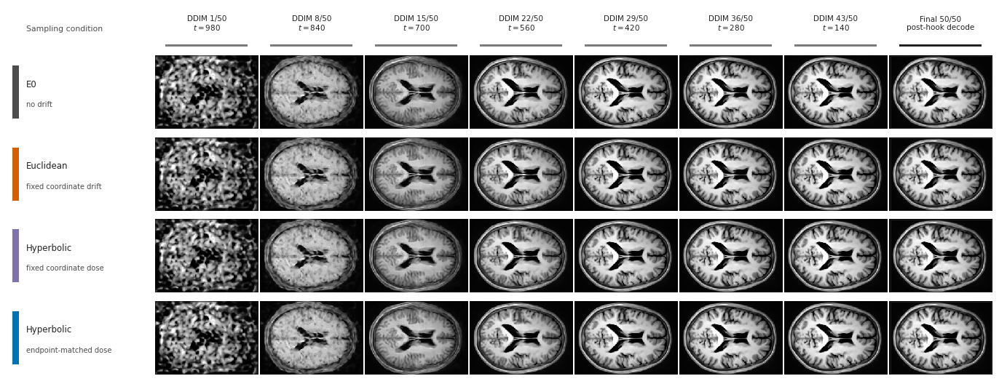

Clean Figure 1a denoising panel completed.
No new DDIM sampling was performed.
PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure1a_denoising_trajectories_panel_only_seed_007.png
PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure1a_denoising_trajectories_panel_only_seed_007.pdf
SVG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure1a_denoising_trajectories_panel_only_seed_007.svg


In [39]:
# Cell 39a — Figure 1a | Clean wide denoising trajectory panel only
# Run after all experiments. No new DDIM sampling is performed.

import numpy as np
import torch
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image


required_symbols = [
    "CFG",
    "RESULTS",
    "trajectory_results",
    "ddim_scheduler",
    "decode_predicted_clean_frames",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing objects:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\n\nRun Cell 28 before this figure-rendering cell."
    )


CONDITIONS = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]

ROW_LABELS = {
    "E0": ("E0", "no drift"),
    "Euclidean": ("Euclidean", "fixed coordinate drift"),
    "Hyperbolic fixed delta": (
        "Hyperbolic",
        "fixed coordinate dose",
    ),
    "Hyperbolic endpoint-matched": (
        "Hyperbolic",
        "endpoint-matched dose",
    ),
}

ROW_COLORS = {
    "E0": "#4D4D4D",
    "Euclidean": "#D55E00",
    "Hyperbolic fixed delta": "#8073AC",
    "Hyperbolic endpoint-matched": "#0072B2",
}


def timestep_to_int(timestep):
    return (
        int(timestep.detach().cpu())
        if torch.is_tensor(timestep)
        else int(timestep)
    )


def save_png_pdf_svg(figure, png_path, pdf_path, svg_path):
    figure.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )

    temporary_rgb_path = png_path.with_name(
        f"{png_path.stem}_temporary_rgb.png"
    )

    with Image.open(png_path) as image:
        image.convert("RGB").save(
            temporary_rgb_path,
            dpi=(600, 600),
        )

    temporary_rgb_path.replace(png_path)

    figure.savefig(
        pdf_path,
        format="pdf",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )

    figure.savefig(
        svg_path,
        format="svg",
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )


# Seven evenly spaced predicted-clean states plus the actual final decode.
predicted_x0_trace = trajectory_results["E0"]["trace_tensors"][
    "predicted_x0_scaled"
]

n_ddim_steps = int(predicted_x0_trace.shape[0])
n_columns = 8

if n_ddim_steps < n_columns:
    raise ValueError(
        f"Expected at least {n_columns} DDIM steps; found {n_ddim_steps}."
    )

scheduler_timesteps = [
    timestep_to_int(timestep)
    for timestep in ddim_scheduler.timesteps
]

if len(scheduler_timesteps) != n_ddim_steps:
    raise ValueError(
        "DDIM scheduler timesteps and stored trajectory length differ."
    )

visual_reverse_steps = np.rint(
    np.linspace(0, n_ddim_steps - 1, n_columns)
).astype(int)

if len(np.unique(visual_reverse_steps)) != n_columns:
    raise RuntimeError("Could not construct eight unique DDIM checkpoints.")

predicted_clean_steps = visual_reverse_steps[:-1].tolist()

# Decode stored latent states only — no new sampling.
decoded_frames = {
    condition: decode_predicted_clean_frames(
        trajectory_results[condition],
        predicted_clean_steps,
    )
    for condition in CONDITIONS
}

# One shared intensity scale across every row and frame.
e0_final = decoded_frames["E0"]["final_post_hook"]["mri_images"][
    "T1w MPRAGE"
][0]

reference_values = (
    e0_final.detach().float().cpu().numpy()
)
reference_values = reference_values[np.isfinite(reference_values)]

frame_vmin, frame_vmax = np.quantile(
    reference_values,
    [0.01, 0.99],
)

frame_vmin = float(frame_vmin)
frame_vmax = float(frame_vmax)

if frame_vmax <= frame_vmin:
    frame_vmax = frame_vmin + 1e-6


# Output paths.
figure_dir = RESULTS / "manuscript" / "figures" / "main"
figure_dir.mkdir(parents=True, exist_ok=True)

seed_tag = f"{int(CFG['reference_seed']):03d}"
figure_stem = (
    f"figure1a_denoising_trajectories_panel_only_seed_{seed_tag}"
)

png_path = figure_dir / f"{figure_stem}.png"
pdf_path = figure_dir / f"{figure_stem}.pdf"
svg_path = figure_dir / f"{figure_stem}.svg"


plot_style = {
    "font.family": "DejaVu Sans",
    "font.size": 8.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

with mpl.rc_context(plot_style):
    figure = plt.figure(figsize=(13.8, 5.35))

    grid = figure.add_gridspec(
        nrows=1 + len(CONDITIONS),
        ncols=1 + n_columns,
        height_ratios=[0.54] + [1.0] * len(CONDITIONS),
        width_ratios=[1.42] + [1.0] * n_columns,
        left=0.018,
        right=0.998,
        bottom=0.035,
        top=0.985,
        wspace=0.018,
        hspace=0.050,
    )

    # Left-aligned header, deliberately aligned with all row labels.
    condition_header_axis = figure.add_subplot(grid[0, 0])
    condition_header_axis.axis("off")
    condition_header_axis.text(
        0.13,
        0.48,
        "Sampling condition",
        transform=condition_header_axis.transAxes,
        fontsize=7.8,
        color="#4D4D4D",
        ha="left",
        va="center",
    )

    # DDIM checkpoint headers.
    for column_index, reverse_step in enumerate(visual_reverse_steps):
        header_axis = figure.add_subplot(grid[0, column_index + 1])
        header_axis.axis("off")

        is_final_column = column_index == n_columns - 1

        if is_final_column:
            header_text = (
                f"Final {n_ddim_steps}/{n_ddim_steps}\n"
                "post-hook decode"
            )
            stripe_color = "#222222"
        else:
            header_text = (
                f"DDIM {reverse_step + 1}/{n_ddim_steps}\n"
                f"$t = {scheduler_timesteps[reverse_step]}$"
            )
            stripe_color = "#7A7A7A"

        header_axis.text(
            0.50,
            0.61,
            header_text,
            transform=header_axis.transAxes,
            fontsize=7.5,
            color="#222222",
            ha="center",
            va="center",
            linespacing=1.10,
        )

        header_axis.add_patch(
            Rectangle(
                (0.10, 0.06),
                0.80,
                0.055,
                transform=header_axis.transAxes,
                facecolor=stripe_color,
                edgecolor="none",
                clip_on=False,
            )
        )

    # Four sampling-condition rows.
    for row_index, condition in enumerate(CONDITIONS):
        label_axis = figure.add_subplot(grid[row_index + 1, 0])
        label_axis.axis("off")

        main_label, detail_label = ROW_LABELS[condition]

        label_axis.add_patch(
            Rectangle(
                (0.035, 0.16),
                0.045,
                0.68,
                transform=label_axis.transAxes,
                facecolor=ROW_COLORS[condition],
                edgecolor="none",
                clip_on=False,
            )
        )

        label_axis.text(
            0.13,
            0.60,
            main_label,
            transform=label_axis.transAxes,
            fontsize=8.5,
            fontweight="medium",
            color="#222222",
            ha="left",
            va="center",
        )

        label_axis.text(
            0.13,
            0.34,
            detail_label,
            transform=label_axis.transAxes,
            fontsize=7.1,
            color="#4D4D4D",
            ha="left",
            va="center",
        )

        predicted_clean_frames = decoded_frames[condition][
            "predicted_clean"
        ]["mri_images"]["T1w MPRAGE"]

        final_post_hook_frame = decoded_frames[condition][
            "final_post_hook"
        ]["mri_images"]["T1w MPRAGE"][0]

        for column_index in range(n_columns):
            image_axis = figure.add_subplot(
                grid[row_index + 1, column_index + 1]
            )

            image_tensor = (
                final_post_hook_frame
                if column_index == n_columns - 1
                else predicted_clean_frames[column_index]
            )

            image_axis.imshow(
                image_tensor.detach().float().cpu().numpy(),
                cmap="gray",
                vmin=frame_vmin,
                vmax=frame_vmax,
                interpolation="nearest",
            )

            image_axis.set_axis_off()

            # Minimal cue: only the final decoded output receives a fine frame.
            if column_index == n_columns - 1:
                image_axis.add_patch(
                    Rectangle(
                        (0.01, 0.01),
                        0.98,
                        0.98,
                        transform=image_axis.transAxes,
                        fill=False,
                        edgecolor="#222222",
                        linewidth=0.65,
                        clip_on=False,
                    )
                )

    save_png_pdf_svg(
        figure,
        png_path,
        pdf_path,
        svg_path,
    )

    plt.show()
    plt.close(figure)


print("Clean Figure 1a denoising panel completed.")
print("No new DDIM sampling was performed.")
print("PNG (RGB, 600 dpi):", png_path)
print("PDF:", pdf_path)
print("SVG:", svg_path)

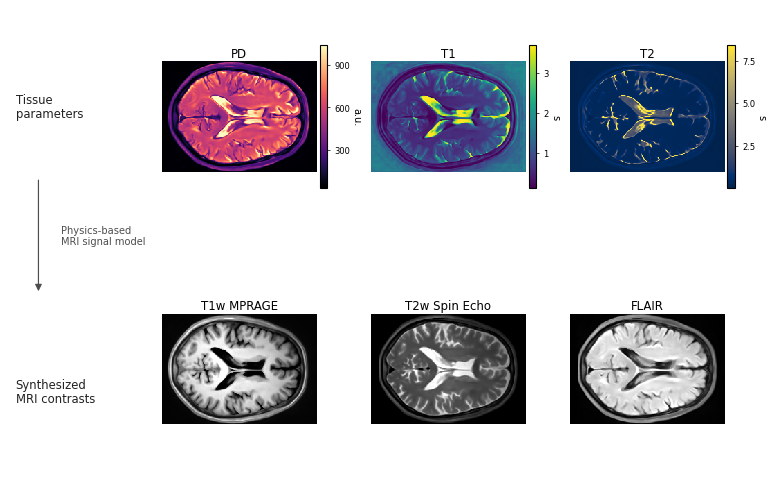

Clean Figure 1c physical-synthesis panel completed.
PNG (RGB, 600 dpi): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure1c_physical_synthesis_panel_only_seed_007.png
PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure1c_physical_synthesis_panel_only_seed_007.pdf
SVG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure1c_physical_synthesis_panel_only_seed_007.svg


In [40]:
# Cell 39b — Figure 1c | Physical synthesis panel only
# Requires Cell 8 outputs. No new inference or physical rendering is run.

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Rectangle
from PIL import Image


required_symbols = [
    "MANUSCRIPT_RESULTS",
    "e0_seed",
    "e0_q_maps",
    "e0_mri_images",
    "e0_display_windows",
    "q_map_specs",
    "mri_specs",
]

missing_symbols = [
    name for name in required_symbols if name not in globals()
]

if missing_symbols:
    raise RuntimeError(
        "Missing Cell 8 outputs:\n"
        + "\n".join(f"  - {name}" for name in missing_symbols)
        + "\n\nRun Cell 8 before this figure-rendering cell."
    )


def save_png_pdf_svg(figure, png_path, pdf_path, svg_path):
    figure.savefig(
        png_path,
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="white",
    )

    temporary_rgb_path = png_path.with_name(
        f"{png_path.stem}_temporary_rgb.png"
    )

    with Image.open(png_path) as image:
        image.convert("RGB").save(
            temporary_rgb_path,
            dpi=(600, 600),
        )

    temporary_rgb_path.replace(png_path)

    for path, output_format in [
        (pdf_path, "pdf"),
        (svg_path, "svg"),
    ]:
        figure.savefig(
            path,
            format=output_format,
            dpi=600,
            bbox_inches="tight",
            facecolor="white",
            edgecolor="white",
        )


figure_dir = MANUSCRIPT_RESULTS / "figures" / "main"
figure_dir.mkdir(parents=True, exist_ok=True)

figure_stem = (
    f"figure1c_physical_synthesis_panel_only_seed_{int(e0_seed):03d}"
)

png_path = figure_dir / f"{figure_stem}.png"
pdf_path = figure_dir / f"{figure_stem}.pdf"
svg_path = figure_dir / f"{figure_stem}.svg"

font_name = globals().get("manuscript_font", "DejaVu Sans")

plot_style = {
    "font.family": font_name,
    "font.size": 8,
    "axes.titleweight": "regular",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}

with mpl.rc_context(plot_style):
    figure = plt.figure(
        figsize=(7.65, 4.75),
        constrained_layout=True,
    )

    grid = figure.add_gridspec(
        2,
        4,
        width_ratios=[0.92, 1.0, 1.0, 1.0],
        wspace=0.05,
        hspace=0.08,
    )

    # Left explanatory gutter: no panel letter, only the physical relation.
    flow_axis = figure.add_subplot(grid[:, 0])
    flow_axis.axis("off")

    flow_axis.text(
        0.04,
        0.79,
        "Tissue\nparameters",
        transform=flow_axis.transAxes,
        fontsize=8.4,
        fontweight="medium",
        color="#222222",
        ha="left",
        va="center",
        linespacing=1.10,
    )

    flow_axis.annotate(
        "",
        xy=(0.20, 0.39),
        xytext=(0.20, 0.64),
        xycoords="axes fraction",
        arrowprops={
            "arrowstyle": "-|>",
            "color": "#4D4D4D",
            "lw": 0.85,
            "mutation_scale": 10,
        },
    )

    flow_axis.text(
        0.36,
        0.515,
        "Physics-based\nMRI signal model",
        transform=flow_axis.transAxes,
        fontsize=7.1,
        color="#4D4D4D",
        ha="left",
        va="center",
        linespacing=1.10,
    )

    flow_axis.text(
        0.04,
        0.18,
        "Synthesized\nMRI contrasts",
        transform=flow_axis.transAxes,
        fontsize=8.4,
        fontweight="medium",
        color="#222222",
        ha="left",
        va="center",
        linespacing=1.10,
    )

    # Top row: physical tissue-parameter maps with their original colorbars.
    for index, (map_name, unit, cmap) in enumerate(q_map_specs):
        axis = figure.add_subplot(grid[0, index + 1])

        image = e0_q_maps[index].detach().float().cpu().numpy()
        vmin, vmax = e0_display_windows[map_name]

        image_handle = axis.imshow(
            image,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            rasterized=True,
        )

        axis.set_title(map_name, pad=3, fontsize=8.5)
        axis.axis("off")

        colorbar = figure.colorbar(
            image_handle,
            ax=axis,
            fraction=0.046,
            pad=0.02,
        )

        colorbar.set_label(
            unit,
            rotation=270,
            labelpad=8,
            fontsize=7,
        )

        colorbar.ax.yaxis.set_major_locator(
            MaxNLocator(nbins=4)
        )
        colorbar.ax.tick_params(
            labelsize=6,
            width=0.5,
            length=2.0,
        )

    # Bottom row: physically synthesized MRI contrasts.
    for index, (contrast_name, cmap) in enumerate(mri_specs):
        axis = figure.add_subplot(grid[1, index + 1])

        image = (
            e0_mri_images[contrast_name]
            .detach()
            .float()
            .cpu()
            .numpy()
        )

        vmin, vmax = e0_display_windows[contrast_name]

        axis.imshow(
            image,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
            rasterized=True,
        )

        axis.set_title(contrast_name, pad=3, fontsize=8.5)
        axis.axis("off")

    save_png_pdf_svg(
        figure,
        png_path,
        pdf_path,
        svg_path,
    )

    plt.show()
    plt.close(figure)


print("Clean Figure 1c physical-synthesis panel completed.")
print("PNG (RGB, 600 dpi):", png_path)
print("PDF:", pdf_path)
print("SVG:", svg_path)

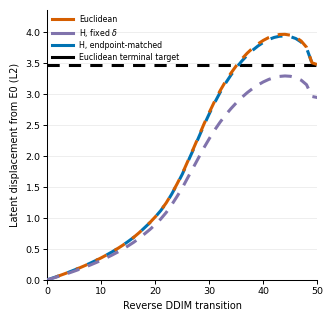

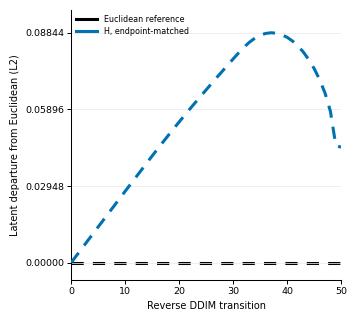

Figure 2a:
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2a_terminal_displacement_trajectory_seed_007.png
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2a_terminal_displacement_trajectory_seed_007.pdf
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2a_terminal_displacement_trajectory_seed_007.svg
Figure 2b:
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2b_geometry_specific_trajectory_seed_007.png
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2b_geometry_specific_trajectory_seed_007.pdf
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2b_geometry_specific_trajectory_seed_007.svg


In [41]:
# Cell 40a–b — Pure Figure 2 trajectory panels

from pathlib import Path

from PIL import Image
from matplotlib.lines import Line2D
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


required = ["CFG", "RESULTS", "trajectory_results"]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Missing: " + ", ".join(missing))

conditions = [
    "E0",
    "Euclidean",
    "Hyperbolic fixed delta",
    "Hyperbolic endpoint-matched",
]
missing_conditions = [
    name for name in conditions if name not in trajectory_results
]
if missing_conditions:
    raise RuntimeError(
        "Missing conditions: " + ", ".join(missing_conditions)
    )


RESULTS = Path(RESULTS)
SEED = int(CFG["reference_seed"])

FIGURE_DIR = RESULTS / "manuscript" / "figures" / "main"
DATA_DIR = RESULTS / "manuscript" / "data" / "figure2_panels"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Reuse these exact constants for Figure 2c and 2d.
PANEL_SIZE_INCH = 3.60
LW = 2.2
PNG_DPI = 600

# Fixed manuscript palette: identical to Figure 1c.
COLORS = {
    "Euclidean": "#D55E00",
    "Hyperbolic fixed delta": "#8073AC",
    "Hyperbolic endpoint-matched": "#0072B2",
}

# Every plotted line has the same dash pattern and linewidth.
DASH = (0, (4, 3))

# Same dash pattern, shifted only to reveal orange–blue overlap in Figure 2a.
ORANGE_PHASE_SHIFT = (4, (4, 3))


def l2_distance(condition, reference):
    state = trajectory_results[condition]["trace_tensors"][
        "modified_x_prev_scaled"
    ]
    reference_state = trajectory_results[reference]["trace_tensors"][
        "modified_x_prev_scaled"
    ]

    values = torch.linalg.vector_norm(
        (state - reference_state).flatten(start_dim=1),
        dim=1,
    ).detach().cpu().numpy()

    return np.r_[0.0, values]


def make_panel():
    fig, ax = plt.subplots(
        figsize=(PANEL_SIZE_INCH, PANEL_SIZE_INCH)
    )
    fig.subplots_adjust(
        left=0.225,
        right=0.975,
        bottom=0.205,
        top=0.975,
    )

    ax.set_box_aspect(1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.grid(axis="y", color="#EAEAEA", linewidth=0.55, zorder=0)
    ax.tick_params(
        labelsize=6.8,
        width=0.7,
        length=2.8,
        direction="out",
        pad=2,
    )
    return fig, ax


def save_panel(fig, stem):
    paths = {
        "png": FIGURE_DIR / f"{stem}.png",
        "pdf": FIGURE_DIR / f"{stem}.pdf",
        "svg": FIGURE_DIR / f"{stem}.svg",
    }

    fig.savefig(
        paths["png"],
        dpi=PNG_DPI,
        facecolor="white",
        edgecolor="white",
    )

    with Image.open(paths["png"]) as image:
        image.convert("RGB").save(
            paths["png"],
            dpi=(PNG_DPI, PNG_DPI),
        )

    fig.savefig(paths["pdf"], format="pdf", facecolor="white")
    fig.savefig(paths["svg"], format="svg", facecolor="white")
    return paths


euclidean_e0 = l2_distance("Euclidean", "E0")
fixed_e0 = l2_distance("Hyperbolic fixed delta", "E0")
matched_e0 = l2_distance("Hyperbolic endpoint-matched", "E0")
matched_euclidean = l2_distance(
    "Hyperbolic endpoint-matched",
    "Euclidean",
)

n_steps = len(euclidean_e0) - 1
steps = np.arange(n_steps + 1)
ticks = np.linspace(0, n_steps, 6, dtype=int)
euclidean_target = euclidean_e0[-1]

pd.DataFrame(
    {
        "reverse_ddim_transition": steps,
        "euclidean_distance_from_e0_l2": euclidean_e0,
        "fixed_hyperbolic_distance_from_e0_l2": fixed_e0,
        "matched_hyperbolic_distance_from_e0_l2": matched_e0,
        "matched_hyperbolic_distance_from_euclidean_l2": (
            matched_euclidean
        ),
    }
).to_csv(
    DATA_DIR / f"figure2ab_trajectory_source_data_seed_{SEED:03d}.csv",
    index=False,
)


with mpl.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 7,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
):
    # Figure 2a — matched displacement from E0.
    fig_a, ax_a = make_panel()

    ax_a.axhline(
        euclidean_target,
        color="black",
        linestyle=DASH,
        linewidth=LW,
        zorder=1,
    )

    # Blue first, orange phase-shifted above it:
    # overlapping trajectories appear as visible blue–orange alternation.
    ax_a.plot(
        steps,
        matched_e0,
        color=COLORS["Hyperbolic endpoint-matched"],
        linestyle=DASH,
        linewidth=LW,
        zorder=3,
    )

    ax_a.plot(
        steps,
        euclidean_e0,
        color=COLORS["Euclidean"],
        linestyle=ORANGE_PHASE_SHIFT,
        linewidth=LW,
        zorder=4,
    )

    ax_a.plot(
        steps,
        fixed_e0,
        color=COLORS["Hyperbolic fixed delta"],
        linestyle=DASH,
        linewidth=LW,
        zorder=5,
    )

    ax_a.set(
        xlim=(0, n_steps),
        ylim=(
            0,
            1.10 * max(
                euclidean_e0.max(),
                fixed_e0.max(),
                matched_e0.max(),
            ),
        ),
        xticks=ticks,
        xlabel="Reverse DDIM transition",
        ylabel="Latent displacement from E0 (L2)",
    )

    # Legend encodes colour only: equal-length solid swatches.
    ax_a.legend(
        handles=[
            Line2D(
                [0], [0],
                color=COLORS["Euclidean"],
                linestyle="-",
                linewidth=LW,
                label="Euclidean",
            ),
            Line2D(
                [0], [0],
                color=COLORS["Hyperbolic fixed delta"],
                linestyle="-",
                linewidth=LW,
                label=r"H, fixed $\delta$",
            ),
            Line2D(
                [0], [0],
                color=COLORS["Hyperbolic endpoint-matched"],
                linestyle="-",
                linewidth=LW,
                label="H, endpoint-matched",
            ),
            Line2D(
                [0], [0],
                color="black",
                linestyle="-",
                linewidth=LW,
                label="Euclidean terminal target",
            ),
        ],
        loc="upper left",
        frameon=False,
        fontsize=5.65,
        handlelength=2.6,
        labelspacing=0.32,
        borderpad=0.15,
    )

    paths_a = save_panel(
        fig_a,
        f"figure2a_terminal_displacement_trajectory_seed_{SEED:03d}",
    )

    plt.show()
    plt.close(fig_a)

    # Figure 2b — matched hyperbolic path remains non-Euclidean.
    fig_b, ax_b = make_panel()

    path_max = max(float(matched_euclidean.max()), 1e-12)
    baseline_padding = 0.075 * path_max

    ax_b.axhline(
        0.0,
        color="black",
        linestyle=DASH,
        linewidth=LW,
        zorder=1,
    )

    ax_b.plot(
        steps,
        matched_euclidean,
        color=COLORS["Hyperbolic endpoint-matched"],
        linestyle=DASH,
        linewidth=LW,
        zorder=3,
    )

    ax_b.set(
        xlim=(0, n_steps),
        ylim=(-baseline_padding, 1.10 * path_max),
        xticks=ticks,
        yticks=np.linspace(0.0, path_max, 4),
        xlabel="Reverse DDIM transition",
        ylabel="Latent departure from Euclidean (L2)",
    )

    # Legend encodes colour only: equal-length solid swatches.
    ax_b.legend(
        handles=[
            Line2D(
                [0], [0],
                color="black",
                linestyle="-",
                linewidth=LW,
                label="Euclidean reference",
            ),
            Line2D(
                [0], [0],
                color=COLORS["Hyperbolic endpoint-matched"],
                linestyle="-",
                linewidth=LW,
                label="H, endpoint-matched",
            ),
        ],
        loc="upper left",
        frameon=False,
        fontsize=5.8,
        handlelength=2.6,
        labelspacing=0.35,
        borderpad=0.15,
    )

    paths_b = save_panel(
        fig_b,
        f"figure2b_geometry_specific_trajectory_seed_{SEED:03d}",
    )

    plt.show()
    plt.close(fig_b)

print("Figure 2a:", *paths_a.values(), sep="\n  ")
print("Figure 2b:", *paths_b.values(), sep="\n  ")

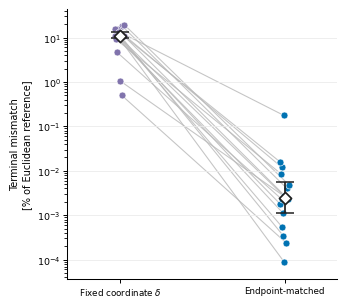

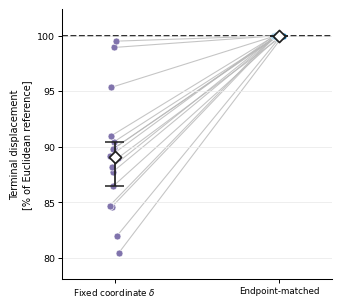

Figure 2c:
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2c_endpoint_mismatch_multiseed.png
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2c_endpoint_mismatch_multiseed.pdf
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2c_endpoint_mismatch_multiseed.svg
Figure 2d:
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2d_terminal_displacement_multiseed.png
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2d_terminal_displacement_multiseed.pdf
  /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main/figure2d_terminal_displacement_multiseed.svg


In [42]:
# Cell 41a–b — Pure Figure 2 multiseed endpoint-fairness panels

from pathlib import Path

from PIL import Image
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


if "RESULTS" not in globals():
    raise RuntimeError("Run the earlier manuscript cells first.")

RESULTS = Path(RESULTS)

STUDY_DIR = (
    RESULTS
    / "manuscript"
    / "data"
    / "multiseed_endpoint_matched_geometry"
)

SOURCE_PATH = STUDY_DIR / "endpoint_matching_fairness_per_seed.csv"
if not SOURCE_PATH.is_file():
    raise FileNotFoundError(
        f"Missing {SOURCE_PATH}. Run the original Cell 35 first."
    )

FIGURE_DIR = RESULTS / "manuscript" / "figures" / "main"
DATA_DIR = RESULTS / "manuscript" / "data" / "figure2_panels"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Identical outer geometry to Figure 2a and 2b.
PANEL_SIZE_INCH = 3.60
PNG_DPI = 600

# Fixed manuscript palette: identical to Figure 1c and Figure 2a–b.
FIXED_COLOR = "#8073AC"
MATCHED_COLOR = "#0072B2"
PAIRED_COLOR = "#B8B8B8"
SUMMARY_COLOR = "#202020"
GRID_COLOR = "#EAEAEA"

BOOTSTRAP_RESAMPLES = 20_000
BOOTSTRAP_SEED = 20261004

fairness_df = pd.read_csv(SOURCE_PATH)

required_columns = [
    "fixed_endpoint_mismatch_percent",
    "matched_endpoint_mismatch_percent",
    "fixed_terminal_percent_of_euclidean",
    "matched_terminal_percent_of_euclidean",
]

missing_columns = [
    name for name in required_columns if name not in fairness_df.columns
]
if missing_columns:
    raise KeyError("Missing columns: " + ", ".join(missing_columns))

fairness_df.to_csv(
    DATA_DIR / "figure2cd_endpoint_fairness_source_data.csv",
    index=False,
)

fixed_mismatch = fairness_df[
    "fixed_endpoint_mismatch_percent"
].to_numpy(dtype=float)

matched_mismatch = fairness_df[
    "matched_endpoint_mismatch_percent"
].to_numpy(dtype=float)

fixed_terminal = fairness_df[
    "fixed_terminal_percent_of_euclidean"
].to_numpy(dtype=float)

matched_terminal = fairness_df[
    "matched_terminal_percent_of_euclidean"
].to_numpy(dtype=float)

if np.any(matched_mismatch <= 0.0):
    raise ValueError("Log-scale mismatch values must be positive.")


def median_ci(values, rng):
    values = np.asarray(values, dtype=float)
    median = float(np.median(values))

    indices = rng.integers(
        0,
        len(values),
        size=(BOOTSTRAP_RESAMPLES, len(values)),
    )
    bootstrap_medians = np.median(values[indices], axis=1)
    low, high = np.quantile(bootstrap_medians, [0.025, 0.975])

    return median, float(low), float(high)


def make_panel():
    fig, ax = plt.subplots(
        figsize=(PANEL_SIZE_INCH, PANEL_SIZE_INCH)
    )
    fig.subplots_adjust(
        left=0.225,
        right=0.975,
        bottom=0.205,
        top=0.975,
    )

    ax.set_box_aspect(1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.75)
    ax.spines["bottom"].set_linewidth(0.75)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.55, zorder=0)
    ax.tick_params(
        labelsize=6.8,
        width=0.7,
        length=2.8,
        direction="out",
        pad=2,
    )
    return fig, ax


def add_summary_marker(ax, x, values, rng):
    median, low, high = median_ci(values, rng)
    cap = 0.055

    # Drawn above the 100% reference line; full CI always remains visible.
    ax.vlines(
        x,
        low,
        high,
        color=SUMMARY_COLOR,
        linewidth=1.25,
        zorder=7,
        clip_on=False,
    )
    ax.hlines(
        [low, high],
        x - cap,
        x + cap,
        color=SUMMARY_COLOR,
        linewidth=1.10,
        zorder=7,
        clip_on=False,
    )
    ax.scatter(
        x,
        median,
        marker="D",
        s=38,
        facecolor="white",
        edgecolor=SUMMARY_COLOR,
        linewidth=1.25,
        zorder=8,
        clip_on=False,
    )

    return median, low, high


def plot_paired_values(ax, fixed_values, matched_values, rng, jitter):
    for left, right, offset in zip(
        fixed_values,
        matched_values,
        jitter,
    ):
        ax.plot(
            [offset, 1.0 + offset],
            [left, right],
            color=PAIRED_COLOR,
            linewidth=0.78,
            alpha=0.82,
            solid_capstyle="round",
            zorder=1,
        )

    ax.scatter(
        jitter,
        fixed_values,
        s=25,
        color=FIXED_COLOR,
        edgecolor="white",
        linewidth=0.45,
        zorder=4,
    )

    ax.scatter(
        1.0 + jitter,
        matched_values,
        s=25,
        color=MATCHED_COLOR,
        edgecolor="white",
        linewidth=0.45,
        zorder=4,
    )

    summaries = [
        add_summary_marker(ax, 0.0, fixed_values, rng),
        add_summary_marker(ax, 1.0, matched_values, rng),
    ]

    ax.set(
        xlim=(-0.32, 1.32),
        xticks=[0.0, 1.0],
    )
    ax.set_xticklabels(
        [r"Fixed coordinate $\delta$", "Endpoint-matched"],
        fontsize=6.35,
    )

    return summaries


def save_panel(fig, stem):
    paths = {
        "png": FIGURE_DIR / f"{stem}.png",
        "pdf": FIGURE_DIR / f"{stem}.pdf",
        "svg": FIGURE_DIR / f"{stem}.svg",
    }

    fig.savefig(
        paths["png"],
        dpi=PNG_DPI,
        facecolor="white",
        edgecolor="white",
    )

    with Image.open(paths["png"]) as image:
        image.convert("RGB").save(
            paths["png"],
            dpi=(PNG_DPI, PNG_DPI),
        )

    fig.savefig(paths["pdf"], format="pdf", facecolor="white")
    fig.savefig(paths["svg"], format="svg", facecolor="white")
    return paths


summary_rng = np.random.default_rng(BOOTSTRAP_SEED)
jitter = np.random.default_rng(BOOTSTRAP_SEED + 1).normal(
    loc=0.0,
    scale=0.020,
    size=len(fixed_mismatch),
)

with mpl.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 7,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    }
):
    # Figure 2c — terminal mismatch across 16 seeds.
    fig_c, ax_c = make_panel()

    mismatch_summaries = plot_paired_values(
        ax_c,
        fixed_mismatch,
        matched_mismatch,
        summary_rng,
        jitter,
    )

    mismatch_bounds = np.array(
        [
            *fixed_mismatch,
            *matched_mismatch,
            *np.ravel(mismatch_summaries),
        ]
    )

    ax_c.set_yscale("log")
    ax_c.set_ylim(
        max(float(mismatch_bounds.min()) * 0.40, 1e-6),
        float(mismatch_bounds.max()) * 2.20,
    )
    ax_c.set_ylabel(
        "Terminal mismatch\n[% of Euclidean reference]"
    )

    paths_c = save_panel(
        fig_c,
        "figure2c_endpoint_mismatch_multiseed",
    )

    plt.show()
    plt.close(fig_c)

    # Figure 2d — terminal displacement restored by endpoint matching.
    fig_d, ax_d = make_panel()

    # Reference first; diamonds and CI whiskers are drawn on top.
    ax_d.axhline(
        100.0,
        color="black",
        linestyle="--",
        linewidth=1.15,
        zorder=0,
    )

    terminal_summaries = plot_paired_values(
        ax_d,
        fixed_terminal,
        matched_terminal,
        summary_rng,
        jitter,
    )

    terminal_bounds = np.array(
        [
            *fixed_terminal,
            *matched_terminal,
            *np.ravel(terminal_summaries),
            100.0,
        ]
    )

    terminal_range = float(
        terminal_bounds.max() - terminal_bounds.min()
    )
    terminal_padding = max(1.0, 0.12 * terminal_range)

    ax_d.set_ylim(
        max(0.0, float(terminal_bounds.min()) - terminal_padding),
        float(terminal_bounds.max()) + terminal_padding,
    )
    ax_d.set_ylabel(
        "Terminal displacement\n[% of Euclidean reference]"
    )

    paths_d = save_panel(
        fig_d,
        "figure2d_terminal_displacement_multiseed",
    )

    plt.show()
    plt.close(fig_d)

print("Figure 2c:", *paths_c.values(), sep="\n  ")
print("Figure 2d:", *paths_d.values(), sep="\n  ")

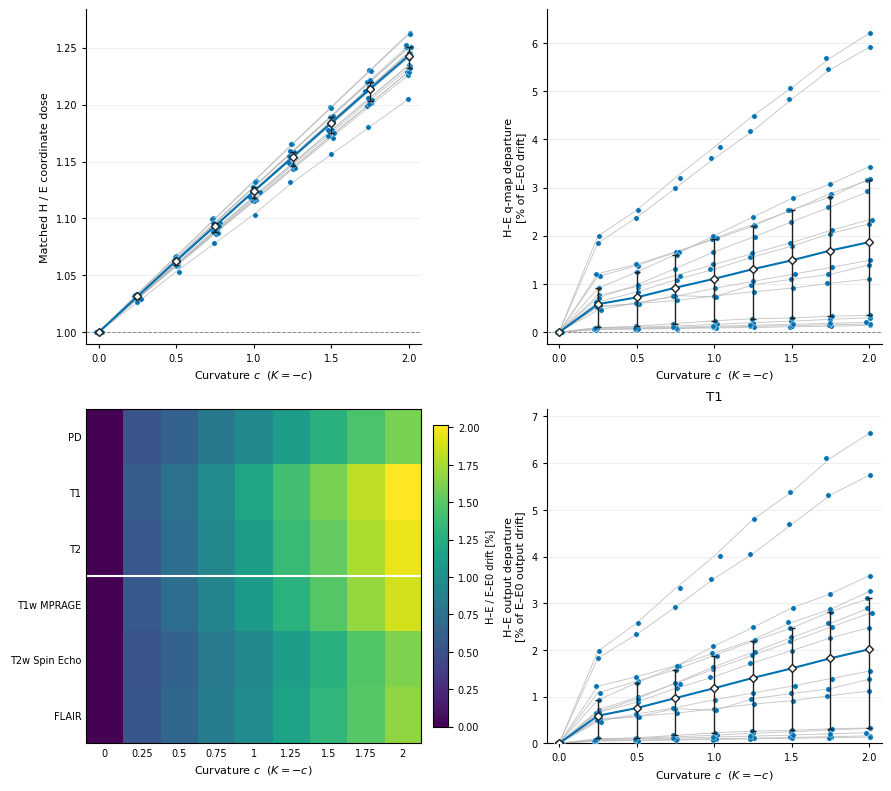

Saved PNG/PDF/SVG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main


In [43]:
# Cell 42 — Figure 3: calibration, response, outputs, trend consistency
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path(globals().get("RESULTS", Path.cwd() / "results/euclidean_audit"))
data = root / "manuscript/data/multiseed_endpoint_matched_geometry"
dest = root / "manuscript/figures/main"
dest.mkdir(parents=True, exist_ok=True)

c = pd.read_csv(data / "curvature_response_multiseed_source_data.csv")
o = pd.read_csv(data / "output_response_multiseed_source_data.csv")
names = ["PD [a.u.]", "T1 [s]", "T2 [s]", "T1w MPRAGE", "T2w Spin Echo", "FLAIR"]
labels = ["PD", "T1", "T2", "T1w MPRAGE", "T2w Spin Echo", "FLAIR"]
colors = ["#009E73", "#0072B2", "#D55E00", "#CC79A7", "#E69F00", "#56B4E9"]
seeds, cs = sorted(c.seed.unique()), sorted(c.curvature.unique())
assert cs[0] == 0 and set(o.output) == set(names)

def matrix(df, key):
    v = df.pivot(index="seed", columns="curvature", values=key)
    v = v.reindex(index=seeds, columns=cs).to_numpy(float)
    assert np.isfinite(v).all(), f"Incomplete/non-finite data: {key}"
    return v

dose = matrix(c, "matched_coordinate_dose_ratio")
qmap = matrix(c, "qmap_geometry_difference_percent_of_e0_drift")
outputs = np.stack([
    matrix(o[o.output == n], "geometry_difference_percent_of_e0_drift")
    for n in names
])
assert np.allclose(qmap[:, 0], 0, atol=1e-12)
assert np.allclose(outputs[:, :, 0], 0, atol=1e-12)

# Spearman rho across positive curvatures; constant responses remain undefined.
positive = np.asarray(cs) > 0
assert positive.sum() >= 3
xrank = pd.Series(np.asarray(cs)[positive]).rank().to_numpy()
rho = np.array([
    [np.corrcoef(xrank, pd.Series(v[positive]).rank())[0, 1] for v in out]
    for out in outputs
])

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8,
    "pdf.fonttype": 42, "svg.fonttype": "none"
})

def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=7, length=3)
    ax.grid(axis="y", color="#E9E9E9", lw=.5)
    ax.set_axisbelow(True)

def response(ax, v, color, ylabel, baseline):
    rng = np.random.default_rng(20261042)
    med = np.median(v, axis=0)
    idx = rng.integers(len(v), size=(20000, len(v)))
    lo, hi = np.quantile(np.median(v[idx], axis=1), [.025, .975], axis=0)

    ax.axhline(baseline, color="#888888", lw=.7, ls="--")
    ax.plot(cs, v.T, color="#B8B8B8", lw=.65, alpha=.8)
    jitter = np.random.default_rng(42).normal(0, .014, v.shape)
    ax.scatter((np.asarray(cs) + jitter).ravel(), v.ravel(),
               s=15, color=color, edgecolor="white", lw=.3, zorder=3)
    ax.plot(cs, med, color=color, lw=1.5, zorder=4)
    ax.errorbar(cs, med,
                yerr=np.maximum([med - lo, hi - med], 0),
                fmt="D", ms=4, mfc="white", mec="#202020",
                ecolor="#202020", elinewidth=1, capsize=2, zorder=5)

    span = max(np.ptp(v), 1e-6)
    ax.set(xlim=(-.08, 2.08), xticks=[0, .5, 1, 1.5, 2],
           ylim=(min(baseline, v.min()) - .04 * span,
                 v.max() + .08 * span),
           xlabel=r"Curvature $c$  ($K=-c$)", ylabel=ylabel)
    style(ax)

def panel_a(ax):
    response(ax, dose, "#0072B2", "Matched H / E coordinate dose", 1)

def panel_b(ax):
    response(ax, qmap, "#0072B2", "H–E q-map departure\n[% of E–E0 drift]", 0)

def panel_c(ax):
    med = np.median(outputs, axis=1)
    im = ax.imshow(med, aspect="auto", cmap="viridis", vmin=0, vmax=med.max())
    ax.set(yticks=range(6), yticklabels=labels, xticks=range(len(cs)),
           xticklabels=[f"{v:g}" for v in cs],
           xlabel=r"Curvature $c$  ($K=-c$)")
    ax.tick_params(labelsize=7, length=0)
    ax.axhline(2.5, color="white", lw=1.5)
    cb = ax.figure.colorbar(im, ax=ax, fraction=.045, pad=.035)
    cb.set_label("H–E / E–E0 drift [%]", fontsize=7)
    cb.ax.tick_params(labelsize=7)

def panel_d(ax):
    name = "T1 [s]"                 # 可改为 names 中的其他输出
    i = names.index(name)
    v, color = outputs[i], colors[i]

    s = pd.read_csv(data / "output_response_multiseed_statistics.csv")
    s = s[(s.output == name) &
          (s.metric == "geometry_difference_percent_of_e0_drift")]
    s = s.set_index("curvature_c").reindex(cs)
    med, lo, hi = s[["median", "ci95_low", "ci95_high"]].to_numpy().T
    assert np.isfinite([med, lo, hi]).all(), "Missing summary statistics"

    ax.plot(cs, v.T, color="#B8B8B8", lw=.65, alpha=.8)
    jitter = np.random.default_rng(42).normal(0, .014, v.shape)
    ax.scatter((np.asarray(cs) + jitter).ravel(), v.ravel(),
               s=15, color=color, edgecolor="white", lw=.3, zorder=3)
    ax.plot(cs, med, color=color, lw=1.5, zorder=4)
    ax.errorbar(cs, med,
                yerr=np.maximum([med - lo, hi - med], 0),
                fmt="D", ms=4, mfc="white", mec="#202020",
                ecolor="#202020", elinewidth=1, capsize=2, zorder=5)

    ax.set(xlim=(-.08, 2.08), ylim=(0, max(v.max(), hi.max()) * 1.08),
           xticks=[0, .5, 1, 1.5, 2],
           xlabel=r"Curvature $c$  ($K=-c$)",
           ylabel="H–E output departure\n[% of E–E0 output drift]",
           title=labels[i])
    style(ax)

def save(fig, stem):
    for ext in ("png", "pdf", "svg"):
        fig.savefig(dest / f"{stem}.{ext}", dpi=600,
                    bbox_inches="tight", pad_inches=.08, facecolor="white")

draw = [panel_a, panel_b, panel_c, panel_d]
for letter, painter in zip("abcd", draw):
    fig, ax = plt.subplots(figsize=(3.9, 3.6), layout="constrained")
    painter(ax)
    save(fig, f"figure3{letter}")
    plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(8.8, 7.8), layout="constrained")
for ax, painter in zip(axes.flat, draw):
    painter(ax)
save(fig, "figure3_preview")
plt.show()
plt.close(fig)

print("Saved PNG/PDF/SVG:", dest)
if not np.isfinite(rho).all():
    print("Undefined correlations (constant responses):", (~np.isfinite(rho)).sum())

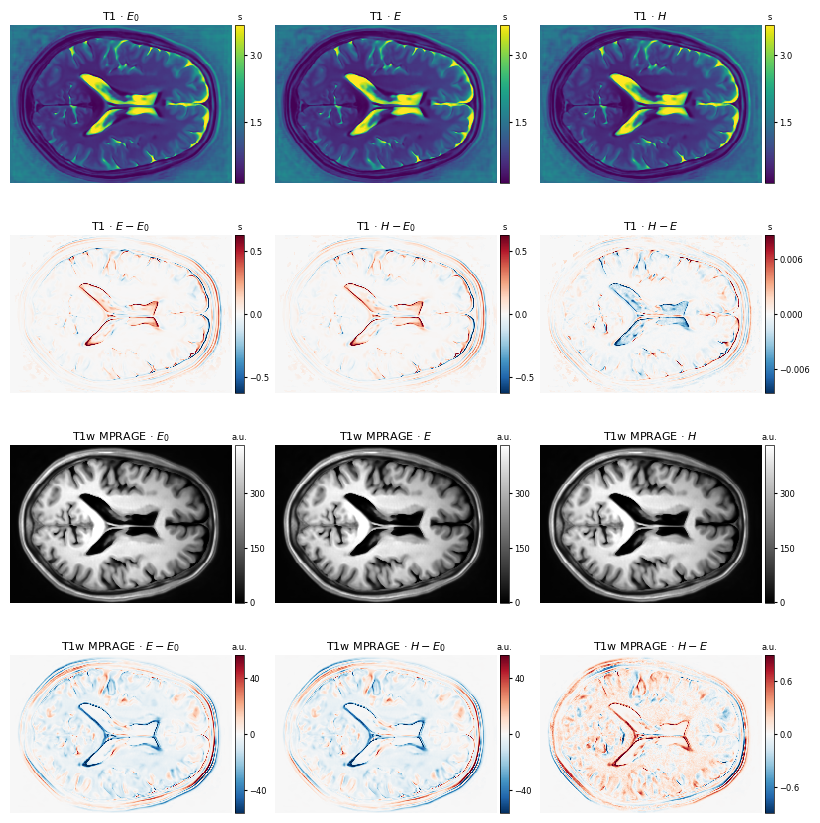

Saved Figure 3 PNG/PDF/SVG · seed 007: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/main


In [44]:
# Cell 43 — Figure 3: 12 panels with image-height colorbars
from pathlib import Path
import warnings
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable

root = Path(globals().get("RESULTS", Path.cwd() / "results/euclidean_audit"))
data = root / "manuscript/data/endpoint_matching"
dest = root / "manuscript/figures/main"
dest.mkdir(parents=True, exist_ok=True)
seed = int(globals().get("CFG", {}).get("reference_seed", 7))

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r"TypedStorage is deprecated.*",
                            category=UserWarning)
    p = torch.load(
        data / "fair_comparison" /
        f"endpoint_matched_physical_outputs_seed_{seed:03d}.pt",
        map_location="cpu", weights_only=True
    )

with np.load(data / "signed_difference_maps" /
             f"endpoint_matched_difference_arrays_seed_{seed:03d}.npz") as z:
    mask = z["tissue_mask"].astype(bool)
    diffs = {k: z[k].copy() for k in z.files if k != "tissue_mask"}

conditions = ["E0", "Euclidean", "Hyperbolic endpoint-matched"]
keys = ["euclidean_minus_e0", "hyperbolic_minus_e0", "hyperbolic_minus_euclidean"]
titles = [[r"$E_0$", r"$E$", r"$H$"],
          [r"$E-E_0$", r"$H-E_0$", r"$H-E$"]]
rows = [("T1", "t1_s", "s", "viridis"),
        ("T1w MPRAGE", "t1w_mprage", "a.u.", "gray")]

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8,
    "pdf.fonttype": 42, "svg.fonttype": "none"
})
cmap = plt.colormaps["RdBu_r"].copy()
cmap.set_bad("#F7F7F7")

fig = plt.figure(figsize=(7.8, 8.4), layout="constrained")
fig.get_layout_engine().set(
    w_pad=.08, h_pad=.015, wspace=.12, hspace=0
)
grid = fig.add_gridspec(4, 3)

for i, (name, prefix, unit, palette) in enumerate(rows):
    originals = []
    for condition in conditions:
        out = p["conditions"][condition]
        im = out["q_maps"][1] if name == "T1" else out["mri_images"][name]
        originals.append(im.detach().float().cpu().numpy().squeeze())

    changes = [diffs[f"{prefix}_{key}"] for key in keys]
    assert all(im.shape == mask.shape for im in originals + changes)
    for saved, calculated in zip(changes, [
        originals[1] - originals[0], originals[2] - originals[0],
        originals[2] - originals[1]
    ]):
        assert np.allclose(saved, calculated, equal_nan=True), "Source files disagree"

    valid = mask & np.isfinite(changes).all(axis=0)
    assert valid.any(), f"No valid pixels: {name}"
    shared = max(np.quantile(np.abs(np.concatenate(
        [im[valid] for im in changes[:2]])), .995), 1e-12)
    residual = max(np.quantile(np.abs(changes[2][valid]), .995), 1e-12)

    for kind in range(2):
        for j in range(3):
            ax = fig.add_subplot(grid[2 * i + kind, j])
            if kind == 0:
                im = originals[j]
                low, high = p["display_windows"][name]
                colors = palette
            else:
                im = np.ma.masked_where(~valid, changes[j])
                high = shared if j < 2 else residual
                low, colors = -high, cmap

            h = ax.imshow(im, cmap=colors, vmin=low, vmax=high,
                          interpolation="nearest")
            ax.set_title(f"{name} · {titles[kind][j]}", fontsize=8, pad=4)
            ax.axis("off")

            cax = make_axes_locatable(ax).append_axes("right", size="4%", pad=.04)
            cb = fig.colorbar(h, cax=cax)
            cb.ax.set_title(unit, fontsize=6, pad=4)
            cb.locator = MaxNLocator(nbins=3)
            cb.update_ticks()
            cb.ax.tick_params(labelsize=6, length=2, pad=2)
            cb.outline.set_linewidth(.5)

for ext in ("png", "pdf", "svg"):
    fig.savefig(dest / f"figure3_spatial_12panels_seed_{seed:03d}.{ext}",
                dpi=600, bbox_inches="tight", pad_inches=.04, facecolor="white")
plt.show()
plt.close(fig)
print(f"Saved Figure 3 PNG/PDF/SVG · seed {seed:03d}:", dest)

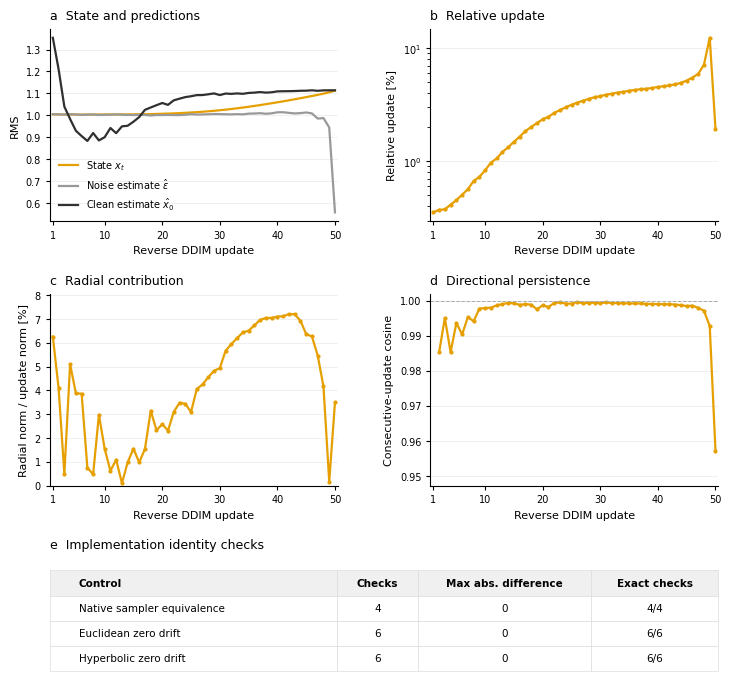

Figure S1 (600-dpi PNG / vector PDF / SVG): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary
Table S1 (CSV / vector PDF / SVG): /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/tables/supplementary
Source data, caption and provenance: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary/figure_s1
                   Control Checks Max abs. difference Exact checks
Native sampler equivalence      4                   0          4/4
      Euclidean zero drift      6                   0          6/6
     Hyperbolic zero drift      6                   0          6/6


In [45]:
# Cell 44 — Figure S1 + Table S1: native DDIM dynamics and identity controls
# Reads the saved CSVs from Cells 9, 10, 13 and 16; no model or sampling needed.
from pathlib import Path
import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def make_supplementary_s1(results, seed=7):
    base = Path(results) / "manuscript"
    data, verify = base / "data", base / "data/verification"
    dest, tables = base / "figures/supplementary", base / "tables/supplementary"
    source = data / "supplementary/figure_s1"
    tag = f"seed_{seed:03d}"
    trace_path = data / "trajectories" / f"native_e0_ddim_trace_{tag}.csv"
    checks = [
        ("Native sampler equivalence", 10, 4,
         verify / f"native_e0_equivalence_{tag}.csv"),
        ("Euclidean zero drift", 13, 6,
         verify / "zero_drift_identity" / f"zero_drift_identity_summary_{tag}.csv"),
        ("Hyperbolic zero drift", 16, 6,
         verify / "hyperbolic_zero_drift_identity" / f"hyperbolic_zero_drift_summary_{tag}.csv"),
    ]
    missing = [str(p) for p in [trace_path, *[s[3] for s in checks]] if not p.is_file()]
    if missing:
        raise FileNotFoundError("Missing saved source CSVs:\n" + "\n".join(missing))

    trace = pd.read_csv(trace_path).sort_values("reverse_step").reset_index(drop=True)
    cols = ["z_before_rms", "epsilon_rms", "pred_x0_rms", "relative_update",
            "radial_update_l2", "update_l2"]
    assert np.array_equal(trace.reverse_step, np.arange(50)), "Expected all 50 updates"
    assert np.isfinite(trace[cols].to_numpy(float)).all(), "Non-finite trajectory data"
    assert (trace.update_l2 > 0).all() and (trace.relative_update > 0).all()
    cosine = trace.consecutive_update_cosine.to_numpy(float)
    assert np.isnan(cosine[0]) and np.isfinite(cosine[1:]).all(), "Unexpected cosine values"
    trace["display_step"] = trace.reverse_step + 1
    trace["relative_update_percent"] = 100 * trace.relative_update
    trace["radial_fraction_percent"] = 100 * trace.radial_update_l2 / trace.update_l2

    errors = ["maximum_absolute_difference", "mean_absolute_difference",
              "root_mean_squared_difference"]
    frames, summary = [], []
    for label, cell, count, path in checks:
        df = pd.read_csv(path)
        exact_col = next(c for c in ("exact_tensor_equality", "exact_array_equality") if c in df)
        exact = df[exact_col].astype(str).str.strip().str.lower().map({"true": True, "false": False})
        assert len(df) == count and exact.notna().all(), f"Unexpected checks: {path.name}"
        values = df[errors].to_numpy(float)
        assert np.isfinite(values).all() and (values >= 0).all(), f"Invalid errors: {path.name}"
        df = df.drop(columns=exact_col).assign(exact_equality=exact, control=label,
                                              source_cell=cell, source_file=path.name, seed=seed)
        frames.append(df)
        summary.append([label, str(count), f"{values[:, 0].max():.3g}", f"{int(exact.sum())}/{count}"])
    full = pd.concat(frames, ignore_index=True)
    for folder in (dest, tables, source):
        folder.mkdir(parents=True, exist_ok=True)
    trace.to_csv(source / f"figure_s1_trajectory_{tag}.csv", index=False)
    full.to_csv(tables / f"table_s1_identity_checks_{tag}.csv", index=False)
    summary_df = pd.DataFrame(summary, columns=["Control", "Checks", "Max abs. difference", "Exact checks"])
    summary_df.to_csv(source / f"figure_s1_identity_summary_{tag}.csv", index=False)

    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 8,
                         "pdf.fonttype": 42, "svg.fonttype": "none"}):
        fig = plt.figure(figsize=(7.2, 6.8), layout="constrained")
        grid = fig.add_gridspec(3, 2, height_ratios=[1, 1, .64], hspace=.08, wspace=.06)
        axes = [fig.add_subplot(grid[r, c]) for r in range(2) for c in range(2)]
        x, orange = trace.display_step, "#E69F00"  # E0 retains the main-figure colour.
        for ax in axes:
            ax.spines[["top", "right"]].set_visible(False)
            ax.grid(axis="y", color="#E9E9E9", lw=.5)
            ax.set_axisbelow(True)
            ax.tick_params(labelsize=7, length=3)
            ax.set(xlim=(.5, 50.5), xticks=[1, 10, 20, 30, 40, 50], xlabel="Reverse DDIM update")
        for key, color, label in [
            ("z_before_rms", orange, r"State $x_t$"),
            ("epsilon_rms", "#999999", r"Noise estimate $\hat{\epsilon}$"),
            ("pred_x0_rms", "#303030", r"Clean estimate $\hat{x}_0$"),
        ]:
            axes[0].plot(x, trace[key], color=color, lw=1.6, label=label)
        axes[0].set_ylabel("RMS")
        axes[0].legend(fontsize=7, frameon=False, loc="lower left")
        for ax, y, ylabel in zip(axes[1:],
                [trace.relative_update_percent, trace.radial_fraction_percent, cosine],
                ["Relative update [%]", "Radial norm / update norm [%]", "Consecutive-update cosine"]):
            ax.plot(x, y, color=orange, lw=1.6, marker="o", ms=2)
            ax.set_ylabel(ylabel)
        axes[1].set_yscale("log")
        axes[2].set_ylim(0, max(8, 1.12 * trace.radial_fraction_percent.max()))
        axes[3].axhline(1, color="#AAAAAA", ls="--", lw=.7)
        axes[3].set_ylim(max(-1, cosine[1:].min() - .01), 1.002)
        for ax, title in zip(axes, ["a  State and predictions", "b  Relative update",
                                   "c  Radial contribution", "d  Directional persistence"]):
            ax.set_title(title, loc="left", fontsize=9, pad=7)
        ax = fig.add_subplot(grid[2, :])
        ax.axis("off")
        ax.set_title("e  Implementation identity checks", loc="left", fontsize=9, pad=7)
        table = ax.table(cellText=summary, colLabels=summary_df.columns,
                         colWidths=[.43, .12, .26, .19], cellLoc="center", bbox=[0, .08, 1, .82])
        table.auto_set_font_size(False)
        table.set_fontsize(7.5)
        for (r, c), cell in table.get_celld().items():
            cell.set_edgecolor("#DDDDDD")
            cell.set_linewidth(.5)
            if r == 0:
                cell.set_facecolor("#F0F0F0")
                cell.set_text_props(weight="bold")
            if c == 0:
                cell.set_text_props(ha="left")
        for ext in ("png", "pdf", "svg"):
            fig.savefig(dest / f"figure_s1_native_dynamics_identity_{tag}.{ext}", dpi=600,
                        bbox_inches="tight", pad_inches=.08, facecolor="white")
        plt.show()
        plt.close(fig)

        # A separate, readable vector table; CSV retains shapes and exact source labels.
        table_fig, ax = plt.subplots(figsize=(7.2, 9.3))
        table_fig.subplots_adjust(left=.025, right=.975, bottom=.025, top=.96)
        ax.axis("off")
        ax.set_title(f"Table S1 | Identity controls | seed {seed:03d}", loc="left", fontsize=10, pad=12)
        cells = [[textwrap.fill(f"Cell {int(row.source_cell)}: {row.comparison}", 62),
                  *[f"{row[k]:.6g}" for k in errors], "True" if row.exact_equality else "False"]
                 for _, row in full.iterrows()]
        t = ax.table(cellText=cells, colLabels=["Comparison", "Max |diff|", "MAE", "RMSE", "Exact"],
                     colWidths=[.64, .105, .085, .085, .085], cellLoc="center", bbox=[0, .11, 1, .87])
        t.auto_set_font_size(False)
        t.set_fontsize(7)
        for (r, c), cell in t.get_celld().items():
            cell.set_edgecolor("#DDDDDD")
            cell.set_linewidth(.4)
            if r == 0:
                cell.set_facecolor("#F0F0F0")
                cell.set_text_props(weight="bold")
            elif r % 2 == 0:
                cell.set_facecolor("#FAFAFA")
            if c == 0:
                cell.set_text_props(ha="left")
        note = ("Errors are reported in the units of each compared quantity. Exact denotes saved array/tensor equality. "
                "Stepwise controls compare the listed norm/RMS sequences; they do not establish equality of all intermediate tensors. "
                "The hyperbolic zero-drift branch bypasses geometric operations; it is an identity control.")
        ax.text(0, .075, textwrap.fill(note, 120), transform=ax.transAxes, fontsize=7, va="top")
        for ext in ("pdf", "svg"):
            table_fig.savefig(tables / f"table_s1_identity_checks_{tag}.{ext}",
                              bbox_inches="tight", pad_inches=.08, facecolor="white")
        plt.close(table_fig)

    caption = (
        f"Figure S1. Native E0 DDIM dynamics and implementation identity controls (seed {seed:03d}; 50 updates). "
        "a, RMS of the pre-update latent, predicted noise and predicted clean latent. "
        "b, Update L2 norm divided by the pre-update latent L2 norm, expressed as a percentage (log axis). "
        "c, L2 norm of the Euclidean radial projection onto the pre-update latent divided by total update L2 norm, "
        "expressed as a percentage; this is a norm ratio, not a squared-energy fraction. "
        "d, Cosine between consecutive DDIM updates; the first value is undefined and is omitted. "
        "e, Summary of the saved comparisons from Cells 10, 13 and 16; the largest maximum absolute difference "
        "within each control group and the number of exact comparisons are shown. Full comparisons are listed in Table S1. "
        "Zero drift in the hyperbolic branch bypasses geometric operations. These controls concern the tested implementation "
        "and do not test nonzero-curvature image quality."
    )
    (source / f"figure_s1_caption_{tag}.txt").write_text(caption + "\n", encoding="utf-8")
    (source / f"figure_s1_provenance_{tag}.json").write_text(json.dumps({
        "seed": seed, "trace_csv": str(trace_path), "verification_csvs": [str(s[3]) for s in checks],
        "source_cells": [9, 10, 13, 16], "sampling_rerun": False,
        "display_step": "reverse_step + 1", "first_cosine": "undefined; retained as NaN",
    }, indent=2), encoding="utf-8")
    print("Figure S1 (600-dpi PNG / vector PDF / SVG):", dest)
    print("Table S1 (CSV / vector PDF / SVG):", tables)
    print("Source data, caption and provenance:", source)
    print(summary_df.to_string(index=False))
    return full


table_s1 = make_supplementary_s1(
    globals().get("RESULTS", Path.cwd() / "results/euclidean_audit"),
    int(globals().get("CFG", {}).get("reference_seed", 7)),
)

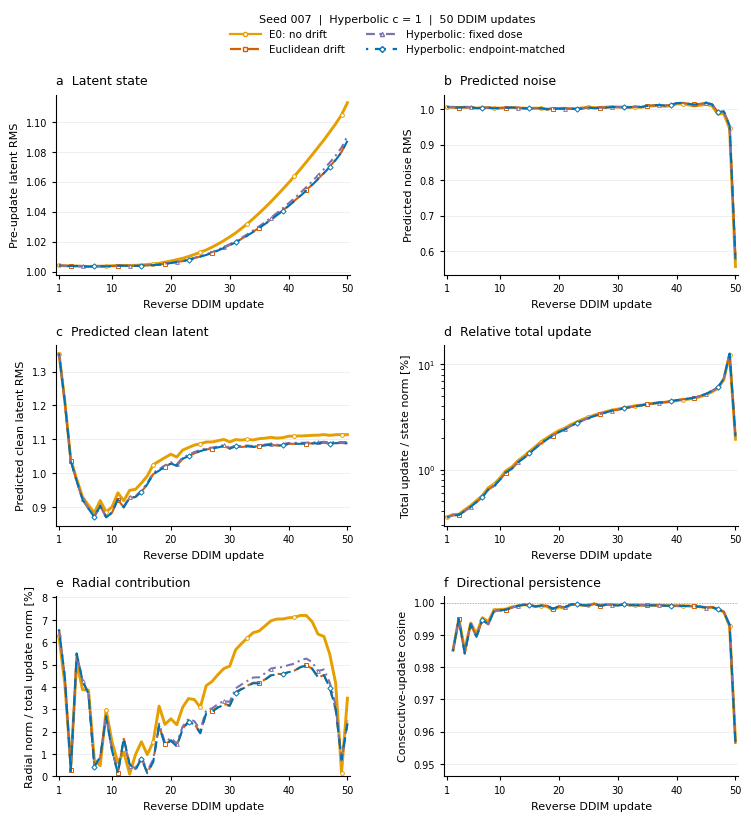

Figure S1: 600-dpi PNG / vector PDF / SVG
 /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary/figure_s1_four_condition_dynamics_seed_007
Source data: 4 conditions × 50 steps = 200 rows
 /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary/figure_s1_four_conditions


In [46]:
# Cell 44 — Figure S1: six diagnostics across four saved 50-step trajectories
from pathlib import Path
from io import BytesIO
import json
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def figure_s1(results, seed=7):
    root = Path(results) / "manuscript"
    data = root / "data/endpoint_matching/fixed_vs_matched_trajectory"
    dest = root / "figures/supplementary"
    source = root / "data/supplementary/figure_s1_four_conditions"

    names = ["E0", "Euclidean", "Hyperbolic fixed delta",
             "Hyperbolic endpoint-matched"]
    labels = ["E0: no drift", "Euclidean drift",
              "Hyperbolic: fixed dose", "Hyperbolic: endpoint-matched"]
    colors = ["#E69F00", "#D55E00", "#8073AC", "#0072B2"]
    styles = ["-", (0, (5, 3)), (0, (4, 2, 1, 2)), (4, (5, 3))]
    markers = ["o", "s", "^", "D"]

    paths = [
        data / (
            f"{n.lower().replace(' ', '_').replace('-', '_')}"
            f"_trace_tensors_seed_{seed:03d}.pt"
        )
        for n in names
    ]
    missing = [str(p) for p in paths if not p.is_file()]
    if missing:
        raise FileNotFoundError(
            "Missing Cell 26 trajectory files:\n" + "\n".join(missing)
        )

    records, metadata, initial = [], [], None
    for name, path in zip(names, paths):
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore", message=r"TypedStorage is deprecated.*",
                category=UserWarning
            )
            p = torch.load(path, map_location="cpu", weights_only=True)

        assert p["condition"] == name and int(p["seed"]) == seed
        keys = ["x_t_scaled", "modified_x_prev_scaled",
                "predicted_epsilon", "predicted_x0_scaled"]
        assert all(
            p[k].shape == p[keys[0]].shape and p[k].shape[0] == 50
            for k in keys
        )
        x, after, eps, clean = [
            p[k].detach().double().flatten(1).numpy() for k in keys
        ]
        assert all(np.isfinite(a).all() for a in (x, after, eps, clean))
        assert np.array_equal(x[1:], after[:-1]), f"Broken continuity: {name}"
        if initial is None:
            initial = x[0].copy()
        assert np.array_equal(x[0], initial), "Initial noise differs"

        # Total transition: DDIM update + drift, where present.
        update = after - x
        xn = np.linalg.norm(x, axis=1)
        un = np.linalg.norm(update, axis=1)
        assert (xn > 0).all() and (un > 0).all(), "Undefined zero-vector metric"

        projection = (update * x).sum(axis=1) / (x * x).sum(axis=1)
        radial = np.linalg.norm(projection[:, None] * x, axis=1)
        cosine = (
            (update[1:] * update[:-1]).sum(axis=1)
            / (un[1:] * un[:-1])
        )
        rms = lambda a: np.sqrt(np.mean(a * a, axis=1))

        records.append(pd.DataFrame({
            "condition": name,
            "seed": seed,
            "reverse_step": np.arange(50),
            "update": np.arange(1, 51),
            "state_rms": rms(x),
            "noise_rms": rms(eps),
            "clean_rms": rms(clean),
            "relative_update_percent": 100 * un / xn,
            "radial_norm_ratio_percent": 100 * radial / un,
            "consecutive_update_cosine": np.r_[np.nan, np.clip(cosine, -1, 1)],
            "state_l2": xn,
            "total_update_l2": un,
            "radial_update_l2": radial,
        }))
        metadata.append({
            "condition": name,
            "source": str(path),
            "applied_delta": float(p["applied_delta"]),
            "curvature": None if name == "E0" else float(p["curvature"]),
            "coordinate_scale": (
                float(p["coordinate_scale"]) if "Hyperbolic" in name else None
            ),
        })

    assert metadata[2]["curvature"] == metadata[3]["curvature"]
    assert metadata[2]["coordinate_scale"] == metadata[3]["coordinate_scale"]

    all_data = pd.concat(records, ignore_index=True)
    c = metadata[2]["curvature"]
    panels = [
        ("state_rms", "a  Latent state", "Pre-update latent RMS"),
        ("noise_rms", "b  Predicted noise", "Predicted noise RMS"),
        ("clean_rms", "c  Predicted clean latent", "Predicted clean latent RMS"),
        ("relative_update_percent", "d  Relative total update",
         "Total update / state norm [%]"),
        ("radial_norm_ratio_percent", "e  Radial contribution",
         "Radial norm / total update norm [%]"),
        ("consecutive_update_cosine", "f  Directional persistence",
         "Consecutive-update cosine"),
    ]
    for folder in (dest, source):
        folder.mkdir(parents=True, exist_ok=True)
    stem = f"figure_s1_four_condition_dynamics_seed_{seed:03d}"

    with plt.rc_context({
        "font.family": "DejaVu Sans", "font.size": 8,
        "pdf.fonttype": 42, "svg.fonttype": "none"
    }):
        fig = plt.figure(figsize=(7.4, 8.1), layout="constrained")
        grid = fig.add_gridspec(
            4, 2, height_ratios=[.27, 1, 1, 1], hspace=.08, wspace=.06
        )
        legend_ax = fig.add_subplot(grid[0, :])
        legend_ax.axis("off")
        handles = [
            Line2D([], [], color=co, ls=ls, marker=m, ms=3,
                   mfc="white", lw=1.6, label=lab)
            for co, ls, m, lab in zip(colors, styles, markers, labels)
        ]
        legend_ax.legend(
            handles=handles, loc="center", ncol=2, frameon=False,
            fontsize=7.5, handlelength=3, title_fontsize=8,
            title=f"Seed {seed:03d}  |  Hyperbolic c = {c:g}  |  50 DDIM updates"
        )

        for i, (key, title, ylabel) in enumerate(panels):
            ax = fig.add_subplot(grid[1 + i // 2, i % 2])
            for j, df in enumerate(records):
                ax.plot(
                    df["update"], df[key],
                    color=colors[j], ls=styles[j],
                    lw=2.1 if j == 0 else 1.5,
                    marker=markers[j], ms=2.7, markevery=(2 * j, 8),
                    mfc="white", mew=.7, zorder=2 + j
                )
            ax.set(
                xlabel="Reverse DDIM update", ylabel=ylabel,
                xlim=(.5, 50.5), xticks=[1, 10, 20, 30, 40, 50]
            )
            ax.set_title(title, loc="left", fontsize=9, pad=7)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(labelsize=7, length=3)
            ax.grid(axis="y", color="#E9E9E9", lw=.5)
            ax.set_axisbelow(True)

            if key == "relative_update_percent":
                ax.set_yscale("log")
            elif key == "radial_norm_ratio_percent":
                ax.set_ylim(0, max(8, 1.12 * all_data[key].max()))
            elif key == "consecutive_update_cosine":
                ax.axhline(1, color="#AAAAAA", lw=.7, ls=":")
                ax.set_ylim(max(-1, all_data[key].min() - .01), 1.002)

        for ext in ("png", "pdf", "svg"):
            with BytesIO() as buffer:
                fig.savefig(
                    buffer, format=ext, dpi=600, bbox_inches="tight",
                    pad_inches=.08, facecolor="white"
                )
                (dest / f"{stem}.{ext}").write_bytes(buffer.getvalue())
        plt.show()
        plt.close(fig)

    all_data.to_csv(source / f"{stem}_source_data.csv", index=False)
    (source / f"{stem}_metadata.json").write_text(json.dumps({
        "seed": seed,
        "conditions": metadata,
        "sampling_rerun": False,
        "norm": "Euclidean L2 over all latent entries; calculations use float64",
        "total_update": "modified_x_prev_scaled - x_t_scaled",
        "radial_component": "Euclidean projection of total_update onto x_t_scaled",
        "radial_ratio": "100 * radial_component_L2 / total_update_L2; not an energy fraction",
        "cosine": "Between consecutive total updates; first value undefined (NaN)",
        "display": "Exact update indices; sparse staggered markers, no jitter or smoothing",
    }, indent=2), encoding="utf-8")

    print("Figure S1: 600-dpi PNG / vector PDF / SVG\n", dest / stem)
    print("Source data: 4 conditions × 50 steps =", len(all_data), "rows\n", source)
    return all_data


s1_four_condition_data = figure_s1(
    globals().get("RESULTS", Path.cwd() / "results/euclidean_audit"),
    int(globals().get("CFG", {}).get("reference_seed", 7)),
)

In [47]:
# Cell 45 — One supplementary CSV: four conditions × 50 DDIM updates
# Requires saved outputs from Cell 26 and Cell 44 v2; no model or sampling.

from pathlib import Path
import numpy as np
import pandas as pd


def export_s1_trajectories(results, seed=7):
    root = Path(results) / "manuscript/data"
    traces = root / "endpoint_matching/fixed_vs_matched_trajectory"
    dest = root / "supplementary"

    names = [
        "E0",
        "Euclidean",
        "Hyperbolic fixed delta",
        "Hyperbolic endpoint-matched",
    ]
    tag = f"seed_{seed:03d}"

    summary_path = (
        traces / f"fixed_vs_matched_terminal_summary_{tag}.csv"
    )
    plot_path = (
        dest
        / "figure_s1_four_conditions"
        / f"figure_s1_four_condition_dynamics_{tag}_source_data.csv"
    )
    paths = [
        traces
        / (
            f"{name.lower().replace(' ', '_').replace('-', '_')}"
            f"_trace_{tag}.csv"
        )
        for name in names
    ]

    missing = [
        str(path)
        for path in [*paths, summary_path, plot_path]
        if not path.is_file()
    ]
    if missing:
        raise FileNotFoundError(
            "Run Cell 26 and Cell 44 v2 first. Missing:\n"
            + "\n".join(missing)
        )

    # 1. Read the four original traces, preserving all original columns.
    parts, schedule, columns = [], None, None

    for name, path in zip(names, paths):
        df = (
            pd.read_csv(path)
            .sort_values("reverse_step")
            .reset_index(drop=True)
        )

        assert np.array_equal(df.reverse_step, np.arange(50)), (
            f"Missing/duplicate steps: {name}"
        )
        assert np.isfinite(df.to_numpy(float)).all(), (
            f"Non-finite original trace: {name}"
        )

        if schedule is None:
            schedule = df.timestep.to_numpy()
            columns = list(df.columns)

        assert list(df.columns) == columns, (
            f"Trace columns differ: {name}"
        )
        assert np.array_equal(df.timestep, schedule), (
            f"DDIM timesteps differ: {name}"
        )

        parts.append(
            df.assign(
                condition=name,
                seed=seed,
                update=df.reverse_step + 1,
                source_trace_csv=path.name,
            )
        )

    combined = pd.concat(parts, ignore_index=True)

    # 2. Read the actual experiment settings from the saved summary.
    info = [
        "condition",
        "geometry",
        "comparison_role",
        "curvature",
        "coordinate_scale",
        "applied_delta",
    ]
    meta = pd.read_csv(summary_path)[info]

    assert len(meta) == 4 and set(meta.condition) == set(names), (
        "Wrong condition metadata"
    )
    combined = combined.merge(
        meta,
        on="condition",
        how="left",
        validate="many_to_one",
    )

    # 3. Append Cell 44 v2 diagnostics using explicit condition/step keys.
    plot = pd.read_csv(plot_path)

    assert (
        len(plot) == 200
        and plot.seed.eq(seed).all()
        and set(plot.condition) == set(names)
    ), "Unexpected conditions, seed or row count in Cell 44 v2 source data"

    keys = ["condition", "seed", "reverse_step"]
    derived = [
        "noise_rms",
        "clean_rms",
        "relative_update_percent",
        "radial_norm_ratio_percent",
        "consecutive_update_cosine",
        "radial_update_l2",
    ]

    combined = combined.merge(
        plot[
            keys
            + derived
            + ["state_rms", "state_l2", "total_update_l2"]
        ],
        on=keys,
        how="left",
        validate="one_to_one",
        suffixes=("", "_v2"),
        indicator=True,
    )

    assert combined["_merge"].eq("both").all(), (
        "Some original steps have no v2 diagnostic row"
    )

    # Check shared measurements before removing duplicate columns.
    # Allow small float32 versus float64 numerical differences.
    shared_measurements = [
        ("latent_before_rms", "state_rms"),
        ("latent_before_l2", "state_l2"),
        ("total_update_l2", "total_update_l2_v2"),
    ]
    for original, recomputed in shared_measurements:
        assert np.allclose(
            combined[original],
            combined[recomputed],
            rtol=1e-6,
            atol=1e-8,
        ), (
            f"Source mismatch: {original}. "
            "Regenerate Cell 44 v2 from the matching PT files."
        )

    combined = combined.drop(
        columns=[
            "state_rms",
            "state_l2",
            "total_update_l2_v2",
            "_merge",
        ]
    )

    # First-step consecutive-update cosine is intentionally undefined.
    cosine = combined.consecutive_update_cosine
    assert np.array_equal(
        cosine.isna(), combined.reverse_step.eq(0)
    ), "Unexpected cosine missing values"

    assert np.isfinite(
        combined[derived]
        .drop(columns="consecutive_update_cosine")
        .to_numpy()
    ).all(), "Non-finite derived diagnostics"

    assert np.isfinite(cosine.dropna()).all(), (
        "Non-finite consecutive-update cosine"
    )

    # 4. Arrange conditions and columns for the supplementary data file.
    front = [
        "condition",
        "seed",
        "geometry",
        "comparison_role",
        "curvature",
        "coordinate_scale",
        "applied_delta",
        "reverse_step",
        "update",
        "timestep",
    ]

    combined = combined.assign(
        _order=combined.condition.map(dict(zip(names, range(4))))
    )
    combined = (
        combined.sort_values(["_order", "reverse_step"])
        .drop(columns="_order")
        .reset_index(drop=True)
    )

    remaining = [
        column
        for column in combined.columns
        if column not in front + ["source_trace_csv"]
    ]
    combined = combined[
        front + remaining + ["source_trace_csv"]
    ]

    assert len(combined) == 200
    assert not combined.duplicated(keys).any()

    # 5. Export one CSV without rounding or filling undefined values.
    dest.mkdir(parents=True, exist_ok=True)
    output = (
        dest
        / f"supplementary_data_s1_four_condition_50step_{tag}.csv"
    )
    combined.to_csv(output, index=False, encoding="utf-8")

    print("Saved:", output)
    print(
        combined.groupby("condition", sort=False)
        .size()
        .rename("rows")
        .to_string()
    )
    print(
        "First-update cosine is undefined; blank curvature/"
        "coordinate_scale means not applicable."
    )

    return combined


supplementary_s1_trajectories = export_s1_trajectories(
    globals().get(
        "RESULTS",
        Path.cwd() / "results/euclidean_audit",
    ),
    int(globals().get("CFG", {}).get("reference_seed", 7)),
)

Saved: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary/supplementary_data_s1_four_condition_50step_seed_007.csv
condition
E0                             50
Euclidean                      50
Hyperbolic fixed delta         50
Hyperbolic endpoint-matched    50
First-update cosine is undefined; blank curvature/coordinate_scale means not applicable.


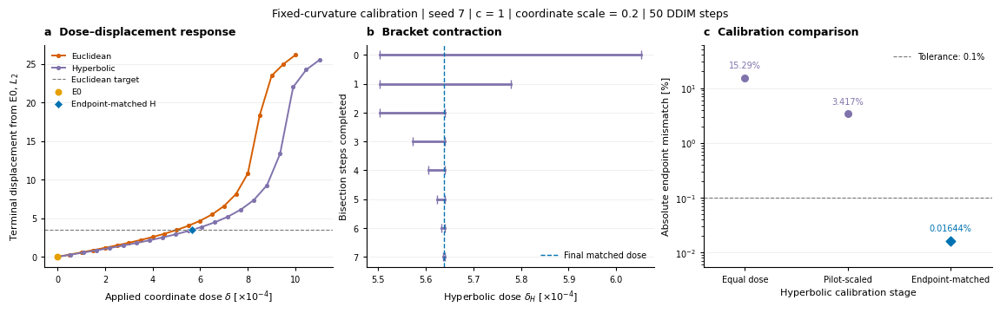

Saved PNG / vector PDF / SVG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary/figure_s2_fixed_curvature_calibration_seed_007
Saved combined source CSV: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary/figure_s2_fixed_curvature_calibration_seed_007_source_data.csv
                phase  applied_delta  terminal_l2_vs_E0  absolute_error_percent
equal_coordinate_dose       0.000500           2.940316               15.287330
    pilot_scaled_dose       0.000550           3.352326                3.417005
     endpoint_matched       0.000564           3.470358                0.016438
Panel b shows retained search intervals, not confidence intervals.
The complete solver history is retained in CSV rows labelled panel='audit'.


In [48]:
# Cell 46 — Figure S2: three panels in one row; full solver audit retained in CSV
# Reads saved Cell 19/21/22/26 results; does not run the model.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def figure_s2(results, seed=7):
    root = Path(results) / "manuscript"
    data = root / "data/endpoint_matching"
    tag = f"seed_{seed:03d}"
    pre_path = data / f"endpoint_preflight_{tag}.csv"
    eval_path = data / f"endpoint_matching_evaluations_{tag}.csv"
    final_path = data / f"endpoint_matched_summary_{tag}.csv"
    fixed_path = data / "fixed_vs_matched_trajectory" / f"fixed_vs_matched_terminal_summary_{tag}.csv"

    def read(path):
        if not path.is_file():
            raise FileNotFoundError(f"Missing saved Cell 19/21/22/26 output: {path}")
        return pd.read_csv(path)

    def one(df):
        assert len(df) == 1, "Expected exactly one matching record"
        return df.iloc[0]

    pre = one(read(pre_path))
    c, scale = float(pre.curvature), float(pre.coordinate_scale)
    delta_e, target = float(pre.reference_euclidean_delta), float(pre.target_terminal_l2_vs_E0)
    tolerance, steps = float(pre.maximum_terminal_relative_error_percent), int(pre.bisection_steps)
    assert int(pre.seed) == seed and target > 0 and tolerance > 0
    candidates = list((root / "data/dose_calibration").glob(f"dense_*point_c{c:g}_scale{scale:g}_{tag}_summary.csv"))
    assert len(candidates) == 1, f"Expected one dense-dose summary; found: {candidates}"
    dose_path = candidates[0]
    config = json.loads(dose_path.with_name(dose_path.name.replace("_summary.csv", "_config.json")).read_text())
    assert config["seed"] == seed and not config["endpoint_matching_applied"]
    assert np.allclose([config["curvature"], config["coordinate_scale"], config["reference_euclidean_delta"]],
                       [c, scale, delta_e], rtol=1e-8, atol=1e-12), "Mismatched experiment settings"

    dose, final, fixed = read(dose_path), read(final_path), read(fixed_path)
    ev = read(eval_path).set_index("phase", verify_integrity=True)
    terminal = "terminal_latent_l2_vs_E0"
    dose_terminal = "final_latent_l2_difference_vs_E0"
    close = lambda a, b: np.isclose(a, b, rtol=1e-6, atol=1e-12)
    equal = one(fixed[fixed.condition.eq("Hyperbolic fixed delta")])
    matched = one(final[final.method.eq("Hyperbolic terminal-matched")])
    pilot = one(dose[dose.geometry.eq("Hyperbolic") & np.isclose(dose.euclidean_delta, delta_e, atol=1e-12, rtol=0)])
    for frame, key, column in [(final, "method", "Euclidean reference"), (fixed, "condition", "Euclidean")]:
        reference = one(frame[frame[key].eq(column)])
        assert close(reference.applied_delta, delta_e) and close(reference[terminal], target)
    reference = one(dose[dose.geometry.eq("Euclidean") & np.isclose(dose.applied_delta, delta_e, atol=1e-12, rtol=0)])
    assert close(reference[dose_terminal], target)
    assert close(equal.applied_delta, delta_e) and close(equal.curvature, c) and close(equal.coordinate_scale, scale)
    assert close(pilot.applied_delta, delta_e * config["hyperbolic_delta_multiplier"])
    check = one(fixed[fixed.condition.eq("Hyperbolic endpoint-matched")])
    assert close(check[terminal], matched[terminal]) and close(check.applied_delta, matched.applied_delta)
    assert close(check.curvature, c) and close(check.coordinate_scale, scale)
    assert np.isfinite(dose[["applied_delta", dose_terminal]].to_numpy()).all()
    assert np.isfinite(ev[["applied_hyperbolic_delta", terminal]].to_numpy()).all()

    # Reconstruct retained brackets from actual evaluations, not CSV row order.
    # Cell 22 sorts the saved evaluation CSV by error, so use the phase labels.
    lower, upper = ev.loc["dense bracket lower"], ev.loc["dense bracket upper"]
    lo, hi = float(lower.applied_hyperbolic_delta), float(upper.applied_hyperbolic_delta)
    flo, fhi = float(lower[terminal]), float(upper[terminal])
    assert lo < hi and flo <= target <= fhi, "Invalid saved initial bracket"
    assert close(lo, pre.dense_bracket_lower_delta) and close(hi, pre.dense_bracket_upper_delta)
    brackets = [(0, lo, hi, flo, fhi)]
    phases = [f"bisection_{i:02d}" for i in range(1, steps + 1)]
    for i, phase in enumerate(phases, 1):
        row = ev.loc[phase]
        mid, value = float(row.applied_hyperbolic_delta), float(row[terminal])
        assert close(mid, (lo + hi) / 2), f"Invalid midpoint: {phase}"
        if value < target:
            lo, flo = mid, value
        else:
            hi, fhi = mid, value
        brackets.append((i, lo, hi, flo, fhi))
    interpolated = lo + (target - flo) / (fhi - flo) * (hi - lo)
    assert close(interpolated, matched.applied_delta), "Final dose is inconsistent with saved interpolation"
    assert close(ev.loc["terminal_matched", terminal], matched[terminal])
    assert close(ev.loc["terminal_matched", "applied_hyperbolic_delta"], matched.applied_delta)

    # One source CSV: three panels plus the unplotted solver audit.
    scan = dose[["method", "geometry", "euclidean_delta", "applied_delta", dose_terminal]].rename(columns={dose_terminal: "terminal_l2_vs_E0"})
    scan = scan.assign(panel="a", record="dose_scan", source_csv=dose_path.name)
    bracket = pd.DataFrame(brackets, columns=["iteration", "lower_delta", "upper_delta", "lower_terminal_l2", "upper_terminal_l2"])
    bracket = bracket.assign(panel="b", record="retained_bracket", geometry="Hyperbolic", source_csv=eval_path.name)
    history = ev.loc[phases + ["terminal_matched"], ["applied_hyperbolic_delta", terminal]].reset_index()
    history = history.rename(columns={"applied_hyperbolic_delta": "applied_delta", terminal: "terminal_l2_vs_E0"})
    history = history.assign(panel="audit", record="solver_evaluation", geometry="Hyperbolic",
                             iteration=np.arange(1, steps + 2), source_csv=eval_path.name)
    comparison = pd.DataFrame({
        "phase": ["equal_coordinate_dose", "pilot_scaled_dose", "endpoint_matched"],
        "applied_delta": [equal.applied_delta, pilot.applied_delta, matched.applied_delta],
        "terminal_l2_vs_E0": [equal[terminal], pilot[dose_terminal], matched[terminal]],
        "source_csv": [fixed_path.name, dose_path.name, final_path.name],
    }).assign(panel="c", record="calibration_comparison", geometry="Hyperbolic")
    source = pd.concat([scan, bracket, history, comparison], ignore_index=True)
    source["signed_error_percent"] = 100 * (source.terminal_l2_vs_E0 / target - 1)
    source["absolute_error_percent"] = source.signed_error_percent.abs()
    source = source.assign(seed=seed, hyperbolic_curvature=c, hyperbolic_coordinate_scale=scale,
                           ddim_steps=config["num_reverse_steps"], reference_euclidean_delta=delta_e,
                           target_terminal_l2_vs_E0=target, tolerance_percent=tolerance,
                           pilot_delta_multiplier=config["hyperbolic_delta_multiplier"])
    before_after = 100 * np.abs(comparison.terminal_l2_vs_E0.to_numpy() / target - 1)
    assert before_after[-1] <= tolerance, "Saved endpoint match exceeds its original tolerance"

    E0, E, H, HM = "#E69F00", "#D55E00", "#8073AC", "#0072B2"
    stem = f"figure_s2_fixed_curvature_calibration_{tag}"
    figdir, csvdir = root / "figures/supplementary", root / "data/supplementary"
    for folder in (figdir, csvdir):
        folder.mkdir(parents=True, exist_ok=True)
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 8,
                         "pdf.fonttype": 42, "svg.fonttype": "none"}):
        fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.5), layout="constrained")
        for ax, title in zip(axes.flat, ["a  Dose–displacement response", "b  Bracket contraction",
                                         "c  Calibration comparison"]):
            ax.set_title(title, loc="left", fontsize=9, fontweight="bold", pad=8)
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(labelsize=7, length=3)
            ax.grid(axis="y", color="#E9E9E9", lw=.5)
            ax.set_axisbelow(True)

        ax = axes[0]
        baseline = one(scan[scan.geometry.eq("E0")])
        assert close(baseline.applied_delta, 0) and close(baseline.terminal_l2_vs_E0, 0)
        for name, color in [("Euclidean", E), ("Hyperbolic", H)]:
            curve = scan[scan.geometry.eq(name)].sort_values("applied_delta")
            ax.plot(np.r_[0, curve.applied_delta] * 1e4, np.r_[0, curve.terminal_l2_vs_E0],
                    "o-", color=color, lw=1.4, ms=2.7, label=name)
        ax.axhline(target, color="#777777", lw=.8, ls="--", label="Euclidean target")
        ax.scatter(0, 0, color=E0, s=22, zorder=4, label="E0")
        ax.scatter(matched.applied_delta * 1e4, matched[terminal], color=HM, marker="D", s=25,
                   edgecolor="white", linewidth=.4, zorder=5, label="Endpoint-matched H")
        ax.set(xlabel=r"Applied coordinate dose $\delta$ [$\times 10^{-4}$]",
               ylabel=r"Terminal displacement from E0, $L_2$")
        ax.legend(frameon=False, fontsize=6.8, loc="upper left", handlelength=1.6)

        ax = axes[1]
        for row in bracket.itertuples():
            ax.plot(np.array([row.lower_delta, row.upper_delta]) * 1e4,
                    [row.iteration] * 2, color=H, lw=2)
            ax.scatter(np.array([row.lower_delta, row.upper_delta]) * 1e4,
                       [row.iteration] * 2, color=H, marker="|", s=45, linewidths=1)
        ax.axvline(matched.applied_delta * 1e4, color=HM, lw=1, ls="--", label="Final matched dose")
        ax.set(xlabel=r"Hyperbolic dose $\delta_H$ [$\times 10^{-4}$]",
               ylabel="Bisection steps completed", yticks=range(steps + 1))
        ax.invert_yaxis()
        ax.legend(frameon=False, fontsize=7, loc="lower right")

        ax = axes[2]
        # Exact zeros are drawn at a labelled floor, without changing source data.
        positives = np.r_[before_after, tolerance]
        floor = positives[positives > 0].min() / 5
        for x, (value, color) in enumerate(zip(before_after, [H, H, HM])):
            ax.scatter(x, max(value, floor), color=color, marker="D" if x == 2 else "o", s=30, zorder=3)
            text = f"{value:.4g}%" if value > 0 else "0 (display floor)"
            ax.annotate(text, (x, max(value, floor)), xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=7, color=color)
        ax.axhline(tolerance, color="#777777", lw=.8, ls="--", label=f"Tolerance: {tolerance:g}%")
        ax.legend(frameon=False, fontsize=7, loc="upper right")
        ax.set(yscale="log", xlim=(-.4, 2.4), xticks=range(3),
               xticklabels=["Equal dose", "Pilot-scaled", "Endpoint-matched"],
               xlabel="Hyperbolic calibration stage", ylabel="Absolute endpoint mismatch [%]")
        ax.set_ylim(min(before_after.min(), tolerance) / 3 if before_after.min() > 0 else floor / 2,
                    max(before_after.max(), tolerance) * 4)
        fig.suptitle(f"Fixed-curvature calibration | seed {seed} | c = {c:g} | "
                     f"coordinate scale = {scale:g} | {config['num_reverse_steps']} DDIM steps", fontsize=9)
        for ext in ("png", "pdf", "svg"):
            fig.savefig(figdir / f"{stem}.{ext}", dpi=600, bbox_inches="tight",
                        pad_inches=.06, facecolor="white")
        plt.show()
        plt.close(fig)

    csv_path = csvdir / f"{stem}_source_data.csv"
    source.to_csv(csv_path, index=False, encoding="utf-8")
    print("Saved PNG / vector PDF / SVG:", figdir / stem)
    print("Saved combined source CSV:", csv_path)
    print(comparison[["phase", "applied_delta", "terminal_l2_vs_E0"]]
          .assign(absolute_error_percent=before_after).to_string(index=False))
    print("Panel b shows retained search intervals, not confidence intervals.")
    print("The complete solver history is retained in CSV rows labelled panel='audit'.")
    return source


supplementary_s2_source = figure_s2(
    globals().get("RESULTS", Path.cwd() / "results/euclidean_audit"),
    int(globals().get("e0_seed", globals().get("CFG", {}).get("reference_seed", 7))),
)

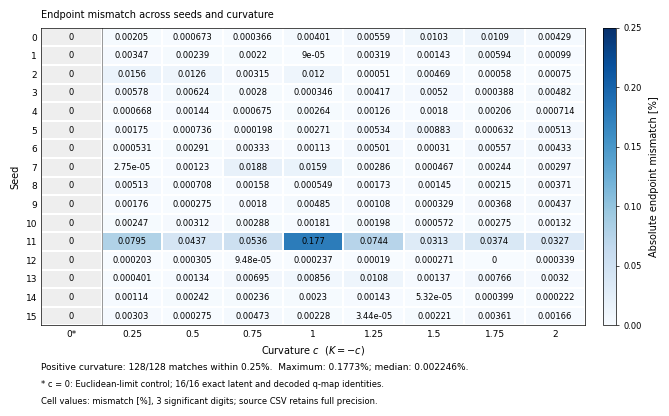

Saved PNG / vector PDF / SVG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary/figure_s3_multiseed_endpoint_matching
Saved source CSV: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary/figure_s3_multiseed_endpoint_matching_source_data.csv (144 rows)
16 seeds × 9 curvatures; 128 positive-curvature matches.
Within tolerance: 128/128; maximum mismatch: 0.177257%.


In [49]:
# Cell 47 — Figure S3: complete 16-seed, all-curvature endpoint-matching audit
# Reads only the saved multiseed study. No single-seed dense scan is used.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors, font_manager
from matplotlib.patches import Rectangle


def figure_s3(results):
    root = Path(results) / "manuscript"
    data = root / "data/multiseed_endpoint_matched_geometry"
    paths = {
        "curvature": data / "matched_curvature_per_seed.csv",
        "reference": data / "endpoint_fairness_per_seed.csv",
        "protocol": data / "protocol.json",
    }
    for path in paths.values():
        if not path.is_file():
            raise FileNotFoundError(
                f"Missing saved multiseed result: {path}"
            )

    protocol = json.loads(paths["protocol"].read_text())
    source = pd.read_csv(paths["curvature"])
    fairness = pd.read_csv(paths["reference"])
    seeds = sorted(protocol["audit_seeds"])
    cs = sorted(protocol["curvatures"])
    tolerance = float(protocol["endpoint_tolerance_percent"])
    reference_delta = float(protocol["reference_euclidean_delta"])

    terminal = "terminal_latent_l2_vs_E0"
    target = "target_terminal_l2_vs_E0"
    error = "terminal_l2_relative_error_percent"
    delta = "applied_hyperbolic_delta"

    assert len(seeds) == 16 and cs[0] == 0 and tolerance > 0
    assert not source.duplicated(["seed", "curvature"]).any()
    expected = {(s, round(c, 8)) for s in seeds for c in cs}
    assert set(zip(source.seed, source.curvature.round(8))) == expected, (
        "Incomplete curvature grid"
    )

    # Every seed has its own Euclidean reference endpoint.
    reference = fairness.loc[
        fairness.condition.eq("Euclidean"),
        ["seed", "applied_delta", terminal],
    ].copy()
    assert len(reference) == len(seeds)
    assert set(reference.seed) == set(seeds)
    assert np.allclose(
        reference.applied_delta, reference_delta, atol=1e-12, rtol=0
    )
    reference = reference.rename(
        columns={terminal: target}
    ).drop(columns="applied_delta")

    source = source.merge(
        reference, on="seed", how="left", validate="many_to_one"
    )
    assert np.isfinite(
        source[[delta, target, terminal, error]].to_numpy()
    ).all()
    assert (source[target] > 0).all() and (source[delta] > 0).all()

    recalculated = 100 * np.abs(
        (source[terminal] - source[target]) / source[target]
    )
    assert np.allclose(
        source[error], recalculated, rtol=1e-6, atol=1e-9
    ), "Inconsistent saved errors"

    # c=0 is an identity control, not an optimized positive-curvature match.
    zero = source[source.curvature.eq(0)]
    assert len(zero) == len(seeds)
    identity_cols = [
        "c0_latent_max_abs_vs_euclidean",
        "c0_qmap_max_abs_vs_euclidean",
    ]
    assert (zero[identity_cols].to_numpy() == 0).all(), (
        "c=0 identity check failed"
    )
    assert (zero[error] == 0).all()
    assert np.allclose(
        zero[delta], reference_delta, atol=1e-12, rtol=0
    )

    source = source.sort_values(
        ["seed", "curvature"]
    ).reset_index(drop=True)
    source = source.assign(
        study="multiseed_endpoint_matched_geometry",
        record_role=np.where(
            source.curvature.gt(0),
            "endpoint_match",
            "euclidean_limit_control",
        ),
        sectional_curvature_K=-source.curvature,
        euclidean_reference_delta=reference_delta,
        matched_coordinate_dose_ratio=source[delta] / reference_delta,
        tolerance_percent=tolerance,
        within_tolerance=source[error] <= tolerance,
        coordinate_scale=protocol["coordinate_scale"],
        ddim_steps=protocol["num_inference_steps"],
        bisection_steps=protocol["bisection_steps"],
        branch_selection_rule=protocol["branch_selection_rule"],
        source_csv=paths["curvature"].name,
        reference_source_csv=paths["reference"].name,
        source_config=paths["protocol"].name,
    )
    front = [
        "study", "seed", "curvature", "record_role",
        delta, target, terminal, error,
        "tolerance_percent", "within_tolerance",
    ]
    source = source[
        front + [name for name in source.columns if name not in front]
    ]

    positive = source[source.curvature.gt(0)]
    passed = int(positive.within_tolerance.sum())
    maximum = float(positive[error].max())
    median = float(positive[error].median())

    heat = source.pivot(
        index="seed", columns="curvature", values=error
    )
    heat = heat.reindex(
        index=seeds, columns=cs
    ).to_numpy(float)
    assert np.isfinite(heat).all()
    nrows, ncols = heat.shape

    # Final-size artwork: 183 × 108 mm, editable text and vector heatmap.
    available = {f.name for f in font_manager.fontManager.ttflist}
    font = next(
        f for f in ["Arial", "Helvetica", "DejaVu Sans"]
        if f in available
    )

    with plt.rc_context({
        "font.family": font,
        "font.size": 6.5,
        "axes.labelsize": 7,
        "xtick.labelsize": 6.5,
        "ytick.labelsize": 6.5,
        "pdf.fonttype": 42,
        "svg.fonttype": "none",
        "axes.linewidth": .5,
    }):
        fig = plt.figure(figsize=(183 / 25.4, 108 / 25.4))
        ax = fig.add_axes([.085, .21, .755, .70])
        cax = fig.add_axes([.865, .21, .018, .70])

        cmap = plt.get_cmap("Blues").copy()
        cmap.set_bad((0, 0, 0, 0))
        norm = colors.Normalize(
            vmin=0, vmax=max(tolerance, maximum)
        )
        masked = np.ma.array(
            heat,
            mask=np.broadcast_to(np.asarray(cs) == 0, heat.shape),
        )

        # Gray column separates the c=0 control from calibrated matches.
        ax.add_patch(Rectangle(
            (0, 0), 1, nrows,
            facecolor="#EEEEEE", edgecolor="none",
        ))
        mesh = ax.pcolormesh(
            np.arange(ncols + 1),
            np.arange(nrows + 1),
            masked,
            cmap=cmap,
            norm=norm,
            shading="flat",
            edgecolors="white",
            linewidth=.25,
            rasterized=False,
        )
        ax.set(
            xlim=(0, ncols),
            ylim=(nrows, 0),
            xticks=np.arange(ncols) + .5,
            xticklabels=[
                "0*" if c == 0 else f"{c:g}" for c in cs
            ],
            yticks=np.arange(nrows) + .5,
            yticklabels=seeds,
            xlabel=r"Curvature $c$  ($K=-c$)",
            ylabel="Seed",
        )
        ax.tick_params(length=0, pad=3)
        ax.axvline(1, color="#888888", lw=.6)
        ax.set_title(
            "Endpoint mismatch across seeds and curvature",
            loc="left", fontsize=7, pad=7,
        )

        # Three significant digits preserve small nonzero values.
        # Select black/white text according to background contrast.
        for row in range(nrows):
            for col in range(ncols):
                value = heat[row, col]
                rgb = np.array(cmap(norm(value))[:3])
                linear = np.where(
                    rgb <= .04045,
                    rgb / 12.92,
                    ((rgb + .055) / 1.055) ** 2.4,
                )
                luminance = linear @ np.array(
                    [.2126, .7152, .0722]
                )
                text_color = (
                    "black" if col == 0 or luminance > .179
                    else "white"
                )
                ax.text(
                    col + .5, row + .5, f"{value:.3g}",
                    ha="center", va="center",
                    fontsize=6, color=text_color,
                )

                if cs[col] > 0 and value > tolerance:
                    ax.add_patch(Rectangle(
                        (col, row), 1, 1,
                        fill=False, edgecolor="#D55E00",
                        linewidth=1,
                    ))

        cb = fig.colorbar(mesh, cax=cax)
        cb.set_label(
            "Absolute endpoint mismatch [%]",
            fontsize=7, labelpad=5,
        )
        cb.ax.tick_params(
            labelsize=6, length=2, width=.5
        )
        cb.solids.set_rasterized(False)

        fig.text(
            .085, .105,
            f"Positive curvature: {passed}/{len(positive)} matches "
            f"within {tolerance:g}%.  "
            f"Maximum: {maximum:.4g}%; median: {median:.4g}%.",
            fontsize=6.5,
        )
        fig.text(
            .085, .065,
            f"* c = 0: Euclidean-limit control; "
            f"{len(zero)}/{len(seeds)} exact latent and decoded q-map identities.",
            fontsize=6,
        )
        note = (
            "Cell values: mismatch [%], 3 significant digits; "
            "source CSV retains full precision."
        )
        if passed < len(positive):
            note += " Outlined cells exceed tolerance."
        fig.text(.085, .025, note, fontsize=6)

        figdir = root / "figures/supplementary"
        csvdir = root / "data/supplementary"
        for folder in (figdir, csvdir):
            folder.mkdir(parents=True, exist_ok=True)

        stem = "figure_s3_multiseed_endpoint_matching"
        for ext in ("png", "pdf", "svg"):
            # Preserve the specified physical dimensions.
            fig.savefig(
                figdir / f"{stem}.{ext}",
                dpi=600,
                facecolor="white",
                bbox_inches=None,
            )
        plt.show()
        plt.close(fig)

    csv_path = csvdir / f"{stem}_source_data.csv"
    source.to_csv(csv_path, index=False, encoding="utf-8")

    print("Saved PNG / vector PDF / SVG:", figdir / stem)
    print(f"Saved source CSV: {csv_path} ({len(source)} rows)")
    print(
        f"{len(seeds)} seeds × {len(cs)} curvatures; "
        f"{len(positive)} positive-curvature matches."
    )
    print(
        f"Within tolerance: {passed}/{len(positive)}; "
        f"maximum mismatch: {maximum:.6f}%."
    )
    return source


supplementary_s3_source = figure_s3(
    globals().get(
        "RESULTS",
        Path.cwd() / "results/euclidean_audit",
    )
)

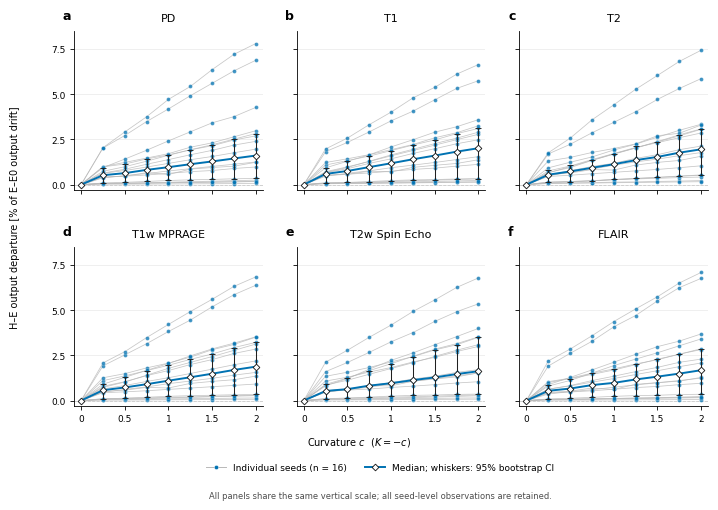

Saved PNG / vector PDF / editable SVG: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary/figure_s4_six_output_curvature_response
Saved source CSV: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary/figure_s4_six_output_curvature_response_source_data.csv (864 rows)
16 seeds × 9 curvatures × 6 outputs; saved Cell 37 bootstrap CIs reused.


In [50]:
# Cell 48 — Figure S4: six-output curvature responses across all 16 seeds
# Reuse Cell 37 source data and saved bootstrap CIs; no model sampling.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


def figure_s4(results):
    root = Path(results) / "manuscript"
    data = root / "data/multiseed_endpoint_matched_geometry"
    stem = "figure_s4_six_output_curvature_response"
    files = {
        "source": data / "output_response_multiseed_source_data.csv",
        "stats": data / "output_response_multiseed_statistics.csv",
        "meta": data / "output_response_multiseed_metadata.json",
        "protocol": data / "protocol.json",
    }
    for path in files.values():
        if not path.is_file():
            raise FileNotFoundError(f"Run Cell 37 first; missing: {path}")
    source = pd.read_csv(files["source"])
    stats = pd.read_csv(files["stats"])
    meta = json.loads(files["meta"].read_text(encoding="utf-8"))
    protocol = json.loads(files["protocol"].read_text(encoding="utf-8"))
    names = ["PD [a.u.]", "T1 [s]", "T2 [s]", "T1w MPRAGE", "T2w Spin Echo", "FLAIR"]
    labels = ["PD", "T1", "T2", "T1w MPRAGE", "T2w Spin Echo", "FLAIR"]
    seeds = sorted(protocol["audit_seeds"])
    cs = np.array(sorted(protocol["curvatures"]), dtype=float)
    metric = "geometry_difference_percent_of_e0_drift"
    keys = ["output", "seed", "curvature"]
    expected = pd.MultiIndex.from_product([names, seeds, cs], names=keys)
    assert len(set(seeds)) == 16 and len(np.unique(cs)) == 9 and cs[0] == 0
    assert not source.duplicated(keys).any(), "Duplicate seed/curvature/output records"
    source = source.set_index(keys)
    assert len(source) == len(expected) and expected.isin(source.index).all(), "Incomplete 864-row grid"
    source = source.reindex(expected).reset_index()

    # Preserve every observation; verify the normalized metric and c=0 control.
    raw, ref = "hyperbolic_output_mae_vs_euclidean", "euclidean_output_mae_vs_e0"
    values = source[[metric, raw, ref]].to_numpy(float)
    assert np.isfinite(values).all() and (values >= 0).all(), "Invalid output measurements"
    calculated = 100 * source[raw] / np.maximum(source[ref], 1e-12)
    assert np.allclose(source[metric], calculated, rtol=1e-6, atol=1e-9), "Inconsistent normalized response"
    assert np.allclose(source.loc[source.curvature.eq(0), [metric, raw]], 0, atol=1e-12, rtol=0)

    # Reuse the existing pointwise percentile bootstrap intervals, without resampling.
    summary = stats.loc[stats.metric.eq(metric),
                        ["output", "curvature_c", "n_seeds", "median", "ci95_low", "ci95_high"]]
    summary = summary.rename(columns={"curvature_c": "curvature"})
    summary_keys = ["output", "curvature"]
    expected_summary = pd.MultiIndex.from_product([names, cs], names=summary_keys)
    assert not summary.duplicated(summary_keys).any(), "Duplicate summary records"
    summary = summary.set_index(summary_keys)
    assert len(summary) == len(expected_summary) and expected_summary.isin(summary.index).all()
    summary = summary.reindex(expected_summary)
    assert summary.n_seeds.eq(len(seeds)).all(), "Summary seed count does not match"
    assert np.isfinite(summary.to_numpy(float)).all(), "Missing summary statistics"
    medians = source.groupby(summary_keys)[metric].median().reindex(expected_summary)
    assert np.allclose(summary["median"], medians, rtol=1e-7, atol=1e-10), "Stale median statistics"
    assert ((summary.ci95_low <= summary["median"]) &
            (summary["median"] <= summary.ci95_high) & (summary.ci95_low >= 0)).all()

    # One 864-row CSV: original measurements plus the corresponding group summary.
    source = source.merge(summary.reset_index().rename(columns={
        "median": "response_median_percent", "ci95_low": "response_ci95_low_percent",
        "ci95_high": "response_ci95_high_percent",
    }), on=summary_keys, how="left", validate="many_to_one", sort=False)
    source.insert(0, "panel", source.output.map(dict(zip(names, "abcdef"))))
    source["summary_metric"] = metric
    source["ci_method"] = "pointwise percentile bootstrap CI for the across-seed median"
    source["bootstrap_resamples"] = meta["bootstrap_resamples"]
    source["bootstrap_base_random_seed"] = meta["bootstrap_random_seed"]
    source["source_csv"] = files["source"].name
    source["statistics_csv"] = files["stats"].name

    blue, grey, ink = "#0072B2", "#B8B8B8", "#202020"
    ymax = max(float(source[metric].max()), float(summary.ci95_high.max()), 1e-6)
    available = {f.name for f in font_manager.fontManager.ttflist}
    font = next(f for f in ["Arial", "Helvetica", "DejaVu Sans"] if f in available)
    with plt.rc_context({
        "font.family": font, "font.size": 7, "axes.labelsize": 7,
        "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "axes.linewidth": .6,
        "pdf.fonttype": 42, "svg.fonttype": "none",
    }):
        fig, axes = plt.subplots(2, 3, figsize=(183 / 25.4, 135 / 25.4),
                                 sharex=True, sharey=True)
        fig.subplots_adjust(left=.105, right=.985, bottom=.205, top=.91,
                            wspace=.18, hspace=.36)
        for i, (ax, name) in enumerate(zip(axes.flat, names)):
            v = source[source.output.eq(name)].pivot(index="seed", columns="curvature", values=metric)
            v = v.reindex(index=seeds, columns=cs).to_numpy(float)
            med, lo, hi = summary.loc[name, ["median", "ci95_low", "ci95_high"]].to_numpy().T
            ax.axhline(0, color="#888888", lw=.6, ls="--", zorder=0)
            ax.plot(cs, v.T, color=grey, lw=.55, alpha=.8, zorder=1)
            # No horizontal jitter: each point stays on its actual seed trajectory.
            ax.scatter(np.tile(cs, len(seeds)), v.ravel(), s=8, color=blue,
                       edgecolor="white", linewidth=.2, alpha=.75, zorder=2)
            ax.plot(cs, med, color=blue, lw=1.4, zorder=3)
            ax.errorbar(cs, med, yerr=np.vstack([med - lo, hi - med]),
                        fmt="D", ms=3.4, mfc="white", mec=ink, mew=.65,
                        ecolor=ink, elinewidth=.75, capsize=2, capthick=.65, zorder=4)
            ax.set(xlim=(cs[0] - .08, cs[-1] + .08), ylim=(-.035 * ymax, 1.09 * ymax),
                   xticks=cs[::2], xticklabels=[f"{c:g}" for c in cs[::2]])
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4, min_n_ticks=3))
            ax.spines[["top", "right"]].set_visible(False)
            ax.tick_params(length=3, width=.6, pad=3)
            ax.grid(axis="y", color="#E9E9E9", lw=.5)
            ax.set_axisbelow(True)
            ax.set_title(labels[i], fontsize=8, pad=7)
            ax.text(-.06, 1.055, "abcdef"[i], transform=ax.transAxes,
                    fontsize=9, fontweight="bold", va="bottom")

        fig.supylabel("H–E output departure [% of E–E0 output drift]", x=.016, y=.56, fontsize=7)
        fig.supxlabel(r"Curvature $c$  ($K=-c$)", y=.125, fontsize=7)
        handles = [
            Line2D([], [], color=grey, lw=.7, marker="o", ms=3,
                   mfc=blue, mec="white", mew=.3, label="Individual seeds (n = 16)"),
            Line2D([], [], color=blue, lw=1.4, marker="D", ms=3.4,
                   mfc="white", mec=ink, mew=.65, label="Median; whiskers: 95% bootstrap CI"),
        ]
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.53, .065),
                   ncol=2, frameon=False, fontsize=6.5, handlelength=2.2, columnspacing=2)
        fig.text(.53, .031, "All panels share the same vertical scale; all seed-level observations are retained.",
                 ha="center", fontsize=6, color="#4D4D4D")

        figdir, csvdir = root / "figures/supplementary", root / "data/supplementary"
        for folder in (figdir, csvdir):
            folder.mkdir(parents=True, exist_ok=True)
        for ext in ("png", "pdf", "svg"):
            fig.savefig(figdir / f"{stem}.{ext}", dpi=600, facecolor="white", bbox_inches=None)
        plt.show()
        plt.close(fig)

    csv_path = csvdir / f"{stem}_source_data.csv"
    source.to_csv(csv_path, index=False, encoding="utf-8")
    print("Saved PNG / vector PDF / editable SVG:", figdir / stem)
    print(f"Saved source CSV: {csv_path} ({len(source)} rows)")
    print("16 seeds × 9 curvatures × 6 outputs; saved Cell 37 bootstrap CIs reused.")
    return source


supplementary_s4_source = figure_s4(
    globals().get("RESULTS", Path.cwd() / "results/euclidean_audit")
)

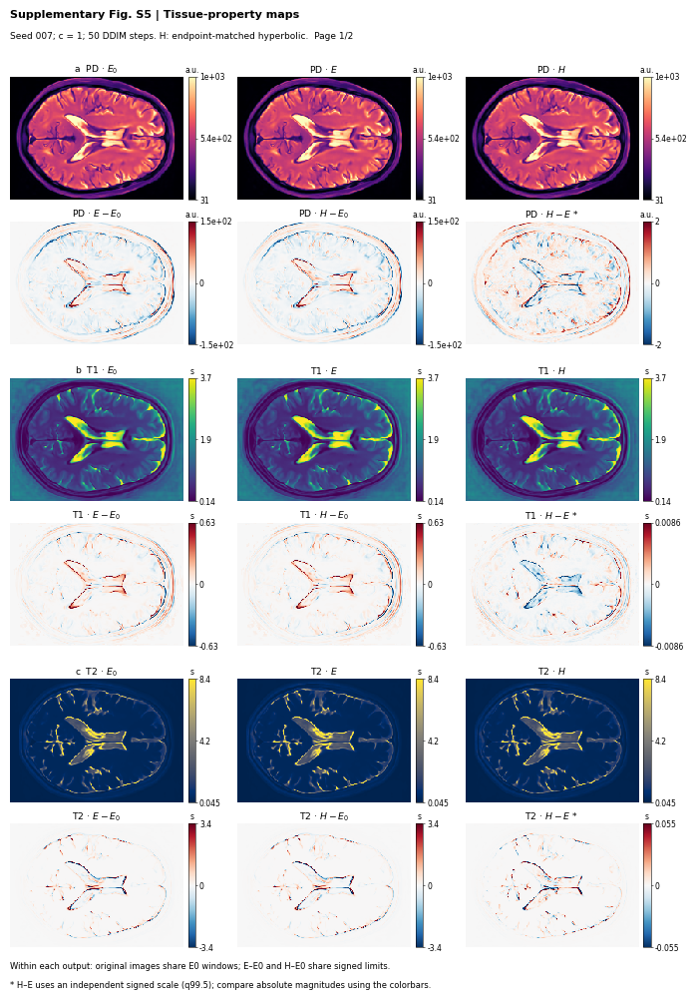

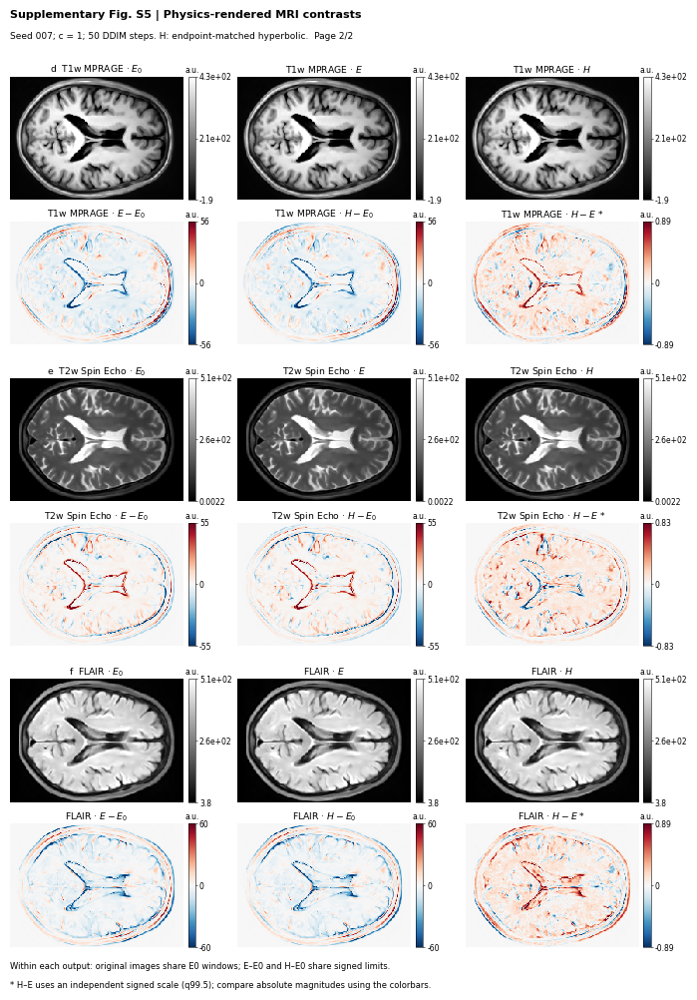

Saved two-page S5 PDF: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary/figure_s5_full_spatial_comparison_seed_007.pdf
Saved 600-dpi PNG and editable SVG for each page: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/figures/supplementary
Saved six-output metrics/scales CSV and full image arrays NPZ: /mnt/g/Research/TUM_Multimodal/phy-ldm-mri/results/euclidean_audit/manuscript/data/supplementary
6 outputs × 6 images = 36 images; seed 007, c = 1.


In [51]:
# Cell 49 — Figure S5: full six-output spatial comparison, two readable pages
# Reads saved Cells 23/24/29 only. No model loading, decoding or sampling.
from pathlib import Path
import json
import warnings
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.ticker import FormatStrFormatter


def figure_s5(results, seed=7):
    root = Path(results) / "manuscript"
    data = root / "data/endpoint_matching"
    fair, diffdir = data / "fair_comparison", data / "signed_difference_maps"
    tag = f"seed_{seed:03d}"
    paths = {
        "images": fair / f"endpoint_matched_physical_outputs_{tag}.pt",
        "protocol": fair / f"endpoint_matched_fair_comparison_{tag}.json",
        "visual": fair / f"endpoint_matched_visual_metadata_{tag}.json",
        "arrays": diffdir / f"endpoint_matched_difference_arrays_{tag}.npz",
        "scales": diffdir / f"endpoint_matched_difference_scales_{tag}.csv",
        "metrics": diffdir / f"endpoint_matched_difference_metrics_{tag}.csv",
    }
    for path in paths.values():
        if not path.is_file():
            raise FileNotFoundError(f"Run Cells 23, 24 and 29 first; missing: {path}")
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore", message=r"TypedStorage is deprecated.*", category=UserWarning
        )
        saved = torch.load(paths["images"], map_location="cpu", weights_only=True)
    protocol = json.loads(paths["protocol"].read_text(encoding="utf-8"))
    visual = json.loads(paths["visual"].read_text(encoding="utf-8"))
    scales = pd.read_csv(paths["scales"]).set_index("output")
    metrics = pd.read_csv(paths["metrics"]).set_index("output")
    with np.load(paths["arrays"], allow_pickle=False) as z:
        archived = {key: z[key].copy() for key in z.files}

    def array(value):
        if torch.is_tensor(value):
            value = value.detach().float().cpu().numpy()
        return np.asarray(value).squeeze()

    mask = archived["tissue_mask"].astype(bool)
    assert mask.ndim == 2 and mask.sum() > 1
    assert np.array_equal(
        mask, array(saved["foreground_mask"]).astype(bool)
    ), "Foreground masks disagree"
    assert int(saved["seed"]) == int(protocol["seed"]) == int(visual["seed"]) == seed
    curvature = float(protocol["curvature"])
    error = float(protocol["hyperbolic_terminal_l2_relative_error_percent"])
    assert np.isfinite([curvature, error]).all() and curvature > 0
    assert error <= float(
        protocol["maximum_allowed_relative_error_percent"]
    ), "Endpoint match failed"
    assert np.isclose(
        error, visual["hyperbolic_terminal_relative_error_percent"],
        rtol=1e-6, atol=1e-9
    )

    specs = [
        ("PD [a.u.]", "PD", 0, "a.u.", "magma"),
        ("T1 [s]", "T1", 1, "s", "viridis"),
        ("T2 [s]", "T2", 2, "s", "cividis"),
        ("T1w MPRAGE", "T1w MPRAGE", None, "a.u.", "gray"),
        ("T2w Spin Echo", "T2w Spin Echo", None, "a.u.", "gray"),
        ("FLAIR", "FLAIR", None, "a.u.", "gray"),
    ]
    conditions = ["E0", "Euclidean", "Hyperbolic endpoint-matched"]
    suffixes = [
        "e0", "euclidean", "hyperbolic_matched",
        "euclidean_minus_e0", "hyperbolic_minus_e0",
        "hyperbolic_minus_euclidean",
    ]
    titles = [
        r"$E_0$", r"$E$", r"$H$",
        r"$E-E_0$", r"$H-E_0$", r"$H-E$ *",
    ]
    names = [s[0] for s in specs]
    assert scales.index.is_unique and metrics.index.is_unique
    assert set(scales.index) == set(metrics.index) == set(names)
    panels, rows, payload = [], [], {"tissue_mask": mask.astype(np.uint8)}

    for i, (name, label, channel, unit, palette) in enumerate(specs):
        prefix = (
            name.lower().replace(" ", "_")
            .replace("[", "").replace("]", "").replace(".", "")
        )
        originals = []
        for condition in conditions:
            out = saved["conditions"][condition]
            im = (
                array(out["q_maps"])[channel]
                if channel is not None else array(out["mri_images"][name])
            )
            assert im.shape == mask.shape and np.isfinite(im).all(), (
                f"Invalid original image: {name}"
            )
            originals.append(im)

        changes = [archived[f"{prefix}_{key}"] for key in suffixes[3:]]
        calculated = [
            originals[1] - originals[0],
            originals[2] - originals[0],
            originals[2] - originals[1],
        ]
        for old, new in zip(changes, calculated):
            assert old.shape == mask.shape and np.allclose(
                old, new, rtol=1e-5, atol=1e-7, equal_nan=True
            ), f"Sources disagree: {name}"

        valid = mask & np.isfinite(np.stack(changes)).all(axis=0)
        assert valid.sum() > 1
        scale, metric = scales.loc[name], metrics.loc[name]
        q = float(scale["display_quantile"])
        shared = float(scale["shared_E_minus_E0_and_H_minus_E0_limit"])
        residual = float(scale["independent_H_minus_E_limit"])
        assert 0 < q <= 1 and min(shared, residual) > 0
        expected = [
            max(float(np.quantile(
                np.abs(np.concatenate([im[valid] for im in changes[:2]])), q
            )), 1e-12),
            max(float(np.quantile(np.abs(changes[2][valid]), q)), 1e-12),
        ]
        assert np.allclose(
            [shared, residual], expected, rtol=1e-6, atol=1e-12
        ), "Saved display scales disagree"

        mae = [float(np.mean(np.abs(im[valid]))) for im in changes]
        columns = [
            "Euclidean_MAE_vs_E0", "Hyperbolic_MAE_vs_E0",
            "Hyperbolic_MAE_vs_Euclidean",
        ]
        assert np.allclose(
            metric[columns].to_numpy(float), mae, rtol=1e-5, atol=1e-10
        ), "Saved MAEs disagree"
        assert int(metric["foreground_pixel_count"]) == int(valid.sum())
        lo, hi = map(float, saved["display_windows"][label])
        assert np.isfinite([lo, hi]).all() and lo < hi

        images = originals + changes
        limits = (
            [(lo, hi)] * 3 + [(-shared, shared)] * 2
            + [(-residual, residual)]
        )
        panels.append((label, unit, palette, images, valid, limits))
        row = {
            "panel": "abcdef"[i], "page": i // 3 + 1, "output": name,
            "unit": unit, "seed": seed, "curvature_c": curvature,
            "euclidean_delta": protocol["euclidean_reference_delta"],
            "matched_hyperbolic_delta": protocol["hyperbolic_matched_delta"],
            "endpoint_mismatch_percent": error,
            "ddim_steps": visual["number_of_reverse_ddim_steps"],
            **metric.to_dict(), **scale.to_dict(),
            "original_vmin": lo, "original_vmax": hi,
            "original_colormap": palette, "difference_colormap": "RdBu_r",
        }
        for suffix, im in zip(suffixes, images):
            key = f"{prefix}_{suffix}"
            payload[key] = im
            row[f"array_{suffix}"] = key
        row["array_valid_mask"] = f"{prefix}_valid_mask"
        payload[row["array_valid_mask"]] = valid.astype(np.uint8)
        rows.append(row)

    # Millimetre-based layout: image-height colorbars and room for tick labels.
    width, image_box, pitch = 183., 44., 58.
    aspect = mask.shape[0] / mask.shape[1]
    image_h = min(image_box * aspect, 33.)
    image_w = image_h / aspect
    height = 18 + 6 * (4 + image_h + 1.4) + 2 * 3 + 16
    available = {f.name for f in font_manager.fontManager.ttflist}
    font = next(
        f for f in ["Arial", "Helvetica", "DejaVu Sans"] if f in available
    )
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("#F7F7F7")

    figdir = root / "figures/supplementary"
    csvdir = root / "data/supplementary"
    for folder in (figdir, csvdir):
        folder.mkdir(parents=True, exist_ok=True)
    stem = f"figure_s5_full_spatial_comparison_{tag}"
    pdf_path = figdir / f"{stem}.pdf"

    with plt.rc_context({
        "font.family": font, "font.size": 7,
        "pdf.fonttype": 42, "svg.fonttype": "none",
    }), PdfPages(pdf_path) as pdf:
        for page, group in enumerate([
            "Tissue-property maps", "Physics-rendered MRI contrasts"
        ]):
            fig = plt.figure(figsize=(width / 25.4, height / 25.4))
            fig.text(
                .033, 1 - 5 / height,
                f"Supplementary Fig. S5 | {group}",
                fontsize=8, fontweight="bold", va="top",
            )
            fig.text(
                .033, 1 - 10.5 / height,
                f"Seed {seed:03d}; c = {curvature:g}; "
                f"{visual['number_of_reverse_ddim_steps']} DDIM steps. "
                f"H: endpoint-matched hyperbolic.  Page {page + 1}/2",
                fontsize=6.5, va="top",
            )
            cursor = 18.
            for i in range(page * 3, page * 3 + 3):
                label, unit, palette, images, valid, limits = panels[i]
                for kind in range(2):
                    top = cursor + 4
                    for col in range(3):
                        j = kind * 3 + col
                        left = 6 + col * pitch + (image_box - image_w) / 2
                        bottom = height - top - image_h
                        ax = fig.add_axes([
                            left / width, bottom / height,
                            image_w / width, image_h / height,
                        ])
                        cax = fig.add_axes([
                            (left + image_w + 1.4) / width,
                            bottom / height, 1.8 / width, image_h / height,
                        ])
                        im = (
                            images[j] if kind == 0
                            else np.ma.masked_where(~valid, images[j])
                        )
                        lo, hi = limits[j]
                        handle = ax.imshow(
                            im, cmap=palette if kind == 0 else cmap,
                            vmin=lo, vmax=hi, interpolation="nearest",
                        )
                        ax.axis("off")
                        letter = (
                            f"{'abcdef'[i]}  "
                            if kind == 0 and col == 0 else ""
                        )
                        ax.set_title(
                            f"{letter}{label} · {titles[j]}",
                            fontsize=6.7, pad=3,
                        )
                        ticks = (
                            [lo, (lo + hi) / 2, hi]
                            if kind == 0 else [lo, 0, hi]
                        )
                        cb = fig.colorbar(handle, cax=cax, ticks=ticks)
                        cb.ax.yaxis.set_major_formatter(
                            FormatStrFormatter("%.2g")
                        )
                        cb.ax.set_title(unit, fontsize=5.5, pad=3)
                        cb.ax.tick_params(
                            labelsize=5.5, length=1.5, width=.4, pad=1.5
                        )
                        cb.outline.set_linewidth(.4)
                        cb.solids.set_rasterized(False)
                    cursor += 4 + image_h + 1.4
                if i % 3 < 2:
                    cursor += 3

            fig.text(
                .033, 12 / height,
                "Within each output: original images share E0 windows; "
                "E–E0 and H–E0 share signed limits.",
                fontsize=6,
            )
            quantiles = sorted({
                float(r["display_quantile"]) for r in rows
            })
            qtext = ", ".join(f"q{100 * q:g}" for q in quantiles)
            fig.text(
                .033, 7 / height,
                f"* H–E uses an independent signed scale ({qtext}); "
                "compare absolute magnitudes using the colorbars.",
                fontsize=6,
            )
            part = "qmaps" if page == 0 else "mri"
            for ext in ("png", "svg"):
                fig.savefig(
                    figdir / f"{stem}_{part}.{ext}",
                    dpi=600, facecolor="white", bbox_inches=None,
                )
            # MRI panels are pixel images; labels and colorbars remain vector.
            pdf.savefig(
                fig, dpi=600, facecolor="white", bbox_inches=None
            )
            plt.show()
            plt.close(fig)

    source = pd.DataFrame(rows)
    source["source_images"] = paths["images"].name
    source["source_differences"] = paths["arrays"].name
    source["source_protocol"] = paths["protocol"].name
    source["arrays_file"] = f"{stem}_arrays.npz"
    source.to_csv(
        csvdir / f"{stem}_source_data.csv",
        index=False, encoding="utf-8",
    )
    np.savez_compressed(csvdir / f"{stem}_arrays.npz", **payload)
    print("Saved two-page S5 PDF:", pdf_path)
    print("Saved 600-dpi PNG and editable SVG for each page:", figdir)
    print("Saved six-output metrics/scales CSV and full image arrays NPZ:", csvdir)
    print(f"6 outputs × 6 images = 36 images; seed {seed:03d}, c = {curvature:g}.")
    return source


supplementary_s5_source = figure_s5(
    globals().get("RESULTS", Path.cwd() / "results/euclidean_audit"),
    seed=int(globals().get("CFG", {}).get("reference_seed", 7)),
)